# Texture-statistics population simulation: validation and numerical-stability log

This notebook contains the validation and debugging analyses performed before interpreting the texture-statistics (TS) population-response and RDM drift results. The main concern was that session-specific OLS fits produced extremely large coefficients and, in some simulated-response files, unusually large predicted response magnitudes.

The checks below were designed to distinguish among several possible explanations: an error in the simulation code, incorrect pRF/voxel alignment, use of an obsolete PCA implementation, a problem introduced by the FAST cross-session fitting code, or numerical instability intrinsic to fitting the raw TS feature representation with session-wise OLS.

**Current high-level conclusion.** The evidence so far indicates that the extreme coefficients are reproducible consequences of session-specific OLS on the TS feature matrices rather than corruption introduced by the FAST fitting implementation. Raw feature scaling contributes strongly to the poor conditioning, and additional predictor dependence remains after diagnostic column standardization. The population/RDM simulation therefore requires explicit sensitivity checks, but the current evidence does not support a simple pRF-alignment or FAST-pipeline bug.


## 1. Population-simulation pipeline and initial sanity checks

The population simulation uses the saved session-specific encoding-model parameters to generate model-predicted responses to a fixed image set. Before using these predictions for population drift or RDM analyses, the pipeline was checked for file completeness, dimensional consistency, pRF/feature alignment, finite values, response magnitude, and sensitivity to extreme-response voxels.

The SP implementation uses the first 100 images for the corresponding population analysis, so the TS checks were performed with the same 100-image convention when making model comparisons.


In [2]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
# PIPELINE STEP: Generate/load TS population simulations.
# This is the core population-simulation code; later cells validate its inputs and outputs before the simulated responses are used for drift analyses.

import os
from pathlib import Path

import h5py
import numpy as np
from google.colab import drive
from tqdm.auto import tqdm


# ============================================================
# Mount Drive
# ============================================================
drive.mount("/content/drive", force_remount=False)


# ============================================================
# CONFIGURATION
# ============================================================
ROOT = Path(
    "/content/drive/MyDrive/V2_drift/texturemodel/model_fits"
)

FEATURE_ROOT = Path(
    "/content/drive/MyDrive/V2_drift/features/pyramid_texture"
)

OUT_DIR = Path(
    "/content/drive/MyDrive/V2_drift/texturemodel/drift_results/"
    "population_simulations"
)

OUT_DIR.mkdir(parents=True, exist_ok=True)


SUBJECTS = list(range(1, 9))
ROIS = ["V1", "V2", "V3", "hV4"]

NSESSIONS = 30
NIMGS = 100

PCA_TYPE = "pcaHL"
PCA_PCT_VAR = 95
NORM = "raw"

N_ORI = 4
N_SF = 4
PRF_GRID = 5


# ============================================================
# Normalization suffix
# ============================================================
if NORM == "raw":
    NORM_SUFFIX = ""
elif NORM == "zeroMean":
    NORM_SUFFIX = "_zeroMean"
elif NORM == "equalStd":
    NORM_SUFFIX = "_equalStd"
else:
    raise ValueError(
        f"Unknown normalization: {NORM}"
    )


# ============================================================
# Cross-session result path
# ============================================================
def get_fit_file(subject, roi):

    s = f"S{subject:02d}"

    return (
        ROOT
        / s
        / "FAST_CROSS_SESSION"
        / (
            f"{s}_{roi}_"
            f"texture_pyramid_OLS_4ori_4sf_"
            f"{PCA_TYPE}_{roi}_pca{PCA_PCT_VAR}_"
            f"use_nsd_grid5_pRFs"
            f"{NORM_SUFFIX}_"
            f"30x30_cross_session.h5py"
        )
    )


# ============================================================
# PCA feature file
#
# Expected PCA-pipeline name:
#
# S1_4ori_4sf_pcaHL_concat_v95pct_grid5.h5py
#
# We search recursively so we don't have to guess the exact
# subfolder.
# ============================================================
def get_feature_file(subject):

    image_set = f"S{subject}"

    basename = (
        f"{image_set}_{N_ORI}ori_{N_SF}sf_"
        f"{PCA_TYPE}_concat_"
        f"v{PCA_PCT_VAR}pct_"
        f"grid{PRF_GRID}.h5py"
    )

    matches = list(
        FEATURE_ROOT.rglob(basename)
    )

    if len(matches) == 0:
        raise FileNotFoundError(
            f"Could not find feature file:\n{basename}\n"
            f"under\n{FEATURE_ROOT}"
        )

    if len(matches) > 1:
        print("\nMultiple feature files found:")
        for m in matches:
            print(" ", m)

        raise RuntimeError(
            f"Expected exactly one feature file for S{subject}"
        )

    return matches[0]


# ============================================================
# Preflight
# ============================================================
print("\nChecking inputs...")

for subject in SUBJECTS:

    feature_fn = get_feature_file(subject)

    print(
        f"S{subject:02d} features:"
        f"\n  {feature_fn}"
    )

    for roi in ROIS:

        fit_fn = get_fit_file(subject, roi)

        if not fit_fn.exists():
            raise FileNotFoundError(fit_fn)

print("\n✓ All feature and fit files found")


# ============================================================
# Simulate one Subject × ROI
# ============================================================
def simulate_one(subject, roi):

    fit_fn = get_fit_file(subject, roi)
    feature_fn = get_feature_file(subject)

    print("\n" + "=" * 90)
    print(f"S{subject:02d} {roi}")
    print("=" * 90)

    print("Fit:")
    print(fit_fn)

    print("\nFeatures:")
    print(feature_fn)


    # --------------------------------------------------------
    # Load fitted model
    # --------------------------------------------------------
    with h5py.File(fit_fn, "r") as f:

        weights = np.asarray(
            f["best_weights"][
                :NSESSIONS, :, :, 0
            ],
            dtype=np.float32
        )
        # [session, voxel, feature]

        biases = np.asarray(
            f["best_biases"][
                :NSESSIONS, :, 0
            ],
            dtype=np.float32
        )
        # [session, voxel]

        fixed_prf = np.asarray(
            f["fixed_best_model_each_voxel"],
            dtype=np.int32
        )
        # [voxel]

        val_r2 = np.asarray(
            f["val_r2"][
                :NSESSIONS,
                :NSESSIONS,
                :,
                0
            ],
            dtype=np.float32
        )

        val_cc = np.asarray(
            f["val_cc"][
                :NSESSIONS,
                :NSESSIONS,
                :,
                0
            ],
            dtype=np.float32
        )

        voxel_index = np.asarray(
            f["voxel_index"]
        ).reshape(-1)


    ns, nvox, nfeat = weights.shape

    assert ns == NSESSIONS
    assert biases.shape == (NSESSIONS, nvox)
    assert fixed_prf.shape == (nvox,)


    # --------------------------------------------------------
    # Same fixed voxel population used in single-voxel analysis
    #
    # Removes:
    # S06 V1: 6
    # S06 V2: 18
    # S06 V3: 1
    # --------------------------------------------------------
    valid_vox = (
        np.all(
            np.isfinite(val_r2),
            axis=(0, 1)
        )
        &
        np.all(
            np.isfinite(val_cc),
            axis=(0, 1)
        )
    )

    original_voxel_inds = np.flatnonzero(
        valid_vox
    )

    weights = weights[:, valid_vox, :]
    biases = biases[:, valid_vox]
    fixed_prf = fixed_prf[valid_vox]
    voxel_index = voxel_index[valid_vox]

    nvox_valid = valid_vox.sum()

    print(
        f"\nVoxels: {nvox_valid}/{nvox} retained"
    )


    # --------------------------------------------------------
    # Open feature file
    # --------------------------------------------------------
    with h5py.File(feature_fn, "r") as ff:

        feat = ff["features"]

        print(
            "Feature shape:",
            feat.shape
        )

        nimages_total, nfeat_file, nprfs = feat.shape

        if nfeat_file != nfeat:
            raise RuntimeError(
                f"Feature dimension mismatch:\n"
                f"model weights = {nfeat}\n"
                f"feature file  = {nfeat_file}"
            )

        if np.min(fixed_prf) < 0:
            raise RuntimeError(
                "Negative pRF index found."
            )

        if np.max(fixed_prf) >= nprfs:
            raise RuntimeError(
                f"pRF index {np.max(fixed_prf)} "
                f"outside feature file with {nprfs} pRFs"
            )


        nimgs = min(
            NIMGS,
            nimages_total
        )

        # Same fixed image indices for all sessions
        sim_img_inds = np.arange(
            nimgs,
            dtype=np.int32
        )


        # ----------------------------------------------------
        # Output:
        #
        # voxel × session × image
        # ----------------------------------------------------
        vox_sess_resp = np.full(
            (
                nvox_valid,
                NSESSIONS,
                nimgs
            ),
            np.nan,
            dtype=np.float32
        )


        # ----------------------------------------------------
        # Work one pRF at a time.
        #
        # Many voxels share the same candidate pRF, so we only
        # read each image-feature block once.
        # ----------------------------------------------------
        unique_prfs = np.unique(
            fixed_prf
        )

        for prf in tqdm(
            unique_prfs,
            desc=f"S{subject:02d} {roi}",
            ncols=100
        ):

            vox_here = np.flatnonzero(
                fixed_prf == prf
            )

            # [image, feature]
            X = np.asarray(
                feat[
                    sim_img_inds,
                    :,
                    int(prf)
                ],
                dtype=np.float32
            )


            # ------------------------------------------------
            # pcaHL files may contain unused trailing PCA
            # columns for some pRFs.
            #
            # Only use feature dimensions that are finite for
            # these images AND have finite weights.
            # ------------------------------------------------
            feature_finite = np.all(
                np.isfinite(X),
                axis=0
            )

            W = weights[
                :,
                vox_here,
                :
            ]
            # [session, voxel, feature]

            weight_finite = np.all(
                np.isfinite(W),
                axis=(0, 1)
            )

            use_features = (
                feature_finite
                &
                weight_finite
            )

            if use_features.sum() == 0:
                raise RuntimeError(
                    f"S{subject:02d} {roi}, pRF {prf}: "
                    f"no usable features"
                )

            Xuse = X[:, use_features]

            Wuse = W[:, :, use_features]

            # Xuse:
            #   image × feature
            #
            # Wuse:
            #   session × voxel × feature
            #
            # result:
            #   session × voxel × image
            preds = np.einsum(
                "if,svf->svi",
                Xuse,
                Wuse,
                optimize=True
            )

            preds += biases[
                :,
                vox_here
            ][:, :, None]


            # store voxel × session × image
            vox_sess_resp[
                vox_here,
                :,
                :
            ] = np.transpose(
                preds,
                (1, 0, 2)
            )


    # --------------------------------------------------------
    # Final checks
    # --------------------------------------------------------
    if not np.all(
        np.isfinite(vox_sess_resp)
    ):
        nbad = np.sum(
            ~np.isfinite(vox_sess_resp)
        )

        raise RuntimeError(
            f"Simulation contains {nbad} "
            f"non-finite responses"
        )


    # --------------------------------------------------------
    # Save
    # --------------------------------------------------------
    out_fn = (
        OUT_DIR
        / (
            f"sim_population_TS_"
            f"{PCA_TYPE}{PCA_PCT_VAR}_{NORM}_"
            f"S{subject:02d}_{roi}_"
            f"Nimg{nimgs}.npz"
        )
    )

    np.savez_compressed(
        out_fn,

        voxSessResp=vox_sess_resp,

        # both conventions saved explicitly
        simImgInds0=sim_img_inds,
        simImgs1=sim_img_inds + 1,

        originalVoxelInds=original_voxel_inds,
        voxelIndex=voxel_index,
        fixedPrf=fixed_prf,

        subject=np.int32(subject),
        roi=np.array(roi),

        nsessions=np.int32(NSESSIONS),
        nimages=np.int32(nimgs),

        pcaType=np.array(PCA_TYPE),
        pcaPctVar=np.int32(PCA_PCT_VAR),
        normalization=np.array(NORM),

        nOri=np.int32(N_ORI),
        nSf=np.int32(N_SF),
        prfGrid=np.int32(PRF_GRID),

        totalVox=np.int32(nvox),
        validVox=np.int32(nvox_valid),
    )

    print("\nSaved:")
    print(out_fn)

    print(
        "voxSessResp:",
        vox_sess_resp.shape
    )

    return out_fn


# ============================================================
# Run all 8 subjects × 4 ROIs
# ============================================================
outputs = []

for subject in SUBJECTS:
    for roi in ROIS:
        outputs.append(
            simulate_one(
                subject,
                roi
            )
        )

print("\n" + "=" * 90)
print("DONE")
print("=" * 90)

print(
    f"Created {len(outputs)} simulation files."
)


Mounted at /content/drive

Checking inputs...
S01 features:
  /content/drive/MyDrive/V2_drift/features/pyramid_texture/PCA_pcaHL_v95/S1_4ori_4sf_pcaHL_concat_v95pct_grid5.h5py
S02 features:
  /content/drive/MyDrive/V2_drift/features/pyramid_texture/PCA_pcaHL_v95/S2_4ori_4sf_pcaHL_concat_v95pct_grid5.h5py
S03 features:
  /content/drive/MyDrive/V2_drift/features/pyramid_texture/PCA_pcaHL_v95/S3_4ori_4sf_pcaHL_concat_v95pct_grid5.h5py
S04 features:
  /content/drive/MyDrive/V2_drift/features/pyramid_texture/PCA_pcaHL_v95/S4_4ori_4sf_pcaHL_concat_v95pct_grid5.h5py
S05 features:
  /content/drive/MyDrive/V2_drift/features/pyramid_texture/PCA_pcaHL_v95/S5_4ori_4sf_pcaHL_concat_v95pct_grid5.h5py
S06 features:
  /content/drive/MyDrive/V2_drift/features/pyramid_texture/PCA_pcaHL_v95/S6_4ori_4sf_pcaHL_concat_v95pct_grid5.h5py
S07 features:
  /content/drive/MyDrive/V2_drift/features/pyramid_texture/PCA_pcaHL_v95/S7_4ori_4sf_pcaHL_concat_v95pct_grid5.h5py
S08 features:
  /content/drive/MyDrive/V2_dr

S01 V1:   0%|                                                               | 0/390 [00:00<?, ?it/s]


Saved:
/content/drive/MyDrive/V2_drift/texturemodel/drift_results/population_simulations/sim_population_TS_pcaHL95_raw_S01_V1_Nimg100.npz
voxSessResp: (1350, 30, 100)

S01 V2
Fit:
/content/drive/MyDrive/V2_drift/texturemodel/model_fits/S01/FAST_CROSS_SESSION/S01_V2_texture_pyramid_OLS_4ori_4sf_pcaHL_V2_pca95_use_nsd_grid5_pRFs_30x30_cross_session.h5py

Features:
/content/drive/MyDrive/V2_drift/features/pyramid_texture/PCA_pcaHL_v95/S1_4ori_4sf_pcaHL_concat_v95pct_grid5.h5py

Voxels: 1433/1433 retained
Feature shape: (10000, 54, 1456)


S01 V2:   0%|                                                               | 0/395 [00:00<?, ?it/s]


Saved:
/content/drive/MyDrive/V2_drift/texturemodel/drift_results/population_simulations/sim_population_TS_pcaHL95_raw_S01_V2_Nimg100.npz
voxSessResp: (1433, 30, 100)

S01 V3
Fit:
/content/drive/MyDrive/V2_drift/texturemodel/model_fits/S01/FAST_CROSS_SESSION/S01_V3_texture_pyramid_OLS_4ori_4sf_pcaHL_V3_pca95_use_nsd_grid5_pRFs_30x30_cross_session.h5py

Features:
/content/drive/MyDrive/V2_drift/features/pyramid_texture/PCA_pcaHL_v95/S1_4ori_4sf_pcaHL_concat_v95pct_grid5.h5py

Voxels: 1187/1187 retained
Feature shape: (10000, 54, 1456)


...


Saved:
/content/drive/MyDrive/V2_drift/texturemodel/drift_results/population_simulations/sim_population_TS_pcaHL95_raw_S08_V2_Nimg100.npz
voxSessResp: (1033, 30, 100)

S08 V3
Fit:
/content/drive/MyDrive/V2_drift/texturemodel/model_fits/S08/FAST_CROSS_SESSION/S08_V3_texture_pyramid_OLS_4ori_4sf_pcaHL_V3_pca95_use_nsd_grid5_pRFs_30x30_cross_session.h5py

Features:
/content/drive/MyDrive/V2_drift/features/pyramid_texture/PCA_pcaHL_v95/S8_4ori_4sf_pcaHL_concat_v95pct_grid5.h5py

Voxels: 889/889 retained
Feature shape: (10000, 54, 1456)


S08 V3:   0%|                                                               | 0/314 [00:00<?, ?it/s]


Saved:
/content/drive/MyDrive/V2_drift/texturemodel/drift_results/population_simulations/sim_population_TS_pcaHL95_raw_S08_V3_Nimg100.npz
voxSessResp: (889, 30, 100)

S08 hV4
Fit:
/content/drive/MyDrive/V2_drift/texturemodel/model_fits/S08/FAST_CROSS_SESSION/S08_hV4_texture_pyramid_OLS_4ori_4sf_pcaHL_hV4_pca95_use_nsd_grid5_pRFs_30x30_cross_session.h5py

Features:
/content/drive/MyDrive/V2_drift/features/pyramid_texture/PCA_pcaHL_v95/S8_4ori_4sf_pcaHL_concat_v95pct_grid5.h5py

Voxels: 495/495 retained
Feature shape: (10000, 54, 1456)


S08 hV4:   0%|                                                              | 0/245 [00:00<?, ?it/s]


Saved:
/content/drive/MyDrive/V2_drift/texturemodel/drift_results/population_simulations/sim_population_TS_pcaHL95_raw_S08_hV4_Nimg100.npz
voxSessResp: (495, 30, 100)

DONE
Created 32 simulation files.


In [ ]:
from pathlib import Path
import numpy as np

SIM_DIR = Path(
    "/content/drive/MyDrive/V2_drift/texturemodel/drift_results/"
    "population_simulations"
)

ROIS = ["V1", "V2", "V3", "hV4"]

print(
    f"{'Subject':8s} {'ROI':5s} "
    f"{'Shape':25s} "
    f"{'Finite %':10s} "
    f"{'Min':10s} "
    f"{'Max':10s}"
)

print("-" * 85)

for subject in range(1, 9):

    for roi in ROIS:

        fn = (
            SIM_DIR
            / (
                f"sim_population_TS_pcaHL95_raw_"
                f"S{subject:02d}_{roi}_Nimg100.npz"
            )
        )

        if not fn.exists():
            print(
                f"S{subject:02d}      {roi:5s} MISSING"
            )
            continue

        d = np.load(
            fn,
            allow_pickle=True
        )

        X = d["voxSessResp"]

        finite_pct = (
            np.isfinite(X).mean() * 100
        )

        print(
            f"S{subject:02d}      "
            f"{roi:5s} "
            f"{str(X.shape):25s} "
            f"{finite_pct:9.4f}% "
            f"{np.nanmin(X):10.3f} "
            f"{np.nanmax(X):10.3f}"
        )

Subject  ROI   Shape                     Finite %   Min        Max       
-------------------------------------------------------------------------------------
S01      V1    (1350, 30, 100)            100.0000% -14056076.000 6630867.000
S01      V2    (1433, 30, 100)            100.0000% -4837869.500 5324562.000
S01      V3    (1187, 30, 100)            100.0000% -8781772.000 7757146.500
S01      hV4   (687, 30, 100)             100.0000% -5413809.500 11677833.000
S02      V1    (1102, 30, 100)            100.0000% -7506247.000 7562843.000
S02      V2    (1075, 30, 100)            100.0000% -18823318.000 27445688.000
S02      V3    (1097, 30, 100)            100.0000% -9485990.000 13279052.000
S02      hV4   (483, 30, 100)             100.0000% -1142673.250 639282.688
S03      V1    (1254, 30, 100)            100.0000% -26289120.000 24937508.000
S03      V2    (1141, 30, 100)            100.0000% -4526441.000 5491941.500
S03      V3    (928, 30, 100)             100.0000% -15466524.00

In [ ]:
import h5py
import numpy as np
from pathlib import Path


SUBJECT = 1
ROI = "V1"


FIT_FN = Path(
    "/content/drive/MyDrive/V2_drift/texturemodel/model_fits/"
    "S01/FAST_CROSS_SESSION/"
    "S01_V1_texture_pyramid_OLS_4ori_4sf_pcaHL_V1_pca95_"
    "use_nsd_grid5_pRFs_30x30_cross_session.h5py"
)


FEATURE_FN = Path(
    "/content/drive/MyDrive/V2_drift/features/pyramid_texture/"
    "PCA_pcaHL_v95/"
    "S1_4ori_4sf_pcaHL_concat_v95pct_grid5.h5py"
)


# ============================================================
# Load fitted model information
# ============================================================
with h5py.File(FIT_FN, "r") as f:

    fixed_prf = np.asarray(
        f["fixed_best_model_each_voxel"]
    )

    # Session 1 weights
    weights = np.asarray(
        f["best_weights"]
    )[0, :, :, 0]

    # Session 1 biases
    biases = np.asarray(
        f["best_biases"]
    )[0, :, 0]


print("fixed_prf shape:", fixed_prf.shape)
print("weights shape:", weights.shape)
print("biases shape:", biases.shape)


# ============================================================
# Inspect actual PCA feature file
# ============================================================
with h5py.File(FEATURE_FN, "r") as f:

    feat = f["features"]

    print("\nFeature file shape:")
    print(feat.shape)

    n_images, n_features, n_prfs = feat.shape

    print("\nDimensions:")
    print("images   =", n_images)
    print("features =", n_features)
    print("pRFs     =", n_prfs)


# ============================================================
# First important check:
# feature width must equal model-weight width
# ============================================================
print("\n" + "=" * 80)
print("FEATURE / WEIGHT DIMENSION CHECK")
print("=" * 80)

print("Feature columns :", n_features)
print("Weight columns  :", weights.shape[1])

assert n_features == weights.shape[1], (
    f"Mismatch: feature file has {n_features} columns "
    f"but model weights have {weights.shape[1]}"
)

print("✓ Feature and weight dimensions match")


# ============================================================
# Inspect several example voxels / pRFs
# ============================================================
example_voxels = [0, 100, 500, 1000]

print("\n" + "=" * 80)
print("EXAMPLE VOXELS")
print("=" * 80)

with h5py.File(FEATURE_FN, "r") as f:

    feat = f["features"]

    for v in example_voxels:

        if v >= len(fixed_prf):
            continue

        prf = int(fixed_prf[v])

        # First 100 images, exactly as population simulation
        X = np.asarray(
            feat[:100, :, prf],
            dtype=np.float64
        )

        w = weights[v].astype(np.float64)
        b = float(biases[v])

        # Which columns contain finite values across all 100 images?
        finite_feature_cols = np.all(
            np.isfinite(X),
            axis=0
        )

        # Weight properties
        finite_weight_cols = np.isfinite(w)

        nonzero_weight_cols = (
            np.isfinite(w)
            & (np.abs(w) > 1e-12)
        )

        usable = (
            finite_feature_cols
            & finite_weight_cols
        )

        print(f"\nVoxel {v}")
        print(f"  pRF: {prf}")

        print(
            "  finite feature columns:",
            finite_feature_cols.sum(),
            "/",
            n_features
        )

        print(
            "  finite weight columns:",
            finite_weight_cols.sum(),
            "/",
            n_features
        )

        print(
            "  non-zero weight columns:",
            nonzero_weight_cols.sum(),
            "/",
            n_features
        )

        print(
            "  usable columns:",
            usable.sum(),
            "/",
            n_features
        )

        print(
            "  feature range:",
            np.nanmin(X),
            "to",
            np.nanmax(X)
        )

        print(
            "  weight range:",
            np.nanmin(w),
            "to",
            np.nanmax(w)
        )

        print(
            "  bias:",
            b
        )

        # Same calculation currently used in simulation
        pred = (
            X[:, usable]
            @ w[usable]
            + b
        )

        print(
            "  predicted range:",
            np.nanmin(pred),
            "to",
            np.nanmax(pred)
        )

        print(
            "  predicted mean/std:",
            np.nanmean(pred),
            np.nanstd(pred)
        )


# ============================================================
# Check ALL pRFs actually used by V1
# ============================================================
print("\n" + "=" * 80)
print("FEATURE COLUMN AVAILABILITY ACROSS USED pRFs")
print("=" * 80)

used_prfs = np.unique(fixed_prf)

finite_counts = []

with h5py.File(FEATURE_FN, "r") as f:

    feat = f["features"]

    for prf in used_prfs:

        X = np.asarray(
            feat[:100, :, int(prf)]
        )

        count = np.all(
            np.isfinite(X),
            axis=0
        ).sum()

        finite_counts.append(count)


finite_counts = np.asarray(finite_counts)

print("Number of used pRFs:", len(used_prfs))

print(
    "Finite feature columns per pRF:"
)

print("  min   =", finite_counts.min())
print("  median=", np.median(finite_counts))
print("  max   =", finite_counts.max())

print("\nUnique column counts:")
vals, counts = np.unique(
    finite_counts,
    return_counts=True
)

for val, count in zip(vals, counts):
    print(
        f"  {val} finite columns: "
        f"{count} pRFs"
    )

fixed_prf shape: (1350,)
weights shape: (1350, 54)
biases shape: (1350,)

Feature file shape:
(10000, 54, 1456)

Dimensions:
images   = 10000
features = 54
pRFs     = 1456

FEATURE / WEIGHT DIMENSION CHECK
Feature columns : 54
Weight columns  : 54
✓ Feature and weight dimensions match

EXAMPLE VOXELS

Voxel 0
  pRF: 968
  finite feature columns: 51 / 54
  finite weight columns: 54 / 54
  non-zero weight columns: 51 / 54
  usable columns: 51 / 54
  feature range: -2354.56396484375 to 10765.572265625
  weight range: -1945713.75 to 969145.0
  bias: -87.83883666992188
  predicted range: -276.15096791752796 to 102.38815382521511
  predicted mean/std: -72.46646220600243 69.29980864358649

Voxel 100
  pRF: 180
  finite feature columns: 51 / 54
  finite weight columns: 54 / 54
  non-zero weight columns: 51 / 54
  usable columns: 51 / 54
  feature range: -435.28411865234375 to 3782.519287109375
  weight range: -249730711552.0 to 1728414.0
  bias: 337.525634765625
  predicted range: 581.33993303

In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd


SIM_DIR = Path(
    "/content/drive/MyDrive/V2_drift/texturemodel/drift_results/"
    "population_simulations"
)

ROIS = ["V1", "V2", "V3", "hV4"]

rows = []


for subject in range(1, 9):

    for roi in ROIS:

        fn = (
            SIM_DIR
            / (
                f"sim_population_TS_pcaHL95_raw_"
                f"S{subject:02d}_{roi}_Nimg100.npz"
            )
        )

        d = np.load(fn, allow_pickle=True)

        X = d["voxSessResp"].astype(np.float64)
        # voxel × session × image

        # Maximum absolute simulated response for each voxel
        voxel_maxabs = np.nanmax(
            np.abs(X),
            axis=(1, 2)
        )

        rows.append({
            "subject": f"S{subject:02d}",
            "roi": roi,
            "nvox": X.shape[0],

            "median_voxel_maxabs":
                np.median(voxel_maxabs),

            "p95_voxel_maxabs":
                np.percentile(voxel_maxabs, 95),

            "p99_voxel_maxabs":
                np.percentile(voxel_maxabs, 99),

            "p99.9_voxel_maxabs":
                np.percentile(voxel_maxabs, 99.9),

            "max_voxel_maxabs":
                np.max(voxel_maxabs),

            "n_gt_100":
                np.sum(voxel_maxabs > 100),

            "n_gt_1k":
                np.sum(voxel_maxabs > 1_000),

            "n_gt_10k":
                np.sum(voxel_maxabs > 10_000),

            "n_gt_100k":
                np.sum(voxel_maxabs > 100_000),

            "n_gt_1m":
                np.sum(voxel_maxabs > 1_000_000),
        })


df = pd.DataFrame(rows)

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 220)

display(df)

,subject,roi,nvox,median_voxel_maxabs,p95_voxel_maxabs,p99_voxel_maxabs,p99.9_voxel_maxabs,max_voxel_maxabs,n_gt_100,n_gt_1k,n_gt_10k,n_gt_100k,n_gt_1m
0,S01,V1,1350,2093.801147,4.520941e+04,3.196091e+06,1.077636e+07,1.405608e+07,1350,1117,151,56,24
1,S01,V2,1433,1646.517212,1.552912e+04,8.725311e+05,4.769421e+06,5.324562e+06,1433,1120,124,21,12
2,S01,V3,1187,1594.680176,1.363702e+04,1.068384e+06,8.081954e+06,8.781772e+06,1187,870,74,24,13
3,S01,hV4,687,1493.141113,6.797799e+03,1.068652e+04,3.962579e+06,1.167783e+07,687,520,11,2,1
4,S02,V1,1102,3096.624390,5.718423e+04,3.165820e+06,6.543601e+06,7.562843e+06,1102,1032,175,42,22
5,S02,V2,1075,2584.660889,3.377890e+04,4.429608e+06,1.824754e+07,2.744569e+07,1075,968,142,36,22
6,S02,V3,1097,2326.327637,1.783940e+04,2.264390e+05,7.930323e+06,1.327905e+07,1097,941,98,16,7
7,S02,hV4,483,2359.587402,7.095424e+03,2.100669e+04,9.000390e+05,1.142673e+06,483,453,10,2,1
8,S03,V1,1254,3386.450684,2.286380e+05,5.365389e+06,2.019333e+07,2.628912e+07,1254,1187,236,82,37
9,S03,V2,1141,2590.923340,1.633779e+04,1.397528e+06,5.122641e+06,5.491942e+06,1141,1044,103,22,15


In [ ]:
import h5py


ROOT = Path(
    "/content/drive/MyDrive/V2_drift/texturemodel/model_fits"
)


for subject in range(1, 9):

    for roi in ROIS:

        sim_fn = (
            SIM_DIR
            / (
                f"sim_population_TS_pcaHL95_raw_"
                f"S{subject:02d}_{roi}_Nimg100.npz"
            )
        )

        S = np.load(sim_fn, allow_pickle=True)

        X = S["voxSessResp"].astype(np.float64)

        original_vox = S["originalVoxelInds"]

        voxel_maxabs = np.nanmax(
            np.abs(X),
            axis=(1, 2)
        )

        # Top 5 most extreme simulated voxels
        top = np.argsort(
            voxel_maxabs
        )[-5:][::-1]


        s = f"S{subject:02d}"

        fit_fn = (
            ROOT / s / "FAST_CROSS_SESSION" /
            (
                f"{s}_{roi}_texture_pyramid_OLS_4ori_4sf_"
                f"pcaHL_{roi}_pca95_use_nsd_grid5_pRFs_"
                f"30x30_cross_session.h5py"
            )
        )


        with h5py.File(fit_fn, "r") as f:

            r2 = np.asarray(
                f["val_r2"]
            )[..., 0]

            W = np.asarray(
                f["best_weights"]
            )[..., 0]


        print("\n" + "=" * 90)
        print(s, roi)
        print("=" * 90)

        for vv in top:

            orig = int(original_vox[vv])

            # same-session / diagonal R2 for this voxel
            diag = np.array([
                r2[k, k, orig]
                for k in range(30)
            ])

            max_weight = np.nanmax(
                np.abs(
                    W[:, orig, :]
                )
            )

            print(
                f"simulation voxel {vv:4d} | "
                f"original voxel {orig:4d} | "
                f"max |response|={voxel_maxabs[vv]:.3e} | "
                f"median diagonal R2={np.nanmedian(diag):.5f} | "
                f"max |weight|={max_weight:.3e}"
            )


S01 V1
simulation voxel  876 | original voxel  876 | max |response|=1.406e+07 | median diagonal R2=0.28194 | max |weight|=1.236e+09
simulation voxel  869 | original voxel  869 | max |response|=1.099e+07 | median diagonal R2=0.18132 | max |weight|=1.060e+09
simulation voxel  833 | original voxel  833 | max |response|=1.038e+07 | median diagonal R2=0.21114 | max |weight|=7.438e+08
simulation voxel  323 | original voxel  323 | max |response|=9.342e+06 | median diagonal R2=0.33101 | max |weight|=2.546e+08
simulation voxel  328 | original voxel  328 | max |response|=9.139e+06 | median diagonal R2=0.36414 | max |weight|=2.179e+08

S01 V2
simulation voxel  924 | original voxel  924 | max |response|=5.325e+06 | median diagonal R2=0.07470 | max |weight|=3.131e+08
simulation voxel 1355 | original voxel 1355 | max |response|=4.838e+06 | median diagonal R2=0.07314 | max |weight|=2.221e+08
simulation voxel  556 | original voxel  556 | max |response|=4.679e+06 | median diagonal R2=0.09752 | max |we

## 2. Reconstruction, prediction-scale, and tail-sensitivity checks

Three complementary checks were run.

**Reconstruction check.** The goal was to verify that the simulation code uses the same pRF assignment, feature columns, weights, biases, and prediction equation as the fitted encoding model.

**Prediction-scale check.** The goal was to determine whether the TS simulations contained an extreme numerical tail. This became important because the analogous SP population simulations were well behaved: across all 32 subject × ROI analyses, the largest SP simulated response was approximately 101 and no voxels exceeded \(10^3\).

**Tail-sensitivity check.** Because TS contained much larger values, population lag curves were recomputed after excluding voxels above increasingly aggressive response-magnitude thresholds. This tests whether the apparent population drift is driven by a very small number of numerically extreme voxels.


In [ ]:
# VALIDATION CHECK: Reconstruction.
# Purpose: confirm that the simulation machinery reproduces the model's own prediction computation rather than introducing a new indexing/pRF/feature convention.

!bash /content/drive/MyDrive/V2_drift/texturemodel/code/run/check_reconstruction_pcaHL95_raw.sh


/usr/bin/python3
Python 3.12.13
2026-08-16 07:22:03.332591: I external/local_xla/xla/tsl/cuda/cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
2026-08-16 07:22:05.453617: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.

EXACT CROSS-SESSION RECONSTRUCTION CHECK
Subject      : 1
ROI          : V1
Train session: 1
Test session : 2
Voxel        : 0
PCA type     : pcaHL
PCA pct var  : 95

ROI voxel count: 1350
Loading data for sessions:
[2]
Data is located in: /content/drive/MyDrive/V1_Drift/NSD/subj01/betas...
Loading from /content/drive/MyDrive/V1_Drift/NSD/subj01/betas/betas_session02.nii.gz...
Raw data:
float64 -32768.0 32767.0 (750, 81, 104, 83)
Done!

Size of full data set [n_trials x n_voxels] is:
(750, 1350)

Test 

In [ ]:
# VALIDATION CHECK: Prediction scale.
# Purpose: identify whether any simulated voxel responses reach implausibly large magnitudes and quantify the numerical tail.

!bash /content/drive/MyDrive/V2_drift/texturemodel/code/run/check_prediction_scale_pcaHL95_raw.sh


/usr/bin/python3
Python 3.12.13
2026-08-16 07:46:16.073499: I external/local_xla/xla/tsl/cuda/cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
2026-08-16 07:46:16.173517: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.

LOADING REAL NSD SESSIONS

Loading session 1/30
Loading data for sessions:
[1]
Data is located in: /content/drive/MyDrive/V1_Drift/NSD/subj01/betas...
Loading from /content/drive/MyDrive/V1_Drift/NSD/subj01/betas/betas_session01.nii.gz...
Raw data:
float64 -32768.0 32767.0 (750, 81, 104, 83)
Done!

Size of full data set [n_trials x n_voxels] is:
(750, 1350)

Loading session 2/30
Loading data for sessions:
[2]
Data is located in: /content/drive/MyDrive/V1_Drift/NSD/subj01/betas...
Loading from /content/

In [ ]:
# VALIDATION CHECK: Population-tail sensitivity.
# Purpose: test whether a small number of voxels with extreme simulated responses materially determine the population-level lag curve.

!bash /content/drive/MyDrive/V2_drift/texturemodel/code/run/check_population_tail_sensitivity_pcaHL95_raw.sh


Streaming output truncated to the last 5000 lines.
(100, 51)
pRF 147/320 | grid=238 | voxels=1
Index into batch for prf 238: 38
Final size of feature matrix for this image set and pRF is:
(100, 52)
pRF 148/320 | grid=239 | voxels=1
Index into batch for prf 239: 39
Final size of feature matrix for this image set and pRF is:
(100, 51)
pRF 149/320 | grid=240 | voxels=2
Index into batch for prf 240: 40
Final size of feature matrix for this image set and pRF is:
(100, 51)
pRF 150/320 | grid=241 | voxels=2
Index into batch for prf 241: 41
Final size of feature matrix for this image set and pRF is:
(100, 51)
pRF 151/320 | grid=243 | voxels=5
Index into batch for prf 243: 43
Final size of feature matrix for this image set and pRF is:
(100, 51)
pRF 152/320 | grid=244 | voxels=1
Index into batch for prf 244: 44
Final size of feature matrix for this image set and pRF is:
(100, 51)
pRF 153/320 | grid=245 | voxels=7
Index into batch for prf 245: 45
Final size of feature matrix for this image set an

In [ ]:
import numpy as np
import pandas as pd
from pathlib import Path

# ============================================================
# CONFIG
# ============================================================
FOLDER = Path(
    "/content/drive/MyDrive/V2_drift/texturemodel/"
    "drift_results/population_sensitivity"
)

SUBJECTS = range(1, 9)
ROIS = ["V1", "V2", "V3", "hV4"]

rows = []

# ============================================================
# LOAD ALL 32 FILES
# ============================================================
for subject in SUBJECTS:
    for roi in ROIS:

        fn = FOLDER / (
            f"population_tail_sensitivity_"
            f"S{subject:02d}_{roi}_"
            f"pcaHL95_raw_Nimg100.npz"
        )

        if not fn.exists():
            print(f"MISSING: {fn.name}")
            continue

        d = np.load(fn, allow_pickle=True)

        # Curves
        all_curve = np.asarray(d["all_valid_lagCurve"], dtype=float)
        curve_1m = np.asarray(d["maxabs_lt_1M_lagCurve"], dtype=float)
        curve_100k = np.asarray(d["maxabs_lt_100k_lagCurve"], dtype=float)
        curve_10k = np.asarray(d["maxabs_lt_10k_lagCurve"], dtype=float)

        # Voxel counts
        n_all = int(d["all_valid_nVox"])
        n_1m = int(d["maxabs_lt_1M_nVox"])
        n_100k = int(d["maxabs_lt_100k_nVox"])
        n_10k = int(d["maxabs_lt_10k_nVox"])

        def curve_corr(a, b):
            good = np.isfinite(a) & np.isfinite(b)
            if good.sum() < 2:
                return np.nan
            if np.std(a[good]) == 0 or np.std(b[good]) == 0:
                return np.nan
            return np.corrcoef(a[good], b[good])[0, 1]

        def mean_abs_diff(a, b):
            return np.nanmean(np.abs(a - b))

        def max_abs_diff(a, b):
            return np.nanmax(np.abs(a - b))

        rows.append({
            "Subject": f"S{subject:02d}",
            "ROI": roi,

            "N_all": n_all,

            "N_<1M": n_1m,
            "%removed_<1M": 100 * (n_all - n_1m) / n_all,
            "r_<1M": curve_corr(all_curve, curve_1m),

            "N_<100k": n_100k,
            "%removed_<100k": 100 * (n_all - n_100k) / n_all,
            "r_<100k": curve_corr(all_curve, curve_100k),
            "meanDiff_<100k": mean_abs_diff(all_curve, curve_100k),
            "maxDiff_<100k": max_abs_diff(all_curve, curve_100k),

            "N_<10k": n_10k,
            "%removed_<10k": 100 * (n_all - n_10k) / n_all,
            "r_<10k": curve_corr(all_curve, curve_10k),
            "meanDiff_<10k": mean_abs_diff(all_curve, curve_10k),
            "maxDiff_<10k": max_abs_diff(all_curve, curve_10k),

            "lag1_all": all_curve[0],
            "lag10_all": all_curve[9],
            "lag20_all": all_curve[19],
            "lag29_all": all_curve[28],
        })


df = pd.DataFrame(rows)

# ============================================================
# CHECK COMPLETENESS
# ============================================================
print("=" * 100)
print("FILES")
print("=" * 100)
print(f"Loaded: {len(df)}/32")

if len(df) != 32:
    print("WARNING: not all 32 subject × ROI files were found.")


# ============================================================
# MAIN TABLE
# ============================================================
print("\n" + "=" * 100)
print("100k THRESHOLD — MAIN SENSITIVITY CHECK")
print("=" * 100)

cols = [
    "Subject",
    "ROI",
    "N_all",
    "N_<100k",
    "%removed_<100k",
    "r_<100k",
    "meanDiff_<100k",
    "maxDiff_<100k",
]

display(
    df[cols].round(6)
)


# ============================================================
# 10k THRESHOLD — MORE AGGRESSIVE CHECK
# ============================================================
print("\n" + "=" * 100)
print("10k THRESHOLD — AGGRESSIVE SENSITIVITY CHECK")
print("=" * 100)

cols10 = [
    "Subject",
    "ROI",
    "N_all",
    "N_<10k",
    "%removed_<10k",
    "r_<10k",
    "meanDiff_<10k",
    "maxDiff_<10k",
]

display(
    df[cols10].round(6)
)


# ============================================================
# OVERALL SUMMARY
# ============================================================
print("\n" + "=" * 100)
print("OVERALL SUMMARY")
print("=" * 100)

for threshold in ["1M", "100k", "10k"]:

    r = df[f"r_<{threshold}"]
    removed = df[f"%removed_<{threshold}"]

    print(f"\nThreshold < {threshold}")
    print("-" * 50)

    print(
        f"Median % voxels removed : "
        f"{removed.median():.3f}%"
    )

    print(
        f"Maximum % removed       : "
        f"{removed.max():.3f}%"
    )

    print(
        f"Median curve agreement  : "
        f"{r.median():.6f}"
    )

    print(
        f"Minimum curve agreement : "
        f"{r.min():.6f}"
    )

    print(
        f"Cases r >= .99          : "
        f"{(r >= .99).sum()}/{len(r)}"
    )

    print(
        f"Cases r >= .95          : "
        f"{(r >= .95).sum()}/{len(r)}"
    )


# ============================================================
# FIND WORST CASES
# ============================================================
print("\n" + "=" * 100)
print("WORST CASES AT 100k")
print("=" * 100)

display(
    df[
        [
            "Subject",
            "ROI",
            "%removed_<100k",
            "r_<100k",
            "meanDiff_<100k",
            "maxDiff_<100k",
        ]
    ]
    .sort_values("r_<100k")
    .head(10)
    .round(6)
)


print("\n" + "=" * 100)
print("WORST CASES AT 10k")
print("=" * 100)

display(
    df[
        [
            "Subject",
            "ROI",
            "%removed_<10k",
            "r_<10k",
            "meanDiff_<10k",
            "maxDiff_<10k",
        ]
    ]
    .sort_values("r_<10k")
    .head(10)
    .round(6)
)

FILES
Loaded: 32/32

100k THRESHOLD — MAIN SENSITIVITY CHECK


,Subject,ROI,N_all,N_<100k,%removed_<100k,r_<100k,meanDiff_<100k,maxDiff_<100k
0,S01,V1,1350,1344,0.444444,0.999341,0.006602,0.011100
1,S01,V2,1433,1423,0.697837,0.996994,0.002737,0.007385
2,S01,V3,1187,1185,0.168492,0.994450,0.006275,0.009343
3,S01,hV4,687,686,0.145560,0.985981,0.005812,0.009763
4,S02,V1,1102,1087,1.361162,0.977115,0.008530,0.012731
5,S02,V2,1075,1063,1.116279,0.988243,0.004394,0.006844
6,S02,V3,1097,1086,1.002735,0.937906,0.004084,0.010130
7,S02,hV4,483,482,0.207039,0.996808,0.000854,0.002326
8,S03,V1,1254,1182,5.741627,0.987797,0.001672,0.003588
9,S03,V2,1141,1061,7.011394,0.993657,0.024861,0.028042



10k THRESHOLD — AGGRESSIVE SENSITIVITY CHECK


,Subject,ROI,N_all,N_<10k,%removed_<10k,r_<10k,meanDiff_<10k,maxDiff_<10k
0,S01,V1,1350,1289,4.518519,0.885441,0.033176,0.121541
1,S01,V2,1433,1358,5.233775,0.969527,0.007664,0.016912
2,S01,V3,1187,1157,2.527380,0.810604,0.027446,0.048879
3,S01,hV4,687,661,3.784571,0.976234,0.030902,0.034563
4,S02,V1,1102,933,15.335753,0.473611,0.031898,0.042858
5,S02,V2,1075,899,16.372093,0.941801,0.029553,0.038218
6,S02,V3,1097,958,12.670921,0.929784,0.025603,0.029994
7,S02,hV4,483,460,4.761905,0.981490,0.011031,0.019263
8,S03,V1,1254,961,23.365231,0.918989,0.029679,0.038076
9,S03,V2,1141,907,20.508326,0.983725,0.030097,0.043784



OVERALL SUMMARY

Threshold < 1M
--------------------------------------------------
Median % voxels removed : 0.433%
Maximum % removed       : 6.392%
Median curve agreement  : 0.991340
Minimum curve agreement : 0.722617
Cases r >= .99          : 16/32
Cases r >= .95          : 28/32

Threshold < 100k
--------------------------------------------------
Median % voxels removed : 2.537%
Maximum % removed       : 10.070%
Median curve agreement  : 0.985521
Minimum curve agreement : 0.660492
Cases r >= .99          : 8/32
Cases r >= .95          : 26/32

Threshold < 10k
--------------------------------------------------
Median % voxels removed : 13.491%
Maximum % removed       : 25.657%
Median curve agreement  : 0.944761
Minimum curve agreement : 0.349101
Cases r >= .99          : 2/32
Cases r >= .95          : 14/32

WORST CASES AT 100k


,Subject,ROI,%removed_<100k,r_<100k,meanDiff_<100k,maxDiff_<100k
18,S05,V3,3.135135,0.660492,0.002809,0.010293
19,S05,hV4,2.767528,0.874498,0.011994,0.023242
26,S07,V3,4.683196,0.885341,0.006428,0.015998
6,S02,V3,1.002735,0.937906,0.004084,0.010130
24,S07,V1,10.070053,0.939556,0.007218,0.015379
10,S03,V3,3.340517,0.948160,0.001667,0.007249
11,S03,hV4,4.460094,0.958288,0.001881,0.007199
20,S06,V1,1.516503,0.968295,0.003467,0.011139
25,S07,V2,7.403651,0.969183,0.003216,0.007480
27,S07,hV4,3.022670,0.973485,0.004459,0.013923



WORST CASES AT 10k


,Subject,ROI,%removed_<10k,r_<10k,meanDiff_<10k,maxDiff_<10k
16,S05,V1,22.282120,0.349101,0.031046,0.051701
4,S02,V1,15.335753,0.473611,0.031898,0.042858
18,S05,V3,14.270270,0.527790,0.028337,0.080820
10,S03,V3,9.913793,0.575308,0.012254,0.019314
19,S05,hV4,11.439114,0.705367,0.014753,0.030238
26,S07,V3,17.768595,0.718244,0.020764,0.027997
11,S03,hV4,13.380282,0.727586,0.004065,0.025586
20,S06,V1,7.047279,0.764425,0.007062,0.015045
25,S07,V2,21.501014,0.794090,0.015354,0.029550
2,S01,V3,2.527380,0.810604,0.027446,0.048879


### Finding: extreme-response voxels are a numerical concern, but do not fully determine the population curve

The tail-sensitivity analysis showed that removing only the most extreme TS voxels generally produced highly similar population-drift curves. At the \(100{,}000\) response-magnitude threshold, the median fraction of removed voxels across 32 subject × ROI analyses was approximately **2.54%**, the median curve agreement with the all-valid-voxel analysis was approximately **0.986**, and 26/32 analyses had curve correlations of at least .95.

The much more aggressive \(10{,}000\) threshold removed a median of approximately **13.5%** of voxels and changed some curves substantially. Therefore, \(10{,}000\) was not adopted as an arbitrary exclusion rule. The appropriate interpretation is that the most extreme numerical tail is not solely responsible for the population-level temporal pattern, but TS simulated-response magnitude remains a methodological issue that must be reported and handled transparently.


Loaded 128 condition-level records
Expected: 128


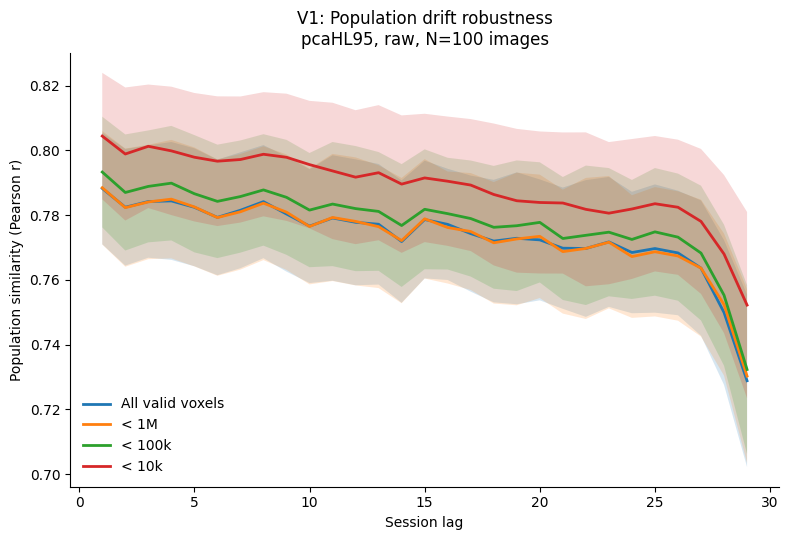

Saved: /content/drive/MyDrive/V2_drift/texturemodel/drift_results/population_sensitivity/figures/population_drift_sensitivity_V1_pcaHL95_raw.png


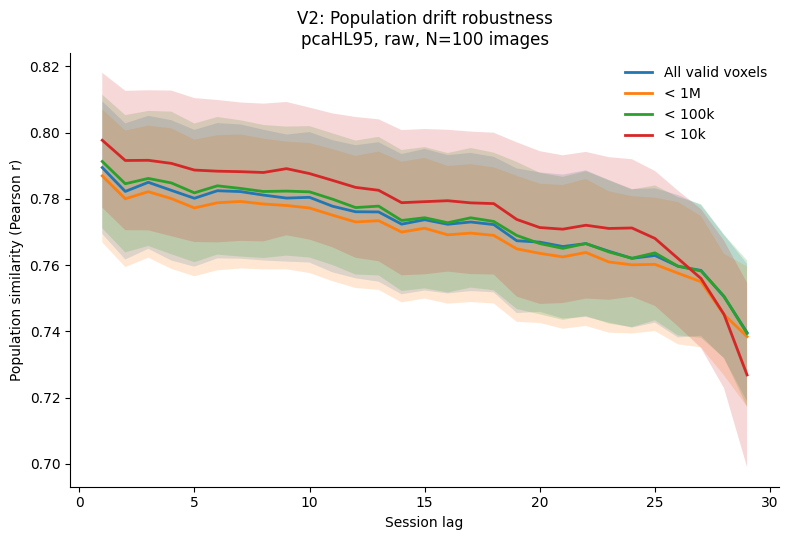

Saved: /content/drive/MyDrive/V2_drift/texturemodel/drift_results/population_sensitivity/figures/population_drift_sensitivity_V2_pcaHL95_raw.png


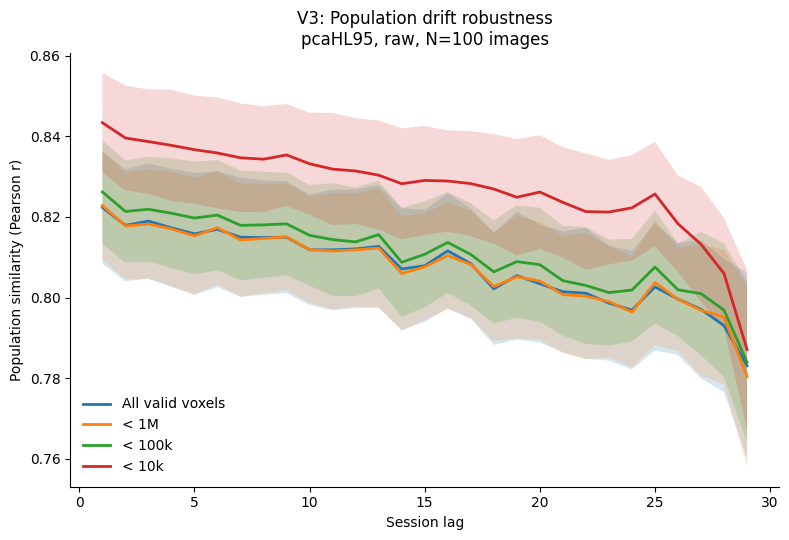

Saved: /content/drive/MyDrive/V2_drift/texturemodel/drift_results/population_sensitivity/figures/population_drift_sensitivity_V3_pcaHL95_raw.png


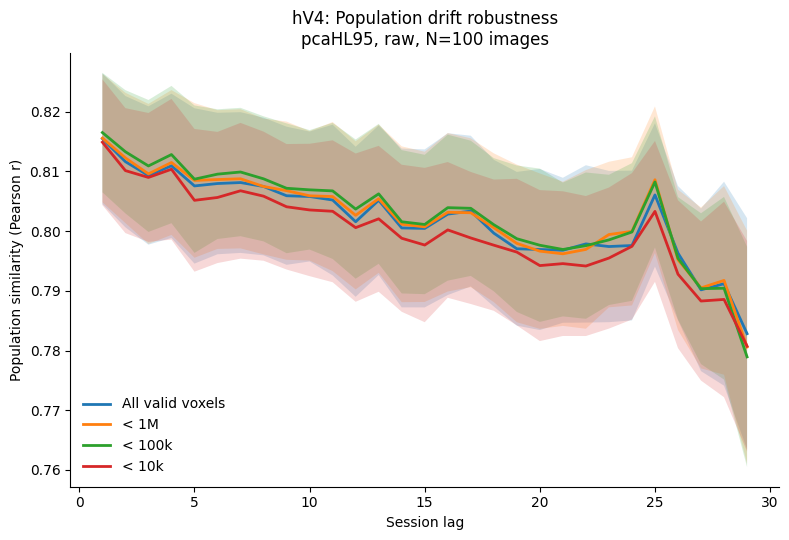

Saved: /content/drive/MyDrive/V2_drift/texturemodel/drift_results/population_sensitivity/figures/population_drift_sensitivity_hV4_pcaHL95_raw.png


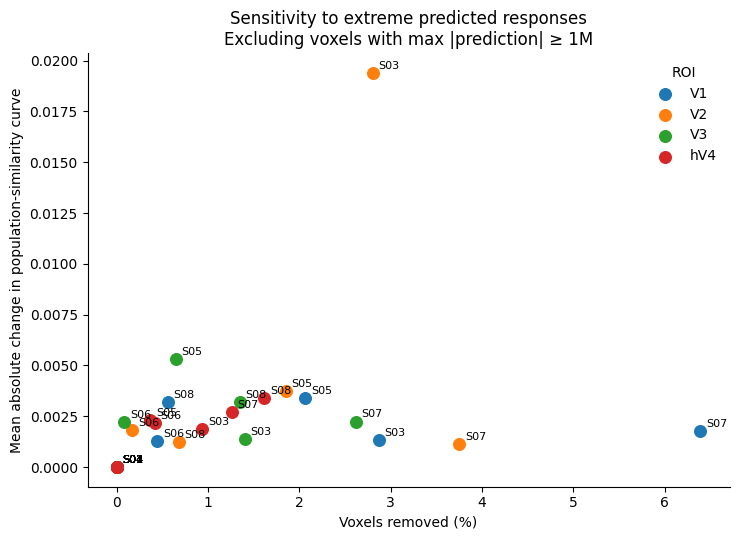

Saved: /content/drive/MyDrive/V2_drift/texturemodel/drift_results/population_sensitivity/figures/population_sensitivity_scatter_1M_pcaHL95_raw.png


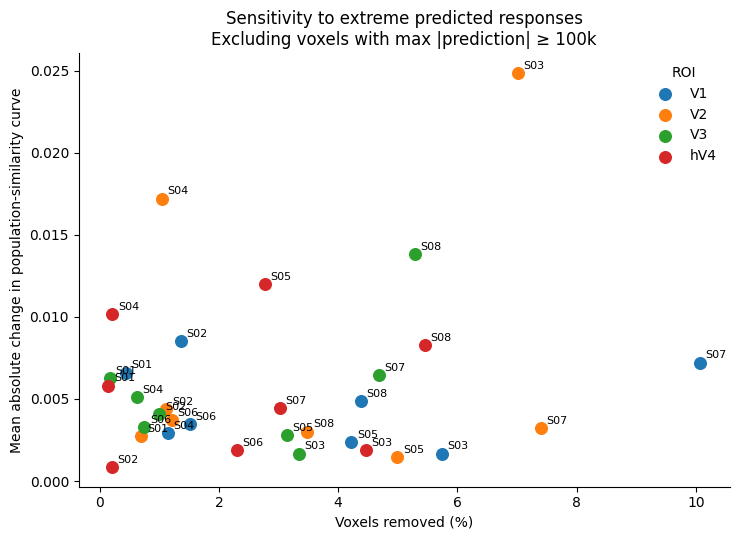

Saved: /content/drive/MyDrive/V2_drift/texturemodel/drift_results/population_sensitivity/figures/population_sensitivity_scatter_100k_pcaHL95_raw.png

SUMMARY FOR FIGURE / METHODS NOTES

<1M
Median % voxels removed: 0.433
Median mean absolute curve change: 0.001345
Maximum mean absolute curve change: 0.019398

<100k
Median % voxels removed: 2.537
Median mean absolute curve change: 0.004239
Maximum mean absolute curve change: 0.024861

<10k
Median % voxels removed: 13.491
Median mean absolute curve change: 0.021709
Maximum mean absolute curve change: 0.06438


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# ============================================================
# CONFIG
# ============================================================
FOLDER = Path(
    "/content/drive/MyDrive/V2_drift/texturemodel/"
    "drift_results/population_sensitivity"
)

OUT_DIR = FOLDER / "figures"
OUT_DIR.mkdir(parents=True, exist_ok=True)

SUBJECTS = range(1, 9)
ROIS = ["V1", "V2", "V3", "hV4"]

PCA_TYPE = "pcaHL"
PCA_PCT_VAR = 95
NORM = "raw"
NIMGS = 100

CONDITIONS = {
    "all_valid": "All valid voxels",
    "maxabs_lt_1M": "< 1M",
    "maxabs_lt_100k": "< 100k",
    "maxabs_lt_10k": "< 10k",
}


# ============================================================
# LOAD ALL FILES
# ============================================================
records = []

for subject in SUBJECTS:
    for roi in ROIS:

        fn = FOLDER / (
            f"population_tail_sensitivity_"
            f"S{subject:02d}_{roi}_"
            f"{PCA_TYPE}{PCA_PCT_VAR}_{NORM}_"
            f"Nimg{NIMGS}.npz"
        )

        if not fn.exists():
            raise FileNotFoundError(fn)

        d = np.load(fn, allow_pickle=True)

        all_curve = np.asarray(
            d["all_valid_lagCurve"],
            dtype=float
        )

        n_all = int(d["all_valid_nVox"])

        for key, label in CONDITIONS.items():

            curve = np.asarray(
                d[f"{key}_lagCurve"],
                dtype=float
            )

            nvox = int(
                d[f"{key}_nVox"]
            )

            records.append({
                "subject": f"S{subject:02d}",
                "roi": roi,
                "condition": key,
                "condition_label": label,
                "n_all": n_all,
                "nvox": nvox,
                "pct_removed":
                    100 * (n_all - nvox) / n_all,
                "mean_abs_diff":
                    np.nanmean(
                        np.abs(curve - all_curve)
                    ),
                "max_abs_diff":
                    np.nanmax(
                        np.abs(curve - all_curve)
                    ),
                "curve": curve,
            })

df = pd.DataFrame(records)

print(f"Loaded {len(df)} condition-level records")
print("Expected:", 32 * len(CONDITIONS))


# ============================================================
# FIGURE 1
# ROI-WISE POPULATION CORRELATION VS SESSION LAG
# ============================================================

lags = np.arange(1, 30)

for roi in ROIS:

    fig, ax = plt.subplots(
        figsize=(8, 5.5)
    )

    roi_df = df[
        df["roi"] == roi
    ]

    for condition_key, condition_label in CONDITIONS.items():

        sub_df = roi_df[
            roi_df["condition"] == condition_key
        ]

        curves = np.stack(
            sub_df["curve"].values
        )

        mean_curve = np.nanmean(
            curves,
            axis=0
        )

        sem_curve = (
            np.nanstd(
                curves,
                axis=0,
                ddof=1
            )
            /
            np.sqrt(curves.shape[0])
        )

        ax.plot(
            lags,
            mean_curve,
            label=condition_label,
            linewidth=2
        )

        ax.fill_between(
            lags,
            mean_curve - sem_curve,
            mean_curve + sem_curve,
            alpha=0.18
        )

    ax.set_xlabel("Session lag")
    ax.set_ylabel("Population similarity (Pearson r)")

    ax.set_title(
        f"{roi}: Population drift robustness\n"
        f"{PCA_TYPE}{PCA_PCT_VAR}, {NORM}, N={NIMGS} images"
    )

    ax.legend(
        frameon=False
    )

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    fig.tight_layout()

    out_fn = (
        OUT_DIR
        / f"population_drift_sensitivity_{roi}_{PCA_TYPE}{PCA_PCT_VAR}_{NORM}.png"
    )

    fig.savefig(
        out_fn,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

    print("Saved:", out_fn)


# ============================================================
# FIGURE 2A
# % VOXELS REMOVED VS MEAN ABSOLUTE CURVE CHANGE
# THRESHOLD = 1M
# ============================================================

plot_df = df[
    df["condition"] == "maxabs_lt_1M"
].copy()

fig, ax = plt.subplots(
    figsize=(7.5, 5.5)
)

for roi in ROIS:

    temp = plot_df[
        plot_df["roi"] == roi
    ]

    ax.scatter(
        temp["pct_removed"],
        temp["mean_abs_diff"],
        s=70,
        label=roi
    )

    for _, row in temp.iterrows():
        ax.annotate(
            row["subject"],
            (
                row["pct_removed"],
                row["mean_abs_diff"]
            ),
            xytext=(4, 3),
            textcoords="offset points",
            fontsize=8
        )

ax.set_xlabel("Voxels removed (%)")
ax.set_ylabel(
    "Mean absolute change in population-similarity curve"
)

ax.set_title(
    "Sensitivity to extreme predicted responses\n"
    "Excluding voxels with max |prediction| ≥ 1M"
)

ax.legend(
    frameon=False,
    title="ROI"
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

fig.tight_layout()

out_fn = (
    OUT_DIR
    / f"population_sensitivity_scatter_1M_{PCA_TYPE}{PCA_PCT_VAR}_{NORM}.png"
)

fig.savefig(
    out_fn,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved:", out_fn)


# ============================================================
# FIGURE 2B
# % VOXELS REMOVED VS MEAN ABSOLUTE CURVE CHANGE
# THRESHOLD = 100k
# ============================================================

plot_df = df[
    df["condition"] == "maxabs_lt_100k"
].copy()

fig, ax = plt.subplots(
    figsize=(7.5, 5.5)
)

for roi in ROIS:

    temp = plot_df[
        plot_df["roi"] == roi
    ]

    ax.scatter(
        temp["pct_removed"],
        temp["mean_abs_diff"],
        s=70,
        label=roi
    )

    for _, row in temp.iterrows():
        ax.annotate(
            row["subject"],
            (
                row["pct_removed"],
                row["mean_abs_diff"]
            ),
            xytext=(4, 3),
            textcoords="offset points",
            fontsize=8
        )

ax.set_xlabel("Voxels removed (%)")
ax.set_ylabel(
    "Mean absolute change in population-similarity curve"
)

ax.set_title(
    "Sensitivity to extreme predicted responses\n"
    "Excluding voxels with max |prediction| ≥ 100k"
)

ax.legend(
    frameon=False,
    title="ROI"
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

fig.tight_layout()

out_fn = (
    OUT_DIR
    / f"population_sensitivity_scatter_100k_{PCA_TYPE}{PCA_PCT_VAR}_{NORM}.png"
)

fig.savefig(
    out_fn,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved:", out_fn)


# ============================================================
# OPTIONAL NUMERICAL SUMMARY FOR FIGURE CAPTION
# ============================================================

print("\n" + "=" * 90)
print("SUMMARY FOR FIGURE / METHODS NOTES")
print("=" * 90)

for condition_key, label in [
    ("maxabs_lt_1M", "<1M"),
    ("maxabs_lt_100k", "<100k"),
    ("maxabs_lt_10k", "<10k"),
]:

    temp = df[
        df["condition"] == condition_key
    ]

    print(f"\n{label}")

    print(
        "Median % voxels removed:",
        round(
            temp["pct_removed"].median(),
            3
        )
    )

    print(
        "Median mean absolute curve change:",
        round(
            temp["mean_abs_diff"].median(),
            6
        )
    )

    print(
        "Maximum mean absolute curve change:",
        round(
            temp["mean_abs_diff"].max(),
            6
        )
    )

In [ ]:
import numpy as np
import pandas as pd
from pathlib import Path

# ============================================================
# CONFIG
# ============================================================
BASE = Path(
    "/content/drive/MyDrive/V1_Drift/repDrift_expand_6levels"
)

SUBJECTS = range(1, 9)
ROIS = {
    1: "V1",
    2: "V2",
    3: "V3",
    4: "hV4",
}

# SP population analysis used orientation-based responses
# If your final SP analysis used voxSessRespOri, leave this as is.
DATASET = "voxSessRespOri"


# ============================================================
# FIND + CHECK FILES
# ============================================================
rows = []

print("=" * 110)
print("SP SIMULATED POPULATION RESPONSE MAGNITUDES")
print("=" * 110)
print()

for subject in SUBJECTS:
    for vreg, roi in ROIS.items():

        # Try expected filename
        candidates = [
            BASE / f"simPopResp_v{vreg}_sub{subject}.npz",
            BASE / f"simPopResp_v{vreg}_sub{subject}_6levels.npz",
        ]

        fn = next(
            (x for x in candidates if x.exists()),
            None
        )

        # If naming differs, search for it
        if fn is None:
            matches = list(
                BASE.glob(f"*simPopResp*v{vreg}*sub{subject}*.npz")
            )

            if len(matches) == 1:
                fn = matches[0]

            elif len(matches) > 1:
                print(
                    f"WARNING S{subject:02d} {roi}: "
                    f"multiple candidates:"
                )
                for x in matches:
                    print("   ", x.name)
                continue

            else:
                print(
                    f"MISSING S{subject:02d} {roi}"
                )
                continue

        d = np.load(fn, allow_pickle=True)

        # ----------------------------------------------------
        # Find response array
        # ----------------------------------------------------
        if DATASET in d.files:
            resp = np.asarray(d[DATASET])

        elif "voxSessResp" in d.files:
            print(
                f"WARNING S{subject:02d} {roi}: "
                f"{DATASET} not found; using voxSessResp"
            )
            resp = np.asarray(d["voxSessResp"])

        else:
            print(
                f"ERROR S{subject:02d} {roi}: "
                f"no population response array found."
            )
            print("Keys:", d.files)
            continue

        # Expected:
        # voxels × sessions × images
        if resp.ndim != 3:
            print(
                f"ERROR S{subject:02d} {roi}: "
                f"unexpected shape {resp.shape}"
            )
            continue

        finite_pct = (
            100 *
            np.isfinite(resp).sum() /
            resp.size
        )

        # ----------------------------------------------------
        # Per-voxel maximum absolute prediction
        #
        # Maximum over ALL sessions and simulated images.
        # This is analogous to asking whether individual
        # voxels ever produce extreme simulated responses.
        # ----------------------------------------------------
        voxel_maxabs = np.nanmax(
            np.abs(resp),
            axis=(1, 2)
        )

        rows.append({
            "Subject": f"S{subject:02d}",
            "ROI": roi,

            "nvox": resp.shape[0],
            "nsess": resp.shape[1],
            "nimgs": resp.shape[2],

            "finite_pct": finite_pct,

            "median_voxel_maxabs":
                np.nanmedian(voxel_maxabs),

            "p95_voxel_maxabs":
                np.nanpercentile(voxel_maxabs, 95),

            "p99_voxel_maxabs":
                np.nanpercentile(voxel_maxabs, 99),

            "p99.9_voxel_maxabs":
                np.nanpercentile(voxel_maxabs, 99.9),

            "max_voxel_maxabs":
                np.nanmax(voxel_maxabs),

            "n_gt_100":
                np.sum(voxel_maxabs > 100),

            "n_gt_1k":
                np.sum(voxel_maxabs > 1_000),

            "n_gt_10k":
                np.sum(voxel_maxabs > 10_000),

            "n_gt_100k":
                np.sum(voxel_maxabs > 100_000),

            "n_gt_1m":
                np.sum(voxel_maxabs > 1_000_000),
        })

        print(
            f"S{subject:02d} {roi:3s} | "
            f"shape={resp.shape} | "
            f"median={np.nanmedian(voxel_maxabs):.3f} | "
            f"p99={np.nanpercentile(voxel_maxabs,99):.3f} | "
            f"max={np.nanmax(voxel_maxabs):.3f}"
        )


# ============================================================
# SUMMARY TABLE
# ============================================================
df_sp = pd.DataFrame(rows)

print("\n" + "=" * 110)
print("FULL SP SUMMARY")
print("=" * 110)

display(df_sp)


# ============================================================
# MOST IMPORTANT TAIL COUNTS
# ============================================================
print("\n" + "=" * 110)
print("EXTREME PREDICTION COUNTS")
print("=" * 110)

display(
    df_sp[
        [
            "Subject",
            "ROI",
            "nvox",
            "median_voxel_maxabs",
            "p95_voxel_maxabs",
            "p99_voxel_maxabs",
            "p99.9_voxel_maxabs",
            "max_voxel_maxabs",
            "n_gt_10k",
            "n_gt_100k",
            "n_gt_1m",
        ]
    ]
)


# ============================================================
# OVERALL SUMMARY
# ============================================================
print("\n" + "=" * 110)
print("OVERALL SP TAIL SUMMARY")
print("=" * 110)

print(
    "Median of median voxel max |prediction|:",
    np.nanmedian(df_sp["median_voxel_maxabs"])
)

print(
    "Largest prediction across all 32 analyses:",
    np.nanmax(df_sp["max_voxel_maxabs"])
)

print()

for threshold, col in [
    ("10k", "n_gt_10k"),
    ("100k", "n_gt_100k"),
    ("1M", "n_gt_1m"),
]:

    total = df_sp[col].sum()

    analyses = (
        df_sp[col] > 0
    ).sum()

    print(
        f">{threshold:4s}: "
        f"{int(total)} voxels total | "
        f"present in {analyses}/{len(df_sp)} subject × ROI analyses"
    )

SP SIMULATED POPULATION RESPONSE MAGNITUDES

S01 V1  | shape=(1350, 31, 100) | median=4.668 | p99=25.673 | max=43.938
S01 V2  | shape=(1433, 31, 100) | median=3.994 | p99=26.747 | max=58.068
S01 V3  | shape=(1187, 31, 100) | median=3.747 | p99=20.826 | max=82.519
S01 hV4 | shape=(687, 31, 100) | median=3.821 | p99=22.448 | max=39.114
S02 V1  | shape=(1102, 31, 100) | median=7.378 | p99=32.674 | max=75.521
S02 V2  | shape=(1075, 31, 100) | median=6.055 | p99=27.432 | max=50.406
S02 V3  | shape=(1097, 31, 100) | median=5.247 | p99=28.179 | max=43.174
S02 hV4 | shape=(483, 31, 100) | median=6.898 | p99=23.580 | max=36.222
S03 V1  | shape=(1254, 31, 100) | median=7.963 | p99=36.034 | max=58.714
S03 V2  | shape=(1141, 31, 100) | median=6.241 | p99=32.354 | max=57.418
S03 V3  | shape=(928, 31, 100) | median=4.721 | p99=25.505 | max=41.250
S03 hV4 | shape=(426, 31, 100) | median=4.928 | p99=20.795 | max=35.660
S04 V1  | shape=(877, 31, 100) | median=6.486 | p99=27.507 | max=45.773
S04 V2  | s

,Subject,ROI,nvox,nsess,nimgs,finite_pct,median_voxel_maxabs,p95_voxel_maxabs,p99_voxel_maxabs,p99.9_voxel_maxabs,max_voxel_maxabs,n_gt_100,n_gt_1k,n_gt_10k,n_gt_100k,n_gt_1m
0,S01,V1,1350,31,100,100.0,4.667931,16.586027,25.672922,36.747704,43.937653,0,0,0,0,0
1,S01,V2,1433,31,100,100.0,3.993881,13.425789,26.747475,43.852314,58.068451,0,0,0,0,0
2,S01,V3,1187,31,100,100.0,3.746998,11.384111,20.825970,50.873474,82.518730,0,0,0,0,0
3,S01,hV4,687,31,100,100.0,3.821362,12.607009,22.447912,36.492458,39.113815,0,0,0,0,0
4,S02,V1,1102,31,100,100.0,7.378497,23.231520,32.673901,55.593761,75.521233,0,0,0,0,0
5,S02,V2,1075,31,100,100.0,6.055146,18.103649,27.432240,42.911587,50.405624,0,0,0,0,0
6,S02,V3,1097,31,100,100.0,5.246827,17.762272,28.179256,39.776600,43.174454,0,0,0,0,0
7,S02,hV4,483,31,100,100.0,6.897532,17.160496,23.580324,32.661228,36.221645,0,0,0,0,0
8,S03,V1,1254,31,100,100.0,7.963089,24.054277,36.034321,47.550652,58.714149,0,0,0,0,0
9,S03,V2,1141,31,100,100.0,6.240532,18.570978,32.353905,52.945789,57.417889,0,0,0,0,0



EXTREME PREDICTION COUNTS


,Subject,ROI,nvox,median_voxel_maxabs,p95_voxel_maxabs,p99_voxel_maxabs,p99.9_voxel_maxabs,max_voxel_maxabs,n_gt_10k,n_gt_100k,n_gt_1m
0,S01,V1,1350,4.667931,16.586027,25.672922,36.747704,43.937653,0,0,0
1,S01,V2,1433,3.993881,13.425789,26.747475,43.852314,58.068451,0,0,0
2,S01,V3,1187,3.746998,11.384111,20.825970,50.873474,82.518730,0,0,0
3,S01,hV4,687,3.821362,12.607009,22.447912,36.492458,39.113815,0,0,0
4,S02,V1,1102,7.378497,23.231520,32.673901,55.593761,75.521233,0,0,0
5,S02,V2,1075,6.055146,18.103649,27.432240,42.911587,50.405624,0,0,0
6,S02,V3,1097,5.246827,17.762272,28.179256,39.776600,43.174454,0,0,0
7,S02,hV4,483,6.897532,17.160496,23.580324,32.661228,36.221645,0,0,0
8,S03,V1,1254,7.963089,24.054277,36.034321,47.550652,58.714149,0,0,0
9,S03,V2,1141,6.240532,18.570978,32.353905,52.945789,57.417889,0,0,0



OVERALL SP TAIL SUMMARY
Median of median voxel max |prediction|: 5.4045496
Largest prediction across all 32 analyses: 101.27505

>10k : 0 voxels total | present in 0/32 subject × ROI analyses
>100k: 0 voxels total | present in 0/32 subject × ROI analyses
>1M  : 0 voxels total | present in 0/32 subject × ROI analyses


## 3. Verification of the new all-HL PCA implementation

Older TS fits used PCA separately within higher-order feature subgroups. The final implementation instead performs PCA jointly across the higher-order feature set while retaining the 49 lower-order features directly.

Feature dimensionality provides a clear identifier of the implementation. Under the **new all-HL PCA** pipeline, the expected dimensionalities are:

| PCA setting | Feature dimensions |
|---|---:|
| pcaHL0 | 49 |
| pcaHL40 | 50 |
| pcaHL60 | 50 |
| pcaHL80 | 52 |
| pcaHL95 | 54 |

The older subgroup-PCA runs instead contained substantially more dimensions (for example 64, 73, 89/90, and 126/127). Inspection of the full-data fit archive showed that all 8 subjects × 4 ROIs × 5 PCA settings had a new all-HL PCA fit. Old subgroup-PCA outputs could therefore be identified and removed unambiguously.


# check all fits 0pca

In [ ]:
# PCA IMPLEMENTATION CHECK.
# Purpose: inspect pcaHL0 full-data fit structure and confirm the expected dimensionality of the new all-HL PCA implementation.

import numpy as np
from pathlib import Path

FN = Path(
    "/content/drive/MyDrive/V2_drift/texturemodel/model_fits/"
    "S01/texture_pyramid_OLS_4ori_4sf_pcaHL_V1_pca0_use_nsd_grid5_pRFs/"
    "Jul-14-2026_1724_04/all_fit_params.npy"
)

D = np.load(FN, allow_pickle=True).item()

best_params = D["best_params"]

print("=" * 90)
print("BEST_PARAMS STRUCTURE")
print("=" * 90)

print("type:", type(best_params))
print("length:", len(best_params))

for i, item in enumerate(best_params):

    print("\n" + "-" * 90)
    print(f"best_params[{i}]")
    print("-" * 90)

    print("type:", type(item))

    if isinstance(item, dict):

        print("dictionary keys:")

        for key, value in item.items():

            try:
                arr = np.asarray(value)

                print(
                    f"  {key:30s} "
                    f"shape={str(arr.shape):20s} "
                    f"dtype={arr.dtype}"
                )

            except Exception:
                print(
                    f"  {key:30s} "
                    f"type={type(value)}"
                )

    elif isinstance(item, (list, tuple)):

        print("length:", len(item))

        for j, value in enumerate(item):

            try:
                arr = np.asarray(value)

                print(
                    f"  [{j}] "
                    f"type={type(value).__name__:15s} "
                    f"shape={str(arr.shape):20s} "
                    f"dtype={arr.dtype}"
                )

            except Exception:
                print(
                    f"  [{j}] type={type(value)}"
                )

    else:

        try:
            arr = np.asarray(item)

            print("shape:", arr.shape)
            print("dtype:", arr.dtype)

            if np.issubdtype(arr.dtype, np.number):

                finite = np.isfinite(arr)

                print(
                    "finite:",
                    finite.sum(),
                    "/",
                    arr.size
                )

                if finite.any():

                    vals = arr[finite]

                    print("min:", vals.min())
                    print("max:", vals.max())
                    print(
                        "max |value|:",
                        np.max(np.abs(vals))
                    )

        except Exception as e:
            print("Could not inspect:", e)


BEST_PARAMS STRUCTURE
type: <class 'list'>
length: 6

------------------------------------------------------------------------------------------
best_params[0]
------------------------------------------------------------------------------------------
type: <class 'numpy.ndarray'>
shape: (2392, 1, 3)
dtype: float32
finite: 7176 / 7176
min: -0.8333333
max: 0.8333333
max |value|: 0.8333333

------------------------------------------------------------------------------------------
best_params[1]
------------------------------------------------------------------------------------------
type: <class 'numpy.ndarray'>
shape: (2392, 49, 1)
dtype: float32
finite: 117208 / 117208
min: -484.2766
max: 359.58194
max |value|: 484.2766

------------------------------------------------------------------------------------------
best_params[2]
------------------------------------------------------------------------------------------
type: <class 'numpy.ndarray'>
shape: (2392, 1)
dtype: float32
finite: 23

In [ ]:
# PCA IMPLEMENTATION CHECK.
# Purpose: compare pcaHL0 and pcaHL95 fit dimensionality and distinguish the new all-HL PCA runs from obsolete subgroup-PCA runs.

import numpy as np
from pathlib import Path

ROOT = Path("/content/drive/MyDrive/V2_drift/texturemodel/model_fits/S01")

configs = {
    "pcaHL0": ROOT / "texture_pyramid_OLS_4ori_4sf_pcaHL_V1_pca0_use_nsd_grid5_pRFs",
    "pcaHL95": ROOT / "texture_pyramid_OLS_4ori_4sf_pcaHL_V1_pca95_use_nsd_grid5_pRFs",
}

print("=" * 100)
print("ORIGINAL-FIT PARAMETER COMPARISON — S01 V1")
print("=" * 100)

for label, folder in configs.items():

    files = sorted(folder.glob("*/all_fit_params.npy"))

    if len(files) == 0:
        print(f"\n{label}: NOT FOUND")
        continue

    # Use latest run if more than one exists
    fn = files[-1]

    print(f"\n{'-' * 100}")
    print(label)
    print(fn)
    print("-" * 100)

    D = np.load(fn, allow_pickle=True).item()

    bp = D["best_params"]

    print("pca_pct_var:", D["pca_pct_var"])
    print("pyr_pca_type:", D["pyr_pca_type"])
    print("number of best_params entries:", len(bp))

    for i, x in enumerate(bp):

        arr = np.asarray(x)

        if not np.issubdtype(arr.dtype, np.number):
            continue

        finite = np.isfinite(arr)

        if not finite.any():
            continue

        vals = arr[finite].astype(np.float64)
        absvals = np.abs(vals)

        print(
            f"\nbest_params[{i}]"
            f"\n  shape       : {arr.shape}"
            f"\n  min/max     : {vals.min():.6g} / {vals.max():.6g}"
            f"\n  median |x|  : {np.median(absvals):.6g}"
            f"\n  p95 |x|     : {np.percentile(absvals,95):.6g}"
            f"\n  p99 |x|     : {np.percentile(absvals,99):.6g}"
            f"\n  p99.9 |x|   : {np.percentile(absvals,99.9):.6g}"
            f"\n  max |x|     : {absvals.max():.6g}"
        )

        for threshold in [1e2, 1e3, 1e4, 1e5, 1e6, 1e8, 1e10]:
            n = np.sum(absvals > threshold)

            if n > 0:
                print(
                    f"  |x| > {threshold:>8.0e}: "
                    f"{n:6d} ({100*n/len(absvals):.4f}%)"
                )


ORIGINAL-FIT PARAMETER COMPARISON — S01 V1

----------------------------------------------------------------------------------------------------
pcaHL0
/content/drive/MyDrive/V2_drift/texturemodel/model_fits/S01/texture_pyramid_OLS_4ori_4sf_pcaHL_V1_pca0_use_nsd_grid5_pRFs/Jul-14-2026_1724_04/all_fit_params.npy
----------------------------------------------------------------------------------------------------
pca_pct_var: 0
pyr_pca_type: pcaHL
number of best_params entries: 6

best_params[0]
  shape       : (2392, 1, 3)
  min/max     : -0.833333 / 0.833333
  median |x|  : 0.0736806
  p95 |x|     : 0.468163
  p99 |x|     : 0.628207
  p99.9 |x|   : 0.833333
  max |x|     : 0.833333

best_params[1]
  shape       : (2392, 49, 1)
  min/max     : -484.277 / 359.582
  median |x|  : 0.0280251
  p95 |x|     : 0.836879
  p99 |x|     : 44.9598
  p99.9 |x|   : 188.991
  max |x|     : 484.277
  |x| >    1e+02:    545 (0.4650%)

best_params[2]
  shape       : (2392, 1)
  min/max     : -0.0200066 / 

## 4. Full-data versus session-specific OLS coefficient magnitudes

A major discrepancy emerged when the same TS representation was fit to different amounts of data. In the **full-data pcaHL95 fit**, S01 V1 had a maximum absolute coefficient of only about **485**. In contrast, the session-specific FAST fits reached approximately \(10^{12}\).

This comparison is crucial because it shows that the pathological coefficient scale is not a property of the saved PCA basis alone. The same 54-dimensional feature representation can be fit with moderate coefficients when thousands of observations are available, but becomes numerically unstable when OLS is estimated separately from one session.


In [ ]:
# WEIGHT-INSTABILITY CHECK.
# Purpose: compare full-data OLS coefficient magnitudes with the 30 session-specific FAST fits using the same pcaHL95 feature representation.

import numpy as np
import pandas as pd
import h5py
from pathlib import Path

# ============================================================
# CONFIG
# ============================================================
ROOT = Path(
    "/content/drive/MyDrive/V2_drift/texturemodel/model_fits/S01"
)

ORIGINAL_FIT = (
    ROOT
    / "texture_pyramid_OLS_4ori_4sf_pcaHL_V1_pca95_use_nsd_grid5_pRFs"
    / "Jul-11-2026_2202_15"
    / "all_fit_params.npy"
)

CROSS_SESSION_FIT = (
    ROOT
    / "FAST_CROSS_SESSION"
    / (
        "S01_V1_texture_pyramid_OLS_4ori_4sf_"
        "pcaHL_V1_pca95_use_nsd_grid5_pRFs_"
        "30x30_cross_session.h5py"
    )
)

THRESHOLDS = [
    1e3,
    1e6,
    1e9,
]


# ============================================================
# Helper
# ============================================================
def summarize_weights(arr):

    arr = np.asarray(arr, dtype=np.float64)

    finite = np.isfinite(arr)

    vals = np.abs(
        arr[finite]
    )

    out = {
        "n_weights": len(vals),
        "median_abs": np.median(vals),
        "p95_abs": np.percentile(vals, 95),
        "p99_abs": np.percentile(vals, 99),
        "p99.9_abs": np.percentile(vals, 99.9),
        "max_abs": np.max(vals),
    }

    for thr in THRESHOLDS:

        out[f"n_gt_{thr:.0e}"] = int(
            np.sum(vals > thr)
        )

        out[f"pct_gt_{thr:.0e}"] = (
            100 * np.sum(vals > thr) / len(vals)
        )

    return out


# ============================================================
# ORIGINAL FULL-DATA FIT
# ============================================================
D = np.load(
    ORIGINAL_FIT,
    allow_pickle=True
).item()

# From previous inspection:
# best_params[1] = fitted regression weights
original_weights = np.asarray(
    D["best_params"][1]
)

original_summary = summarize_weights(
    original_weights
)

print("=" * 100)
print("ORIGINAL FULL-DATA FIT")
print("=" * 100)

print("File:")
print(ORIGINAL_FIT)

print("\nWeight shape:")
print(original_weights.shape)

for k, v in original_summary.items():
    print(f"{k:20s}: {v}")


# ============================================================
# CROSS-SESSION FIT
# ============================================================
with h5py.File(
    CROSS_SESSION_FIT,
    "r"
) as f:

    best_weights = np.asarray(
        f["best_weights"]
    )[..., 0]

# shape:
# train_session × voxel × feature
print("\n" + "=" * 100)
print("CROSS-SESSION FIT")
print("=" * 100)

print("File:")
print(CROSS_SESSION_FIT)

print("\nWeight shape:")
print(best_weights.shape)


# ============================================================
# SESSION-WISE SUMMARY
# ============================================================
rows = []

for sess in range(
    best_weights.shape[0]
):

    W = best_weights[
        sess
    ]

    s = summarize_weights(
        W
    )

    rows.append({
        "session": sess + 1,

        "n_weights":
            s["n_weights"],

        "median_abs":
            s["median_abs"],

        "p95_abs":
            s["p95_abs"],

        "p99_abs":
            s["p99_abs"],

        "p99.9_abs":
            s["p99.9_abs"],

        "max_abs":
            s["max_abs"],

        "n_gt_1e3":
            s["n_gt_1e+03"],

        "pct_gt_1e3":
            s["pct_gt_1e+03"],

        "n_gt_1e6":
            s["n_gt_1e+06"],

        "pct_gt_1e6":
            s["pct_gt_1e+06"],

        "n_gt_1e9":
            s["n_gt_1e+09"],

        "pct_gt_1e9":
            s["pct_gt_1e+09"],
    })


df = pd.DataFrame(
    rows
)


# ============================================================
# ADD RATIOS VS ORIGINAL FIT
# ============================================================
df[
    "max_ratio_vs_original"
] = (
    df["max_abs"]
    /
    original_summary["max_abs"]
)

df[
    "p99_ratio_vs_original"
] = (
    df["p99_abs"]
    /
    original_summary["p99_abs"]
)

df[
    "p99.9_ratio_vs_original"
] = (
    df["p99.9_abs"]
    /
    original_summary["p99.9_abs"]
)


# ============================================================
# PRINT ALL 30 SESSIONS
# ============================================================
print("\n" + "=" * 100)
print("SESSION-SPECIFIC WEIGHT DISTRIBUTIONS")
print("=" * 100)

display(
    df.round(6)
)


# ============================================================
# SORT BY WORST MAX WEIGHT
# ============================================================
print("\n" + "=" * 100)
print("SESSIONS SORTED BY MAX |WEIGHT|")
print("=" * 100)

display(
    df[
        [
            "session",
            "median_abs",
            "p95_abs",
            "p99_abs",
            "p99.9_abs",
            "max_abs",

            "n_gt_1e3",
            "n_gt_1e6",
            "n_gt_1e9",

            "max_ratio_vs_original",
            "p99_ratio_vs_original",
            "p99.9_ratio_vs_original",
        ]
    ]
    .sort_values(
        "max_abs",
        ascending=False
    )
    .round(6)
)


# ============================================================
# OVERALL COMPARISON
# ============================================================
print("\n" + "=" * 100)
print("ORIGINAL VS SESSION-SPECIFIC SUMMARY")
print("=" * 100)

print(
    f"Original max |w|     : "
    f"{original_summary['max_abs']:.6e}"
)

print(
    f"Original p99 |w|     : "
    f"{original_summary['p99_abs']:.6e}"
)

print(
    f"Original p99.9 |w|   : "
    f"{original_summary['p99.9_abs']:.6e}"
)

print()

print(
    f"Median session max |w|   : "
    f"{df['max_abs'].median():.6e}"
)

print(
    f"Largest session max |w|  : "
    f"{df['max_abs'].max():.6e}"
)

print(
    f"Median session p99 |w|   : "
    f"{df['p99_abs'].median():.6e}"
)

print(
    f"Median session p99.9 |w| : "
    f"{df['p99.9_abs'].median():.6e}"
)

print()

print(
    "Sessions with any |w| > 1e3:",
    int(
        (df["n_gt_1e3"] > 0).sum()
    ),
    "/",
    len(df)
)

print(
    "Sessions with any |w| > 1e6:",
    int(
        (df["n_gt_1e6"] > 0).sum()
    ),
    "/",
    len(df)
)

print(
    "Sessions with any |w| > 1e9:",
    int(
        (df["n_gt_1e9"] > 0).sum()
    ),
    "/",
    len(df)
)


# ============================================================
# MOST EXTREME SINGLE SESSION
# ============================================================
worst = df.loc[
    df["max_abs"].idxmax()
]

print("\n" + "=" * 100)
print("MOST EXTREME SESSION")
print("=" * 100)

print(
    f"Session               : "
    f"{int(worst['session'])}"
)

print(
    f"max |w|               : "
    f"{worst['max_abs']:.6e}"
)

print(
    f"p99 |w|               : "
    f"{worst['p99_abs']:.6e}"
)

print(
    f"p99.9 |w|             : "
    f"{worst['p99.9_abs']:.6e}"
)

print(
    f"max / original max    : "
    f"{worst['max_ratio_vs_original']:.3e}x"
)

print(
    f"weights > 1e3         : "
    f"{int(worst['n_gt_1e3'])}"
)

print(
    f"weights > 1e6         : "
    f"{int(worst['n_gt_1e6'])}"
)

print(
    f"weights > 1e9         : "
    f"{int(worst['n_gt_1e9'])}"
)


ORIGINAL FULL-DATA FIT
File:
/content/drive/MyDrive/V2_drift/texturemodel/model_fits/S01/texture_pyramid_OLS_4ori_4sf_pcaHL_V1_pca95_use_nsd_grid5_pRFs/Jul-11-2026_2202_15/all_fit_params.npy

Weight shape:
(2392, 54, 1)
n_weights           : 129168
median_abs          : 0.02441126201301813
p95_abs             : 0.6970703572034831
p99_abs             : 36.87482818603525
p99.9_abs           : 181.72695672607998
max_abs             : 485.1763916015625
n_gt_1e+03          : 0
pct_gt_1e+03        : 0.0
n_gt_1e+06          : 0
pct_gt_1e+06        : 0.0
n_gt_1e+09          : 0
pct_gt_1e+09        : 0.0

CROSS-SESSION FIT
File:
/content/drive/MyDrive/V2_drift/texturemodel/model_fits/S01/FAST_CROSS_SESSION/S01_V1_texture_pyramid_OLS_4ori_4sf_pcaHL_V1_pca95_use_nsd_grid5_pRFs_30x30_cross_session.h5py

Weight shape:
(30, 1350, 54)

SESSION-SPECIFIC WEIGHT DISTRIBUTIONS


,session,n_weights,median_abs,p95_abs,p99_abs,p99.9_abs,max_abs,n_gt_1e3,pct_gt_1e3,n_gt_1e6,pct_gt_1e6,n_gt_1e9,pct_gt_1e9,max_ratio_vs_original,p99_ratio_vs_original,p99.9_ratio_vs_original
0,1,72900,166.900772,2.082397e+08,1.417493e+11,6.812280e+11,2.975686e+12,24957,34.234568,7677,10.530864,2514,3.448560,6.133204e+09,3.844067e+09,3.748635e+09
1,2,72900,153.727837,1.890734e+08,1.398439e+11,6.413136e+11,2.047352e+12,24533,33.652949,7627,10.462277,2477,3.397805,4.219810e+09,3.792394e+09,3.528995e+09
2,3,72900,169.067993,2.158586e+08,1.556311e+11,7.162038e+11,3.504877e+12,24813,34.037037,7728,10.600823,2600,3.566529,7.223923e+09,4.220525e+09,3.941098e+09
3,4,72900,154.303085,2.009922e+08,1.388573e+11,5.923522e+11,3.073901e+12,24368,33.426612,7704,10.567901,2490,3.415638,6.335636e+09,3.765638e+09,3.259572e+09
4,5,72900,163.546356,2.252019e+08,1.434747e+11,7.012841e+11,7.303472e+12,24899,34.155007,7844,10.759945,2557,3.507545,1.505323e+10,3.890858e+09,3.858999e+09
5,6,72900,170.322098,1.986510e+08,1.481286e+11,6.568989e+11,6.969736e+12,25055,34.368999,7775,10.665295,2508,3.440329,1.436536e+10,4.017065e+09,3.614758e+09
6,7,72900,188.458282,2.255242e+08,1.838208e+11,7.709197e+11,2.156877e+12,25644,35.176955,7843,10.758573,2649,3.633745,4.445553e+09,4.984995e+09,4.242187e+09
7,8,72900,169.224854,2.134200e+08,1.543822e+11,6.606523e+11,3.305554e+12,25047,34.358025,7840,10.754458,2592,3.555556,6.813097e+09,4.186656e+09,3.635412e+09
8,9,72900,174.118690,2.135767e+08,1.551575e+11,6.948731e+11,2.643390e+12,25005,34.300412,7708,10.573388,2568,3.522634,5.448308e+09,4.207680e+09,3.823721e+09
9,10,72900,183.264542,2.201049e+08,1.564633e+11,7.301469e+11,2.595069e+12,25428,34.880658,7717,10.585734,2602,3.569273,5.348713e+09,4.243091e+09,4.017824e+09



SESSIONS SORTED BY MAX |WEIGHT|


,session,median_abs,p95_abs,p99_abs,p99.9_abs,max_abs,n_gt_1e3,n_gt_1e6,n_gt_1e9,max_ratio_vs_original,p99_ratio_vs_original,p99.9_ratio_vs_original
4,5,163.546356,2.252019e+08,1.434747e+11,7.012841e+11,7.303472e+12,24899,7844,2557,1.505323e+10,3.890858e+09,3.858999e+09
5,6,170.322098,1.986510e+08,1.481286e+11,6.568989e+11,6.969736e+12,25055,7775,2508,1.436536e+10,4.017065e+09,3.614758e+09
23,24,167.809418,2.222087e+08,1.504156e+11,6.537434e+11,5.559340e+12,25084,7773,2518,1.145839e+10,4.079085e+09,3.597394e+09
16,17,173.499809,2.134345e+08,1.591658e+11,7.097758e+11,5.134211e+12,25046,7839,2571,1.058215e+10,4.316380e+09,3.905726e+09
10,11,180.286636,2.336671e+08,1.613374e+11,7.897720e+11,4.555524e+12,25248,7816,2614,9.389418e+09,4.375272e+09,4.345926e+09
19,20,160.996178,1.898908e+08,1.427116e+11,5.862836e+11,4.314458e+12,24760,7699,2539,8.892555e+09,3.870164e+09,3.226178e+09
29,30,172.151535,2.152605e+08,1.636582e+11,7.088205e+11,3.749146e+12,25404,7759,2557,7.727388e+09,4.438210e+09,3.900470e+09
17,18,167.093872,1.975723e+08,1.510138e+11,6.771733e+11,3.630194e+12,24735,7793,2527,7.482215e+09,4.095309e+09,3.726323e+09
13,14,170.886780,2.347342e+08,1.564150e+11,7.256535e+11,3.561169e+12,25142,7745,2588,7.339947e+09,4.241782e+09,3.993098e+09
2,3,169.067993,2.158586e+08,1.556311e+11,7.162038e+11,3.504877e+12,24813,7728,2600,7.223923e+09,4.220525e+09,3.941098e+09



ORIGINAL VS SESSION-SPECIFIC SUMMARY
Original max |w|     : 4.851764e+02
Original p99 |w|     : 3.687483e+01
Original p99.9 |w|   : 1.817270e+02

Median session max |w|   : 3.385558e+12
Largest session max |w|  : 7.303472e+12
Median session p99 |w|   : 1.532149e+11
Median session p99.9 |w| : 6.953768e+11

Sessions with any |w| > 1e3: 30 / 30
Sessions with any |w| > 1e6: 30 / 30
Sessions with any |w| > 1e9: 30 / 30

MOST EXTREME SESSION
Session               : 5
max |w|               : 7.303472e+12
p99 |w|               : 1.434747e+11
p99.9 |w|             : 7.012841e+11
max / original max    : 1.505e+10x
weights > 1e3         : 24899
weights > 1e6         : 7844
weights > 1e9         : 2557


FULL-DATA REFERENCE
median    : 2.441126e-02
p95       : 6.970704e-01
p99       : 3.687483e+01
p999      : 1.817270e+02
max       : 4.851764e+02

Session-specific max |w| range:
2.047352e+12 to 7.303472e+12


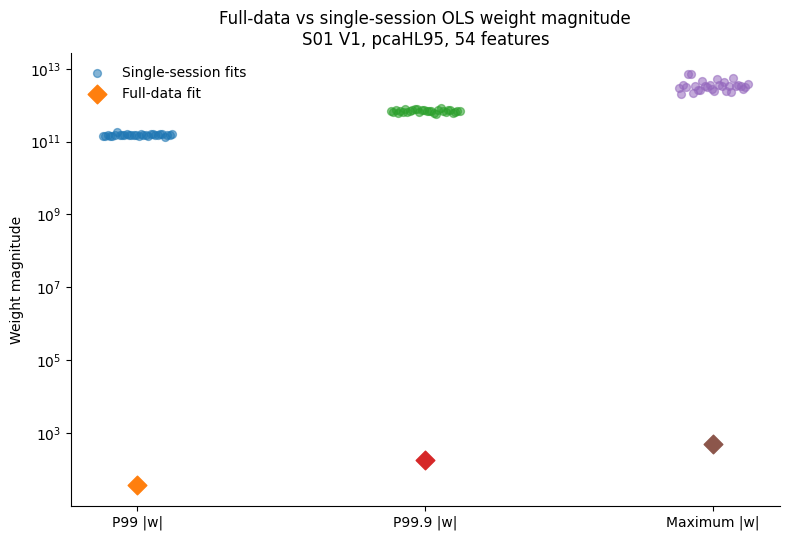

Saved: /content/drive/MyDrive/V2_drift/texturemodel/drift_results/weight_instability_figures/S01_V1_pcaHL95_full_vs_single_session_weight_magnitude.png


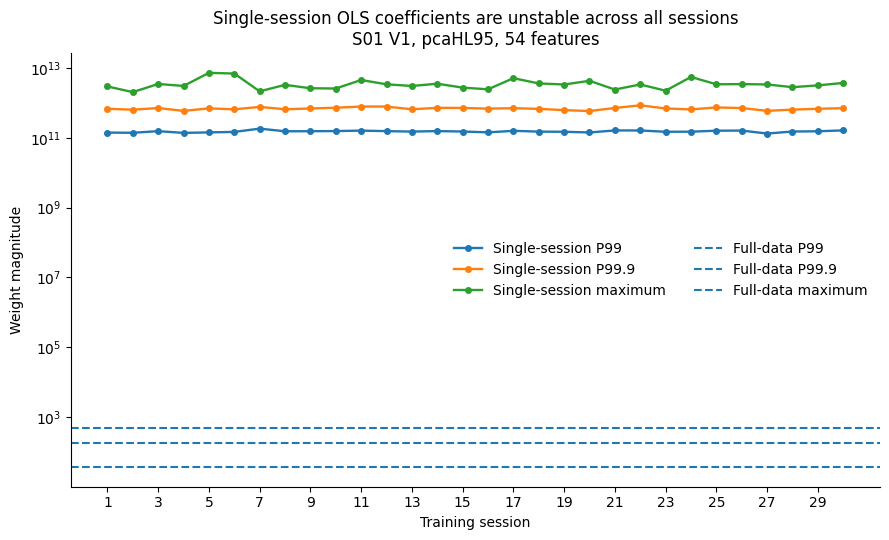

Saved: /content/drive/MyDrive/V2_drift/texturemodel/drift_results/weight_instability_figures/S01_V1_pcaHL95_weight_magnitude_across_sessions.png


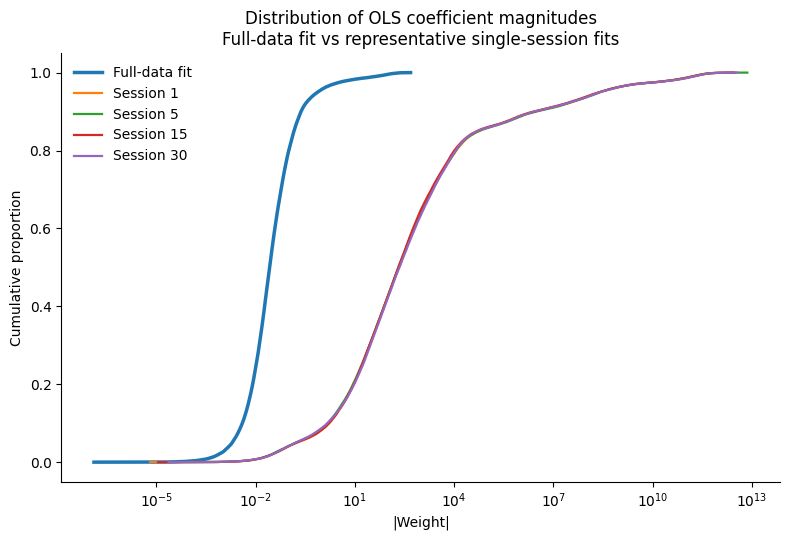

Saved: /content/drive/MyDrive/V2_drift/texturemodel/drift_results/weight_instability_figures/S01_V1_pcaHL95_weight_ecdf_full_vs_sessions.png

KEY VALUES
Full-data max |w|        : 4.852e+02
Median session max |w|   : 3.386e+12
Largest session max |w|  : 7.303e+12
Full-data P99 |w|        : 3.687e+01
Median session P99 |w|   : 1.532e+11
Full-data P99.9 |w|      : 1.817e+02
Median session P99.9 |w| : 6.954e+11
Median max inflation     : 6.978e+09x


In [ ]:
# VISUALIZATION OF WEIGHT INSTABILITY.
# Purpose: show how strongly the session-specific OLS coefficient distribution shifts relative to the full-data fit.

import numpy as np
import pandas as pd
import h5py
import matplotlib.pyplot as plt
from pathlib import Path

# ============================================================
# CONFIG
# ============================================================

ROOT = Path(
    "/content/drive/MyDrive/V2_drift/texturemodel/model_fits/S01"
)

ORIGINAL_FIT = (
    ROOT
    / "texture_pyramid_OLS_4ori_4sf_pcaHL_V1_pca95_use_nsd_grid5_pRFs"
    / "Jul-11-2026_2202_15"
    / "all_fit_params.npy"
)

CROSS_SESSION_FIT = (
    ROOT
    / "FAST_CROSS_SESSION"
    / (
        "S01_V1_texture_pyramid_OLS_4ori_4sf_"
        "pcaHL_V1_pca95_use_nsd_grid5_pRFs_"
        "30x30_cross_session.h5py"
    )
)

OUT_DIR = Path(
    "/content/drive/MyDrive/V2_drift/texturemodel/"
    "drift_results/weight_instability_figures"
)

OUT_DIR.mkdir(parents=True, exist_ok=True)


# ============================================================
# LOAD FULL-DATA WEIGHTS
# ============================================================

D = np.load(
    ORIGINAL_FIT,
    allow_pickle=True
).item()

W_full = np.asarray(
    D["best_params"][1],
    dtype=np.float64
)

# voxel × feature × model-version
W_full = W_full[..., 0]

assert W_full.shape[1] == 54, (
    f"Expected 54 features in new all-HL PCA fit, "
    f"found {W_full.shape[1]}"
)


# ============================================================
# LOAD 30 SESSION-SPECIFIC WEIGHT MATRICES
# ============================================================

with h5py.File(
    CROSS_SESSION_FIT,
    "r"
) as f:

    W_session = np.asarray(
        f["best_weights"],
        dtype=np.float64
    )[..., 0]

# session × voxel × feature
assert W_session.shape[2] == 54, (
    f"Expected 54 features in cross-session fit, "
    f"found {W_session.shape[2]}"
)

NS = W_session.shape[0]


# ============================================================
# SUMMARY FUNCTION
# ============================================================

def weight_summary(W):

    x = np.abs(
        np.asarray(W, dtype=np.float64)
    )

    x = x[
        np.isfinite(x)
    ]

    return {
        "median": np.median(x),
        "p95": np.percentile(x, 95),
        "p99": np.percentile(x, 99),
        "p999": np.percentile(x, 99.9),
        "max": np.max(x),
    }


full_stats = weight_summary(W_full)

session_stats = []

for s in range(NS):

    stats = weight_summary(
        W_session[s]
    )

    stats["session"] = s + 1

    session_stats.append(stats)

session_df = pd.DataFrame(
    session_stats
)


# ============================================================
# PRINT REFERENCE VALUES
# ============================================================

print("=" * 90)
print("FULL-DATA REFERENCE")
print("=" * 90)

for k, v in full_stats.items():
    print(f"{k:10s}: {v:.6e}")

print("\nSession-specific max |w| range:")
print(
    f"{session_df['max'].min():.6e} "
    f"to {session_df['max'].max():.6e}"
)


# ============================================================
# FIGURE 1
# FULL-DATA VS SESSION-SPECIFIC SUMMARY DISTRIBUTIONS
# ============================================================

metrics = [
    ("p99", "P99 |w|"),
    ("p999", "P99.9 |w|"),
    ("max", "Maximum |w|"),
]

fig, ax = plt.subplots(
    figsize=(8, 5.5)
)

xpos = np.arange(
    len(metrics)
)

# Plot each session as an individual point
for i, (key, label) in enumerate(metrics):

    vals = session_df[key].values

    jitter = np.linspace(
        -0.12,
        0.12,
        len(vals)
    )

    ax.scatter(
        np.full(len(vals), xpos[i]) + jitter,
        vals,
        alpha=0.55,
        s=32,
        label="Single-session fits" if i == 0 else None
    )

    # Full-data reference
    ax.scatter(
        xpos[i],
        full_stats[key],
        marker="D",
        s=90,
        label="Full-data fit" if i == 0 else None
    )

ax.set_yscale("log")

ax.set_xticks(
    xpos
)

ax.set_xticklabels(
    [x[1] for x in metrics]
)

ax.set_ylabel("Weight magnitude")

ax.set_title(
    "Full-data vs single-session OLS weight magnitude\n"
    "S01 V1, pcaHL95, 54 features"
)

ax.legend(
    frameon=False
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

fig.tight_layout()

fn = (
    OUT_DIR
    / "S01_V1_pcaHL95_full_vs_single_session_weight_magnitude.png"
)

fig.savefig(
    fn,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved:", fn)


# ============================================================
# FIGURE 2
# WEIGHT MAGNITUDE ACROSS TRAINING SESSIONS
# ============================================================

fig, ax = plt.subplots(
    figsize=(9, 5.5)
)

sessions = session_df[
    "session"
].values

ax.plot(
    sessions,
    session_df["p99"],
    marker="o",
    markersize=4,
    linewidth=1.7,
    label="Single-session P99"
)

ax.plot(
    sessions,
    session_df["p999"],
    marker="o",
    markersize=4,
    linewidth=1.7,
    label="Single-session P99.9"
)

ax.plot(
    sessions,
    session_df["max"],
    marker="o",
    markersize=4,
    linewidth=1.7,
    label="Single-session maximum"
)

# Full-data reference lines
ax.axhline(
    full_stats["p99"],
    linestyle="--",
    linewidth=1.5,
    label="Full-data P99"
)

ax.axhline(
    full_stats["p999"],
    linestyle="--",
    linewidth=1.5,
    label="Full-data P99.9"
)

ax.axhline(
    full_stats["max"],
    linestyle="--",
    linewidth=1.5,
    label="Full-data maximum"
)

ax.set_yscale("log")

ax.set_xlabel("Training session")

ax.set_ylabel("Weight magnitude")

ax.set_xticks(
    np.arange(1, NS + 1, 2)
)

ax.set_title(
    "Single-session OLS coefficients are unstable across all sessions\n"
    "S01 V1, pcaHL95, 54 features"
)

ax.legend(
    frameon=False,
    ncol=2
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

fig.tight_layout()

fn = (
    OUT_DIR
    / "S01_V1_pcaHL95_weight_magnitude_across_sessions.png"
)

fig.savefig(
    fn,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved:", fn)


# ============================================================
# FIGURE 3
# CUMULATIVE DISTRIBUTION OF |WEIGHTS|
#
# Full data vs representative sessions:
# 1 = early
# 5 = most extreme max in your previous result
# 15 = middle
# 30 = late
# ============================================================

representative_sessions = [
    1,
    5,
    15,
    30,
]

fig, ax = plt.subplots(
    figsize=(8, 5.5)
)


def ecdf_positive_abs(W):

    vals = np.abs(
        np.asarray(W, dtype=np.float64)
    )

    vals = vals[
        np.isfinite(vals)
        &
        (vals > 0)
    ]

    vals = np.sort(vals)

    y = np.arange(
        1,
        len(vals) + 1
    ) / len(vals)

    return vals, y


# Full-data
x, y = ecdf_positive_abs(
    W_full
)

ax.plot(
    x,
    y,
    linewidth=2.5,
    label="Full-data fit"
)


# Representative single-session fits
for sess in representative_sessions:

    x, y = ecdf_positive_abs(
        W_session[sess - 1]
    )

    ax.plot(
        x,
        y,
        linewidth=1.6,
        label=f"Session {sess}"
    )


ax.set_xscale("log")

ax.set_xlabel("|Weight|")

ax.set_ylabel("Cumulative proportion")

ax.set_title(
    "Distribution of OLS coefficient magnitudes\n"
    "Full-data fit vs representative single-session fits"
)

ax.legend(
    frameon=False
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

fig.tight_layout()

fn = (
    OUT_DIR
    / "S01_V1_pcaHL95_weight_ecdf_full_vs_sessions.png"
)

fig.savefig(
    fn,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved:", fn)


# ============================================================
# EXTRA: SUMMARY FOR FIGURE CAPTION / LAB DISCUSSION
# ============================================================

print("\n" + "=" * 90)
print("KEY VALUES")
print("=" * 90)

print(
    f"Full-data max |w|        : "
    f"{full_stats['max']:.3e}"
)

print(
    f"Median session max |w|   : "
    f"{session_df['max'].median():.3e}"
)

print(
    f"Largest session max |w|  : "
    f"{session_df['max'].max():.3e}"
)

print(
    f"Full-data P99 |w|        : "
    f"{full_stats['p99']:.3e}"
)

print(
    f"Median session P99 |w|   : "
    f"{session_df['p99'].median():.3e}"
)

print(
    f"Full-data P99.9 |w|      : "
    f"{full_stats['p999']:.3e}"
)

print(
    f"Median session P99.9 |w| : "
    f"{session_df['p999'].median():.3e}"
)

print(
    f"Median max inflation     : "
    f"{session_df['max'].median() / full_stats['max']:.3e}x"
)


## 5. Design-matrix conditioning analysis

To determine whether the extreme coefficients were associated with numerical instability of the regression design matrix, the actual pRF-specific TS feature matrices were reconstructed for **S01 V1, Session 1** using the same fixed pRF assignments and session images as the FAST analysis.

For each occupied pRF, the analysis computes the matrix rank, smallest and largest singular values, condition number, and maximum absolute fitted coefficient.

### Finding

For pcaHL95, the median \(\log_{10}\) condition number was approximately **10.85**, the median smallest singular value was approximately \(4.73\times10^{-7}\), and 123/390 occupied pRFs were numerically rank deficient under the raw scaling/tolerance used in this analysis.

Most importantly, the relationship between conditioning and coefficient magnitude was extremely strong:

\[
r\left(\log_{10}\kappa(X),\log_{10}\max|w|\right) \approx 0.958.
\]

Thus, the largest OLS coefficients occur specifically in the most poorly conditioned TS design matrices.


Checking project paths:
/content/drive/MyDrive/V2_drift/texturemodel/code/model_fitting/arg_parser.py: ✓
/content/drive/MyDrive/V2_drift/texturemodel/code/model_fitting/initialize_fitting.py: ✓

✓ Project imports successful
Loading data for sessions:
[1]
Data is located in: /content/drive/MyDrive/V1_Drift/NSD/subj01/betas...
Loading from /content/drive/MyDrive/V1_Drift/NSD/subj01/betas/betas_session01.nii.gz...
Raw data:
float64 -32768.0 32767.0 (750, 81, 104, 83)
Done!

Size of full data set [n_trials x n_voxels] is:
(750, 1350)
SESSION DATA
Session: 1
Number of training trials: 750
First 10 image indices: [ 625 5012 4849 8822 9537 6060 4420 3857 8123 4842]

FULL DATA
Full-data trials/images: 9209
Full fit weight shape: (2392, 54)

Cross-session voxels: 1350
Cross-session weight shape: (1350, 54)
texture_pyramid
['texture_pyramid']
texture_pyramid_OLS_4ori_4sf_pcaHL_V1_pca95_use_nsd_grid5_pRFs
making feature loader with image set: S1
making feature loader with image set: S1

Model: te

,prf,n_voxels,session_n_samples,session_n_features,session_rank,session_sigma_min,session_cond,session_log10_cond,full_cond,max_abs_weight
113,216,1,750,51,47,1.941702e-09,1.507674e+14,14.178307,1.944254e+14,9.530809e+11
124,232,2,750,51,48,1.778363e-09,1.131903e+14,14.053809,2.663210e+14,3.529949e+11
138,250,1,750,51,47,2.014028e-09,6.853849e+13,13.835935,3.046939e+14,4.144549e+11
103,201,2,750,51,47,2.084342e-09,4.052243e+13,13.607695,1.876134e+13,2.891862e+11
226,457,2,750,52,48,1.075827e-09,3.537932e+13,13.548750,3.023258e+13,4.129754e+11
221,440,1,750,52,48,1.069769e-09,3.515361e+13,13.545970,2.994570e+13,2.346090e+11
220,428,1,750,52,48,1.119420e-09,3.454293e+13,13.538359,3.085662e+13,5.134346e+11
222,443,1,750,52,48,1.131005e-09,3.435735e+13,13.536020,3.069789e+13,5.742686e+11
219,396,1,750,52,48,1.080187e-09,3.417289e+13,13.533682,3.109568e+13,8.534115e+11
232,473,4,750,52,49,1.164842e-09,3.250832e+13,13.511994,3.047979e+13,4.444089e+11


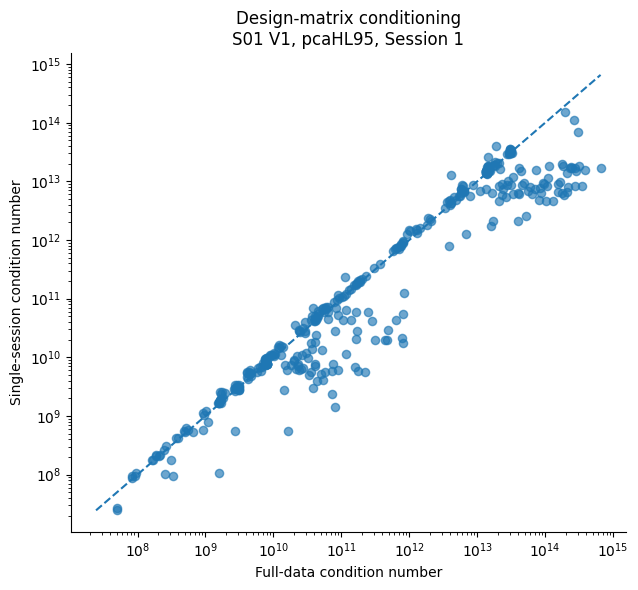

Saved: /content/drive/MyDrive/V2_drift/texturemodel/drift_results/conditioning_diagnostics/S01_V1_pcaHL95_session01_full_vs_session_condition.png


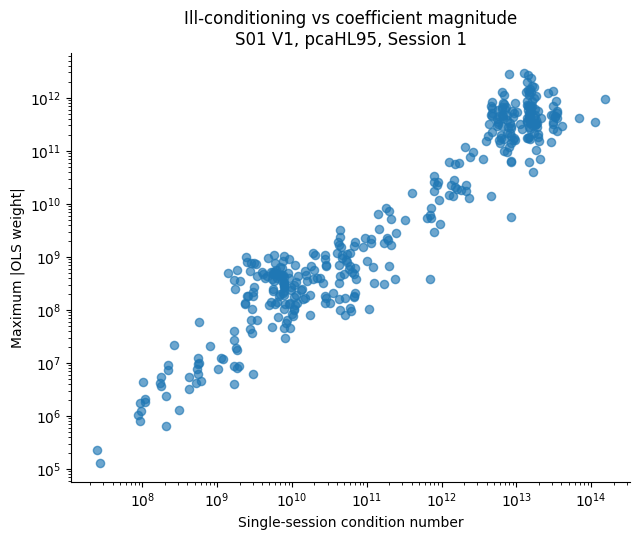

Saved: /content/drive/MyDrive/V2_drift/texturemodel/drift_results/conditioning_diagnostics/S01_V1_pcaHL95_session01_condition_vs_weight.png

CONDITION NUMBER ↔ WEIGHT MAGNITUDE
Pearson r between log10(condition number) and log10(max |weight|): 0.9580189601082382


In [ ]:
# DESIGN-MATRIX CONDITIONING CHECK.
# Purpose: reconstruct the actual TS design matrices for S01 V1 Session 1 and relate their condition numbers to the magnitude of the fitted OLS coefficients.

import os
import sys
import h5py
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# ============================================================
# PROJECT PATHS
# ============================================================

ROOT = Path("/content/drive/MyDrive/V2_drift")

TEXTURE_ROOT = ROOT / "texturemodel"
CODE_ROOT = TEXTURE_ROOT / "code"
MODEL_FITTING_ROOT = CODE_ROOT / "model_fitting"
UTILS_ROOT = CODE_ROOT / "utils"

# Add all relevant project directories
for p in [
    TEXTURE_ROOT,
    CODE_ROOT,
    MODEL_FITTING_ROOT,
    UTILS_ROOT,
]:
    p = str(p)
    if p not in sys.path:
        sys.path.insert(0, p)

# ============================================================
# CHECK THAT THE EXPECTED FILES EXIST
# ============================================================

print("Checking project paths:")

for fn in [
    MODEL_FITTING_ROOT / "arg_parser.py",
    MODEL_FITTING_ROOT / "initialize_fitting.py",
]:
    print(f"{fn}: {'✓' if fn.exists() else '✗ MISSING'}")

# ============================================================
# PROJECT IMPORTS
# ============================================================

from utils import nsd_utils, roi_utils
import arg_parser as project_arg_parser
import initialize_fitting

print("\n✓ Project imports successful")


# ============================================================
# CONFIG
# ============================================================

SUBJECT = 1
ROI = "V1"

# Start with one representative session.
# Python index 0 = Session 1
SESSION_INDEX = 0

PCA_TYPE = "pcaHL"
PCA_PCT = 95


FULL_FIT = (
    ROOT
    / "texturemodel/model_fits/S01"
    / "texture_pyramid_OLS_4ori_4sf_pcaHL_V1_pca95_use_nsd_grid5_pRFs"
    / "Jul-11-2026_2202_15"
    / "all_fit_params.npy"
)


CROSS_FIT = (
    ROOT
    / "texturemodel/model_fits/S01/FAST_CROSS_SESSION"
    / (
        "S01_V1_texture_pyramid_OLS_4ori_4sf_"
        "pcaHL_V1_pca95_use_nsd_grid5_pRFs_"
        "30x30_cross_session.h5py"
    )
)


OUT_DIR = (
    ROOT
    / "texturemodel/drift_results/conditioning_diagnostics"
)

OUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)


# ============================================================
# RECREATE EXACT FAST MODEL ARGUMENTS
# ============================================================

def build_project_args():

    old_argv = sys.argv.copy()

    sys.argv = [
        "conditioning_check",

        "--subject", str(SUBJECT),
        "--roi_name", ROI,

        "--debug", "0",
        "--up_to_sess", "30",

        "--whole_session_split", "1",
        "--average_image_reps", "0",

        "--sample_batch_size", "1000",
        "--voxel_batch_size", "1000",

        "--zscore_features", "0",
        "--zscore_betas_within_sess", "0",

        "--use_precomputed_prfs", "1",
        "--prfs_model_name", "nsd_grid5",
        "--which_prf_grid", "5",

        "--fitting_type", "texture_pyramid",

        "--n_ori_pyr", "4",
        "--n_sf_pyr", "4",

        "--group_all_hl_feats", "1",

        "--pyr_pca_type", PCA_TYPE,
        "--pca_pct_var", str(PCA_PCT),

        "--set_lambda_per_group", "0",
        "--ridge", "0",

        "--do_val", "1",
        "--do_corrcoef", "1",

        "--do_tuning", "0",
        "--do_sem_disc", "0",
        "--do_pyr_varpart", "0",

        "--trial_subset", "all",
    ]

    try:
        args = project_arg_parser.get_args()

    finally:
        sys.argv = old_argv

    return args


args = build_project_args()


# ============================================================
# ROI MASK — SAME ROI DEFINITION AS FAST CROSS SESSION
# ============================================================

voxel_mask, _, voxel_roi, _, _ = (
    roi_utils.get_voxel_roi_info(
        SUBJECT,
        args.volume_space,
        use_kastner_areas=False,
    )
)

roi_codes = {
    "V1": [1, 2],
    "V2": [3, 4],
    "V3": [5, 6],
    "hV4": [7],
}

roi_keep = np.isin(
    voxel_roi[0],
    roi_codes[ROI],
)

voxel_mask = (
    voxel_mask
    & roi_keep
)


# ============================================================
# LOAD ACTUAL SESSION TRIALS
#
# FAST_CROSS_SESSION uses all session trials for fitting.
# ============================================================

(
    voxel_data,
    session_image_order,
    val_inds,
    holdout_inds,
    session_inds,
) = nsd_utils.get_data_splits_single_train(
    SUBJECT,
    sessions=np.asarray(
        [SESSION_INDEX],
        dtype=int
    ),
    voxel_mask=voxel_mask,
    volume_space=args.volume_space,
    zscore_betas_within_sess=args.zscore_betas_within_sess,
    shuffle_images=args.shuffle_images_once,
    average_image_reps=args.average_image_reps,
    random_voxel_data=args.random_voxel_data,
)

session_image_order = np.asarray(
    session_image_order,
    dtype=int,
).reshape(-1)


print("=" * 100)
print("SESSION DATA")
print("=" * 100)

print(
    f"Session: {SESSION_INDEX + 1}"
)

print(
    "Number of training trials:",
    len(session_image_order)
)

print(
    "First 10 image indices:",
    session_image_order[:10]
)


# ============================================================
# LOAD FULL-DATA IMAGE ORDER
# ============================================================

D_full = np.load(
    FULL_FIT,
    allow_pickle=True,
).item()

full_image_order = np.asarray(
    D_full["image_order"],
    dtype=int,
).reshape(-1)


full_weights = np.asarray(
    D_full["best_params"][1],
    dtype=np.float64,
)[..., 0]


assert full_weights.shape[1] == 54


print("\n" + "=" * 100)
print("FULL DATA")
print("=" * 100)

print(
    "Full-data trials/images:",
    len(full_image_order)
)

print(
    "Full fit weight shape:",
    full_weights.shape
)


# ============================================================
# LOAD CROSS-SESSION pRF INDICES + SESSION WEIGHTS
# ============================================================

with h5py.File(
    CROSS_FIT,
    "r",
) as f:

    fixed_prf = np.asarray(
        f["fixed_best_model_each_voxel"],
        dtype=int,
    )

    session_weights = np.asarray(
        f["best_weights"][
            SESSION_INDEX,
            :,
            :,
            0,
        ],
        dtype=np.float64,
    )


assert session_weights.shape[1] == 54


print("\nCross-session voxels:", len(fixed_prf))
print("Cross-session weight shape:", session_weights.shape)


# ============================================================
# FEATURE LOADER — EXACT MODEL REPRESENTATION
# ============================================================

model_name, fitting_types = (
    initialize_fitting.get_full_save_name(
        args
    )
)

# ============================================================
# TWO SEPARATE FEATURE LOADERS
#
# The loader internally caches features according to image_inds.
# We therefore need one loader for the 750 session trials and
# another for the 9209 full-data trials.
# ============================================================

session_feature_loader = (
    initialize_fitting.make_feature_loaders(
        args,
        fitting_types,
        vi=0,
        dnn_layers_use=None,
    )
)

full_feature_loader = (
    initialize_fitting.make_feature_loaders(
        args,
        fitting_types,
        vi=0,
        dnn_layers_use=None,
    )
)

partial_masks, partial_version_names = (
    session_feature_loader.get_partial_versions()
)

partial_masks = np.asarray(
    partial_masks
)

n_partial = len(
    partial_version_names
)

if (
    partial_masks.ndim == 2
    and partial_masks.shape[0] == n_partial
):

    partial_mask_full = np.asarray(
        partial_masks[0],
        dtype=bool,
    )

elif (
    partial_masks.ndim == 2
    and partial_masks.shape[1] == n_partial
):

    partial_mask_full = np.asarray(
        partial_masks[:, 0],
        dtype=bool,
    )

else:

    raise RuntimeError(
        f"Unexpected partial mask shape: "
        f"{partial_masks.shape}"
    )


partial_mask_full = partial_mask_full[
    :session_feature_loader.max_features
]

assert (
    session_feature_loader.max_features
    ==
    full_feature_loader.max_features
)

print("\nModel:", model_name)
print(
    "Feature-loader max dimensions:",
    session_feature_loader.max_features
)


# ============================================================
# CONDITIONING HELPER
# ============================================================

def matrix_diagnostics(X):
    """
    Return conditioning diagnostics for X.

    We center columns because the encoding model also has a
    separate bias/intercept. Conditioning of the centered feature
    matrix is therefore particularly informative.
    """

    X = np.asarray(
        X,
        dtype=np.float64,
    )

    # Remove rows containing nonfinite values
    row_ok = np.all(
        np.isfinite(X),
        axis=1,
    )

    X = X[row_ok]

    if X.shape[0] == 0:
        return {
            "n_samples": 0,
            "n_features": X.shape[1],
            "rank": 0,
            "sigma_max": np.nan,
            "sigma_min": np.nan,
            "condition_number": np.nan,
            "log10_condition": np.nan,
        }

    # Separate intercept means we examine centered predictors.
    Xc = (
        X
        - np.mean(
            X,
            axis=0,
            keepdims=True,
        )
    )

    # Remove columns that are exactly constant / zero after centering
    col_norm = np.linalg.norm(
        Xc,
        axis=0,
    )

    good_cols = (
        np.isfinite(col_norm)
        & (col_norm > 0)
    )

    Xc = Xc[
        :,
        good_cols
    ]

    if Xc.shape[1] == 0:
        return {
            "n_samples": Xc.shape[0],
            "n_features": 0,
            "rank": 0,
            "sigma_max": np.nan,
            "sigma_min": np.nan,
            "condition_number": np.inf,
            "log10_condition": np.inf,
        }

    s = np.linalg.svd(
        Xc,
        compute_uv=False,
        full_matrices=False,
    )

    sigma_max = float(
        s[0]
    )

    sigma_min = float(
        s[-1]
    )

    # Same numerical-rank style criterion used by common
    # linear-algebra routines.
    tol = (
        max(Xc.shape)
        * np.finfo(np.float64).eps
        * sigma_max
    )

    rank = int(
        np.sum(s > tol)
    )

    if sigma_min <= 0:
        cond = np.inf
    else:
        cond = (
            sigma_max
            / sigma_min
        )

    logcond = (
        np.log10(cond)
        if np.isfinite(cond)
        else np.inf
    )

    return {
        "n_samples": Xc.shape[0],
        "n_features": Xc.shape[1],
        "rank": rank,
        "sigma_max": sigma_max,
        "sigma_min": sigma_min,
        "condition_number": cond,
        "log10_condition": logcond,
    }


# ============================================================
# LOOP OVER OCCUPIED pRFs
#
# X is identical for voxels sharing a pRF, so there is no need
# to recompute its SVD independently for every voxel.
# ============================================================

unique_prfs = np.unique(
    fixed_prf[
        fixed_prf >= 0
    ]
)

print("\n" + "=" * 100)
print("CONDITIONING ANALYSIS")
print("=" * 100)

print(
    "Occupied pRFs:",
    len(unique_prfs)
)


rows = []


for ii, prf in enumerate(
    unique_prfs,
    start=1,
):

    vox = np.flatnonzero(
        fixed_prf == prf
    )

    print(
        f"{ii:4d}/{len(unique_prfs)} "
        f"| pRF={prf:4d} "
        f"| voxels={len(vox)}"
    )

    # --------------------------------------------------------
    # SINGLE SESSION X
    # --------------------------------------------------------

    (
        feat_session,
        defined_session,
    ) = session_feature_loader.load(
        session_image_order,
        prf_model_index=int(prf),
    )

    feat_session = np.asarray(
        feat_session,
        dtype=np.float64,
    )

    defined_session = np.asarray(
        defined_session,
        dtype=bool,
    )


    mask_session = (
        partial_mask_full[
            defined_session
        ]
    )

    X_session = feat_session[
        :,
        mask_session
    ]


    # --------------------------------------------------------
    # FULL-DATA X
    # --------------------------------------------------------

    (
        feat_full,
        defined_full,
    ) = full_feature_loader.load(
        full_image_order,
        prf_model_index=int(prf),
    )

    feat_full = np.asarray(
        feat_full,
        dtype=np.float64,
    )

    defined_full = np.asarray(
        defined_full,
        dtype=bool,
    )


    mask_full = (
        partial_mask_full[
            defined_full
        ]
    )

    X_full = feat_full[
        :,
        mask_full
    ]

    # --------------------------------------------------------
    # SAFETY CHECK:
    # session and full-data loaders must expose exactly the
    # same feature columns for this pRF.
    # --------------------------------------------------------

    assert np.array_equal(
        defined_session,
        defined_full
    ), (
        f"pRF {prf}: defined feature columns differ "
        f"between session and full-data loaders"
    )

    assert np.array_equal(
        mask_session,
        mask_full
    ), (
        f"pRF {prf}: partial feature masks differ "
        f"between session and full-data loaders"
    )

    assert X_session.shape[1] == X_full.shape[1], (
        f"pRF {prf}: feature-count mismatch: "
        f"session={X_session.shape[1]}, "
        f"full={X_full.shape[1]}"
    )

    # --------------------------------------------------------
    # DIAGNOSTICS
    # --------------------------------------------------------

    ds = matrix_diagnostics(
        X_session
    )

    dfull = matrix_diagnostics(
        X_full
    )

    # --------------------------------------------------------
    # SESSION WEIGHTS FOR EXACTLY THE SAME FEATURES
    #
    # best_weights always has max width = 54, but each pRF
    # may actually contain fewer defined PCA columns.
    # Restrict the stored weights to the exact columns used
    # in X_session / X_full.
    # --------------------------------------------------------

    W = session_weights[
        vox,
        :
    ]

    W = W[
        :,
        defined_session
    ]

    W = W[
        :,
        mask_session
    ]

    assert W.shape[1] == X_session.shape[1], (
        f"pRF {prf}: X/weight mismatch: "
        f"X has {X_session.shape[1]} features, "
        f"W has {W.shape[1]}"
    )

    w_abs = np.abs(
        W[
            np.isfinite(W)
        ]
    )

    if w_abs.size == 0:
        raise RuntimeError(
            f"pRF {prf}: no finite weights"
        )


    rows.append({
        "prf":
            int(prf),

        "n_voxels":
            len(vox),

        # Session X
        "session_n_samples":
            ds["n_samples"],

        "session_n_features":
            ds["n_features"],

        "session_rank":
            ds["rank"],

        "session_sigma_max":
            ds["sigma_max"],

        "session_sigma_min":
            ds["sigma_min"],

        "session_cond":
            ds["condition_number"],

        "session_log10_cond":
            ds["log10_condition"],

        # Full X
        "full_n_samples":
            dfull["n_samples"],

        "full_n_features":
            dfull["n_features"],

        "full_rank":
            dfull["rank"],

        "full_sigma_max":
            dfull["sigma_max"],

        "full_sigma_min":
            dfull["sigma_min"],

        "full_cond":
            dfull["condition_number"],

        "full_log10_cond":
            dfull["log10_condition"],

        # Session weight scale
        "median_abs_weight":
            np.median(w_abs),

        "p99_abs_weight":
            np.percentile(
                w_abs,
                99
            ),

        "max_abs_weight":
            np.max(w_abs),
    })


session_feature_loader.clear_big_features()
full_feature_loader.clear_big_features()


res = pd.DataFrame(
    rows
)


# ============================================================
# SAVE TABLE
# ============================================================

csv_fn = (
    OUT_DIR
    / (
        f"S01_V1_pcaHL95_"
        f"session{SESSION_INDEX + 1:02d}_"
        "conditioning.csv"
    )
)

res.to_csv(
    csv_fn,
    index=False,
)

print("\nSaved:")
print(csv_fn)


# ============================================================
# SUMMARY
# ============================================================

print("\n" + "=" * 100)
print("SUMMARY")
print("=" * 100)

print(
    "\nSESSION DESIGN MATRICES"
)

print(
    "Median log10(condition number):",
    np.nanmedian(
        res["session_log10_cond"]
    )
)

print(
    "Median smallest singular value:",
    np.nanmedian(
        res["session_sigma_min"]
    )
)

print(
    "Rank-deficient pRFs:",
    np.sum(
        res["session_rank"]
        <
        res["session_n_features"]
    ),
    "/",
    len(res)
)


print(
    "\nFULL-DATA DESIGN MATRICES"
)

print(
    "Median log10(condition number):",
    np.nanmedian(
        res["full_log10_cond"]
    )
)

print(
    "Median smallest singular value:",
    np.nanmedian(
        res["full_sigma_min"]
    )
)

print(
    "Rank-deficient pRFs:",
    np.sum(
        res["full_rank"]
        <
        res["full_n_features"]
    ),
    "/",
    len(res)
)


# ============================================================
# WORST SESSION pRFs
# ============================================================

print("\n" + "=" * 100)
print("WORST-CONDITIONED SINGLE-SESSION pRFs")
print("=" * 100)

display(
    res[
        [
            "prf",
            "n_voxels",
            "session_n_samples",
            "session_n_features",
            "session_rank",
            "session_sigma_min",
            "session_cond",
            "session_log10_cond",
            "full_cond",
            "max_abs_weight",
        ]
    ]
    .sort_values(
        "session_cond",
        ascending=False
    )
    .head(20)
)


# ============================================================
# FIGURE 1
# FULL DATA VS SINGLE SESSION CONDITION NUMBER
# ============================================================

valid = (
    np.isfinite(
        res["session_cond"]
    )
    &
    np.isfinite(
        res["full_cond"]
    )
    &
    (res["session_cond"] > 0)
    &
    (res["full_cond"] > 0)
)


fig, ax = plt.subplots(
    figsize=(6.5, 6)
)

ax.scatter(
    res.loc[
        valid,
        "full_cond"
    ],
    res.loc[
        valid,
        "session_cond"
    ],
    s=35,
    alpha=0.65,
)

ax.set_xscale("log")
ax.set_yscale("log")

lo = min(
    res.loc[
        valid,
        ["full_cond", "session_cond"]
    ].min()
)

hi = max(
    res.loc[
        valid,
        ["full_cond", "session_cond"]
    ].max()
)

ax.plot(
    [lo, hi],
    [lo, hi],
    linestyle="--",
    linewidth=1.5,
)

ax.set_xlabel(
    "Full-data condition number"
)

ax.set_ylabel(
    "Single-session condition number"
)

ax.set_title(
    "Design-matrix conditioning\n"
    "S01 V1, pcaHL95, Session 1"
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

fig.tight_layout()

fig_fn = (
    OUT_DIR
    / "S01_V1_pcaHL95_session01_full_vs_session_condition.png"
)

fig.savefig(
    fig_fn,
    dpi=300,
    bbox_inches="tight",
)

plt.show()

print("Saved:", fig_fn)


# ============================================================
# FIGURE 2
# CONDITION NUMBER VS WEIGHT EXPLOSION
# ============================================================

valid = (
    np.isfinite(
        res["session_cond"]
    )
    &
    np.isfinite(
        res["max_abs_weight"]
    )
    &
    (res["session_cond"] > 0)
    &
    (res["max_abs_weight"] > 0)
)


fig, ax = plt.subplots(
    figsize=(6.5, 5.5)
)

ax.scatter(
    res.loc[
        valid,
        "session_cond"
    ],
    res.loc[
        valid,
        "max_abs_weight"
    ],
    s=35,
    alpha=0.65,
)

ax.set_xscale("log")
ax.set_yscale("log")

ax.set_xlabel(
    "Single-session condition number"
)

ax.set_ylabel(
    "Maximum |OLS weight|"
)

ax.set_title(
    "Ill-conditioning vs coefficient magnitude\n"
    "S01 V1, pcaHL95, Session 1"
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

fig.tight_layout()

fig_fn = (
    OUT_DIR
    / "S01_V1_pcaHL95_session01_condition_vs_weight.png"
)

fig.savefig(
    fig_fn,
    dpi=300,
    bbox_inches="tight",
)

plt.show()

print("Saved:", fig_fn)


# ============================================================
# NUMERICAL ASSOCIATION
# ============================================================

x = np.log10(
    res.loc[
        valid,
        "session_cond"
    ].values
)

y = np.log10(
    res.loc[
        valid,
        "max_abs_weight"
    ].values
)

r = np.corrcoef(
    x,
    y
)[0, 1]

print("\n" + "=" * 100)
print("CONDITION NUMBER ↔ WEIGHT MAGNITUDE")
print("=" * 100)

print(
    "Pearson r between "
    "log10(condition number) and "
    "log10(max |weight|):",
    r
)


## 6. SVD mechanism: do tiny singular values actually generate the extreme weights?

For OLS,

\[
\hat{\beta}=V\Sigma^{-1}U^\top y.
\]

This means that response components projected onto directions with very small singular values are divided by those small values and can be strongly amplified.

The analysis below compares the most poorly conditioned pRF with a control pRF near the median condition number and reconstructs the saved OLS coefficients directly from the SVD.

### Finding

For the catastrophic pRF (pRF 216), the design matrix had 51 predictors but rank 47, a condition number of approximately \(1.51\times10^{14}\), and a saved maximum coefficient of approximately \(9.53\times10^{11}\). Several singular values were on the order of \(10^{-9}\).

The explicit SVD reconstruction reproduced the saved coefficients almost exactly (\(r\approx0.99983\)), with a reconstructed maximum coefficient of approximately \(9.57\times10^{11}\).

**Conclusion:** the coefficient explosion is mathematically reproduced by the OLS solution itself. It is not merely corruption introduced when the weights are saved.


SELECTED pRFs
Catastrophic pRF : 216
Control pRF      : 948

pRF  216 | condition=1.508e+14 | log10(cond)=14.178 | sigma_min=1.942e-09 | max|w|=9.531e+11 | nvox=1
pRF  948 | condition=7.079e+10 | log10(cond)=10.850 | sigma_min=4.718e-07 | max|w|=3.816e+08 | nvox=2
making feature loader with image set: S1
Loading pre-computed features for models [200 - 299] from /content/drive/MyDrive/V2_drift/features/pyramid_texture/PCA_pcaHL_v95/S1_4ori_4sf_pcaHL_concat_v95pct_grid5.h5py
Took 3.39857 seconds to load file
Size of features array for this image set and batch is:
(750, 54, 100)
Number of nans in each prf this batch:
[np.int64(2), np.int64(3), np.int64(3), np.int64(3), np.int64(3), np.int64(3), np.int64(3), np.int64(3), np.int64(2), np.int64(3), np.int64(3), np.int64(3), np.int64(3), np.int64(2), np.int64(2), np.int64(2), np.int64(3), np.int64(2), np.int64(2), np.int64(2), np.int64(3), np.int64(2), np.int64(2), np.int64(2), np.int64(3), np.int64(2), np.int64(2), np.int64(2), np.int64(3), 

,0,1
type,catastrophic,control
prf,216,948
n_voxels,1,2
n_samples,750,750
n_features,51,51
rank,47,51
sigma_max,292745.43536,33393.635583
sigma_min,0.0,0.0
condition_number,150767414029192.4375,70786576831.238968
saved_max_abs_weight,953080938496.0,381641600.0



SAVED-WEIGHT RECONSTRUCTION CHECK
Catastrophic    | saved-vs-SVD r = 0.99982845 | saved max = 9.531e+11 | SVD max = 9.566e+11
Control         | saved-vs-SVD r = 1.00000000 | saved max = 3.816e+08 | SVD max = 3.816e+08


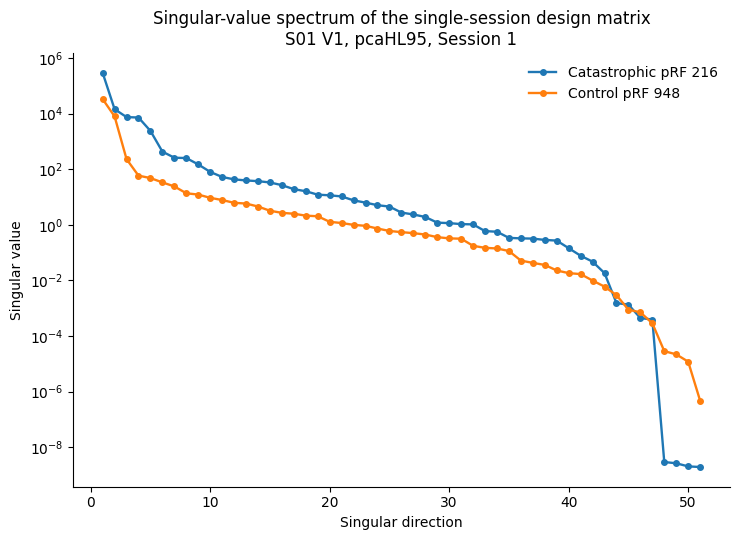

Saved: /content/drive/MyDrive/V2_drift/texturemodel/drift_results/conditioning_diagnostics/S01_V1_pcaHL95_session01_singular_spectrum_bad_vs_control.png


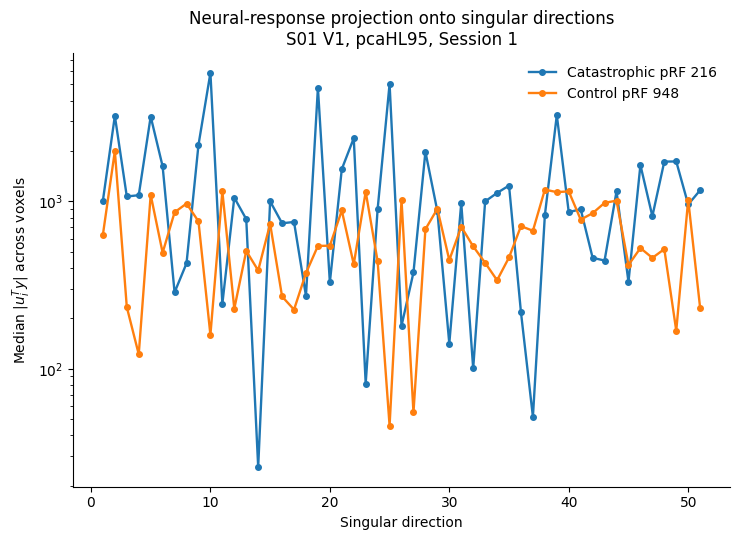

Saved: /content/drive/MyDrive/V2_drift/texturemodel/drift_results/conditioning_diagnostics/S01_V1_pcaHL95_session01_Uty_bad_vs_control.png


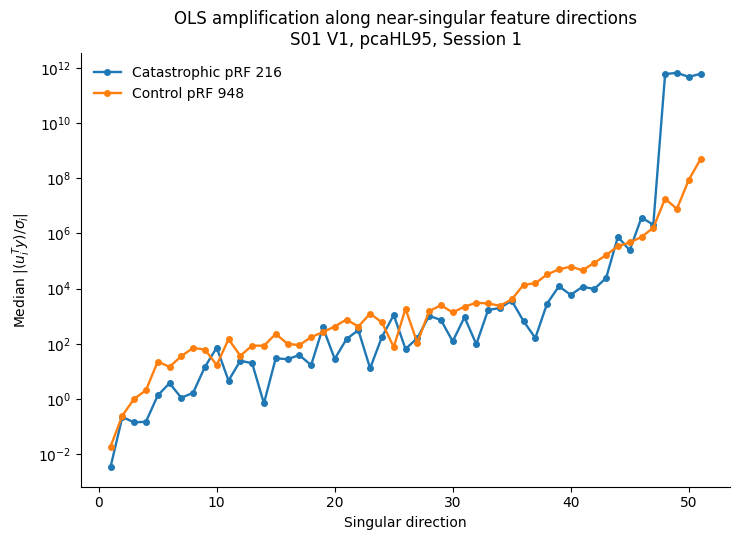

Saved: /content/drive/MyDrive/V2_drift/texturemodel/drift_results/conditioning_diagnostics/S01_V1_pcaHL95_session01_OLS_amplification_bad_vs_control.png

CATASTROPHIC pRF — SMALLEST SINGULAR-VALUE DIRECTIONS


,direction,singular_value,log10_singular_value,median_abs_Uty,max_abs_Uty,median_abs_amplified,max_abs_amplified
50,51,1.941702e-09,-8.711817,1165.707500,1165.707500,6.003534e+11,6.003534e+11
49,50,2.043530e-09,-8.689619,958.115847,958.115847,4.688533e+11,4.688533e+11
48,49,2.646947e-09,-8.577255,1730.986012,1730.986012,6.539558e+11,6.539558e+11
47,48,2.932266e-09,-8.532797,1728.058154,1728.058154,5.893251e+11,5.893251e+11
46,47,3.924346e-04,-3.406233,815.210063,815.210063,2.077314e+06,2.077314e+06
45,46,4.424388e-04,-3.354147,1647.504326,1647.504326,3.723688e+06,3.723688e+06
44,45,1.351227e-03,-2.869272,330.448447,330.448447,2.445543e+05,2.445543e+05
43,44,1.527962e-03,-2.815887,1149.201864,1149.201864,7.521139e+05,7.521139e+05
42,43,1.832366e-02,-1.736988,443.265739,443.265739,2.419090e+04,2.419090e+04
41,42,4.729747e-02,-1.325162,460.052719,460.052719,9.726794e+03,9.726794e+03



CONTROL pRF — SMALLEST SINGULAR-VALUE DIRECTIONS


,direction,singular_value,log10_singular_value,median_abs_Uty,max_abs_Uty,median_abs_amplified,max_abs_amplified
50,51,4.717510e-07,-6.326287,230.673416,255.581897,4.889729e+08,5.417729e+08
49,50,1.196821e-05,-4.921971,1022.600978,2030.790699,8.544308e+07,1.696820e+08
48,49,2.188289e-05,-4.659895,168.937589,329.434180,7.720077e+06,1.505442e+07
47,48,2.859564e-05,-4.543700,518.605759,1035.520247,1.813583e+07,3.621252e+07
46,47,2.877329e-04,-3.541010,459.703946,529.299613,1.597676e+06,1.839552e+06
45,46,7.103521e-04,-3.148526,526.249604,856.411229,7.408293e+05,1.205615e+06
44,45,8.876027e-04,-3.051781,416.794699,646.790927,4.695735e+05,7.286942e+05
43,44,2.945536e-03,-2.530836,1010.090250,1447.487557,3.429223e+05,4.914173e+05
42,43,5.980703e-03,-2.223248,979.667714,1259.598499,1.638048e+05,2.106104e+05
41,42,9.891113e-03,-2.004755,850.094288,1475.615206,8.594526e+04,1.491860e+05



Saved:
/content/drive/MyDrive/V2_drift/texturemodel/drift_results/conditioning_diagnostics/S01_V1_pcaHL95_session01_SVD_mechanism_summary.csv
/content/drive/MyDrive/V2_drift/texturemodel/drift_results/conditioning_diagnostics/S01_V1_pcaHL95_session01_pRF216_SVD_directions.csv
/content/drive/MyDrive/V2_drift/texturemodel/drift_results/conditioning_diagnostics/S01_V1_pcaHL95_session01_pRF948_SVD_directions.csv


In [ ]:
# SVD MECHANISM CHECK.
# Purpose: test whether tiny singular values directly generate the extreme OLS coefficients and whether an explicit SVD reconstruction reproduces the saved weights.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# ============================================================
# CONFIG
# ============================================================

OUT_DIR = Path(
    "/content/drive/MyDrive/V2_drift/texturemodel/"
    "drift_results/conditioning_diagnostics"
)

OUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

# ------------------------------------------------------------
# Automatically choose:
#   1. worst-conditioned pRF
#   2. control pRF near median condition number
# ------------------------------------------------------------

valid_res = res[
    np.isfinite(res["session_cond"])
    &
    (res["session_cond"] > 0)
].copy()

BAD_PRF = int(
    valid_res.loc[
        valid_res["session_cond"].idxmax(),
        "prf"
    ]
)

median_logcond = np.median(
    np.log10(valid_res["session_cond"])
)

CONTROL_PRF = int(
    valid_res.iloc[
        np.argmin(
            np.abs(
                np.log10(valid_res["session_cond"].values)
                - median_logcond
            )
        )
    ]["prf"]
)

print("=" * 100)
print("SELECTED pRFs")
print("=" * 100)

print("Catastrophic pRF :", BAD_PRF)
print("Control pRF      :", CONTROL_PRF)

print()

for prf in [BAD_PRF, CONTROL_PRF]:

    rr = valid_res[
        valid_res["prf"] == prf
    ].iloc[0]

    print(
        f"pRF {prf:4d} | "
        f"condition={rr['session_cond']:.3e} | "
        f"log10(cond)={rr['session_log10_cond']:.3f} | "
        f"sigma_min={rr['session_sigma_min']:.3e} | "
        f"max|w|={rr['max_abs_weight']:.3e} | "
        f"nvox={int(rr['n_voxels'])}"
    )


# ============================================================
# NEW SESSION FEATURE LOADER
#
# Your previous cell cleared its large feature cache, so make
# a fresh loader for this diagnostic.
# ============================================================

mechanism_loader = (
    initialize_fitting.make_feature_loaders(
        args,
        fitting_types,
        vi=0,
        dnn_layers_use=None,
    )
)

partial_masks, partial_version_names = (
    mechanism_loader.get_partial_versions()
)

partial_masks = np.asarray(
    partial_masks
)

n_partial = len(
    partial_version_names
)

if (
    partial_masks.ndim == 2
    and partial_masks.shape[0] == n_partial
):
    partial_mask_full = np.asarray(
        partial_masks[0],
        dtype=bool
    )

elif (
    partial_masks.ndim == 2
    and partial_masks.shape[1] == n_partial
):
    partial_mask_full = np.asarray(
        partial_masks[:, 0],
        dtype=bool
    )

else:
    raise RuntimeError(
        f"Unexpected partial mask shape: {partial_masks.shape}"
    )

partial_mask_full = partial_mask_full[
    :mechanism_loader.max_features
]


# ============================================================
# ANALYZE ONE pRF
# ============================================================

def analyze_prf_mechanism(prf):

    vox = np.flatnonzero(
        fixed_prf == prf
    )

    if len(vox) == 0:
        raise RuntimeError(
            f"No cross-session voxels use pRF {prf}"
        )

    # --------------------------------------------------------
    # Load exact feature matrix for Session 1
    # --------------------------------------------------------

    (
        feat,
        defined
    ) = mechanism_loader.load(
        session_image_order,
        prf_model_index=int(prf)
    )

    feat = np.asarray(
        feat,
        dtype=np.float64
    )

    defined = np.asarray(
        defined,
        dtype=bool
    )

    partial_mask = (
        partial_mask_full[
            defined
        ]
    )

    X = feat[
        :,
        partial_mask
    ]

    # Exact corresponding stored weights
    W_saved = session_weights[
        vox,
        :
    ]

    W_saved = W_saved[
        :,
        defined
    ]

    W_saved = W_saved[
        :,
        partial_mask
    ]

    assert X.shape[1] == W_saved.shape[1]

    # --------------------------------------------------------
    # Remove nonfinite rows
    # --------------------------------------------------------

    row_ok = np.all(
        np.isfinite(X),
        axis=1
    )

    X = X[row_ok]

    # measured beta responses:
    # trials × ROI voxels
    Y = np.asarray(
        voxel_data[
            row_ok,
            :
        ],
        dtype=np.float64
    )

    Y = Y[
        :,
        vox
    ]

    # --------------------------------------------------------
    # Center X and Y.
    #
    # Saved model has a separate bias, so slope coefficients
    # correspond to regression on centered predictors/target.
    # --------------------------------------------------------

    X_mean = np.mean(
        X,
        axis=0,
        keepdims=True
    )

    Xc = X - X_mean

    Y_mean = np.mean(
        Y,
        axis=0,
        keepdims=True
    )

    Yc = Y - Y_mean

    # --------------------------------------------------------
    # Remove constant feature columns if any
    # --------------------------------------------------------

    col_norm = np.linalg.norm(
        Xc,
        axis=0
    )

    good_cols = (
        np.isfinite(col_norm)
        &
        (col_norm > 0)
    )

    Xc_use = Xc[
        :,
        good_cols
    ]

    W_saved_use = W_saved[
        :,
        good_cols
    ]

    # --------------------------------------------------------
    # SVD
    #
    # X = U S V^T
    # --------------------------------------------------------

    U, S, Vt = np.linalg.svd(
        Xc_use,
        full_matrices=False
    )

    # Numerical rank
    tol = (
        max(Xc_use.shape)
        *
        np.finfo(np.float64).eps
        *
        S[0]
    )

    rank = int(
        np.sum(S > tol)
    )

    condition = (
        S[0] / S[-1]
        if S[-1] > 0
        else np.inf
    )

    # ========================================================
    # PROJECT y ONTO LEFT-SINGULAR DIRECTIONS
    #
    # U.T @ Yc:
    #     singular direction × voxel
    # ========================================================

    Uy = U.T @ Yc

    # --------------------------------------------------------
    # OLS amplification in singular coordinates:
    #
    # alpha_i = (u_i^T y) / sigma_i
    # --------------------------------------------------------

    with np.errstate(
        divide="ignore",
        invalid="ignore"
    ):

        amplified = (
            Uy
            /
            S[:, None]
        )

    # --------------------------------------------------------
    # Reconstruct OLS coefficients from SVD
    # --------------------------------------------------------

    beta_svd = (
        Vt.T
        @ amplified
    )

    # features × voxels -> voxels × features
    beta_svd = beta_svd.T

    # ========================================================
    # Compare reconstructed OLS coefficients to SAVED weights
    # ========================================================

    saved_flat = W_saved_use.ravel()
    svd_flat = beta_svd.ravel()

    finite_compare = (
        np.isfinite(saved_flat)
        &
        np.isfinite(svd_flat)
    )

    weight_r = np.corrcoef(
        saved_flat[finite_compare],
        svd_flat[finite_compare]
    )[0, 1]

    median_abs_difference = np.median(
        np.abs(
            saved_flat[finite_compare]
            -
            svd_flat[finite_compare]
        )
    )

    # ========================================================
    # Summarize each singular direction
    # ========================================================

    direction_df = pd.DataFrame({
        "direction":
            np.arange(1, len(S) + 1),

        "singular_value":
            S,

        "log10_singular_value":
            np.log10(S),

        # across voxels using this pRF
        "median_abs_Uty":
            np.median(
                np.abs(Uy),
                axis=1
            ),

        "max_abs_Uty":
            np.max(
                np.abs(Uy),
                axis=1
            ),

        "median_abs_amplified":
            np.median(
                np.abs(amplified),
                axis=1
            ),

        "max_abs_amplified":
            np.max(
                np.abs(amplified),
                axis=1
            ),
    })

    summary = {
        "prf": int(prf),
        "n_voxels": len(vox),

        "n_samples": Xc_use.shape[0],
        "n_features": Xc_use.shape[1],

        "rank": rank,

        "sigma_max": S[0],
        "sigma_min": S[-1],

        "condition_number": condition,

        "saved_max_abs_weight":
            np.nanmax(
                np.abs(W_saved_use)
            ),

        "svd_max_abs_weight":
            np.nanmax(
                np.abs(beta_svd)
            ),

        "saved_vs_svd_r":
            weight_r,

        "median_abs_saved_vs_svd_diff":
            median_abs_difference,

        "max_abs_Uty":
            np.nanmax(
                np.abs(Uy)
            ),

        "max_abs_amplification":
            np.nanmax(
                np.abs(amplified)
            ),
    }

    return {
        "summary": summary,
        "directions": direction_df,
        "S": S,
        "Uy": Uy,
        "amplified": amplified,
        "beta_svd": beta_svd,
        "W_saved": W_saved_use,
    }


# ============================================================
# RUN BAD + CONTROL
# ============================================================

bad = analyze_prf_mechanism(
    BAD_PRF
)

control = analyze_prf_mechanism(
    CONTROL_PRF
)

mechanism_loader.clear_big_features()


# ============================================================
# SUMMARY TABLE
# ============================================================

summary_df = pd.DataFrame([
    {
        "type": "catastrophic",
        **bad["summary"]
    },
    {
        "type": "control",
        **control["summary"]
    },
])

print("\n" + "=" * 100)
print("SVD MECHANISM SUMMARY")
print("=" * 100)

display(
    summary_df.T
)


# ============================================================
# IMPORTANT VALIDATION
# ============================================================

print("\n" + "=" * 100)
print("SAVED-WEIGHT RECONSTRUCTION CHECK")
print("=" * 100)

for label, result in [
    ("Catastrophic", bad),
    ("Control", control),
]:

    s = result["summary"]

    print(
        f"{label:15s} | "
        f"saved-vs-SVD r = {s['saved_vs_svd_r']:.8f} | "
        f"saved max = {s['saved_max_abs_weight']:.3e} | "
        f"SVD max = {s['svd_max_abs_weight']:.3e}"
    )


# ============================================================
# FIGURE 1 — SINGULAR VALUE SPECTRUM
# ============================================================

fig, ax = plt.subplots(
    figsize=(7.5, 5.5)
)

for label, result in [
    (f"Catastrophic pRF {BAD_PRF}", bad),
    (f"Control pRF {CONTROL_PRF}", control),
]:

    S = result["S"]

    ax.plot(
        np.arange(1, len(S) + 1),
        S,
        marker="o",
        markersize=4,
        linewidth=1.7,
        label=label
    )

ax.set_yscale("log")

ax.set_xlabel(
    "Singular direction"
)

ax.set_ylabel(
    "Singular value"
)

ax.set_title(
    "Singular-value spectrum of the single-session design matrix\n"
    "S01 V1, pcaHL95, Session 1"
)

ax.legend(
    frameon=False
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

fig.tight_layout()

fn = (
    OUT_DIR
    / "S01_V1_pcaHL95_session01_singular_spectrum_bad_vs_control.png"
)

fig.savefig(
    fn,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved:", fn)


# ============================================================
# FIGURE 2 — TARGET PROJECTION |u_i^T y|
# ============================================================

fig, ax = plt.subplots(
    figsize=(7.5, 5.5)
)

for label, result in [
    (f"Catastrophic pRF {BAD_PRF}", bad),
    (f"Control pRF {CONTROL_PRF}", control),
]:

    d = result["directions"]

    ax.plot(
        d["direction"],
        d["median_abs_Uty"],
        marker="o",
        markersize=4,
        linewidth=1.7,
        label=label
    )

ax.set_yscale("log")

ax.set_xlabel(
    "Singular direction"
)

ax.set_ylabel(
    r"Median $|u_i^T y|$ across voxels"
)

ax.set_title(
    "Neural-response projection onto singular directions\n"
    "S01 V1, pcaHL95, Session 1"
)

ax.legend(
    frameon=False
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

fig.tight_layout()

fn = (
    OUT_DIR
    / "S01_V1_pcaHL95_session01_Uty_bad_vs_control.png"
)

fig.savefig(
    fn,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved:", fn)


# ============================================================
# FIGURE 3 — THE KEY MECHANISTIC QUANTITY
#
# |u_i^T y / sigma_i|
# ============================================================

fig, ax = plt.subplots(
    figsize=(7.5, 5.5)
)

for label, result in [
    (f"Catastrophic pRF {BAD_PRF}", bad),
    (f"Control pRF {CONTROL_PRF}", control),
]:

    d = result["directions"]

    ax.plot(
        d["direction"],
        d["median_abs_amplified"],
        marker="o",
        markersize=4,
        linewidth=1.7,
        label=label
    )

ax.set_yscale("log")

ax.set_xlabel(
    "Singular direction"
)

ax.set_ylabel(
    r"Median $|(u_i^T y)/\sigma_i|$"
)

ax.set_title(
    "OLS amplification along near-singular feature directions\n"
    "S01 V1, pcaHL95, Session 1"
)

ax.legend(
    frameon=False
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

fig.tight_layout()

fn = (
    OUT_DIR
    / "S01_V1_pcaHL95_session01_OLS_amplification_bad_vs_control.png"
)

fig.savefig(
    fn,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved:", fn)


# ============================================================
# SHOW LAST / SMALLEST-SINGULAR-VALUE DIRECTIONS
# ============================================================

print("\n" + "=" * 100)
print("CATASTROPHIC pRF — SMALLEST SINGULAR-VALUE DIRECTIONS")
print("=" * 100)

display(
    bad["directions"]
    .tail(12)
    .sort_values(
        "singular_value"
    )
)


print("\n" + "=" * 100)
print("CONTROL pRF — SMALLEST SINGULAR-VALUE DIRECTIONS")
print("=" * 100)

display(
    control["directions"]
    .tail(12)
    .sort_values(
        "singular_value"
    )
)


# ============================================================
# SAVE NUMERICAL RESULTS
# ============================================================

summary_fn = (
    OUT_DIR
    / "S01_V1_pcaHL95_session01_SVD_mechanism_summary.csv"
)

summary_df.to_csv(
    summary_fn,
    index=False
)

bad_fn = (
    OUT_DIR
    / f"S01_V1_pcaHL95_session01_pRF{BAD_PRF}_SVD_directions.csv"
)

control_fn = (
    OUT_DIR
    / f"S01_V1_pcaHL95_session01_pRF{CONTROL_PRF}_SVD_directions.csv"
)

bad["directions"].to_csv(
    bad_fn,
    index=False
)

control["directions"].to_csv(
    control_fn,
    index=False
)

print("\nSaved:")
print(summary_fn)
print(bad_fn)
print(control_fn)


FILES
Full-data fit:
/content/drive/MyDrive/V2_drift/texturemodel/model_fits/S01/texture_pyramid_OLS_4ori_4sf_pcaHL_V1_pca0_use_nsd_grid5_pRFs/Jul-14-2026_1724_04/all_fit_params.npy

Cross-session fit:
/content/drive/MyDrive/V2_drift/texturemodel/model_fits/S01/FAST_CROSS_SESSION/S01_V1_texture_pyramid_OLS_4ori_4sf_pcaHL_V1_pca0_use_nsd_grid5_pRFs_30x30_cross_session.h5py
Loading data for sessions:
[1]
Data is located in: /content/drive/MyDrive/V1_Drift/NSD/subj01/betas...
Loading from /content/drive/MyDrive/V1_Drift/NSD/subj01/betas/betas_session01.nii.gz...
Raw data:
float64 -32768.0 32767.0 (750, 81, 104, 83)
Done!

Size of full data set [n_trials x n_voxels] is:
(750, 1350)

BASIC CHECK
Session trials       : 750
Full-data trials     : 9209
Full-data weight dim : (2392, 49)
Session weight dim   : (1350, 49)
texture_pyramid
['texture_pyramid']
texture_pyramid_OLS_4ori_4sf_pcaHL_V1_pca0_use_nsd_grid5_pRFs
making feature loader with image set: S1
making feature loader with image set: 

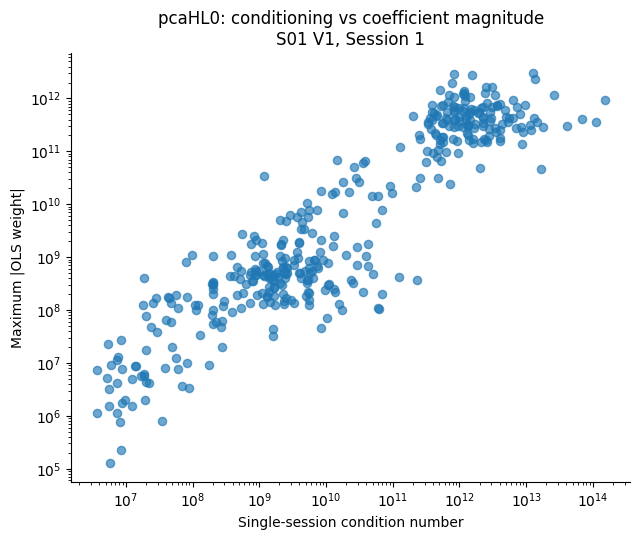

Saved: /content/drive/MyDrive/V2_drift/texturemodel/drift_results/conditioning_diagnostics/S01_V1_pcaHL0_session01_condition_vs_weight.png

DIRECT pcaHL0 vs pcaHL95 COMPARISON


,metric,pcaHL0,pcaHL95
0,Number of predictors,4.900000e+01,5.400000e+01
1,Median log10(condition),9.873383e+00,1.084945e+01
2,Median sigma_min,4.731540e-07,4.725030e-07
3,Rank-deficient pRFs,2.200000e+01,1.230000e+02
4,Median max |weight|,1.198630e+09,1.179511e+09
5,Maximum |weight|,3.078453e+12,2.975686e+12
6,"corr(log cond, log max|w|)",9.236059e-01,9.580190e-01


In [ ]:
# pcaHL0 vs pcaHL95 CONDITIONING CHECK.
# Purpose: determine whether the five extra high-level PCA dimensions in pcaHL95 are the main cause of the instability.

import os
import sys
import h5py
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# ============================================================
# PROJECT PATHS
# ============================================================

ROOT = Path("/content/drive/MyDrive/V2_drift")

TEXTURE_ROOT = ROOT / "texturemodel"
CODE_ROOT = TEXTURE_ROOT / "code"
MODEL_FITTING_ROOT = CODE_ROOT / "model_fitting"
UTILS_ROOT = CODE_ROOT / "utils"

for p in [
    TEXTURE_ROOT,
    CODE_ROOT,
    MODEL_FITTING_ROOT,
    UTILS_ROOT,
]:
    p = str(p)
    if p not in sys.path:
        sys.path.insert(0, p)

from utils import nsd_utils, roi_utils
import arg_parser as project_arg_parser
import initialize_fitting

# ============================================================
# CONFIG
# ============================================================

SUBJECT = 1
ROI = "V1"
SESSION_INDEX = 0       # Python index 0 = Session 1

PCA_TYPE = "pcaHL"
PCA_PCT = 0
EXPECTED_MAX_FEATURES = 49

SUBJECT_DIR = (
    ROOT
    / "texturemodel/model_fits"
    / f"S{SUBJECT:02d}"
)

MODEL_DIR = (
    SUBJECT_DIR
    / (
        f"texture_pyramid_OLS_4ori_4sf_"
        f"pcaHL_{ROI}_pca{PCA_PCT}_"
        f"use_nsd_grid5_pRFs"
    )
)

CROSS_FIT = (
    SUBJECT_DIR
    / "FAST_CROSS_SESSION"
    / (
        f"S{SUBJECT:02d}_{ROI}_"
        f"texture_pyramid_OLS_4ori_4sf_"
        f"pcaHL_{ROI}_pca{PCA_PCT}_"
        f"use_nsd_grid5_pRFs_30x30_cross_session.h5py"
    )
)

OUT_DIR = (
    ROOT
    / "texturemodel/drift_results/conditioning_diagnostics"
)

OUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

# ============================================================
# AUTOMATICALLY FIND CORRECT pcaHL0 FULL-DATA FIT
# ============================================================

full_candidates = sorted(
    MODEL_DIR.glob("*/all_fit_params.npy")
)

good_full_fits = []

for fn in full_candidates:

    D = np.load(
        fn,
        allow_pickle=True
    ).item()

    W = np.asarray(
        D["best_params"][1]
    )

    if W.shape[1] == EXPECTED_MAX_FEATURES:
        good_full_fits.append(fn)

if len(good_full_fits) == 0:
    raise FileNotFoundError(
        "Could not find a 49-feature pcaHL0 full-data fit."
    )

# If duplicates exist, their fits should be equivalent.
# Use the latest matching one.
FULL_FIT = good_full_fits[-1]

print("=" * 100)
print("FILES")
print("=" * 100)

print("Full-data fit:")
print(FULL_FIT)

print("\nCross-session fit:")
print(CROSS_FIT)

if not CROSS_FIT.exists():
    raise FileNotFoundError(
        f"\nCross-session pcaHL0 file does not exist:\n{CROSS_FIT}"
    )

# ============================================================
# BUILD EXACT pcaHL0 FAST ARGUMENTS
# ============================================================

def build_project_args():

    old_argv = sys.argv.copy()

    sys.argv = [
        "conditioning_pca0",

        "--subject", str(SUBJECT),
        "--roi_name", ROI,

        "--debug", "0",
        "--up_to_sess", "30",

        "--whole_session_split", "1",
        "--average_image_reps", "0",

        "--sample_batch_size", "1000",
        "--voxel_batch_size", "1000",

        "--zscore_features", "0",
        "--zscore_betas_within_sess", "0",

        "--use_precomputed_prfs", "1",
        "--prfs_model_name", "nsd_grid5",
        "--which_prf_grid", "5",

        "--fitting_type", "texture_pyramid",

        "--n_ori_pyr", "4",
        "--n_sf_pyr", "4",

        "--group_all_hl_feats", "1",

        "--pyr_pca_type", PCA_TYPE,
        "--pca_pct_var", str(PCA_PCT),

        "--set_lambda_per_group", "0",
        "--ridge", "0",

        "--do_val", "1",
        "--do_corrcoef", "1",

        "--do_tuning", "0",
        "--do_sem_disc", "0",
        "--do_pyr_varpart", "0",

        "--trial_subset", "all",
    ]

    try:
        args = project_arg_parser.get_args()
    finally:
        sys.argv = old_argv

    return args


args = build_project_args()

# ============================================================
# ROI MASK
# ============================================================

voxel_mask, _, voxel_roi, _, _ = (
    roi_utils.get_voxel_roi_info(
        SUBJECT,
        args.volume_space,
        use_kastner_areas=False,
    )
)

roi_codes = {
    "V1": [1, 2],
    "V2": [3, 4],
    "V3": [5, 6],
    "hV4": [7],
}

roi_keep = np.isin(
    voxel_roi[0],
    roi_codes[ROI],
)

voxel_mask = voxel_mask & roi_keep

# ============================================================
# LOAD SESSION DATA
# ============================================================

(
    voxel_data,
    session_image_order,
    val_inds,
    holdout_inds,
    session_inds,
) = nsd_utils.get_data_splits_single_train(
    SUBJECT,
    sessions=np.asarray(
        [SESSION_INDEX],
        dtype=int
    ),
    voxel_mask=voxel_mask,
    volume_space=args.volume_space,
    zscore_betas_within_sess=args.zscore_betas_within_sess,
    shuffle_images=args.shuffle_images_once,
    average_image_reps=args.average_image_reps,
    random_voxel_data=args.random_voxel_data,
)

session_image_order = np.asarray(
    session_image_order,
    dtype=int
).reshape(-1)

# ============================================================
# FULL-DATA IMAGE ORDER
# ============================================================

D_full = np.load(
    FULL_FIT,
    allow_pickle=True
).item()

full_image_order = np.asarray(
    D_full["image_order"],
    dtype=int
).reshape(-1)

full_weights = np.asarray(
    D_full["best_params"][1],
    dtype=np.float64
)[..., 0]

assert full_weights.shape[1] == 49

# ============================================================
# CROSS-SESSION pRFs + WEIGHTS
# ============================================================

with h5py.File(
    CROSS_FIT,
    "r"
) as f:

    fixed_prf = np.asarray(
        f["fixed_best_model_each_voxel"],
        dtype=int
    )

    session_weights = np.asarray(
        f["best_weights"][
            SESSION_INDEX,
            :,
            :,
            0
        ],
        dtype=np.float64
    )

print("\n" + "=" * 100)
print("BASIC CHECK")
print("=" * 100)

print("Session trials       :", len(session_image_order))
print("Full-data trials     :", len(full_image_order))
print("Full-data weight dim :", full_weights.shape)
print("Session weight dim   :", session_weights.shape)

assert session_weights.shape[1] == 49

# ============================================================
# MODEL / FEATURE LOADERS
# ============================================================

model_name, fitting_types = (
    initialize_fitting.get_full_save_name(
        args
    )
)

session_loader = (
    initialize_fitting.make_feature_loaders(
        args,
        fitting_types,
        vi=0,
        dnn_layers_use=None,
    )
)

full_loader = (
    initialize_fitting.make_feature_loaders(
        args,
        fitting_types,
        vi=0,
        dnn_layers_use=None,
    )
)

assert session_loader.max_features == 49
assert full_loader.max_features == 49

partial_masks, partial_version_names = (
    session_loader.get_partial_versions()
)

partial_masks = np.asarray(
    partial_masks
)

n_partial = len(
    partial_version_names
)

if (
    partial_masks.ndim == 2
    and partial_masks.shape[0] == n_partial
):

    partial_mask_full = np.asarray(
        partial_masks[0],
        dtype=bool
    )

elif (
    partial_masks.ndim == 2
    and partial_masks.shape[1] == n_partial
):

    partial_mask_full = np.asarray(
        partial_masks[:, 0],
        dtype=bool
    )

else:

    raise RuntimeError(
        f"Unexpected partial-mask shape: "
        f"{partial_masks.shape}"
    )

partial_mask_full = partial_mask_full[:49]

print("Model:", model_name)
print("Feature dimensions:", session_loader.max_features)

# ============================================================
# MATRIX DIAGNOSTICS
# ============================================================

def matrix_diagnostics(X):

    X = np.asarray(
        X,
        dtype=np.float64
    )

    row_ok = np.all(
        np.isfinite(X),
        axis=1
    )

    X = X[row_ok]

    Xc = (
        X
        - np.mean(
            X,
            axis=0,
            keepdims=True
        )
    )

    col_norm = np.linalg.norm(
        Xc,
        axis=0
    )

    good_cols = (
        np.isfinite(col_norm)
        &
        (col_norm > 0)
    )

    Xc = Xc[
        :,
        good_cols
    ]

    if Xc.shape[1] == 0:
        return {
            "n_samples": Xc.shape[0],
            "n_features": 0,
            "rank": 0,
            "sigma_max": np.nan,
            "sigma_min": np.nan,
            "cond": np.inf,
            "log10_cond": np.inf,
        }

    S = np.linalg.svd(
        Xc,
        compute_uv=False,
        full_matrices=False
    )

    tol = (
        max(Xc.shape)
        *
        np.finfo(np.float64).eps
        *
        S[0]
    )

    rank = int(
        np.sum(S > tol)
    )

    cond = (
        S[0] / S[-1]
        if S[-1] > 0
        else np.inf
    )

    return {
        "n_samples": Xc.shape[0],
        "n_features": Xc.shape[1],
        "rank": rank,
        "sigma_max": float(S[0]),
        "sigma_min": float(S[-1]),
        "cond": float(cond),
        "log10_cond": float(np.log10(cond)),
    }

# ============================================================
# CONDITIONING ACROSS OCCUPIED pRFs
# ============================================================

unique_prfs = np.unique(
    fixed_prf[
        fixed_prf >= 0
    ]
)

rows = []

print("\n" + "=" * 100)
print("pcaHL0 CONDITIONING ANALYSIS")
print("=" * 100)

print("Occupied pRFs:", len(unique_prfs))

for ii, prf in enumerate(
    unique_prfs,
    start=1
):

    vox = np.flatnonzero(
        fixed_prf == prf
    )

    print(
        f"{ii:4d}/{len(unique_prfs)} "
        f"| pRF={prf:4d} "
        f"| voxels={len(vox)}"
    )

    # --------------------------------------------------------
    # Session features
    # --------------------------------------------------------

    feat_s, defined_s = (
        session_loader.load(
            session_image_order,
            prf_model_index=int(prf)
        )
    )

    feat_s = np.asarray(
        feat_s,
        dtype=np.float64
    )

    defined_s = np.asarray(
        defined_s,
        dtype=bool
    )

    mask_s = partial_mask_full[
        defined_s
    ]

    Xs = feat_s[
        :,
        mask_s
    ]

    # --------------------------------------------------------
    # Full-data features
    # --------------------------------------------------------

    feat_f, defined_f = (
        full_loader.load(
            full_image_order,
            prf_model_index=int(prf)
        )
    )

    feat_f = np.asarray(
        feat_f,
        dtype=np.float64
    )

    defined_f = np.asarray(
        defined_f,
        dtype=bool
    )

    mask_f = partial_mask_full[
        defined_f
    ]

    Xf = feat_f[
        :,
        mask_f
    ]

    assert np.array_equal(
        defined_s,
        defined_f
    )

    assert np.array_equal(
        mask_s,
        mask_f
    )

    assert Xs.shape[1] == Xf.shape[1]

    ds = matrix_diagnostics(Xs)
    dfull = matrix_diagnostics(Xf)

    # --------------------------------------------------------
    # Matching stored weights
    # --------------------------------------------------------

    W = session_weights[
        vox,
        :
    ]

    W = W[
        :,
        defined_s
    ]

    W = W[
        :,
        mask_s
    ]

    assert W.shape[1] == Xs.shape[1]

    w_abs = np.abs(
        W[
            np.isfinite(W)
        ]
    )

    rows.append({
        "prf": int(prf),
        "n_voxels": len(vox),

        "session_n_features":
            ds["n_features"],

        "session_rank":
            ds["rank"],

        "session_sigma_min":
            ds["sigma_min"],

        "session_cond":
            ds["cond"],

        "session_log10_cond":
            ds["log10_cond"],

        "full_n_features":
            dfull["n_features"],

        "full_rank":
            dfull["rank"],

        "full_sigma_min":
            dfull["sigma_min"],

        "full_cond":
            dfull["cond"],

        "full_log10_cond":
            dfull["log10_cond"],

        "median_abs_weight":
            np.median(w_abs),

        "p99_abs_weight":
            np.percentile(
                w_abs,
                99
            ),

        "max_abs_weight":
            np.max(w_abs),
    })


session_loader.clear_big_features()
full_loader.clear_big_features()

res0 = pd.DataFrame(rows)

# ============================================================
# SAVE pca0 RESULTS
# ============================================================

csv_fn = (
    OUT_DIR
    / "S01_V1_pcaHL0_session01_conditioning.csv"
)

res0.to_csv(
    csv_fn,
    index=False
)

print("\nSaved:", csv_fn)

# ============================================================
# pca0 SUMMARY
# ============================================================

print("\n" + "=" * 100)
print("pcaHL0 SUMMARY")
print("=" * 100)

print("\nSESSION DESIGN MATRICES")

print(
    "Median log10(condition number):",
    np.nanmedian(
        res0["session_log10_cond"]
    )
)

print(
    "Median smallest singular value:",
    np.nanmedian(
        res0["session_sigma_min"]
    )
)

print(
    "Rank-deficient pRFs:",
    np.sum(
        res0["session_rank"]
        <
        res0["session_n_features"]
    ),
    "/",
    len(res0)
)

print("\nFULL-DATA DESIGN MATRICES")

print(
    "Median log10(condition number):",
    np.nanmedian(
        res0["full_log10_cond"]
    )
)

print(
    "Median smallest singular value:",
    np.nanmedian(
        res0["full_sigma_min"]
    )
)

print(
    "Rank-deficient pRFs:",
    np.sum(
        res0["full_rank"]
        <
        res0["full_n_features"]
    ),
    "/",
    len(res0)
)

# ============================================================
# CONDITION NUMBER ↔ WEIGHT MAGNITUDE
# ============================================================

valid = (
    np.isfinite(res0["session_cond"])
    &
    np.isfinite(res0["max_abs_weight"])
    &
    (res0["session_cond"] > 0)
    &
    (res0["max_abs_weight"] > 0)
)

r0 = np.corrcoef(
    np.log10(
        res0.loc[
            valid,
            "session_cond"
        ]
    ),
    np.log10(
        res0.loc[
            valid,
            "max_abs_weight"
        ]
    ),
)[0, 1]

print("\n" + "=" * 100)
print("pcaHL0 CONDITION NUMBER ↔ WEIGHT MAGNITUDE")
print("=" * 100)

print(
    "Pearson r:",
    r0
)

# ============================================================
# FIGURE 1 — CONDITION NUMBER VS WEIGHT
# ============================================================

fig, ax = plt.subplots(
    figsize=(6.5, 5.5)
)

ax.scatter(
    res0.loc[
        valid,
        "session_cond"
    ],
    res0.loc[
        valid,
        "max_abs_weight"
    ],
    s=35,
    alpha=0.65
)

ax.set_xscale("log")
ax.set_yscale("log")

ax.set_xlabel(
    "Single-session condition number"
)

ax.set_ylabel(
    "Maximum |OLS weight|"
)

ax.set_title(
    "pcaHL0: conditioning vs coefficient magnitude\n"
    "S01 V1, Session 1"
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

fig.tight_layout()

fn = (
    OUT_DIR
    / "S01_V1_pcaHL0_session01_condition_vs_weight.png"
)

fig.savefig(
    fn,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved:", fn)

# ============================================================
# DIRECT pca0 VS pca95 COMPARISON
#
# Load your previously saved pcaHL95 conditioning table.
# ============================================================

PCA95_CSV = (
    OUT_DIR
    / "S01_V1_pcaHL95_session01_conditioning.csv"
)

if PCA95_CSV.exists():

    res95 = pd.read_csv(
        PCA95_CSV
    )

    comparison = pd.DataFrame({
        "metric": [
            "Number of predictors",
            "Median log10(condition)",
            "Median sigma_min",
            "Rank-deficient pRFs",
            "Median max |weight|",
            "Maximum |weight|",
            "corr(log cond, log max|w|)",
        ],

        "pcaHL0": [
            49,

            np.nanmedian(
                res0["session_log10_cond"]
            ),

            np.nanmedian(
                res0["session_sigma_min"]
            ),

            int(
                np.sum(
                    res0["session_rank"]
                    <
                    res0["session_n_features"]
                )
            ),

            np.nanmedian(
                res0["max_abs_weight"]
            ),

            np.nanmax(
                res0["max_abs_weight"]
            ),

            r0,
        ],

        "pcaHL95": [
            54,

            np.nanmedian(
                res95["session_log10_cond"]
            ),

            np.nanmedian(
                res95["session_sigma_min"]
            ),

            int(
                np.sum(
                    res95["session_rank"]
                    <
                    res95["session_n_features"]
                )
            ),

            np.nanmedian(
                res95["max_abs_weight"]
            ),

            np.nanmax(
                res95["max_abs_weight"]
            ),

            np.corrcoef(
                np.log10(
                    res95.loc[
                        np.isfinite(res95["session_cond"])
                        &
                        np.isfinite(res95["max_abs_weight"])
                        &
                        (res95["session_cond"] > 0)
                        &
                        (res95["max_abs_weight"] > 0),
                        "session_cond"
                    ]
                ),
                np.log10(
                    res95.loc[
                        np.isfinite(res95["session_cond"])
                        &
                        np.isfinite(res95["max_abs_weight"])
                        &
                        (res95["session_cond"] > 0)
                        &
                        (res95["max_abs_weight"] > 0),
                        "max_abs_weight"
                    ]
                ),
            )[0, 1],
        ],
    })

    print("\n" + "=" * 100)
    print("DIRECT pcaHL0 vs pcaHL95 COMPARISON")
    print("=" * 100)

    display(comparison)

else:

    print(
        "\nCould not find previous pcaHL95 conditioning CSV:"
    )
    print(PCA95_CSV)


### Finding: pcaHL95 worsens conditioning, but does not create the underlying instability

The pcaHL0 and pcaHL95 session-specific fits were compared directly.

| Metric | pcaHL0 | pcaHL95 |
|---|---:|---:|
| Predictors | 49 | 54 |
| Median log10(condition) | ~9.87 | ~10.85 |
| Rank-deficient pRFs | 22/390 | 123/390 |
| Median max \(|w|\) | ~\(1.20\times10^9\) | ~\(1.18\times10^9\) |
| Maximum \(|w|\) | ~\(3.08\times10^{12}\) | ~\(2.98\times10^{12}\) |
| corr(log condition, log max \(|w|\)) | .924 | .958 |

The five extra pcaHL95 dimensions clearly worsen formal conditioning and rank deficiency, but the extreme OLS coefficient scale is already present in pcaHL0. Therefore, the instability is not explained simply by retaining the additional PCA components.


## 7. Ridge-regression diagnostic

Henderson's texture-model implementation uses regularized regression, so ridge was examined as a possible stabilization mechanism.

An initial automatic lambda-selection check used the available candidate grid but selected **\(\lambda=0\) for all 1,350 S01 V1 voxels**. Consequently, the reported “ridge” and OLS solutions were exactly identical in coefficient magnitudes, R², and Pearson correlation.

This result does **not** show that non-zero ridge cannot stabilize the coefficients. It only shows that the current validation/selection criterion prefers the unregularized solution. The code below therefore explores forced non-zero penalties as a diagnostic of the numerical-stability versus predictive-performance tradeoff; it is not a replacement for the primary OLS analysis.


In [ ]:
# RIDGE DIAGNOSTIC.
# Purpose: evaluate whether non-zero regularization can stabilize the session-specific TS fit without materially changing predictive performance. The earlier automatic ridge-selection check selected lambda=0 for every voxel, so that result was mathematically identical to OLS.

import os
import sys
import gc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# ============================================================
# PROJECT PATHS
# ============================================================

ROOT = Path("/content/drive/MyDrive/V2_drift")

TEXTURE_ROOT = ROOT / "texturemodel"
CODE_ROOT = TEXTURE_ROOT / "code"
MODEL_FITTING_ROOT = CODE_ROOT / "model_fitting"
UTILS_ROOT = CODE_ROOT / "utils"

for p in [
    TEXTURE_ROOT,
    CODE_ROOT,
    MODEL_FITTING_ROOT,
    UTILS_ROOT,
]:
    p = str(p)
    if p not in sys.path:
        sys.path.insert(0, p)

from utils import roi_utils
import arg_parser as project_arg_parser
import initialize_fitting
import fwrf_model
import fit_cross_session_matrix_fast as fast


# ============================================================
# CONFIG
# ============================================================

SUBJECT = 1
ROI = "V1"

# Python index 0 = NSD Session 1
TRAIN_SESSION = 0

PCA_TYPE = "pcaHL"
PCA_PCT = 95

# ------------------------------------------------------------
# FORCE THESE LAMBDAS.
#
# These are values from the grid you just obtained:
#
# [0,
#  0.01154674,
#  0.0364262,
#  0.09003332,
#  0.2055392,
#  0.4544167,
#  0.9906665,
#  2.1461103,
#  4.635714,
# 10]
#
# Start with a compact subset spanning the range.
# ------------------------------------------------------------

FORCED_LAMBDAS = np.array(
    [
        0.0,
        0.09003332,
        0.4544167,
        2.1461103,
        10.0,
    ],
    dtype=np.float32
)

OUT_DIR = (
    ROOT
    / "texturemodel/drift_results/ridge_diagnostics/"
      "forced_lambda"
)

OUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)


# ============================================================
# BUILD BASE MODEL CONFIG
#
# ridge=1 so the model uses the ridge-fitting path.
# We will OVERRIDE the candidate lambda array below with
# exactly one value at a time.
# ============================================================

def build_args():

    old_argv = sys.argv.copy()

    sys.argv = [
        "forced_lambda_test",

        "--subject", str(SUBJECT),
        "--roi_name", ROI,

        "--debug", "0",
        "--up_to_sess", "30",

        "--whole_session_split", "1",
        "--average_image_reps", "0",

        "--sample_batch_size", "1000",
        "--voxel_batch_size", "1000",

        "--zscore_features", "0",
        "--zscore_betas_within_sess", "0",

        "--use_precomputed_prfs", "1",
        "--prfs_model_name", "nsd_grid5",
        "--which_prf_grid", "5",

        "--fitting_type", "texture_pyramid",

        "--n_ori_pyr", "4",
        "--n_sf_pyr", "4",

        "--group_all_hl_feats", "1",

        "--pyr_pca_type", PCA_TYPE,
        "--pca_pct_var", str(PCA_PCT),

        # One lambda for all feature groups
        "--set_lambda_per_group", "0",

        # Ridge-fitting path
        "--ridge", "1",

        "--do_val", "1",
        "--do_corrcoef", "1",

        "--do_tuning", "0",
        "--do_sem_disc", "0",
        "--do_pyr_varpart", "0",

        "--trial_subset", "all",
    ]

    try:
        args = project_arg_parser.get_args()

    finally:
        sys.argv = old_argv

    return args


args = build_args()


# ============================================================
# LOAD ROI + ALL 30 SESSIONS ONCE
# ============================================================

print("=" * 100)
print("LOADING DATA ONCE")
print("=" * 100)

(
    voxel_mask,
    voxel_index,
    voxel_roi,
    voxel_ncsnr,
    brain_nii_shape,
) = fast.load_roi_metadata(
    args
)

nvox = voxel_index.shape[1]

sessions = fast.load_all_sessions(
    args,
    voxel_mask
)

train_data = sessions[
    TRAIN_SESSION
]

print("ROI voxels       :", nvox)
print("Train session    :", TRAIN_SESSION + 1)
print(
    "Training trials  :",
    len(train_data.image_order_train)
)
print(
    "Held-out trials  :",
    len(train_data.image_order_holdout)
)


# ============================================================
# FIXED pRF ASSIGNMENTS
#
# Same pRF assignments used in FAST_CROSS_SESSION.
# ============================================================

best_prf, saved_prfs_fn = (
    initialize_fitting.load_precomputed_prfs(
        SUBJECT,
        args,
    )
)

best_prf = np.asarray(
    best_prf,
    dtype=int
).ravel()

if len(best_prf) != nvox:

    best_prf = (
        fast.subset_kastner_prfs_to_visualroi(
            args=args,
            best_model_each_voxel=best_prf,
            visualroi_voxel_index=voxel_index,
        )
    )

assert len(best_prf) == nvox

print(
    "Occupied fixed pRFs:",
    len(np.unique(best_prf))
)


# ============================================================
# MODEL NAME / FITTING TYPE
# ============================================================

model_name, fitting_types = (
    initialize_fitting.get_full_save_name(
        args
    )
)

print("\nModel:")
print(model_name)


# ============================================================
# HELPER
# ============================================================

def summarize_weights(W):

    vals = np.abs(
        np.asarray(
            W,
            dtype=np.float64
        )
    )

    vals = vals[
        np.isfinite(vals)
    ]

    return {
        "median_abs_weight":
            np.median(vals),

        "p95_abs_weight":
            np.percentile(vals, 95),

        "p99_abs_weight":
            np.percentile(vals, 99),

        "p99_9_abs_weight":
            np.percentile(vals, 99.9),

        "max_abs_weight":
            np.max(vals),

        "n_gt_1e3":
            int(
                np.sum(vals > 1e3)
            ),

        "n_gt_1e6":
            int(
                np.sum(vals > 1e6)
            ),

        "n_gt_1e9":
            int(
                np.sum(vals > 1e9)
            ),
    }


# ============================================================
# FIT ONE FORCED LAMBDA
# ============================================================

def fit_forced_lambda(lam):

    print("\n" + "#" * 100)
    print(
        f"FORCED LAMBDA = {lam:.8g}"
    )
    print("#" * 100)

    # --------------------------------------------------------
    # Fresh loader for this fit
    # --------------------------------------------------------

    feature_loader = (
        initialize_fitting.make_feature_loaders(
            args,
            fitting_types,
            vi=0,
            dnn_layers_use=None,
        )
    )

    # --------------------------------------------------------
    # CRITICAL:
    # Give the model exactly ONE candidate lambda.
    #
    # It therefore cannot choose lambda=0 unless the forced
    # lambda itself is zero.
    # --------------------------------------------------------

    forced_lambda_array = np.array(
        [lam],
        dtype=np.float32
    )

    print(
        "Lambda array passed to model:",
        forced_lambda_array
    )

    model = fwrf_model.encoding_model(
        feature_loader,

        lambdas=forced_lambda_array,

        best_model_each_voxel=best_prf,

        zscore=args.zscore_features,

        add_bias=True,

        set_lambda_per_group=False,

        voxel_batch_size=args.voxel_batch_size,
        sample_batch_size=args.sample_batch_size,

        device="cpu:0",

        prfs_fit_mask=None,

        shuffle_data=False,
        bootstrap_data=False,

        do_corrcoef=args.do_corrcoef,

        dtype=np.float32,

        debug=args.debug,
    )

    # --------------------------------------------------------
    # FIT SESSION 1 ONLY
    # --------------------------------------------------------

    model.fit(
        train_data.image_order_train,
        train_data.voxel_data_train,

        train_data.image_order_holdout,
        train_data.voxel_data_holdout,

        trials_use_each_prf_trn=None,
        trials_use_each_prf_holdout=None,
    )

    # --------------------------------------------------------
    # Extract parameters
    # --------------------------------------------------------

    W = np.asarray(
        model.best_weights,
        dtype=np.float64
    )

    B = np.asarray(
        model.best_biases,
        dtype=np.float64
    )

    best_lambdas = np.asarray(
        model.best_lambdas
    )

    print(
        "\nUnique stored best_lambdas:",
        np.unique(best_lambdas)
    )

    # --------------------------------------------------------
    # VALIDATE ON ALL 30 SESSIONS
    #
    # Still MUCH cheaper than the 30×30 analysis:
    # only one trained model per forced lambda.
    # --------------------------------------------------------

    print(
        "\nValidating this model "
        "on all 30 sessions..."
    )

    val_r2, val_cc = (
        fast.validate_model_on_all_sessions(
            model,
            sessions,
            args,
        )
    )

    val_r2 = np.asarray(
        val_r2
    )

    val_cc = np.asarray(
        val_cc
    )

    # full_model partial version = 0
    r2 = val_r2[
        :,
        :,
        0
    ]

    cc = val_cc[
        :,
        :,
        0
    ]

    # --------------------------------------------------------
    # Session-level medians across voxels
    # --------------------------------------------------------

    r2_by_session = np.nanmedian(
        r2,
        axis=1
    )

    cc_by_session = np.nanmedian(
        cc,
        axis=1
    )

    # Same-session
    same_r2 = (
        r2_by_session[
            TRAIN_SESSION
        ]
    )

    same_cc = (
        cc_by_session[
            TRAIN_SESSION
        ]
    )

    # All other sessions
    offdiag_r2 = np.delete(
        r2_by_session,
        TRAIN_SESSION
    )

    offdiag_cc = np.delete(
        cc_by_session,
        TRAIN_SESSION
    )

    ws = summarize_weights(
        W
    )

    result = {
        "lambda":
            float(lam),

        **ws,

        "same_session_median_r2":
            float(same_r2),

        "same_session_median_pearson":
            float(same_cc),

        "median_cross_session_r2":
            float(
                np.nanmedian(
                    offdiag_r2
                )
            ),

        "median_cross_session_pearson":
            float(
                np.nanmedian(
                    offdiag_cc
                )
            ),

        "mean_cross_session_r2":
            float(
                np.nanmean(
                    offdiag_r2
                )
            ),

        "mean_cross_session_pearson":
            float(
                np.nanmean(
                    offdiag_cc
                )
            ),
    }

    # --------------------------------------------------------
    # Save session curves for later plotting
    # --------------------------------------------------------

    curves = {
        "lambda":
            float(lam),

        "r2_by_session":
            r2_by_session,

        "cc_by_session":
            cc_by_session,

        "weights":
            W,

        "biases":
            B,
    }

    feature_loader.clear_big_features()

    del model
    del feature_loader

    gc.collect()

    return result, curves


# ============================================================
# RUN
# ============================================================

results = []
all_curves = {}

for lam in FORCED_LAMBDAS:

    result, curves = (
        fit_forced_lambda(
            float(lam)
        )
    )

    results.append(
        result
    )

    all_curves[
        float(lam)
    ] = curves


# ============================================================
# RESULTS TABLE
# ============================================================

df = pd.DataFrame(
    results
)

print("\n" + "=" * 100)
print("FORCED-LAMBDA STABILITY / PREDICTION TRADEOFF")
print("=" * 100)

display(
    df[
        [
            "lambda",

            "median_abs_weight",
            "p99_abs_weight",
            "p99_9_abs_weight",
            "max_abs_weight",

            "n_gt_1e3",
            "n_gt_1e6",
            "n_gt_1e9",

            "same_session_median_r2",
            "median_cross_session_r2",

            "same_session_median_pearson",
            "median_cross_session_pearson",
        ]
    ]
)


# ============================================================
# RATIOS RELATIVE TO OLS
# ============================================================

ols_row = df.loc[
    np.isclose(
        df["lambda"],
        0
    )
].iloc[0]

df[
    "max_weight_ratio_vs_OLS"
] = (
    df["max_abs_weight"]
    /
    ols_row["max_abs_weight"]
)

df[
    "p99_9_weight_ratio_vs_OLS"
] = (
    df["p99_9_abs_weight"]
    /
    ols_row["p99_9_abs_weight"]
)

df[
    "delta_same_R2_vs_OLS"
] = (
    df["same_session_median_r2"]
    -
    ols_row[
        "same_session_median_r2"
    ]
)

df[
    "delta_cross_R2_vs_OLS"
] = (
    df["median_cross_session_r2"]
    -
    ols_row[
        "median_cross_session_r2"
    ]
)


print("\n" + "=" * 100)
print("CHANGE RELATIVE TO OLS")
print("=" * 100)

display(
    df[
        [
            "lambda",

            "max_weight_ratio_vs_OLS",
            "p99_9_weight_ratio_vs_OLS",

            "delta_same_R2_vs_OLS",
            "delta_cross_R2_vs_OLS",
        ]
    ]
)


# ============================================================
# FIGURE 1
# LAMBDA VS MAX WEIGHT
# ============================================================

fig, ax = plt.subplots(
    figsize=(7, 5.5)
)

# Use small plotting value for lambda=0
x_plot = df["lambda"].copy()

positive_lams = x_plot[
    x_plot > 0
]

zero_plot_value = (
    positive_lams.min()
    / 5
)

x_plot.loc[
    x_plot == 0
] = zero_plot_value

ax.plot(
    x_plot,
    df["max_abs_weight"],
    marker="o",
    linewidth=1.8
)

ax.set_xscale(
    "log"
)

ax.set_yscale(
    "log"
)

ax.set_xlabel(
    "Forced ridge λ\n"
    "(leftmost point = OLS, λ=0)"
)

ax.set_ylabel(
    "Maximum |weight|"
)

ax.set_title(
    "Numerical stabilization with forced ridge\n"
    "S01 V1, pcaHL95, Train Session 1"
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

fig.tight_layout()

fn = (
    OUT_DIR
    / "S01_V1_pcaHL95_session01_forcedLambda_maxWeight.png"
)

fig.savefig(
    fn,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved:", fn)


# ============================================================
# FIGURE 2
# LAMBDA VS SAME-SESSION / CROSS-SESSION R2
# ============================================================

fig, ax = plt.subplots(
    figsize=(7, 5.5)
)

ax.plot(
    x_plot,
    df["same_session_median_r2"],
    marker="o",
    linewidth=1.8,
    label="Same session"
)

ax.plot(
    x_plot,
    df["median_cross_session_r2"],
    marker="o",
    linewidth=1.8,
    label="Other 29 sessions"
)

ax.set_xscale(
    "log"
)

ax.set_xlabel(
    "Forced ridge λ\n"
    "(leftmost point = OLS, λ=0)"
)

ax.set_ylabel(
    "Median voxel R²"
)

ax.set_title(
    "Prediction performance under forced regularization\n"
    "S01 V1, pcaHL95, Train Session 1"
)

ax.legend(
    frameon=False
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

fig.tight_layout()

fn = (
    OUT_DIR
    / "S01_V1_pcaHL95_session01_forcedLambda_R2.png"
)

fig.savefig(
    fn,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved:", fn)


# ============================================================
# FIGURE 3
# STABILITY-PREDICTION TRADEOFF
#
# x = max coefficient magnitude
# y = cross-session R2
# each point = forced lambda
# ============================================================

fig, ax = plt.subplots(
    figsize=(7, 5.8)
)

ax.plot(
    df["max_abs_weight"],
    df["median_cross_session_r2"],
    marker="o",
    linewidth=1.5
)

for _, row in df.iterrows():

    label = (
        "OLS"
        if np.isclose(
            row["lambda"],
            0
        )
        else f"λ={row['lambda']:.3g}"
    )

    ax.annotate(
        label,
        (
            row["max_abs_weight"],
            row["median_cross_session_r2"]
        ),
        xytext=(5, 5),
        textcoords="offset points",
        fontsize=9
    )

ax.set_xscale(
    "log"
)

ax.set_xlabel(
    "Maximum |weight|"
)

ax.set_ylabel(
    "Median cross-session R²"
)

ax.set_title(
    "Numerical stability vs predictive performance\n"
    "S01 V1, pcaHL95"
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

fig.tight_layout()

fn = (
    OUT_DIR
    / "S01_V1_pcaHL95_session01_stability_vs_prediction.png"
)

fig.savefig(
    fn,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved:", fn)


# ============================================================
# SAVE TABLE
# ============================================================

csv_fn = (
    OUT_DIR
    / "S01_V1_pcaHL95_session01_forcedLambda_tradeoff.csv"
)

df.to_csv(
    csv_fn,
    index=False
)

print("\nSaved:")
print(csv_fn)


LOADING DATA ONCE
Using subject S01, ROI V1
Number of voxels: 1350

Loading session 1/30 for S01 V1
Loading data for sessions:
[1]
Data is located in: /content/drive/MyDrive/V1_Drift/NSD/subj01/betas...
Loading from /content/drive/MyDrive/V1_Drift/NSD/subj01/betas/betas_session01.nii.gz...
Raw data:
float64 -32768.0 32767.0 (750, 81, 104, 83)
Done!

Size of full data set [n_trials x n_voxels] is:
(750, 1350)
All session trials:        750
Regression training trials: 750
Regression holdout trials:  750 (same trials; loss is not used for model selection)
Returned session labels: [0]

Loading session 2/30 for S01 V1
Loading data for sessions:
[2]
Data is located in: /content/drive/MyDrive/V1_Drift/NSD/subj01/betas...
Loading from /content/drive/MyDrive/V1_Drift/NSD/subj01/betas/betas_session02.nii.gz...
Raw data:
float64 -32768.0 32767.0 (750, 81, 104, 83)
Done!

Size of full data set [n_trials x n_voxels] is:
(750, 1350)
All session trials:        750
Regression training trials: 750
Regr

IndexError: too many indices for array: array is 0-dimensional, but 1 were indexed

## 8. Voxel-matched SP versus TS conditioning

A matched comparison was performed to determine whether poor conditioning is simply a generic consequence of fitting one NSD session with OLS.

For **S01 V1, Session 1**, SP, TS pcaHL0, and TS pcaHL95 were compared on the same voxel population and the same session images. Each model retained its own established voxel-specific pRF-sampled feature representation.

### Raw-scale results

| Metric | SP | TS pcaHL0 | TS pcaHL95 |
|---|---:|---:|---:|
| Median # predictors | 26 | 49 | 52 |
| Median rank | 26 | 49 | 51 |
| Median \(\sigma_{\min}\) | \(4.60\times10^3\) | \(9.97\times10^{-7}\) | \(9.95\times10^{-7}\) |
| Median log10(condition) | 5.80 | 9.74 | 10.64 |
| Rank-deficient fraction | 0% | 4.1% | 27.6% |

For TS pcaHL95, the median within-voxel difference relative to SP was approximately **+4.90 log10 condition-number units**, and TS was more poorly conditioned in approximately **99.8%** of matched voxels.

This rules out the explanation that the instability is merely an unavoidable property of one-session OLS: the effect is substantially stronger for the TS representation.


FILES
SP regression : /content/drive/MyDrive/V1_Drift/repDrift_expand_6levels/regressSessCombineROI_sub1.pkl
SP pRF sample : /content/drive/MyDrive/V1_Drift/prfsample_expand_6levels/prfSampleStim_v1_sub1.h5
TS pca0       : /content/drive/MyDrive/V2_drift/texturemodel/model_fits/S01/FAST_CROSS_SESSION/S01_V1_texture_pyramid_OLS_4ori_4sf_pcaHL_V1_pca0_use_nsd_grid5_pRFs_30x30_cross_session.h5py
TS pca95      : /content/drive/MyDrive/V2_drift/texturemodel/model_fits/S01/FAST_CROSS_SESSION/S01_V1_texture_pyramid_OLS_4ori_4sf_pcaHL_V1_pca95_use_nsd_grid5_pRFs_30x30_cross_session.h5py
Loading data for sessions:
[1]
Data is located in: /content/drive/MyDrive/V1_Drift/NSD/subj01/betas...
Loading from /content/drive/MyDrive/V1_Drift/NSD/subj01/betas/betas_session01.nii.gz...
Raw data:
float64 -32768.0 32767.0 (750, 81, 104, 83)
Done!

Size of full data set [n_trials x n_voxels] is:
(750, 1350)

MATCHED SESSION
Trials: 750
First 10 image indices:
[ 625 5012 4849 8822 9537 6060 4420 3857 8123 484

,metric,SP,TS_pca0,TS_pca95
0,Median # predictors,2.600000e+01,4.900000e+01,5.200000e+01
1,Median rank,2.600000e+01,4.900000e+01,5.100000e+01
2,Median sigma_min,4.601817e+03,9.970834e-07,9.954796e-07
3,Median log10(condition),5.797132e+00,9.742715e+00,1.064066e+01
4,Rank-deficient fraction,0.000000e+00,4.148148e-02,2.755556e-01
5,Median max |weight|,2.912895e-04,4.811396e+08,4.689343e+08
6,Maximum |weight|,2.496865e+11,3.078453e+12,2.975686e+12



WITHIN-VOXEL CONDITIONING DIFFERENCE
Median TS pca0 - SP log10(cond): 4.077233386186858
Median TS pca95 - SP log10(cond): 4.900959384973586

Fraction voxels TS pca0 worse conditioned than SP: 0.9977777777777778
Fraction voxels TS pca95 worse conditioned than SP: 0.9977777777777778


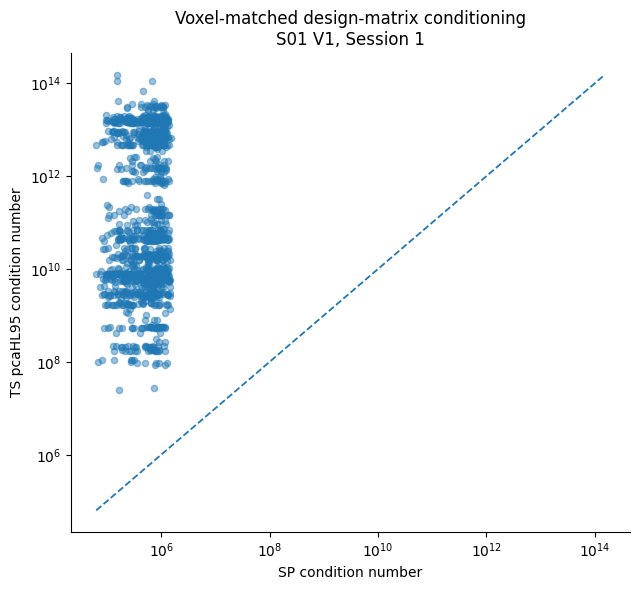

Saved: /content/drive/MyDrive/V2_drift/texturemodel/drift_results/conditioning_diagnostics/voxel_matched_SP_TS/S01_V1_session01_voxelmatched_SP_vs_TS95_condition.png

FINITE / INFINITE DELTA CHECK
TS pca0 - SP: 1347/1350 finite
  +inf: 0
  -inf: 3
TS pca95 - SP: 1347/1350 finite
  +inf: 0
  -inf: 3


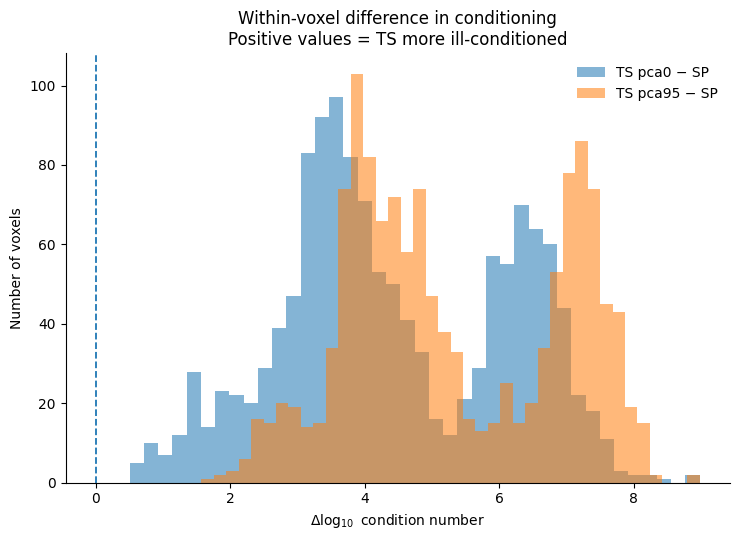

Saved: /content/drive/MyDrive/V2_drift/texturemodel/drift_results/conditioning_diagnostics/voxel_matched_SP_TS/S01_V1_session01_voxelmatched_delta_conditioning.png


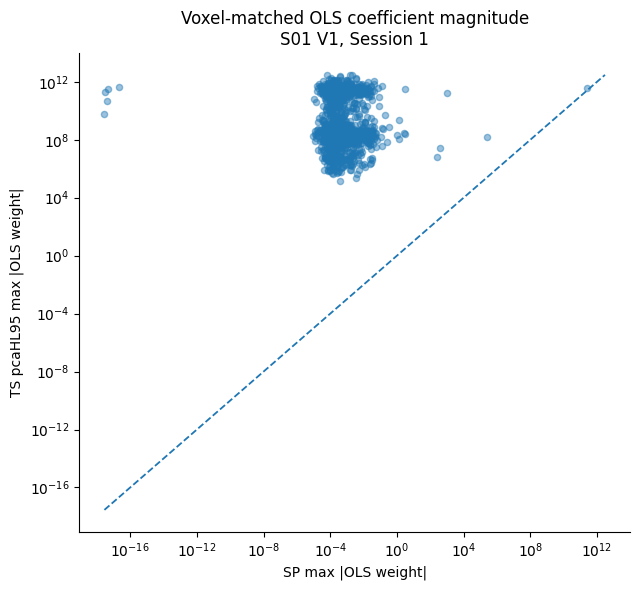

Saved: /content/drive/MyDrive/V2_drift/texturemodel/drift_results/conditioning_diagnostics/voxel_matched_SP_TS/S01_V1_session01_voxelmatched_SP_vs_TS95_weights.png

TOP 20 VOXELS: TS95 CONDITIONING MINUS SP


,voxel_position,nsd_voxel_index,sp_n_features,sp_rank,sp_sigma_min,sp_cond,sp_max_abs_weight,ts95_prf,ts95_n_features,ts95_rank,ts95_sigma_min,ts95_cond,ts95_max_abs_weight,delta_logcond_ts95_minus_sp
402,402,337017,26,26,3.987479e+01,155745.066936,1.792475e-02,216,51,47,1.941702e-09,1.507674e+14,9.530809e+11,8.985893
561,561,363163,26,26,3.225179e+02,155936.086708,1.084028e-02,232,51,48,1.778363e-09,1.131903e+14,3.529949e+11,8.860862
930,930,423590,26,26,3.245942e+01,160970.273532,1.392073e-02,201,51,47,2.084342e-09,4.052243e+13,2.891862e+11,8.400950
1271,1271,467167,26,26,1.754896e+01,95932.389347,8.743972e-02,484,52,51,1.788679e-09,2.049389e+13,2.012088e+10,8.329659
505,505,354448,26,26,5.224954e+03,679177.227483,1.660779e-04,232,51,48,1.778363e-09,1.131903e+14,3.503343e+11,8.221826
566,566,363168,26,26,7.287961e+01,95738.690806,4.204890e-02,357,52,48,1.419621e-09,1.593909e+13,2.233110e+11,8.221376
1230,1230,466668,26,26,9.643613e+01,102350.446877,8.463470e-03,335,52,48,1.499092e-09,1.635098e+13,6.896120e+11,8.203454
698,698,381174,26,26,4.345880e+03,460891.892531,1.191133e-04,250,51,47,2.014028e-09,6.853849e+13,4.144549e+11,8.172335
175,175,302820,26,26,3.079525e+01,105630.530368,2.466103e-02,313,52,48,1.555167e-09,1.561777e+13,2.195678e+11,8.169829
186,186,302906,26,26,4.292405e-23,96339.347004,2.236754e-17,344,52,49,1.665141e-09,1.385668e+13,4.509253e+11,8.157855


In [ ]:
# VOXEL-MATCHED SP vs TS CHECK.
# Purpose: compare conditioning for the same S01 V1 voxel population and Session-1 images, asking whether the instability is generic to one-session OLS or substantially stronger for TS.

import os
import sys
import gc
import pickle
import h5py
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# ============================================================
# CONFIG
# ============================================================

SUBJECT = 1
ROI = "V1"
VREG = 1

# Python 0 = actual Session 1
SESSION_INDEX = 0

# ------------------------------------------------------------
# SP paths
# ------------------------------------------------------------

SP_BASE = Path(
    "/content/drive/MyDrive/V1_Drift/repDrift_expand_6levels"
)

SP_PRF_FOLDER = Path(
    "/content/drive/MyDrive/V1_Drift/prfsample_expand_6levels"
)

SP_REGRESSION_FILE = (
    SP_BASE
    / f"regressSessCombineROI_sub{SUBJECT}.pkl"
)

SP_PRF_FILE = (
    SP_PRF_FOLDER
    / f"prfSampleStim_v{VREG}_sub{SUBJECT}.h5"
)

# ------------------------------------------------------------
# TS paths
# ------------------------------------------------------------

ROOT = Path("/content/drive/MyDrive/V2_drift")

TEXTURE_ROOT = ROOT / "texturemodel"
CODE_ROOT = TEXTURE_ROOT / "code"
MODEL_FITTING_ROOT = CODE_ROOT / "model_fitting"
UTILS_ROOT = CODE_ROOT / "utils"

for p in [
    TEXTURE_ROOT,
    CODE_ROOT,
    MODEL_FITTING_ROOT,
    UTILS_ROOT,
]:
    p = str(p)
    if p not in sys.path:
        sys.path.insert(0, p)

from utils import nsd_utils, roi_utils
import arg_parser as project_arg_parser
import initialize_fitting

TS_CROSS_0 = (
    ROOT
    / "texturemodel/model_fits/S01/FAST_CROSS_SESSION"
    / (
        "S01_V1_texture_pyramid_OLS_4ori_4sf_"
        "pcaHL_V1_pca0_use_nsd_grid5_pRFs_"
        "30x30_cross_session.h5py"
    )
)

TS_CROSS_95 = (
    ROOT
    / "texturemodel/model_fits/S01/FAST_CROSS_SESSION"
    / (
        "S01_V1_texture_pyramid_OLS_4ori_4sf_"
        "pcaHL_V1_pca95_use_nsd_grid5_pRFs_"
        "30x30_cross_session.h5py"
    )
)

OUT_DIR = (
    ROOT
    / "texturemodel/drift_results/"
      "conditioning_diagnostics/voxel_matched_SP_TS"
)

OUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)


# ============================================================
# BASIC FILE CHECKS
# ============================================================

for fn in [
    SP_REGRESSION_FILE,
    SP_PRF_FILE,
    TS_CROSS_0,
    TS_CROSS_95,
]:
    if not fn.exists():
        raise FileNotFoundError(fn)

print("=" * 100)
print("FILES")
print("=" * 100)

print("SP regression :", SP_REGRESSION_FILE)
print("SP pRF sample :", SP_PRF_FILE)
print("TS pca0       :", TS_CROSS_0)
print("TS pca95      :", TS_CROSS_95)


# ============================================================
# TS ARGUMENT BUILDER
# ============================================================

def build_ts_args(pca_pct):

    old_argv = sys.argv.copy()

    sys.argv = [
        "matched_SP_TS",

        "--subject", str(SUBJECT),
        "--roi_name", ROI,

        "--debug", "0",
        "--up_to_sess", "30",

        "--whole_session_split", "1",
        "--average_image_reps", "0",

        "--sample_batch_size", "1000",
        "--voxel_batch_size", "1000",

        "--zscore_features", "0",
        "--zscore_betas_within_sess", "0",

        "--use_precomputed_prfs", "1",
        "--prfs_model_name", "nsd_grid5",
        "--which_prf_grid", "5",

        "--fitting_type", "texture_pyramid",

        "--n_ori_pyr", "4",
        "--n_sf_pyr", "4",

        "--group_all_hl_feats", "1",

        "--pyr_pca_type", "pcaHL",
        "--pca_pct_var", str(pca_pct),

        "--set_lambda_per_group", "0",
        "--ridge", "0",

        "--do_val", "1",
        "--do_corrcoef", "1",

        "--do_tuning", "0",
        "--do_sem_disc", "0",
        "--do_pyr_varpart", "0",

        "--trial_subset", "all",
    ]

    try:
        args = project_arg_parser.get_args()

    finally:
        sys.argv = old_argv

    return args


args0 = build_ts_args(0)
args95 = build_ts_args(95)


# ============================================================
# LOAD EXACT SESSION-1 IMAGE ORDER FROM NSD
# ============================================================

voxel_mask, _, voxel_roi, _, _ = (
    roi_utils.get_voxel_roi_info(
        SUBJECT,
        args95.volume_space,
        use_kastner_areas=False,
    )
)

roi_codes = {
    "V1": [1, 2],
    "V2": [3, 4],
    "V3": [5, 6],
    "hV4": [7],
}

roi_keep = np.isin(
    voxel_roi[0],
    roi_codes[ROI],
)

voxel_mask = voxel_mask & roi_keep

(
    voxel_data,
    session_image_order,
    val_inds,
    holdout_inds,
    session_inds,
) = nsd_utils.get_data_splits_single_train(
    SUBJECT,
    sessions=np.asarray(
        [SESSION_INDEX],
        dtype=int
    ),
    voxel_mask=voxel_mask,
    volume_space=args95.volume_space,
    zscore_betas_within_sess=0,
    shuffle_images=args95.shuffle_images_once,
    average_image_reps=0,
    random_voxel_data=args95.random_voxel_data,
)

session_image_order = np.asarray(
    session_image_order,
    dtype=int
).reshape(-1)

print("\n" + "=" * 100)
print("MATCHED SESSION")
print("=" * 100)

print("Trials:", len(session_image_order))
print("First 10 image indices:")
print(session_image_order[:10])

assert len(session_image_order) == 750


# ============================================================
# GENERIC CONDITIONING FUNCTION
# ============================================================

def matrix_diagnostics(X):

    X = np.asarray(
        X,
        dtype=np.float64
    )

    row_ok = np.all(
        np.isfinite(X),
        axis=1
    )

    X = X[row_ok]

    if X.shape[0] == 0:

        return {
            "n_features": 0,
            "rank": 0,
            "sigma_min": np.nan,
            "sigma_max": np.nan,
            "cond": np.nan,
            "log10_cond": np.nan,
        }

    # Separate regression bias => evaluate centered predictors
    Xc = (
        X
        -
        np.mean(
            X,
            axis=0,
            keepdims=True
        )
    )

    col_norm = np.linalg.norm(
        Xc,
        axis=0
    )

    good_cols = (
        np.isfinite(col_norm)
        &
        (col_norm > 0)
    )

    Xc = Xc[
        :,
        good_cols
    ]

    if Xc.shape[1] == 0:

        return {
            "n_features": 0,
            "rank": 0,
            "sigma_min": np.nan,
            "sigma_max": np.nan,
            "cond": np.inf,
            "log10_cond": np.inf,
        }

    S = np.linalg.svd(
        Xc,
        compute_uv=False,
        full_matrices=False
    )

    sigma_max = float(S[0])
    sigma_min = float(S[-1])

    tol = (
        max(Xc.shape)
        *
        np.finfo(np.float64).eps
        *
        sigma_max
    )

    rank = int(
        np.sum(S > tol)
    )

    cond = (
        sigma_max / sigma_min
        if sigma_min > 0
        else np.inf
    )

    return {
        "n_features":
            Xc.shape[1],

        "rank":
            rank,

        "sigma_min":
            sigma_min,

        "sigma_max":
            sigma_max,

        "cond":
            cond,

        "log10_cond":
            np.log10(cond)
            if np.isfinite(cond)
            else np.inf,
    }


# ============================================================
# LOAD TS CROSS-SESSION INFORMATION
# ============================================================

def load_ts_cross(fn):

    with h5py.File(
        fn,
        "r"
    ) as f:

        fixed_prf = np.asarray(
            f["fixed_best_model_each_voxel"],
            dtype=int
        )

        weights = np.asarray(
            f["best_weights"][
                SESSION_INDEX,
                :,
                :,
                0
            ],
            dtype=np.float64
        )

        voxel_index = np.asarray(
            f["voxel_index"]
        ).reshape(-1)

        prf_models = np.asarray(
            f["prf_models"],
            dtype=np.float64
        )

    return {
        "fixed_prf": fixed_prf,
        "weights": weights,
        "voxel_index": voxel_index,
        "prf_models": prf_models,
    }


ts0_info = load_ts_cross(
    TS_CROSS_0
)

ts95_info = load_ts_cross(
    TS_CROSS_95
)


# ============================================================
# VERIFY TS pca0 AND pca95 USE SAME VOXELS + SAME FIXED pRFs
# ============================================================

assert np.array_equal(
    ts0_info["voxel_index"],
    ts95_info["voxel_index"]
), "TS pca0 and pca95 voxel orders differ."

assert np.array_equal(
    ts0_info["fixed_prf"],
    ts95_info["fixed_prf"]
), "TS pca0 and pca95 fixed pRF assignments differ."

ts_voxel_index = ts95_info[
    "voxel_index"
]

fixed_prf = ts95_info[
    "fixed_prf"
]

NVOX_TS = len(
    fixed_prf
)

print("\nTS voxel count:", NVOX_TS)
print(
    "TS occupied grid pRFs:",
    len(np.unique(fixed_prf))
)


# ============================================================
# LOAD SP RESULTS
# ============================================================

with open(
    SP_REGRESSION_FILE,
    "rb"
) as f:

    SP = pickle.load(f)

print("\n" + "=" * 100)
print("SP STRUCTURE")
print("=" * 100)

print("nsplits:", SP["nsplits"])

# nsplits contains final mean row
n_real_sessions = int(
    SP["nsplits"] - 1
)

print(
    "Real SP sessions:",
    n_real_sessions
)

vox_ori_coef = np.asarray(
    SP["voxOriCoef"][
        VREG - 1
    ],
    dtype=np.float64
)

all_roi_prf = SP[
    "allRoiPrf"
][
    VREG - 1
]

print(
    "SP voxOriCoef shape:",
    vox_ori_coef.shape
)

print(
    "SP pRF fields:",
    all_roi_prf.keys()
)

NVOX_SP = vox_ori_coef.shape[1]


# ============================================================
# TRUE VOXEL MATCHING SAFETY CHECK
# ============================================================

print("\n" + "=" * 100)
print("VOXEL MATCHING CHECK")
print("=" * 100)

print("SP V1 voxels:", NVOX_SP)
print("TS V1 voxels:", NVOX_TS)

assert NVOX_SP == NVOX_TS, (
    "SP and TS voxel counts differ. "
    "Do NOT perform positional voxel matching."
)

# Check all SP pRF arrays that look voxel-specific
for key, value in all_roi_prf.items():

    arr = np.asarray(value)

    if arr.ndim == 1:

        print(
            f"SP pRF field {key:10s}: "
            f"shape={arr.shape}"
        )

print(
    "\n✓ SP and TS contain the same number "
    "of V1 voxels."
)

print(
    "Voxel comparison below is therefore "
    "performed position-by-position in the "
    "ROI ordering used by both pipelines."
)


# ============================================================
# LOAD SP pRF-SAMPLED FEATURES
# ============================================================

with h5py.File(
    SP_PRF_FILE,
    "r"
) as f:

    num_levels = int(
        f.attrs["numLevels"]
    )

    num_orientations = int(
        f.attrs["numOrientations"]
    )

    lev_keys = sorted(
        list(
            f["prfSampleLev"].keys()
        )
    )

    ori_keys = sorted(
        list(
            f["prfSampleLevOri"].keys()
        )
    )

    assert lev_keys == ori_keys

    if VREG < 4:

        lev = np.concatenate(
            [
                f[
                    f"prfSampleLev/{k}"
                ][:]
                for k in lev_keys
            ],
            axis=1
        )

        levO = np.concatenate(
            [
                f[
                    f"prfSampleLevOri/{k}"
                ][:]
                for k in ori_keys
            ],
            axis=1
        )

    else:

        lev = f[
            f"prfSampleLev/{lev_keys[0]}"
        ][:]

        levO = f[
            f"prfSampleLevOri/{ori_keys[0]}"
        ][:]


assert lev.shape[1] == NVOX_SP
assert levO.shape[1] == NVOX_SP

print("\nSP model dimensions")
print("Levels      :", num_levels)
print("Orientations:", num_orientations)

print(
    "Expected orientation predictors:",
    num_levels * num_orientations + 2
)


# ============================================================
# SP CONDITIONING — ONE MATRIX PER VOXEL
# ============================================================

sp_rows = []

W_sp_session = vox_ori_coef[
    SESSION_INDEX
]

for v in range(
    NVOX_SP
):

    # Same 750 images as TS
    imgs = session_image_order

    X_extra = lev[
        imgs,
        v,
        num_levels:num_levels + 2
    ]

    X_ori_3d = levO[
        imgs,
        v,
        :num_levels,
        :
    ]

    X_ori = X_ori_3d.reshape(
        len(imgs),
        num_levels * num_orientations,
        order="F"
    )

    X_sp = np.concatenate(
        [
            X_ori,
            X_extra
        ],
        axis=1
    )

    d = matrix_diagnostics(
        X_sp
    )

    w = np.asarray(
        W_sp_session[v],
        dtype=np.float64
    ).reshape(-1)

    # SP coefficient array normally contains the intercept last
    if len(w) == X_sp.shape[1] + 1:

        w_feat = w[:-1]

    elif len(w) == X_sp.shape[1]:

        w_feat = w

    else:

        raise RuntimeError(
            f"SP voxel {v}: X has "
            f"{X_sp.shape[1]} predictors "
            f"but weight vector has {len(w)}."
        )

    w_abs = np.abs(
        w_feat[
            np.isfinite(w_feat)
        ]
    )

    sp_rows.append({
        "voxel_position":
            v,

        "sp_n_features":
            d["n_features"],

        "sp_rank":
            d["rank"],

        "sp_sigma_min":
            d["sigma_min"],

        "sp_cond":
            d["cond"],

        "sp_log10_cond":
            d["log10_cond"],

        "sp_max_abs_weight":
            np.max(w_abs),
    })


sp_df = pd.DataFrame(
    sp_rows
)


# ============================================================
# TS CONDITIONING PER pRF, THEN MAP BACK TO EACH VOXEL
# ============================================================

def make_ts_voxel_df(
    args,
    info,
    prefix
):

    model_name, fitting_types = (
        initialize_fitting.get_full_save_name(
            args
        )
    )

    loader = (
        initialize_fitting.make_feature_loaders(
            args,
            fitting_types,
            vi=0,
            dnn_layers_use=None,
        )
    )

    partial_masks, names = (
        loader.get_partial_versions()
    )

    partial_masks = np.asarray(
        partial_masks
    )

    n_partial = len(names)

    if (
        partial_masks.ndim == 2
        and partial_masks.shape[0] == n_partial
    ):

        partial_mask = np.asarray(
            partial_masks[0],
            dtype=bool
        )

    elif (
        partial_masks.ndim == 2
        and partial_masks.shape[1] == n_partial
    ):

        partial_mask = np.asarray(
            partial_masks[:, 0],
            dtype=bool
        )

    else:

        raise RuntimeError(
            f"Unexpected partial mask "
            f"{partial_masks.shape}"
        )

    partial_mask = partial_mask[
        :loader.max_features
    ]

    prf_cache = {}

    unique_prfs = np.unique(
        info["fixed_prf"]
    )

    print(
        f"\n{prefix}: "
        f"{len(unique_prfs)} occupied pRFs"
    )

    for ii, prf in enumerate(
        unique_prfs,
        start=1
    ):

        feat, defined = loader.load(
            session_image_order,
            prf_model_index=int(prf)
        )

        feat = np.asarray(
            feat,
            dtype=np.float64
        )

        defined = np.asarray(
            defined,
            dtype=bool
        )

        mask = partial_mask[
            defined
        ]

        X = feat[
            :,
            mask
        ]

        d = matrix_diagnostics(
            X
        )

        prf_cache[
            int(prf)
        ] = {
            "defined": defined,
            "mask": mask,
            "diag": d,
        }

        if (
            ii % 50 == 0
            or ii == len(unique_prfs)
        ):

            print(
                f"{prefix}: "
                f"{ii}/{len(unique_prfs)}"
            )

    rows = []

    for v in range(
        len(info["fixed_prf"])
    ):

        prf = int(
            info["fixed_prf"][v]
        )

        c = prf_cache[
            prf
        ]

        defined = c[
            "defined"
        ]

        mask = c[
            "mask"
        ]

        d = c[
            "diag"
        ]

        w = np.asarray(
            info["weights"][v],
            dtype=np.float64
        )

        w = w[
            defined
        ]

        w = w[
            mask
        ]

        w_abs = np.abs(
            w[
                np.isfinite(w)
            ]
        )

        rows.append({
            "voxel_position":
                v,

            f"{prefix}_prf":
                prf,

            f"{prefix}_n_features":
                d["n_features"],

            f"{prefix}_rank":
                d["rank"],

            f"{prefix}_sigma_min":
                d["sigma_min"],

            f"{prefix}_cond":
                d["cond"],

            f"{prefix}_log10_cond":
                d["log10_cond"],

            f"{prefix}_max_abs_weight":
                np.max(w_abs),
        })

    loader.clear_big_features()

    return pd.DataFrame(
        rows
    )


ts0_df = make_ts_voxel_df(
    args0,
    ts0_info,
    "ts0"
)

gc.collect()

ts95_df = make_ts_voxel_df(
    args95,
    ts95_info,
    "ts95"
)

gc.collect()


# ============================================================
# MERGE BY EXACT VOXEL POSITION
# ============================================================

matched = (
    sp_df
    .merge(
        ts0_df,
        on="voxel_position",
        validate="one_to_one"
    )
    .merge(
        ts95_df,
        on="voxel_position",
        validate="one_to_one"
    )
)

matched[
    "nsd_voxel_index"
] = ts_voxel_index


# ============================================================
# WITHIN-VOXEL DIFFERENCE IN CONDITIONING
# ============================================================

matched[
    "delta_logcond_ts0_minus_sp"
] = (
    matched["ts0_log10_cond"]
    -
    matched["sp_log10_cond"]
)

matched[
    "delta_logcond_ts95_minus_sp"
] = (
    matched["ts95_log10_cond"]
    -
    matched["sp_log10_cond"]
)


# ============================================================
# SAVE FULL MATCHED TABLE
# ============================================================

MATCHED_CSV = (
    OUT_DIR
    / "S01_V1_session01_voxel_matched_SP_TS_conditioning.csv"
)

matched.to_csv(
    MATCHED_CSV,
    index=False
)

print("\nSaved:")
print(MATCHED_CSV)


# ============================================================
# SUMMARY
# ============================================================

def rank_def_fraction(
    df,
    rank_col,
    nfeat_col
):

    return np.mean(
        df[rank_col]
        <
        df[nfeat_col]
    )


summary = pd.DataFrame({
    "metric": [
        "Median # predictors",
        "Median rank",
        "Median sigma_min",
        "Median log10(condition)",
        "Rank-deficient fraction",
        "Median max |weight|",
        "Maximum |weight|",
    ],

    "SP": [
        np.nanmedian(
            matched["sp_n_features"]
        ),

        np.nanmedian(
            matched["sp_rank"]
        ),

        np.nanmedian(
            matched["sp_sigma_min"]
        ),

        np.nanmedian(
            matched["sp_log10_cond"]
        ),

        rank_def_fraction(
            matched,
            "sp_rank",
            "sp_n_features"
        ),

        np.nanmedian(
            matched["sp_max_abs_weight"]
        ),

        np.nanmax(
            matched["sp_max_abs_weight"]
        ),
    ],

    "TS_pca0": [
        np.nanmedian(
            matched["ts0_n_features"]
        ),

        np.nanmedian(
            matched["ts0_rank"]
        ),

        np.nanmedian(
            matched["ts0_sigma_min"]
        ),

        np.nanmedian(
            matched["ts0_log10_cond"]
        ),

        rank_def_fraction(
            matched,
            "ts0_rank",
            "ts0_n_features"
        ),

        np.nanmedian(
            matched["ts0_max_abs_weight"]
        ),

        np.nanmax(
            matched["ts0_max_abs_weight"]
        ),
    ],

    "TS_pca95": [
        np.nanmedian(
            matched["ts95_n_features"]
        ),

        np.nanmedian(
            matched["ts95_rank"]
        ),

        np.nanmedian(
            matched["ts95_sigma_min"]
        ),

        np.nanmedian(
            matched["ts95_log10_cond"]
        ),

        rank_def_fraction(
            matched,
            "ts95_rank",
            "ts95_n_features"
        ),

        np.nanmedian(
            matched["ts95_max_abs_weight"]
        ),

        np.nanmax(
            matched["ts95_max_abs_weight"]
        ),
    ],
})


print("\n" + "=" * 100)
print("TRUE VOXEL-MATCHED SP vs TS")
print("=" * 100)

display(
    summary
)


# ============================================================
# WITHIN-VOXEL DIFFERENCE SUMMARY
# ============================================================

print("\n" + "=" * 100)
print("WITHIN-VOXEL CONDITIONING DIFFERENCE")
print("=" * 100)

print(
    "Median TS pca0 - SP log10(cond):",
    np.nanmedian(
        matched[
            "delta_logcond_ts0_minus_sp"
        ]
    )
)

print(
    "Median TS pca95 - SP log10(cond):",
    np.nanmedian(
        matched[
            "delta_logcond_ts95_minus_sp"
        ]
    )
)

print(
    "\nFraction voxels TS pca0 worse conditioned than SP:",
    np.mean(
        matched[
            "delta_logcond_ts0_minus_sp"
        ] > 0
    )
)

print(
    "Fraction voxels TS pca95 worse conditioned than SP:",
    np.mean(
        matched[
            "delta_logcond_ts95_minus_sp"
        ] > 0
    )
)


# ============================================================
# FIGURE 1
# VOXEL-MATCHED CONDITION NUMBER:
# SP vs TS95
# ============================================================

valid = (
    np.isfinite(
        matched["sp_cond"]
    )
    &
    np.isfinite(
        matched["ts95_cond"]
    )
    &
    (matched["sp_cond"] > 0)
    &
    (matched["ts95_cond"] > 0)
)

fig, ax = plt.subplots(
    figsize=(6.5, 6)
)

ax.scatter(
    matched.loc[
        valid,
        "sp_cond"
    ],
    matched.loc[
        valid,
        "ts95_cond"
    ],
    s=20,
    alpha=0.45
)

ax.set_xscale("log")
ax.set_yscale("log")

lo = min(
    matched.loc[
        valid,
        ["sp_cond", "ts95_cond"]
    ].min()
)

hi = max(
    matched.loc[
        valid,
        ["sp_cond", "ts95_cond"]
    ].max()
)

ax.plot(
    [lo, hi],
    [lo, hi],
    linestyle="--",
    linewidth=1.3
)

ax.set_xlabel(
    "SP condition number"
)

ax.set_ylabel(
    "TS pcaHL95 condition number"
)

ax.set_title(
    "Voxel-matched design-matrix conditioning\n"
    "S01 V1, Session 1"
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

fig.tight_layout()

fn = (
    OUT_DIR
    / "S01_V1_session01_voxelmatched_SP_vs_TS95_condition.png"
)

fig.savefig(
    fn,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved:", fn)


# ============================================================
# FIGURE 2
# WITHIN-VOXEL DELTA CONDITIONING
# ============================================================

delta0 = matched[
    "delta_logcond_ts0_minus_sp"
].to_numpy(dtype=float)

delta95 = matched[
    "delta_logcond_ts95_minus_sp"
].to_numpy(dtype=float)

# Keep only finite values for plotting
finite0 = delta0[
    np.isfinite(delta0)
]

finite95 = delta95[
    np.isfinite(delta95)
]

print("\n" + "=" * 100)
print("FINITE / INFINITE DELTA CHECK")
print("=" * 100)

print(
    f"TS pca0 - SP: "
    f"{len(finite0)}/{len(delta0)} finite"
)

print(
    "  +inf:",
    np.sum(np.isposinf(delta0))
)

print(
    "  -inf:",
    np.sum(np.isneginf(delta0))
)

print(
    f"TS pca95 - SP: "
    f"{len(finite95)}/{len(delta95)} finite"
)

print(
    "  +inf:",
    np.sum(np.isposinf(delta95))
)

print(
    "  -inf:",
    np.sum(np.isneginf(delta95))
)


fig, ax = plt.subplots(
    figsize=(7.5, 5.5)
)

ax.hist(
    finite0,
    bins=40,
    alpha=0.55,
    label="TS pca0 − SP"
)

ax.hist(
    finite95,
    bins=40,
    alpha=0.55,
    label="TS pca95 − SP"
)

ax.axvline(
    0,
    linestyle="--",
    linewidth=1.3
)

ax.set_xlabel(
    r"$\Delta \log_{10}$ condition number"
)

ax.set_ylabel(
    "Number of voxels"
)

ax.set_title(
    "Within-voxel difference in conditioning\n"
    "Positive values = TS more ill-conditioned"
)

ax.legend(
    frameon=False
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

fig.tight_layout()

fn = (
    OUT_DIR
    / "S01_V1_session01_voxelmatched_delta_conditioning.png"
)

fig.savefig(
    fn,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved:", fn)


# ============================================================
# FIGURE 3
# MAX OLS WEIGHT, SAME VOXELS
# ============================================================

valid = (
    np.isfinite(
        matched["sp_max_abs_weight"]
    )
    &
    np.isfinite(
        matched["ts95_max_abs_weight"]
    )
    &
    (matched["sp_max_abs_weight"] > 0)
    &
    (matched["ts95_max_abs_weight"] > 0)
)

fig, ax = plt.subplots(
    figsize=(6.5, 6)
)

ax.scatter(
    matched.loc[
        valid,
        "sp_max_abs_weight"
    ],
    matched.loc[
        valid,
        "ts95_max_abs_weight"
    ],
    s=20,
    alpha=0.45
)

ax.set_xscale("log")
ax.set_yscale("log")

lo = min(
    matched.loc[
        valid,
        [
            "sp_max_abs_weight",
            "ts95_max_abs_weight"
        ]
    ].min()
)

hi = max(
    matched.loc[
        valid,
        [
            "sp_max_abs_weight",
            "ts95_max_abs_weight"
        ]
    ].max()
)

ax.plot(
    [lo, hi],
    [lo, hi],
    linestyle="--",
    linewidth=1.3
)

ax.set_xlabel(
    "SP max |OLS weight|"
)

ax.set_ylabel(
    "TS pcaHL95 max |OLS weight|"
)

ax.set_title(
    "Voxel-matched OLS coefficient magnitude\n"
    "S01 V1, Session 1"
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

fig.tight_layout()

fn = (
    OUT_DIR
    / "S01_V1_session01_voxelmatched_SP_vs_TS95_weights.png"
)

fig.savefig(
    fn,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved:", fn)


# ============================================================
# TOP VOXELS WHERE TS IS WORSE THAN SP
# ============================================================

print("\n" + "=" * 100)
print("TOP 20 VOXELS: TS95 CONDITIONING MINUS SP")
print("=" * 100)

display(
    matched[
        [
            "voxel_position",
            "nsd_voxel_index",

            "sp_n_features",
            "sp_rank",
            "sp_sigma_min",
            "sp_cond",
            "sp_max_abs_weight",

            "ts95_prf",
            "ts95_n_features",
            "ts95_rank",
            "ts95_sigma_min",
            "ts95_cond",
            "ts95_max_abs_weight",

            "delta_logcond_ts95_minus_sp",
        ]
    ]
    .sort_values(
        "delta_logcond_ts95_minus_sp",
        ascending=False
    )
    .head(20)
)


## 9. Raw feature scaling versus predictor dependence

Raw condition numbers can be inflated both by unequal feature scales and by genuine near-linear dependence among predictors. To separate these effects, condition numbers were recomputed after centering and standardizing every nonconstant feature column.

**This is a diagnostic only.** The primary TS model remains fit to the original raw, unnormalized feature representation.


SP RAW + STANDARDIZED CONDITIONING
100/1350
200/1350
300/1350
400/1350
500/1350
600/1350
700/1350
800/1350
900/1350
1000/1350
1100/1350
1200/1350
1300/1350
1350/1350

TS pcaHL0
texture_pyramid
['texture_pyramid']
texture_pyramid_OLS_4ori_4sf_pcaHL_V1_pca0_use_nsd_grid5_pRFs
making feature loader with image set: S1

ts0: 390 occupied pRFs
Loading pre-computed features for models [0 - 99] from /content/drive/MyDrive/V2_drift/features/pyramid_texture/PCA_pcaHL_v0/S1_4ori_4sf_pcaHL_concat_v0pct_grid5.h5py
Took 4.81910 seconds to load file
Size of features array for this image set and batch is:
(750, 49, 100)
Number of nans in each prf this batch:
[np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0

,metric,SP,TS_pca0,TS_pca95
0,Median raw log10(condition),5.796270,9.742715e+00,1.064066e+01
1,Median standardized log10(condition),1.612236,2.427651e+00,2.429386e+00
2,Median raw sigma_min,4601.817289,9.970834e-07,9.954796e-07
3,Median standardized sigma_min,2.174450,3.516783e-01,3.507462e-01
4,Raw rank-deficient fraction,0.000000,4.148148e-02,2.755556e-01
5,Standardized rank-deficient fraction,0.000000,0.000000e+00,0.000000e+00



STANDARDIZED WITHIN-VOXEL CONDITIONING DIFFERENCE
Median standardized TS pca0 - SP log10(cond): 0.9744701483555891
Median standardized TS pca95 - SP log10(cond): 0.9787936745319963

Fraction finite voxels where standardized TS pca0 is worse than SP: 0.9888641425389755
Fraction finite voxels where standardized TS pca95 is worse than SP: 0.9888641425389755

TS pca0 - SP finite: 1347 / 1350
  +inf: 0
  -inf: 3
TS pca95 - SP finite: 1347 / 1350
  +inf: 0
  -inf: 3


/tmp/ipykernel_1042/2727360237.py:956: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(


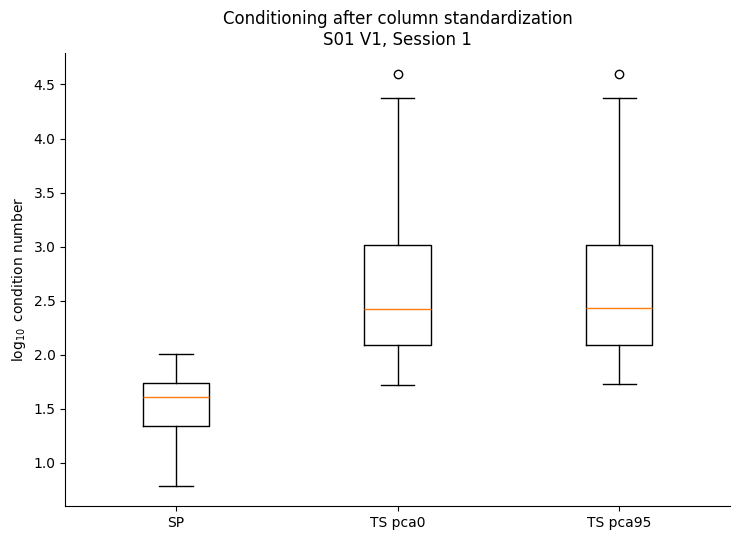

Saved: /content/drive/MyDrive/V2_drift/texturemodel/drift_results/conditioning_diagnostics/voxel_matched_SP_TS/standardized_conditioning/S01_V1_session01_standardized_conditioning_boxplot.png


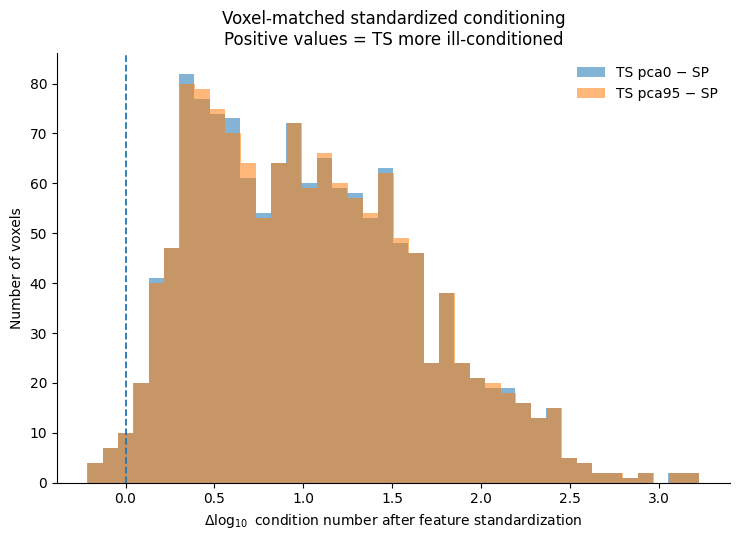

Saved: /content/drive/MyDrive/V2_drift/texturemodel/drift_results/conditioning_diagnostics/voxel_matched_SP_TS/standardized_conditioning/S01_V1_session01_standardized_delta_conditioning.png


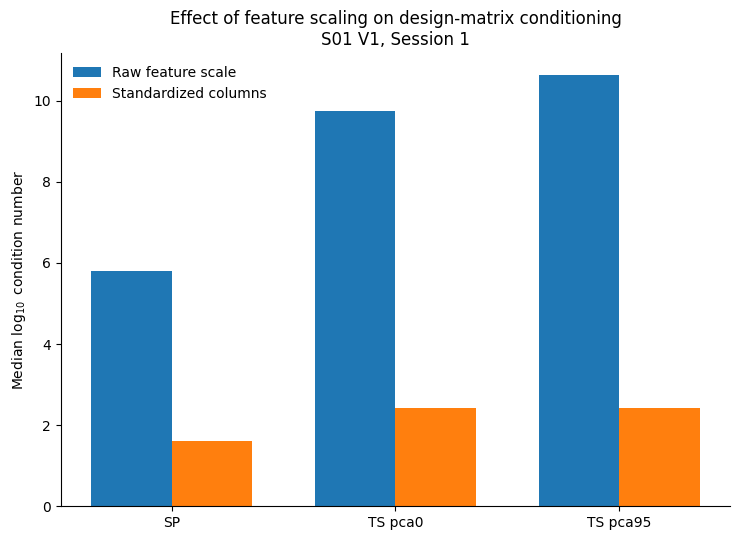

Saved: /content/drive/MyDrive/V2_drift/texturemodel/drift_results/conditioning_diagnostics/voxel_matched_SP_TS/standardized_conditioning/S01_V1_session01_raw_vs_standardized_conditioning.png

Saved:
/content/drive/MyDrive/V2_drift/texturemodel/drift_results/conditioning_diagnostics/voxel_matched_SP_TS/standardized_conditioning/S01_V1_session01_voxelmatched_raw_and_standardized_conditioning.csv
/content/drive/MyDrive/V2_drift/texturemodel/drift_results/conditioning_diagnostics/voxel_matched_SP_TS/standardized_conditioning/S01_V1_session01_raw_vs_standardized_summary.csv


In [ ]:
# RAW vs STANDARDIZED CONDITIONING DIAGNOSTIC.
# IMPORTANT: standardization here is diagnostic only. The actual TS encoding model remains fit to the raw, unnormalized feature representation.

import gc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# ============================================================
# OUTPUT
# ============================================================

OUT_DIR_STD = (
    OUT_DIR
    / "standardized_conditioning"
)

OUT_DIR_STD.mkdir(
    parents=True,
    exist_ok=True
)


# ============================================================
# CONDITIONING FUNCTION
#
# standardized=False:
#     center columns only
#
# standardized=True:
#     center AND divide each nonconstant feature by its SD
#
# This isolates conditioning due to correlation / linear
# dependence from conditioning due merely to feature scale.
# ============================================================

def matrix_diagnostics_scaled(
    X,
    standardized=False
):

    X = np.asarray(
        X,
        dtype=np.float64
    )

    # --------------------------------------------
    # Remove rows containing nonfinite values
    # --------------------------------------------

    row_ok = np.all(
        np.isfinite(X),
        axis=1
    )

    X = X[
        row_ok
    ]

    if X.shape[0] == 0:

        return {
            "n_samples": 0,
            "n_features": 0,
            "rank": 0,
            "sigma_max": np.nan,
            "sigma_min": np.nan,
            "cond": np.nan,
            "log10_cond": np.nan,
        }

    # --------------------------------------------
    # Center predictors
    # --------------------------------------------

    Xc = (
        X
        -
        np.mean(
            X,
            axis=0,
            keepdims=True
        )
    )

    # --------------------------------------------
    # Remove constant / invalid columns
    # --------------------------------------------

    col_norm = np.linalg.norm(
        Xc,
        axis=0
    )

    good_cols = (
        np.isfinite(col_norm)
        &
        (col_norm > 0)
    )

    Xc = Xc[
        :,
        good_cols
    ]

    if Xc.shape[1] == 0:

        return {
            "n_samples": Xc.shape[0],
            "n_features": 0,
            "rank": 0,
            "sigma_max": np.nan,
            "sigma_min": np.nan,
            "cond": np.inf,
            "log10_cond": np.inf,
        }

    # --------------------------------------------
    # OPTIONAL STANDARDIZATION
    #
    # ddof=0 is fine here because scaling by a
    # common finite factor does not affect the
    # conceptual conditioning comparison.
    # --------------------------------------------

    if standardized:

        sd = np.std(
            Xc,
            axis=0,
            ddof=0
        )

        good_sd = (
            np.isfinite(sd)
            &
            (sd > 0)
        )

        Xc = Xc[
            :,
            good_sd
        ]

        sd = sd[
            good_sd
        ]

        Xc = (
            Xc
            /
            sd[None, :]
        )

    # --------------------------------------------
    # SVD
    # --------------------------------------------

    S = np.linalg.svd(
        Xc,
        compute_uv=False,
        full_matrices=False
    )

    sigma_max = float(
        S[0]
    )

    sigma_min = float(
        S[-1]
    )

    tol = (
        max(Xc.shape)
        *
        np.finfo(np.float64).eps
        *
        sigma_max
    )

    rank = int(
        np.sum(
            S > tol
        )
    )

    cond = (
        sigma_max / sigma_min
        if sigma_min > 0
        else np.inf
    )

    return {
        "n_samples":
            Xc.shape[0],

        "n_features":
            Xc.shape[1],

        "rank":
            rank,

        "sigma_max":
            sigma_max,

        "sigma_min":
            sigma_min,

        "cond":
            cond,

        "log10_cond":
            np.log10(cond)
            if np.isfinite(cond)
            else np.inf,
    }


# ============================================================
# SP — RAW AND STANDARDIZED CONDITIONING PER VOXEL
# ============================================================

print("=" * 100)
print("SP RAW + STANDARDIZED CONDITIONING")
print("=" * 100)

sp_std_rows = []

for v in range(
    NVOX_SP
):

    imgs = session_image_order

    # --------------------------------------------
    # SP orientation features
    # --------------------------------------------

    X_extra = lev[
        imgs,
        v,
        num_levels:num_levels + 2
    ]

    X_ori_3d = levO[
        imgs,
        v,
        :num_levels,
        :
    ]

    X_ori = X_ori_3d.reshape(
        len(imgs),
        num_levels * num_orientations,
        order="F"
    )

    X_sp = np.concatenate(
        [
            X_ori,
            X_extra
        ],
        axis=1
    )

    raw = matrix_diagnostics_scaled(
        X_sp,
        standardized=False
    )

    std = matrix_diagnostics_scaled(
        X_sp,
        standardized=True
    )

    sp_std_rows.append({
        "voxel_position":
            v,

        "sp_raw_n_features":
            raw["n_features"],

        "sp_raw_rank":
            raw["rank"],

        "sp_raw_sigma_min":
            raw["sigma_min"],

        "sp_raw_cond":
            raw["cond"],

        "sp_raw_log10_cond":
            raw["log10_cond"],

        "sp_std_n_features":
            std["n_features"],

        "sp_std_rank":
            std["rank"],

        "sp_std_sigma_min":
            std["sigma_min"],

        "sp_std_cond":
            std["cond"],

        "sp_std_log10_cond":
            std["log10_cond"],
    })

    if (
        (v + 1) % 100 == 0
        or v == NVOX_SP - 1
    ):

        print(
            f"{v + 1}/{NVOX_SP}"
        )


sp_std_df = pd.DataFrame(
    sp_std_rows
)


# ============================================================
# TS HELPER
#
# Compute conditioning once per occupied pRF, then map back
# to every voxel assigned to that pRF.
# ============================================================

def compute_ts_standardized_conditioning(
    args,
    info,
    prefix
):

    model_name, fitting_types = (
        initialize_fitting.get_full_save_name(
            args
        )
    )

    loader = (
        initialize_fitting.make_feature_loaders(
            args,
            fitting_types,
            vi=0,
            dnn_layers_use=None,
        )
    )

    partial_masks, names = (
        loader.get_partial_versions()
    )

    partial_masks = np.asarray(
        partial_masks
    )

    n_partial = len(
        names
    )

    if (
        partial_masks.ndim == 2
        and partial_masks.shape[0] == n_partial
    ):

        partial_mask = np.asarray(
            partial_masks[0],
            dtype=bool
        )

    elif (
        partial_masks.ndim == 2
        and partial_masks.shape[1] == n_partial
    ):

        partial_mask = np.asarray(
            partial_masks[:, 0],
            dtype=bool
        )

    else:

        raise RuntimeError(
            f"Unexpected partial-mask shape: "
            f"{partial_masks.shape}"
        )

    partial_mask = partial_mask[
        :loader.max_features
    ]

    unique_prfs = np.unique(
        info[
            "fixed_prf"
        ]
    )

    prf_results = {}

    print(
        f"\n{prefix}: "
        f"{len(unique_prfs)} occupied pRFs"
    )

    for ii, prf in enumerate(
        unique_prfs,
        start=1
    ):

        feat, defined = loader.load(
            session_image_order,
            prf_model_index=int(prf)
        )

        feat = np.asarray(
            feat,
            dtype=np.float64
        )

        defined = np.asarray(
            defined,
            dtype=bool
        )

        mask = partial_mask[
            defined
        ]

        X = feat[
            :,
            mask
        ]

        raw = matrix_diagnostics_scaled(
            X,
            standardized=False
        )

        std = matrix_diagnostics_scaled(
            X,
            standardized=True
        )

        prf_results[
            int(prf)
        ] = {
            "raw": raw,
            "std": std,
        }

        if (
            ii % 50 == 0
            or ii == len(unique_prfs)
        ):

            print(
                f"{prefix}: "
                f"{ii}/{len(unique_prfs)}"
            )

    rows = []

    for v in range(
        len(
            info["fixed_prf"]
        )
    ):

        prf = int(
            info[
                "fixed_prf"
            ][v]
        )

        raw = prf_results[
            prf
        ]["raw"]

        std = prf_results[
            prf
        ]["std"]

        rows.append({
            "voxel_position":
                v,

            f"{prefix}_prf":
                prf,

            f"{prefix}_raw_n_features":
                raw["n_features"],

            f"{prefix}_raw_rank":
                raw["rank"],

            f"{prefix}_raw_sigma_min":
                raw["sigma_min"],

            f"{prefix}_raw_cond":
                raw["cond"],

            f"{prefix}_raw_log10_cond":
                raw["log10_cond"],

            f"{prefix}_std_n_features":
                std["n_features"],

            f"{prefix}_std_rank":
                std["rank"],

            f"{prefix}_std_sigma_min":
                std["sigma_min"],

            f"{prefix}_std_cond":
                std["cond"],

            f"{prefix}_std_log10_cond":
                std["log10_cond"],
        })

    loader.clear_big_features()

    return pd.DataFrame(
        rows
    )


# ============================================================
# TS PCA0
# ============================================================

print("\n" + "=" * 100)
print("TS pcaHL0")
print("=" * 100)

ts0_std_df = (
    compute_ts_standardized_conditioning(
        args0,
        ts0_info,
        "ts0"
    )
)

gc.collect()


# ============================================================
# TS PCA95
# ============================================================

print("\n" + "=" * 100)
print("TS pcaHL95")
print("=" * 100)

ts95_std_df = (
    compute_ts_standardized_conditioning(
        args95,
        ts95_info,
        "ts95"
    )
)

gc.collect()


# ============================================================
# MERGE TRUE VOXEL-MATCHED RESULTS
# ============================================================

matched_std = (
    sp_std_df
    .merge(
        ts0_std_df,
        on="voxel_position",
        validate="one_to_one"
    )
    .merge(
        ts95_std_df,
        on="voxel_position",
        validate="one_to_one"
    )
)

matched_std[
    "nsd_voxel_index"
] = ts_voxel_index


# ============================================================
# STANDARDIZED WITHIN-VOXEL DIFFERENCES
# ============================================================

matched_std[
    "delta_std_logcond_ts0_minus_sp"
] = (
    matched_std[
        "ts0_std_log10_cond"
    ]
    -
    matched_std[
        "sp_std_log10_cond"
    ]
)

matched_std[
    "delta_std_logcond_ts95_minus_sp"
] = (
    matched_std[
        "ts95_std_log10_cond"
    ]
    -
    matched_std[
        "sp_std_log10_cond"
    ]
)


# ============================================================
# SUMMARY HELPERS
# ============================================================

def finite_median(
    x
):

    x = np.asarray(
        x,
        dtype=float
    )

    x = x[
        np.isfinite(x)
    ]

    return (
        np.median(x)
        if len(x) > 0
        else np.nan
    )


def rank_def_fraction(
    df,
    rank_col,
    nfeat_col
):

    return np.mean(
        df[
            rank_col
        ]
        <
        df[
            nfeat_col
        ]
    )


# ============================================================
# RAW VS STANDARDIZED SUMMARY
# ============================================================

summary_std = pd.DataFrame({
    "metric": [
        "Median raw log10(condition)",
        "Median standardized log10(condition)",

        "Median raw sigma_min",
        "Median standardized sigma_min",

        "Raw rank-deficient fraction",
        "Standardized rank-deficient fraction",
    ],

    "SP": [
        finite_median(
            matched_std[
                "sp_raw_log10_cond"
            ]
        ),

        finite_median(
            matched_std[
                "sp_std_log10_cond"
            ]
        ),

        finite_median(
            matched_std[
                "sp_raw_sigma_min"
            ]
        ),

        finite_median(
            matched_std[
                "sp_std_sigma_min"
            ]
        ),

        rank_def_fraction(
            matched_std,
            "sp_raw_rank",
            "sp_raw_n_features"
        ),

        rank_def_fraction(
            matched_std,
            "sp_std_rank",
            "sp_std_n_features"
        ),
    ],

    "TS_pca0": [
        finite_median(
            matched_std[
                "ts0_raw_log10_cond"
            ]
        ),

        finite_median(
            matched_std[
                "ts0_std_log10_cond"
            ]
        ),

        finite_median(
            matched_std[
                "ts0_raw_sigma_min"
            ]
        ),

        finite_median(
            matched_std[
                "ts0_std_sigma_min"
            ]
        ),

        rank_def_fraction(
            matched_std,
            "ts0_raw_rank",
            "ts0_raw_n_features"
        ),

        rank_def_fraction(
            matched_std,
            "ts0_std_rank",
            "ts0_std_n_features"
        ),
    ],

    "TS_pca95": [
        finite_median(
            matched_std[
                "ts95_raw_log10_cond"
            ]
        ),

        finite_median(
            matched_std[
                "ts95_std_log10_cond"
            ]
        ),

        finite_median(
            matched_std[
                "ts95_raw_sigma_min"
            ]
        ),

        finite_median(
            matched_std[
                "ts95_std_sigma_min"
            ]
        ),

        rank_def_fraction(
            matched_std,
            "ts95_raw_rank",
            "ts95_raw_n_features"
        ),

        rank_def_fraction(
            matched_std,
            "ts95_std_rank",
            "ts95_std_n_features"
        ),
    ],
})


print("\n" + "=" * 100)
print("RAW VS STANDARDIZED CONDITIONING")
print("=" * 100)

display(
    summary_std
)


# ============================================================
# STANDARDIZED WITHIN-VOXEL COMPARISON
# ============================================================

delta0 = matched_std[
    "delta_std_logcond_ts0_minus_sp"
].to_numpy(
    dtype=float
)

delta95 = matched_std[
    "delta_std_logcond_ts95_minus_sp"
].to_numpy(
    dtype=float
)

finite_delta0 = delta0[
    np.isfinite(delta0)
]

finite_delta95 = delta95[
    np.isfinite(delta95)
]


print("\n" + "=" * 100)
print("STANDARDIZED WITHIN-VOXEL CONDITIONING DIFFERENCE")
print("=" * 100)

print(
    "Median standardized TS pca0 - SP log10(cond):",
    np.median(
        finite_delta0
    )
)

print(
    "Median standardized TS pca95 - SP log10(cond):",
    np.median(
        finite_delta95
    )
)

print()

print(
    "Fraction finite voxels where standardized "
    "TS pca0 is worse than SP:",
    np.mean(
        finite_delta0 > 0
    )
)

print(
    "Fraction finite voxels where standardized "
    "TS pca95 is worse than SP:",
    np.mean(
        finite_delta95 > 0
    )
)

print()

print(
    "TS pca0 - SP finite:",
    len(finite_delta0),
    "/",
    len(delta0)
)

print(
    "  +inf:",
    np.sum(
        np.isposinf(
            delta0
        )
    )
)

print(
    "  -inf:",
    np.sum(
        np.isneginf(
            delta0
        )
    )
)

print(
    "TS pca95 - SP finite:",
    len(finite_delta95),
    "/",
    len(delta95)
)

print(
    "  +inf:",
    np.sum(
        np.isposinf(
            delta95
        )
    )
)

print(
    "  -inf:",
    np.sum(
        np.isneginf(
            delta95
        )
    )
)


# ============================================================
# FIGURE 1
# STANDARDIZED CONDITION NUMBER DISTRIBUTIONS
# ============================================================

data = [
    matched_std.loc[
        np.isfinite(
            matched_std[
                "sp_std_log10_cond"
            ]
        ),
        "sp_std_log10_cond"
    ],

    matched_std.loc[
        np.isfinite(
            matched_std[
                "ts0_std_log10_cond"
            ]
        ),
        "ts0_std_log10_cond"
    ],

    matched_std.loc[
        np.isfinite(
            matched_std[
                "ts95_std_log10_cond"
            ]
        ),
        "ts95_std_log10_cond"
    ],
]


fig, ax = plt.subplots(
    figsize=(7.5, 5.5)
)

ax.boxplot(
    data,
    labels=[
        "SP",
        "TS pca0",
        "TS pca95"
    ],
    showfliers=True
)

ax.set_ylabel(
    r"$\log_{10}$ condition number"
)

ax.set_title(
    "Conditioning after column standardization\n"
    "S01 V1, Session 1"
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

fig.tight_layout()

fn = (
    OUT_DIR_STD
    / "S01_V1_session01_standardized_conditioning_boxplot.png"
)

fig.savefig(
    fn,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved:", fn)


# ============================================================
# FIGURE 2
# WITHIN-VOXEL STANDARDIZED DELTA
# ============================================================

fig, ax = plt.subplots(
    figsize=(7.5, 5.5)
)

ax.hist(
    finite_delta0,
    bins=40,
    alpha=0.55,
    label="TS pca0 − SP"
)

ax.hist(
    finite_delta95,
    bins=40,
    alpha=0.55,
    label="TS pca95 − SP"
)

ax.axvline(
    0,
    linestyle="--",
    linewidth=1.3
)

ax.set_xlabel(
    r"$\Delta \log_{10}$ condition number "
    "after feature standardization"
)

ax.set_ylabel(
    "Number of voxels"
)

ax.set_title(
    "Voxel-matched standardized conditioning\n"
    "Positive values = TS more ill-conditioned"
)

ax.legend(
    frameon=False
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

fig.tight_layout()

fn = (
    OUT_DIR_STD
    / "S01_V1_session01_standardized_delta_conditioning.png"
)

fig.savefig(
    fn,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved:", fn)


# ============================================================
# FIGURE 3
# RAW VS STANDARDIZED MEDIAN LOG CONDITION NUMBER
# ============================================================

labels = [
    "SP",
    "TS pca0",
    "TS pca95"
]

raw_medians = [
    finite_median(
        matched_std[
            "sp_raw_log10_cond"
        ]
    ),
    finite_median(
        matched_std[
            "ts0_raw_log10_cond"
        ]
    ),
    finite_median(
        matched_std[
            "ts95_raw_log10_cond"
        ]
    ),
]

std_medians = [
    finite_median(
        matched_std[
            "sp_std_log10_cond"
        ]
    ),
    finite_median(
        matched_std[
            "ts0_std_log10_cond"
        ]
    ),
    finite_median(
        matched_std[
            "ts95_std_log10_cond"
        ]
    ),
]

x = np.arange(
    len(labels)
)

width = 0.36

fig, ax = plt.subplots(
    figsize=(7.5, 5.5)
)

ax.bar(
    x - width / 2,
    raw_medians,
    width,
    label="Raw feature scale"
)

ax.bar(
    x + width / 2,
    std_medians,
    width,
    label="Standardized columns"
)

ax.set_xticks(
    x
)

ax.set_xticklabels(
    labels
)

ax.set_ylabel(
    r"Median $\log_{10}$ condition number"
)

ax.set_title(
    "Effect of feature scaling on design-matrix conditioning\n"
    "S01 V1, Session 1"
)

ax.legend(
    frameon=False
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

fig.tight_layout()

fn = (
    OUT_DIR_STD
    / "S01_V1_session01_raw_vs_standardized_conditioning.png"
)

fig.savefig(
    fn,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved:", fn)


# ============================================================
# SAVE FULL RESULTS
# ============================================================

csv_fn = (
    OUT_DIR_STD
    / "S01_V1_session01_voxelmatched_raw_and_standardized_conditioning.csv"
)

matched_std.to_csv(
    csv_fn,
    index=False
)

summary_fn = (
    OUT_DIR_STD
    / "S01_V1_session01_raw_vs_standardized_summary.csv"
)

summary_std.to_csv(
    summary_fn,
    index=False
)

print("\nSaved:")
print(csv_fn)
print(summary_fn)


### Finding: scaling explains much of the raw condition number, but not the full SP–TS difference

Column standardization greatly reduced the raw condition numbers:

| Metric | SP | TS pcaHL0 | TS pcaHL95 |
|---|---:|---:|---:|
| Median raw log10(condition) | 5.80 | 9.74 | 10.64 |
| Median standardized log10(condition) | 1.61 | 2.43 | 2.43 |
| Raw rank-deficient fraction | 0% | 4.1% | 27.6% |
| Standardized rank-deficient fraction | 0% | 0% | 0% |

After standardization, the median within-voxel TS–SP difference remained approximately **0.97–0.98 log10 units**, and TS remained more poorly conditioned in approximately **98.9%** of finite matched voxels.

**Interpretation:** heterogeneous feature scaling is a major contributor to the catastrophic raw conditioning, but it does not explain the entire effect. The TS representation also contains stronger predictor dependence than SP. The disappearance of formal rank deficiency after standardization also means that the raw “rank-deficient” percentages should be interpreted as numerical rank deficiency under the original scaling, not necessarily exact algebraic rank loss.


## 10. Original fitting pathway versus FAST cross-session fitting

Because the full-data TS fit had moderate coefficients whereas the session-specific fits produced coefficients up to \(10^{12}\), the FAST cross-session implementation itself was tested as a possible source of error.

For S01 V1 Session 1, three coefficient sets were compared:

1. an original-style refit through the standard model-fitting machinery;
2. a FAST-style refit;
3. the already saved FAST 30×30 HDF5 weights.

The fixed pRF assignments were also checked directly.


Streaming output truncated to the last 5000 lines.

Processing prf 303 of 1456
Index into batch for prf 303: 3
Final size of feature matrix for this image set and pRF is:
(1500, 52)
Hello there,  (750, 1350)
prf 303 - using 750 training trials and 750 held-out trials

Fitting version 0 of 1: full_model, 

Processing prf 304 of 1456
Index into batch for prf 304: 4
Final size of feature matrix for this image set and pRF is:
(1500, 52)
Hello there,  (750, 1350)
prf 304 - using 750 training trials and 750 held-out trials

Fitting version 0 of 1: full_model, 

Processing prf 305 of 1456
No voxels have this pRF saved as their best model, skipping it.

Processing prf 306 of 1456
No voxels have this pRF saved as their best model, skipping it.

Processing prf 307 of 1456
No voxels have this pRF saved as their best model, skipping it.

Processing prf 308 of 1456
No voxels have this pRF saved as their best model, skipping it.

Processing prf 309 of 1456
No voxels have this pRF saved as their best

,metric,Original_fit_model_split,FAST_refit_all750,FAST_saved_HDF5
0,Median |w|,1.669007e+02,1.669007e+02,1.669008e+02
1,P95 |w|,2.082396e+08,2.082396e+08,2.082397e+08
2,P99 |w|,1.417494e+11,1.417494e+11,1.417493e+11
3,P99.9 |w|,6.812280e+11,6.812280e+11,6.812280e+11
4,Maximum |w|,2.975685e+12,2.975685e+12,2.975686e+12
5,# |w| > 1e3,2.495700e+04,2.495700e+04,2.495700e+04
6,# |w| > 1e6,7.677000e+03,7.677000e+03,7.677000e+03
7,# |w| > 1e9,2.514000e+03,2.514000e+03,2.514000e+03



WEIGHT EQUIVALENCE

A) ORIGINAL SPLIT vs B) FAST REFIT
  shape: (1350, 54)
  correlation: 0.9999999999999999
  median |difference|: 0.0
  mean |difference|: 0.0
  max |difference|: 0.0

B) FAST REFIT vs C) SAVED FAST HDF5
  shape: (1350, 54)
  correlation: 0.9999999999999092
  median |difference|: 3.814697265625e-05
  mean |difference|: 2015.0402673688138
  max |difference|: 1245184.0

A) ORIGINAL SPLIT vs C) SAVED FAST HDF5
  shape: (1350, 54)
  correlation: 0.9999999999999092
  median |difference|: 3.814697265625e-05
  mean |difference|: 2015.0402673688138
  max |difference|: 1245184.0

BIAS EQUIVALENCE

A) ORIGINAL SPLIT vs B) FAST REFIT
  shape: (1350,)
  correlation: 1.0
  median |difference|: 0.0
  mean |difference|: 0.0
  max |difference|: 0.0

B) FAST REFIT vs C) SAVED FAST HDF5
  shape: (1350,)
  correlation: 0.9999999999999412
  median |difference|: 9.1552734375e-05
  mean |difference|: 0.0001587818287037037
  max |difference|: 0.001708984375

TOP 20 VOXELS WHERE FAST > ORIG

,voxel,prf,original_max_abs_w,fast_refit_max_abs_w,saved_fast_max_abs_w,fast_vs_original_ratio
1349,1349,654,1.472974e+07,1.472974e+07,1.472974e+07,1.0
0,0,968,1.945714e+06,1.945714e+06,1.945714e+06,1.0
1,1,0,1.748062e+08,1.748062e+08,1.748062e+08,1.0
2,2,0,7.257017e+07,7.257017e+07,7.257018e+07,1.0
3,3,0,6.254998e+07,6.254998e+07,6.255000e+07,1.0
4,4,304,1.752941e+11,1.752941e+11,1.752941e+11,1.0
1333,1333,0,8.392127e+07,8.392127e+07,8.392129e+07,1.0
1332,1332,16,5.367509e+07,5.367509e+07,5.367510e+07,1.0
1331,1331,0,3.072482e+08,3.072482e+08,3.072483e+08,1.0
1330,1330,3,5.161821e+07,5.161821e+07,5.161820e+07,1.0


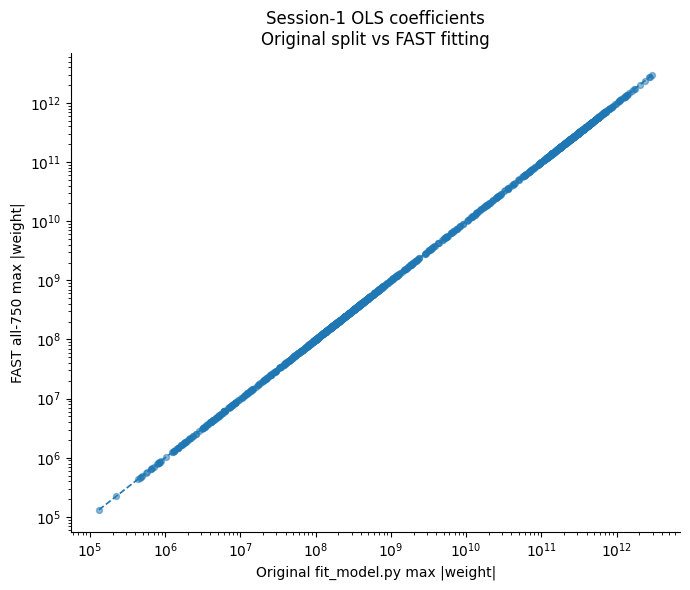

Saved: /content/drive/MyDrive/V2_drift/texturemodel/drift_results/fit_equivalence_diagnostics/S01_V1_pcaHL95_session01_original_vs_fast_weights.png


NameError: name 'x' is not defined

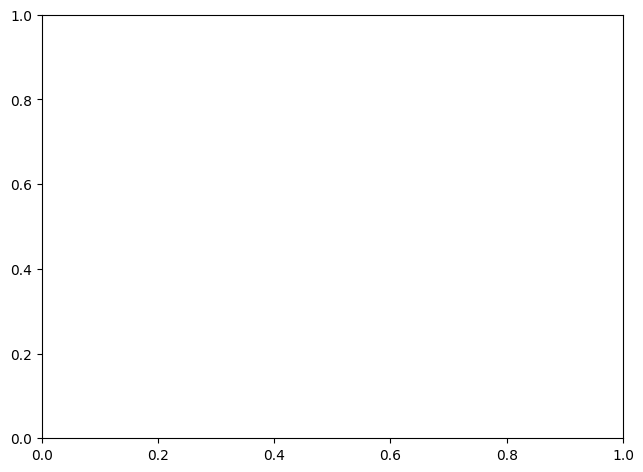

In [ ]:
# ORIGINAL-FIT vs FAST-FIT EQUIVALENCE CHECK.
# Purpose: test whether the FAST cross-session optimization itself introduced the extreme session-specific OLS coefficients.

from google.colab import drive

# ============================================================
# Mount Drive
# ============================================================
drive.mount("/content/drive", force_remount=False)

# ============================================================
# ORIGINAL fit_model.py vs FAST_CROSS_SESSION
# SESSION-1 FITTING EQUIVALENCE TEST
#
# S01 V1 | pcaHL95 | OLS | raw betas/features
#
# Compares:
#
#   A) ORIGINAL-style fit
#      train   = ~val_inds & ~holdout_inds
#      holdout = holdout_inds
#
#   B) FAST-style fit
#      train   = all 750 trials
#      holdout = same all 750 trials
#
#   C) SAVED FAST weights from 30x30 HDF5
#
# The goal is to identify whether the huge session-specific
# coefficients enter because of the FAST fitting modification.
# ============================================================

import os
import sys
import gc
import h5py
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from scipy.stats import pearsonr


# ============================================================
# PROJECT PATHS
# ============================================================

ROOT = Path(
    "/content/drive/MyDrive/V2_drift"
)

TEXTURE_ROOT = (
    ROOT
    / "texturemodel"
)

CODE_ROOT = (
    TEXTURE_ROOT
    / "code"
)

MODEL_FITTING_ROOT = (
    CODE_ROOT
    / "model_fitting"
)

UTILS_ROOT = (
    CODE_ROOT
    / "utils"
)

for p in [
    TEXTURE_ROOT,
    CODE_ROOT,
    MODEL_FITTING_ROOT,
    UTILS_ROOT,
]:

    p = str(p)

    if p not in sys.path:
        sys.path.insert(
            0,
            p
        )


# ============================================================
# PROJECT IMPORTS
# ============================================================

from utils import nsd_utils, roi_utils

import arg_parser as project_arg_parser
import initialize_fitting
import fwrf_model

# This is only used for the ROI/pRF-subsetting helper.
import fit_cross_session_matrix_fast as fast


# ============================================================
# CONFIG
# ============================================================

SUBJECT = 1
ROI = "V1"

SESSION_INDEX = 0        # Session 1

PCA_TYPE = "pcaHL"
PCA_PCT = 95


FAST_H5 = (
    ROOT
    / "texturemodel"
    / "model_fits"
    / "S01"
    / "FAST_CROSS_SESSION"
    / (
        "S01_V1_"
        "texture_pyramid_OLS_4ori_4sf_"
        "pcaHL_V1_pca95_"
        "use_nsd_grid5_pRFs_"
        "30x30_cross_session.h5py"
    )
)


OUT_DIR = (
    ROOT
    / "texturemodel"
    / "drift_results"
    / "fit_equivalence_diagnostics"
)

OUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)


# ============================================================
# BUILD EXACT MODEL CONFIGURATION
# ============================================================

def build_args():

    old_argv = sys.argv.copy()

    sys.argv = [
        "fit_equivalence_test",

        "--subject", str(SUBJECT),
        "--roi_name", ROI,

        "--debug", "0",

        "--single_sess",
        str(SESSION_INDEX),

        "--single_val_sess",
        "-1",

        "--up_to_sess", "30",

        "--whole_session_split", "1",
        "--average_image_reps", "0",

        "--sample_batch_size", "1000",
        "--voxel_batch_size", "1000",

        "--zscore_features", "0",
        "--zscore_betas_within_sess", "0",

        "--use_precomputed_prfs", "1",
        "--prfs_model_name", "nsd_grid5",
        "--which_prf_grid", "5",

        "--fitting_type",
        "texture_pyramid",

        "--n_ori_pyr", "4",
        "--n_sf_pyr", "4",

        "--group_all_hl_feats", "1",

        "--pyr_pca_type",
        PCA_TYPE,

        "--pca_pct_var",
        str(PCA_PCT),

        "--set_lambda_per_group", "0",
        "--ridge", "0",

        "--do_val", "1",
        "--do_corrcoef", "1",

        "--do_tuning", "0",
        "--do_sem_disc", "0",
        "--do_pyr_varpart", "0",

        "--trial_subset", "all",
    ]

    try:

        args = (
            project_arg_parser
            .get_args()
        )

    finally:

        sys.argv = old_argv

    return args


args = build_args()


# ============================================================
# ROI MASK
# SAME VISUALROIS DEFINITION AS FAST
# ============================================================

(
    voxel_mask,
    voxel_index,
    voxel_roi,
    voxel_ncsnr,
    brain_nii_shape,
) = fast.load_roi_metadata(
    args
)

NVOX = (
    voxel_index.shape[1]
)

print("=" * 100)
print("ROI")
print("=" * 100)

print(
    "Subject:",
    SUBJECT
)

print(
    "ROI:",
    ROI
)

print(
    "Voxels:",
    NVOX
)


# ============================================================
# LOAD SESSION 1 EXACTLY ONCE
# ============================================================

(
    voxel_data,
    image_order,
    val_inds,
    holdout_inds,
    session_inds,
) = (
    nsd_utils
    .get_data_splits_single_train(
        SUBJECT,

        sessions=np.asarray(
            [SESSION_INDEX],
            dtype=int
        ),

        voxel_mask=voxel_mask,

        volume_space=
            args.volume_space,

        zscore_betas_within_sess=
            args.zscore_betas_within_sess,

        shuffle_images=
            args.shuffle_images_once,

        average_image_reps=
            args.average_image_reps,

        random_voxel_data=
            args.random_voxel_data,
    )
)


voxel_data = np.asarray(
    voxel_data,
    dtype=np.float32
)

image_order = np.asarray(
    image_order,
    dtype=int
).reshape(-1)

val_inds = np.asarray(
    val_inds,
    dtype=bool
)

holdout_inds = np.asarray(
    holdout_inds,
    dtype=bool
)


assert voxel_data.shape == (
    len(image_order),
    NVOX
)

assert len(val_inds) == len(
    image_order
)

assert len(holdout_inds) == len(
    image_order
)


# ============================================================
# ORIGINAL fit_model.py SPLIT
# ============================================================

orig_train_mask = (
    ~val_inds
    &
    ~holdout_inds
)

orig_holdout_mask = (
    holdout_inds
)


orig_Ximg_train = (
    image_order[
        orig_train_mask
    ]
)

orig_Y_train = (
    voxel_data[
        orig_train_mask,
        :
    ]
)

orig_Ximg_holdout = (
    image_order[
        orig_holdout_mask
    ]
)

orig_Y_holdout = (
    voxel_data[
        orig_holdout_mask,
        :
    ]
)


# ============================================================
# FAST SPLIT
#
# Current FAST code deliberately fits on all trials and gives
# the same trials again as holdout.
# ============================================================

fast_Ximg_train = (
    image_order
)

fast_Y_train = (
    voxel_data
)

fast_Ximg_holdout = (
    image_order
)

fast_Y_holdout = (
    voxel_data
)


# ============================================================
# PRINT SPLIT DIFFERENCE
# ============================================================

print("\n" + "=" * 100)
print("TRIAL SPLITS")
print("=" * 100)

print(
    "Total Session-1 trials:",
    len(image_order)
)

print()

print(
    "ORIGINAL training:",
    len(orig_Ximg_train)
)

print(
    "ORIGINAL holdout:",
    len(orig_Ximg_holdout)
)

print(
    "ORIGINAL validation mask:",
    int(
        np.sum(
            val_inds
        )
    )
)

print()

print(
    "FAST training:",
    len(fast_Ximg_train)
)

print(
    "FAST holdout:",
    len(fast_Ximg_holdout)
)

print()

print(
    "Original training is",
    f"{100 * len(orig_Ximg_train) / len(image_order):.1f}%",
    "of the full session"
)


# ============================================================
# LOAD FIXED pRF INDICES
# ============================================================

best_prf, saved_prfs_fn = (
    initialize_fitting
    .load_precomputed_prfs(
        SUBJECT,
        args
    )
)

best_prf = np.asarray(
    best_prf,
    dtype=int
).reshape(-1)


# Saved pRF file can contain the broader Kastner ROI.
# Subset it exactly as FAST does.
if len(best_prf) != NVOX:

    best_prf = (
        fast
        .subset_kastner_prfs_to_visualroi(
            args=args,

            best_model_each_voxel=
                best_prf,

            visualroi_voxel_index=
                voxel_index,
        )
    )


assert len(best_prf) == NVOX


print("\n" + "=" * 100)
print("pRF CHECK")
print("=" * 100)

print(
    "pRF indices:",
    len(best_prf)
)

print(
    "Occupied pRFs:",
    len(
        np.unique(
            best_prf
        )
    )
)

print(
    "Saved pRF file:",
    saved_prfs_fn
)


# ============================================================
# MODEL NAME / FEATURE CONFIG
# ============================================================

model_name, fitting_types = (
    initialize_fitting
    .get_full_save_name(
        args
    )
)


lambdas = (
    initialize_fitting
    .get_lambdas(

        fitting_types=
            fitting_types,

        zscore_features=
            args.zscore_features,

        ridge=
            args.ridge,
    )
)


lambdas = np.atleast_1d(
    np.asarray(
        lambdas,
        dtype=np.float32
    )
)


print("\n" + "=" * 100)
print("MODEL")
print("=" * 100)

print(
    "Model:",
    model_name
)

print(
    "Lambdas:",
    lambdas
)

print(
    "Lambda shape:",
    lambdas.shape
)

# OLS sanity check:
# get_lambdas() can return more than one zero because the
# texture model contains multiple internal feature groups.
# For OLS, what matters is that ALL lambda values are zero.
assert np.all(
    np.isclose(
        lambdas,
        0
    )
), (
    f"Expected OLS-only lambdas, but got: {lambdas}"
)

print(
    "✓ All lambda values are zero -> OLS"
)

# ============================================================
# HELPER — FIT EXACT SAME encoding_model
# ============================================================

def fit_version(
    label,
    train_img,
    train_y,
    holdout_img,
    holdout_y,
):

    print("\n" + "#" * 100)
    print(label)
    print("#" * 100)

    print(
        "Training samples:",
        len(train_img)
    )

    print(
        "Holdout samples:",
        len(holdout_img)
    )


    # --------------------------------------------------------
    # Fresh feature loader.
    # Important: do not reuse cached loader between fits.
    # --------------------------------------------------------

    feature_loader = (
        initialize_fitting
        .make_feature_loaders(

            args,

            fitting_types,

            vi=0,

            dnn_layers_use=None,
        )
    )


    print(
        "Feature-loader max features:",
        feature_loader.max_features
    )


    # --------------------------------------------------------
    # Same encoding model class used by fit_model.py and FAST
    # --------------------------------------------------------

    model = (
        fwrf_model
        .encoding_model(

            feature_loader,

            lambdas=
                lambdas,

            best_model_each_voxel=
                best_prf,

            zscore=
                args.zscore_features,

            add_bias=True,

            set_lambda_per_group=
                args.set_lambda_per_group,

            voxel_batch_size=
                args.voxel_batch_size,

            sample_batch_size=
                args.sample_batch_size,

            device=
                "cpu:0",

            prfs_fit_mask=None,

            shuffle_data=False,

            bootstrap_data=False,

            do_corrcoef=
                args.do_corrcoef,

            dtype=np.float32,

            debug=
                args.debug,
        )
    )


    # --------------------------------------------------------
    # FIT
    # --------------------------------------------------------

    model.fit(

        train_img,
        train_y,

        holdout_img,
        holdout_y,

        trials_use_each_prf_trn=None,
        trials_use_each_prf_holdout=None,
    )


    # --------------------------------------------------------
    # COPY OUTPUT BEFORE DELETING MODEL
    # --------------------------------------------------------

    weights = np.asarray(
        model.best_weights,
        dtype=np.float64
    ).copy()

    biases = np.asarray(
        model.best_biases,
        dtype=np.float64
    ).copy()

    best_lambdas = np.asarray(
        model.best_lambdas
    ).copy()

    best_prf_models = np.asarray(
        model.best_prf_models
    ).copy()


    # --------------------------------------------------------
    # Feature means/stds can help identify hidden differences
    # --------------------------------------------------------

    features_mean = np.asarray(
        model.features_mean,
        dtype=np.float64
    ).copy()

    features_std = np.asarray(
        model.features_std,
        dtype=np.float64
    ).copy()


    feature_loader.clear_big_features()

    del model
    del feature_loader

    gc.collect()


    return {

        "weights":
            weights,

        "biases":
            biases,

        "best_lambdas":
            best_lambdas,

        "best_prf_models":
            best_prf_models,

        "features_mean":
            features_mean,

        "features_std":
            features_std,
    }


# ============================================================
# FIT A — ORIGINAL fit_model.py SPLIT
# ============================================================

original_fit = fit_version(

    "A) ORIGINAL fit_model.py SESSION-1 SPLIT",

    orig_Ximg_train,
    orig_Y_train,

    orig_Ximg_holdout,
    orig_Y_holdout,
)


# ============================================================
# FIT B — FAST ALL-TRIAL SESSION FIT
# ============================================================

fast_refit = fit_version(

    "B) FAST ALL-TRIAL SESSION-1 FIT",

    fast_Ximg_train,
    fast_Y_train,

    fast_Ximg_holdout,
    fast_Y_holdout,
)


# ============================================================
# LOAD C — EXISTING SAVED FAST WEIGHTS
# ============================================================

print("\n" + "#" * 100)
print("C) SAVED FAST 30×30 FILE — TRAIN SESSION 1")
print("#" * 100)

if not FAST_H5.exists():

    raise FileNotFoundError(
        FAST_H5
    )


with h5py.File(
    FAST_H5,
    "r"
) as f:

    saved_fast_weights = np.asarray(
        f[
            "best_weights"
        ][
            SESSION_INDEX,
            :,
            :,
            0
        ],
        dtype=np.float64
    )

    saved_fast_biases = np.asarray(
        f[
            "best_biases"
        ][
            SESSION_INDEX,
            :,
            0
        ],
        dtype=np.float64
    )

    saved_fast_prf = np.asarray(
        f[
            "fixed_best_model_each_voxel"
        ],
        dtype=int
    )


print(
    "Saved FAST weights:",
    saved_fast_weights.shape
)

print(
    "Saved FAST biases:",
    saved_fast_biases.shape
)


# ============================================================
# REMOVE PARTIAL-VERSION DIMENSION
# ============================================================

def squeeze_full_model_weights(W):

    W = np.asarray(
        W,
        dtype=np.float64
    )

    # expected:
    # voxel × feature × partial_version
    if W.ndim == 3:

        W = W[
            :,
            :,
            0
        ]

    return W


def squeeze_full_model_bias(B):

    B = np.asarray(
        B,
        dtype=np.float64
    )

    if (
        B.ndim == 2
        and
        B.shape[1] == 1
    ):

        B = B[
            :,
            0
        ]

    return B


W_orig = squeeze_full_model_weights(
    original_fit[
        "weights"
    ]
)

W_fast = squeeze_full_model_weights(
    fast_refit[
        "weights"
    ]
)

B_orig = squeeze_full_model_bias(
    original_fit[
        "biases"
    ]
)

B_fast = squeeze_full_model_bias(
    fast_refit[
        "biases"
    ]
)


assert (
    W_orig.shape
    ==
    W_fast.shape
    ==
    saved_fast_weights.shape
)


# ============================================================
# BASIC pRF CHECK
# ============================================================

print("\n" + "=" * 100)
print("pRF EQUIVALENCE")
print("=" * 100)

print(
    "Current fixed pRF vs saved FAST:",
    np.array_equal(
        best_prf,
        saved_fast_prf
    )
)


# ============================================================
# SUMMARY HELPER
# ============================================================

def weight_summary(
    W
):

    vals = np.abs(
        W[
            np.isfinite(W)
        ]
    )

    return {

        "median_abs":
            np.median(vals),

        "p95_abs":
            np.percentile(
                vals,
                95
            ),

        "p99_abs":
            np.percentile(
                vals,
                99
            ),

        "p99_9_abs":
            np.percentile(
                vals,
                99.9
            ),

        "max_abs":
            np.max(vals),

        "n_gt_1e3":
            int(
                np.sum(
                    vals > 1e3
                )
            ),

        "n_gt_1e6":
            int(
                np.sum(
                    vals > 1e6
                )
            ),

        "n_gt_1e9":
            int(
                np.sum(
                    vals > 1e9
                )
            ),
    }


S_orig = weight_summary(
    W_orig
)

S_fast = weight_summary(
    W_fast
)

S_saved = weight_summary(
    saved_fast_weights
)


summary = pd.DataFrame({

    "metric": [
        "Median |w|",
        "P95 |w|",
        "P99 |w|",
        "P99.9 |w|",
        "Maximum |w|",
        "# |w| > 1e3",
        "# |w| > 1e6",
        "# |w| > 1e9",
    ],

    "Original_fit_model_split": [
        S_orig[
            "median_abs"
        ],
        S_orig[
            "p95_abs"
        ],
        S_orig[
            "p99_abs"
        ],
        S_orig[
            "p99_9_abs"
        ],
        S_orig[
            "max_abs"
        ],
        S_orig[
            "n_gt_1e3"
        ],
        S_orig[
            "n_gt_1e6"
        ],
        S_orig[
            "n_gt_1e9"
        ],
    ],

    "FAST_refit_all750": [
        S_fast[
            "median_abs"
        ],
        S_fast[
            "p95_abs"
        ],
        S_fast[
            "p99_abs"
        ],
        S_fast[
            "p99_9_abs"
        ],
        S_fast[
            "max_abs"
        ],
        S_fast[
            "n_gt_1e3"
        ],
        S_fast[
            "n_gt_1e6"
        ],
        S_fast[
            "n_gt_1e9"
        ],
    ],

    "FAST_saved_HDF5": [
        S_saved[
            "median_abs"
        ],
        S_saved[
            "p95_abs"
        ],
        S_saved[
            "p99_abs"
        ],
        S_saved[
            "p99_9_abs"
        ],
        S_saved[
            "max_abs"
        ],
        S_saved[
            "n_gt_1e3"
        ],
        S_saved[
            "n_gt_1e6"
        ],
        S_saved[
            "n_gt_1e9"
        ],
    ],
})


print("\n" + "=" * 100)
print("WEIGHT DISTRIBUTION COMPARISON")
print("=" * 100)

display(
    summary
)


# ============================================================
# ARRAY COMPARISON HELPER
# ============================================================

def compare_arrays(
    name,
    A,
    B
):

    A = np.asarray(
        A,
        dtype=np.float64
    )

    B = np.asarray(
        B,
        dtype=np.float64
    )

    assert A.shape == B.shape

    valid = (
        np.isfinite(A)
        &
        np.isfinite(B)
    )

    a = A[
        valid
    ]

    b = B[
        valid
    ]

    if len(a) > 2:

        r = np.corrcoef(
            a,
            b
        )[0, 1]

    else:

        r = np.nan


    diff = np.abs(
        a
        -
        b
    )


    print(
        f"\n{name}"
    )

    print(
        "  shape:",
        A.shape
    )

    print(
        "  correlation:",
        r
    )

    print(
        "  median |difference|:",
        np.median(
            diff
        )
    )

    print(
        "  mean |difference|:",
        np.mean(
            diff
        )
    )

    print(
        "  max |difference|:",
        np.max(
            diff
        )
    )

    return r


# ============================================================
# KEY COMPARISONS
# ============================================================

print("\n" + "=" * 100)
print("WEIGHT EQUIVALENCE")
print("=" * 100)


r_orig_fast = compare_arrays(

    "A) ORIGINAL SPLIT vs B) FAST REFIT",

    W_orig,
    W_fast
)


r_fast_saved = compare_arrays(

    "B) FAST REFIT vs C) SAVED FAST HDF5",

    W_fast,
    saved_fast_weights
)


r_orig_saved = compare_arrays(

    "A) ORIGINAL SPLIT vs C) SAVED FAST HDF5",

    W_orig,
    saved_fast_weights
)


# ============================================================
# BIAS COMPARISON
# ============================================================

print("\n" + "=" * 100)
print("BIAS EQUIVALENCE")
print("=" * 100)


compare_arrays(

    "A) ORIGINAL SPLIT vs B) FAST REFIT",

    B_orig,
    B_fast
)


compare_arrays(

    "B) FAST REFIT vs C) SAVED FAST HDF5",

    B_fast,
    saved_fast_biases
)


# ============================================================
# PER-VOXEL MAX WEIGHT
# ============================================================

max_orig_vox = np.nanmax(
    np.abs(
        W_orig
    ),
    axis=1
)

max_fast_vox = np.nanmax(
    np.abs(
        W_fast
    ),
    axis=1
)

max_saved_vox = np.nanmax(
    np.abs(
        saved_fast_weights
    ),
    axis=1
)


voxel_table = pd.DataFrame({

    "voxel":
        np.arange(
            NVOX
        ),

    "prf":
        best_prf,

    "original_max_abs_w":
        max_orig_vox,

    "fast_refit_max_abs_w":
        max_fast_vox,

    "saved_fast_max_abs_w":
        max_saved_vox,

})


voxel_table[
    "fast_vs_original_ratio"
] = (
    voxel_table[
        "fast_refit_max_abs_w"
    ]
    /
    voxel_table[
        "original_max_abs_w"
    ]
)


print("\n" + "=" * 100)
print("TOP 20 VOXELS WHERE FAST > ORIGINAL")
print("=" * 100)

display(

    voxel_table
    .replace(
        [
            np.inf,
            -np.inf
        ],
        np.nan
    )
    .sort_values(
        "fast_vs_original_ratio",
        ascending=False
    )
    .head(20)
)


# ============================================================
# FIGURE 1 — PER-VOXEL MAX COEFFICIENT
# ============================================================

fig, ax = plt.subplots(
    figsize=(
        7,
        6
    )
)

valid = (
    np.isfinite(
        max_orig_vox
    )
    &
    np.isfinite(
        max_fast_vox
    )
    &
    (max_orig_vox > 0)
    &
    (max_fast_vox > 0)
)


ax.scatter(
    max_orig_vox[
        valid
    ],

    max_fast_vox[
        valid
    ],

    s=18,
    alpha=0.5
)


ax.set_xscale(
    "log"
)

ax.set_yscale(
    "log"
)


lo = min(
    np.min(
        max_orig_vox[
            valid
        ]
    ),
    np.min(
        max_fast_vox[
            valid
        ]
    )
)

hi = max(
    np.max(
        max_orig_vox[
            valid
        ]
    ),
    np.max(
        max_fast_vox[
            valid
        ]
    )
)


ax.plot(
    [
        lo,
        hi
    ],
    [
        lo,
        hi
    ],
    linestyle="--",
    linewidth=1.2
)


ax.set_xlabel(
    "Original fit_model.py max |weight|"
)

ax.set_ylabel(
    "FAST all-750 max |weight|"
)

ax.set_title(
    "Session-1 OLS coefficients\n"
    "Original split vs FAST fitting"
)

ax.spines[
    "top"
].set_visible(
    False
)

ax.spines[
    "right"
].set_visible(
    False
)

fig.tight_layout()


fn = (
    OUT_DIR
    / (
        "S01_V1_pcaHL95_"
        "session01_original_vs_fast_weights.png"
    )
)

fig.savefig(
    fn,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(
    "Saved:",
    fn
)


# ============================================================
# FIGURE 2 — ECDF OF ALL ABSOLUTE WEIGHTS
# ============================================================

def ecdf(
    vals
):

    vals = np.abs(
        np.asarray(
            vals,
            dtype=float
        )
    ).ravel()

    vals = vals[
        np.isfinite(
            vals
        )
        &
        (vals > 0)
    ]

    vals = np.sort(
        vals
    )

    y = (
        np.arange(
            1,
            len(vals) + 1
        )
        /
        len(vals)
    )

    return (
        vals,
        y
    )


fig, ax = plt.subplots(
    figsize=(
        7.5,
        5.5
    )
)


for label, W in [

    (
        "Original fit_model.py split",
        W_orig
    ),

    (
        "FAST refit — all 750",
        W_fast
    ),

    (
        "Saved FAST HDF5",
        saved_fast_weights
    ),
]:

    x,
    y = ecdf(
        W
    )

    ax.plot(
        x,
        y,
        linewidth=1.8,
        label=label
    )


ax.set_xscale(
    "log"
)

ax.set_xlabel(
    "|Weight|"
)

ax.set_ylabel(
    "Cumulative proportion"
)

ax.set_title(
    "Session-1 OLS coefficient distributions\n"
    "S01 V1, pcaHL95"
)

ax.legend(
    frameon=False
)

ax.spines[
    "top"
].set_visible(
    False
)

ax.spines[
    "right"
].set_visible(
    False
)

fig.tight_layout()


fn = (
    OUT_DIR
    / (
        "S01_V1_pcaHL95_"
        "session01_original_fast_ECDF.png"
    )
)

fig.savefig(
    fn,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(
    "Saved:",
    fn
)


# ============================================================
# SAVE NUMERICAL RESULTS
# ============================================================

summary_csv = (
    OUT_DIR
    / (
        "S01_V1_pcaHL95_"
        "session01_original_vs_fast_summary.csv"
    )
)

voxel_csv = (
    OUT_DIR
    / (
        "S01_V1_pcaHL95_"
        "session01_original_vs_fast_voxels.csv"
    )
)


summary.to_csv(
    summary_csv,
    index=False
)

voxel_table.to_csv(
    voxel_csv,
    index=False
)


print("\n" + "=" * 100)
print("INTERPRETATION GUIDE")
print("=" * 100)

print(
    """
Look first at:

1. FAST REFIT vs SAVED FAST HDF5
   - These should be essentially identical.
   - If they are not, this diagnostic is not reproducing FAST.

2. ORIGINAL SPLIT vs FAST REFIT

Possible outcomes:

A) Original weights are normal/moderate, FAST weights explode
   -> the all-750 modification in FAST is implicated.

B) Both Original and FAST explode similarly
   -> the explosion is NOT caused by the FAST all-trial change.
      It is a property of session-wise OLS with these TS features.

C) FAST refit does not match saved FAST
   -> there is another configuration/code-path difference that
      needs to be located before interpreting anything.
"""
)

print(
    "\nSaved:"
)

print(
    summary_csv
)

print(
    voxel_csv
)


### Finding: the FAST implementation did not create the extreme coefficients

The original-style refit and the FAST refit produced **exactly the same Session-1 coefficients**:

- weight correlation: essentially 1.0;
- median absolute difference: 0;
- maximum absolute difference: 0;
- identical coefficient-distribution summaries.

The FAST refit also reproduced the previously saved FAST HDF5 weights essentially perfectly. The fixed pRF arrays were identical (`Current fixed pRF vs saved FAST: True`).

For all three versions, S01 V1 pcaHL95 showed approximately:

- median \(|w|\): 167;
- P95 \(|w|\): \(2.08\times10^8\);
- P99 \(|w|\): \(1.42\times10^{11}\);
- P99.9 \(|w|\): \(6.81\times10^{11}\);
- maximum \(|w|\): \(2.98\times10^{12}\);
- 2,514 weights above \(10^9\).

**Conclusion:** the coefficient explosion was not introduced by the FAST cross-session optimization. It is reproduced by the underlying session-specific OLS fitting machinery.

The remaining contrast is therefore between **full-data fitting**, where coefficients are moderate, and **session-specific fitting**, where the raw TS design matrix is much less numerically stable.


# Current interpretation and methodological decision

The validation sequence progressively ruled out several candidate explanations.

- **Obsolete PCA implementation:** current analyses use the new all-HL PCA implementation; old subgroup-PCA runs were identified by their larger feature dimensionality.
- **pcaHL95 alone:** ruled out as the fundamental cause because pcaHL0 also shows extreme session-specific OLS coefficients.
- **Saved-weight corruption:** ruled out by direct SVD reconstruction.
- **FAST cross-session fitting bug:** ruled out by the original-versus-FAST equivalence test.
- **Simple fixed-pRF mismatch:** not supported; the pRF assignment used in the refit matches the saved FAST assignment.
- **Generic one-session OLS problem:** insufficient explanation because matched SP matrices are dramatically better conditioned.
- **Feature scaling alone:** insufficient explanation; standardization removes much of the raw conditioning gap but TS remains more poorly conditioned than SP.

The current evidence therefore supports the interpretation that **session-specific OLS estimation of the raw texture-statistics representation is numerically unstable because of a combination of heterogeneous predictor scales, stronger predictor dependence, and the smaller amount of data available within a single session**. The much more stable full-data fits are consistent with the larger dataset constraining the regression more effectively.

## Decision for the thesis analysis

The primary longitudinal TS analysis remains OLS so that the estimator is consistent across sessions and does not introduce session-dependent regularization as an additional source of temporal variation. The numerical instability will be reported explicitly as a methodological limitation and supported by the conditioning/SVD diagnostics.

For population and RDM analyses, coefficient magnitude alone is not sufficient to invalidate the predictions because large opposing coefficients can cancel. The important downstream controls are therefore:

1. exact prediction/reconstruction checks;
2. response-scale checks;
3. sensitivity analyses excluding the most extreme simulated-response voxels;
4. transparent comparison with SP, whose simulated responses remain on a much smaller numerical scale.

These checks should be treated as part of the methodological validation of the TS population/RDM pipeline rather than as evidence that the underlying drift effect is automatically artifactual.


Mounted at /content/drive
LOADING FAST CROSS-SESSION WEIGHTS
/content/drive/MyDrive/V2_drift/texturemodel/model_fits/S01/FAST_CROSS_SESSION/S01_V1_texture_pyramid_OLS_4ori_4sf_pcaHL_V1_pca95_use_nsd_grid5_pRFs_30x30_cross_session.h5py

Raw best_weights shape:
(30, 1350, 54, 1)

Analysis shape:
sessions=30, voxels=1350, features=54

Finite weights:
2187000 / 2187000 (100.0000%)

TOP FEATURES BY MAXIMUM |WEIGHT|


,feature,median_abs_w,p95_abs_w,p99_abs_w,p99_9_abs_w,max_abs_w,n_gt_1e+03,n_gt_1e+06,n_gt_1e+09,pct_times_largest_feature
35,35,1.871539e+08,3.972925e+11,8.910092e+11,1.946038e+12,7.303472e+12,40498,39100,14721,27.760494
37,37,1.899250e+08,3.917622e+11,9.174758e+11,2.011493e+12,6.969736e+12,40499,39234,14700,28.456790
34,34,1.874035e+08,3.081977e+11,7.083641e+11,1.598938e+12,5.559340e+12,40496,38321,15137,19.511111
36,36,2.338874e+08,2.997494e+11,6.561963e+11,1.466766e+12,3.749146e+12,40499,38361,15722,24.155556
32,32,6.137434e+05,2.323848e+09,1.599439e+10,7.536443e+10,5.435064e+11,39740,18150,4135,0.022222
33,33,5.970698e+05,2.234648e+09,1.522727e+10,1.059643e+11,3.763381e+11,39877,17396,4071,0.037037
30,30,5.027893e+05,2.427906e+09,1.840075e+10,9.172123e+10,2.764152e+11,39742,17156,4214,0.024691
31,31,5.973245e+05,2.290224e+09,1.501853e+10,8.896594e+10,2.224976e+11,39894,17428,4103,0.032099
28,28,3.002126e+03,9.493673e+05,4.291780e+06,3.964944e+07,4.912536e+08,24519,1933,0,0.000000
26,26,2.806986e+03,8.860659e+05,4.333064e+06,5.033281e+07,3.769752e+08,24603,1815,0,0.000000



TOP FEATURES BY NUMBER OF >1e9 COEFFICIENTS


,feature,n_gt_1e+09,pct_gt_1e+09,max_abs_w,pct_times_largest_feature,times_largest_when_max_gt_1e+09
36,36,15722,38.819753,3.749146e+12,24.155556,4788
34,34,15137,37.375309,5.559340e+12,19.511111,4102
35,35,14721,36.348148,7.303472e+12,27.760494,4353
37,37,14700,36.296296,6.969736e+12,28.456790,4274
30,30,4214,10.404938,2.764152e+11,0.024691,5
32,32,4135,10.209877,5.435064e+11,0.022222,1
31,31,4103,10.130864,2.224976e+11,0.032099,0
33,33,4071,10.051852,3.763381e+11,0.037037,1
8,8,0,0.000000,9.765591e+02,0.000000,0
9,9,0,0.000000,1.232296e+03,0.000000,0



FEATURES MOST OFTEN THE LARGEST COEFFICIENT


...


VOXELS WITH LARGEST WEIGHT MAGNITUDES


,voxel,fixed_prf,max_abs_w,p99_abs_w,n_gt_1e+09,n_sessions_any_gt_1e+09
145,145,196,7.303472e+12,2.362800e+12,120,30
1171,1171,336,5.559340e+12,2.029221e+12,230,30
162,162,461,4.064665e+12,1.674702e+12,240,30
997,997,301,3.630188e+12,1.343854e+12,226,30
200,200,195,3.607706e+12,1.712941e+12,120,30
273,273,359,3.561169e+12,1.254040e+12,222,30
878,878,182,3.424142e+12,8.251978e+11,120,30
104,104,196,3.305554e+12,1.477876e+12,120,30
155,155,197,3.073901e+12,1.138860e+12,120,30
1164,1164,318,2.721589e+12,9.854064e+11,219,30



SESSION SUMMARY


,session,median_abs_w,p99_abs_w,p99_9_abs_w,max_abs_w,n_gt_1e+03,n_voxels_any_gt_1e+03,n_gt_1e+06,n_voxels_any_gt_1e+06,n_gt_1e+09,n_voxels_any_gt_1e+09
0,1,166.900772,1.417493e+11,6.812280e+11,2.975686e+12,24957,1350,7677,1331,2514,579
1,2,153.727837,1.398439e+11,6.413136e+11,2.047352e+12,24533,1350,7627,1327,2477,567
2,3,169.067993,1.556311e+11,7.162038e+11,3.504877e+12,24813,1350,7728,1329,2600,585
3,4,154.303085,1.388573e+11,5.923522e+11,3.073901e+12,24368,1350,7704,1333,2490,572
4,5,163.546356,1.434747e+11,7.012841e+11,7.303472e+12,24899,1350,7844,1333,2557,581
5,6,170.322098,1.481286e+11,6.568989e+11,6.969736e+12,25055,1350,7775,1327,2508,574
6,7,188.458282,1.838208e+11,7.709197e+11,2.156877e+12,25644,1350,7843,1336,2649,591
7,8,169.224854,1.543822e+11,6.606523e+11,3.305554e+12,25047,1350,7840,1338,2592,599
8,9,174.118690,1.551575e+11,6.948731e+11,2.643390e+12,25005,1350,7708,1327,2568,583
9,10,183.264542,1.564633e+11,7.301469e+11,2.595069e+12,25428,1350,7717,1331,2602,584



GLOBAL CONCENTRATION SUMMARY

Threshold > 1e+03
Voxels affected   : 1350/1350 (100.00%)
Sessions affected : 30/30
Features affected : 47/54

Threshold > 1e+06
Voxels affected   : 1348/1350 (99.85%)
Sessions affected : 30/30
Features affected : 12/54

Threshold > 1e+09
Voxels affected   : 734/1350 (54.37%)
Sessions affected : 30/30
Features affected : 8/54


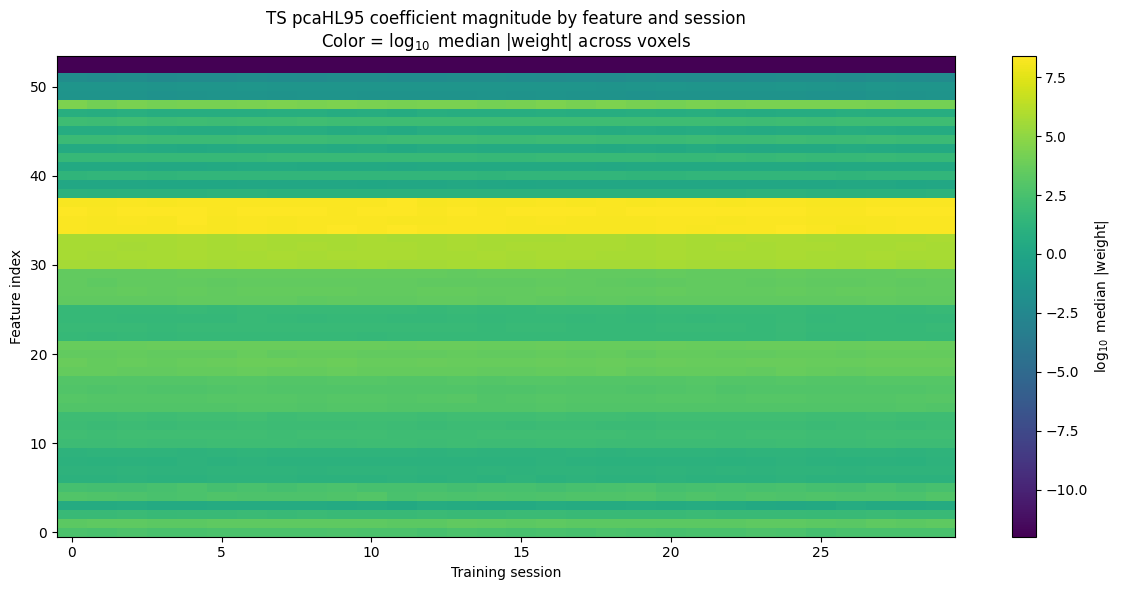

Saved: /content/drive/MyDrive/V2_drift/texturemodel/drift_results/weight_feature_diagnostics/S01_V1_pcaHL95_feature_session_median_weights.png


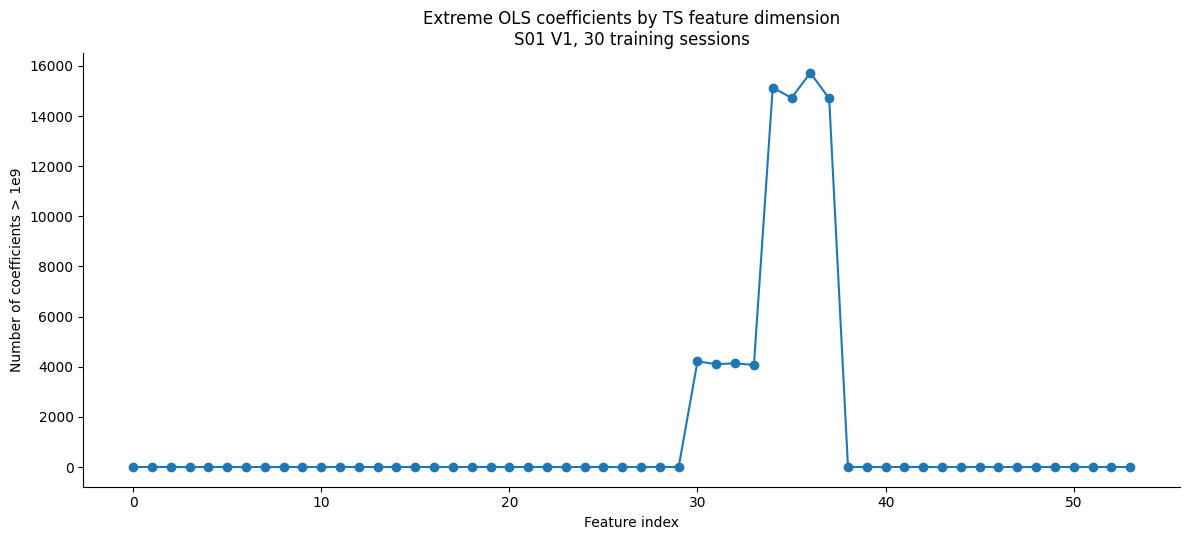

Saved: /content/drive/MyDrive/V2_drift/texturemodel/drift_results/weight_feature_diagnostics/S01_V1_pcaHL95_feature_extreme_counts_gt1e9.png


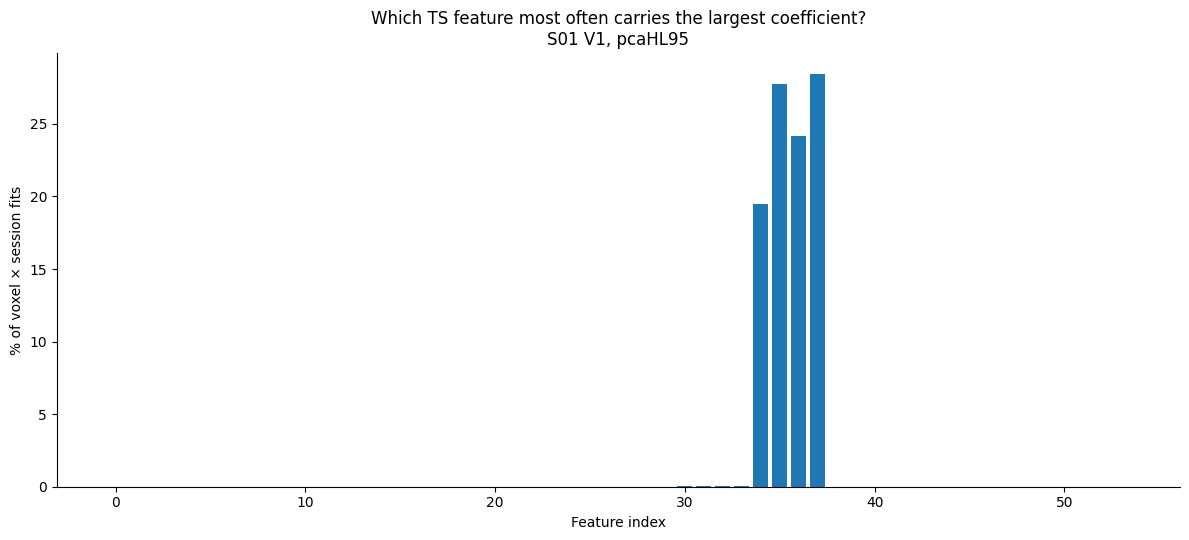

Saved: /content/drive/MyDrive/V2_drift/texturemodel/drift_results/weight_feature_diagnostics/S01_V1_pcaHL95_feature_max_weight_frequency.png


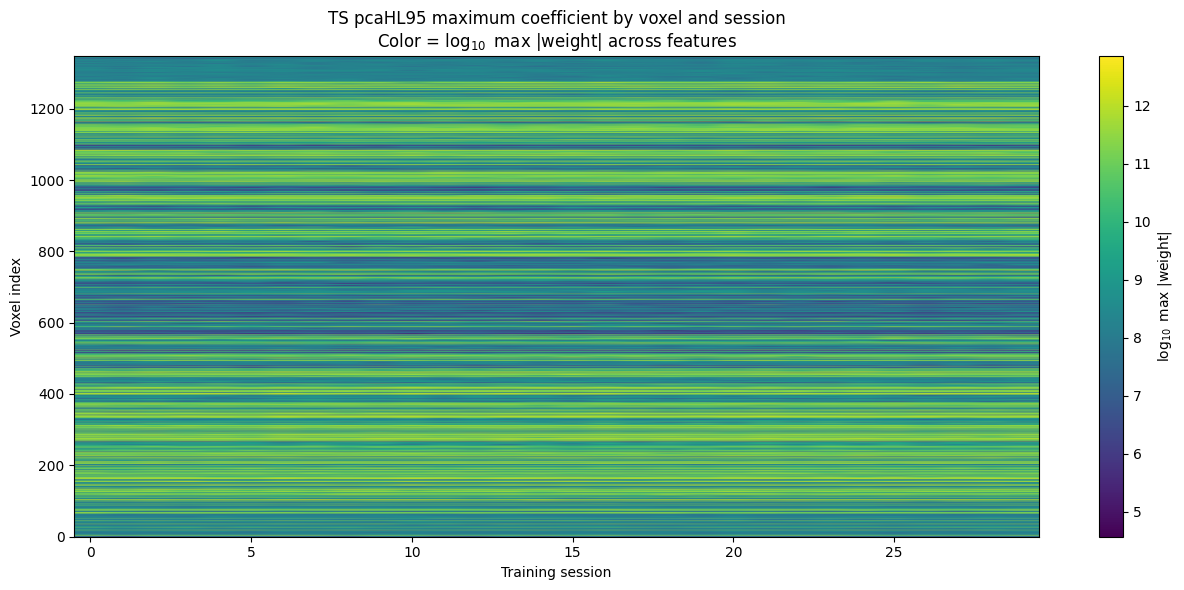

Saved: /content/drive/MyDrive/V2_drift/texturemodel/drift_results/weight_feature_diagnostics/S01_V1_pcaHL95_voxel_session_max_weights.png

SAVED
/content/drive/MyDrive/V2_drift/texturemodel/drift_results/weight_feature_diagnostics/S01_V1_pcaHL95_feature_weight_summary.csv
/content/drive/MyDrive/V2_drift/texturemodel/drift_results/weight_feature_diagnostics/S01_V1_pcaHL95_voxel_weight_summary.csv
/content/drive/MyDrive/V2_drift/texturemodel/drift_results/weight_feature_diagnostics/S01_V1_pcaHL95_session_weight_summary.csv

INTERPRETATION GUIDE
--------------------

1. If only a small fraction of voxels have coefficients >1e9:
   -> the numerical instability is voxel/pRF-specific.

2. If most/all 54 features occasionally exceed 1e9, but no
   feature dominates repeatedly:
   -> the instability is NOT tied to one particular feature.
      It likely reflects different near-dependent linear
      combinations of TS features in different pRFs/sessions.

3. If a few feature indices account fo

In [ ]:
# ============================================================
# FEATURE-LEVEL OLS INSTABILITY CHECK
#
# Purpose:
#   Determine whether the extremely large TS OLS coefficients
#   are concentrated:
#
#   1) in only a subset of voxels/sessions, and/or
#   2) in specific feature dimensions.
#
# Input:
#   Existing FAST cross-session pcaHL95 HDF5 file.
#
# Main outputs:
#   - per-feature coefficient distribution
#   - number/fraction of coefficients > 1e3, 1e6, 1e9
#   - how often each feature is the largest-|weight| feature
#     within a voxel/session fit
#   - per-voxel prevalence of extreme weights
#   - per-session prevalence of extreme weights
#
# IMPORTANT:
#   This is a diagnostic only. It does not modify the fitted
#   model or exclude any features/voxels.
# ============================================================

import h5py
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from google.colab import drive


# ============================================================
# Mount Drive
# ============================================================
drive.mount("/content/drive", force_remount=False)

# ============================================================
# CONFIG
# ============================================================

SUBJECT = 1
ROI = "V1"

ROOT = Path(
    "/content/drive/MyDrive/V2_drift/texturemodel"
)

FAST_H5 = (
    ROOT
    / "model_fits"
    / f"S{SUBJECT:02d}"
    / "FAST_CROSS_SESSION"
    / (
        f"S{SUBJECT:02d}_{ROI}_"
        f"texture_pyramid_OLS_4ori_4sf_"
        f"pcaHL_{ROI}_pca95_"
        f"use_nsd_grid5_pRFs_"
        f"30x30_cross_session.h5py"
    )
)

OUT_DIR = (
    ROOT
    / "drift_results"
    / "weight_feature_diagnostics"
)

OUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

THRESHOLDS = [
    1e3,
    1e6,
    1e9,
]


# ============================================================
# LOAD SAVED SESSION-SPECIFIC WEIGHTS
# ============================================================

print("=" * 100)
print("LOADING FAST CROSS-SESSION WEIGHTS")
print("=" * 100)

print(FAST_H5)

with h5py.File(
    FAST_H5,
    "r"
) as f:

    W = np.asarray(
        f["best_weights"],
        dtype=np.float64
    )

    # Optional metadata
    fixed_prf = (
        np.asarray(
            f["fixed_best_model_each_voxel"],
            dtype=int
        )
        if "fixed_best_model_each_voxel" in f
        else None
    )


print("\nRaw best_weights shape:")
print(W.shape)


# ============================================================
# REMOVE PARTIAL-MODEL DIMENSION
#
# Expected FAST shape:
#   train_session × voxel × feature × partial_version
#
# For the full model, partial_version = 0.
# ============================================================

if W.ndim == 4:

    W = W[
        :,
        :,
        :,
        0
    ]

elif W.ndim != 3:

    raise RuntimeError(
        f"Unexpected weight shape: {W.shape}"
    )


N_SESS, N_VOX, N_FEAT = W.shape

print("\nAnalysis shape:")
print(
    f"sessions={N_SESS}, "
    f"voxels={N_VOX}, "
    f"features={N_FEAT}"
)

assert N_SESS == 30


# ============================================================
# ABSOLUTE WEIGHTS
# ============================================================

ABS_W = np.abs(
    W
)

finite = np.isfinite(
    ABS_W
)

print("\nFinite weights:")
print(
    f"{finite.sum()} / {finite.size} "
    f"({100 * finite.mean():.4f}%)"
)


# ============================================================
# 1. PER-FEATURE SUMMARY
#
# Collapse over:
#   session × voxel
#
# This asks:
#   Does feature j repeatedly receive large coefficients?
# ============================================================

feature_rows = []

for fi in range(
    N_FEAT
):

    vals = ABS_W[
        :,
        :,
        fi
    ]

    vals = vals[
        np.isfinite(
            vals
        )
    ]

    row = {
        "feature":
            fi,

        "n_coefficients":
            len(vals),

        "median_abs_w":
            np.median(
                vals
            ),

        "p95_abs_w":
            np.percentile(
                vals,
                95
            ),

        "p99_abs_w":
            np.percentile(
                vals,
                99
            ),

        "p99_9_abs_w":
            np.percentile(
                vals,
                99.9
            ),

        "max_abs_w":
            np.max(
                vals
            ),
    }

    for thr in THRESHOLDS:

        n = int(
            np.sum(
                vals > thr
            )
        )

        row[
            f"n_gt_{thr:.0e}"
        ] = n

        row[
            f"pct_gt_{thr:.0e}"
        ] = (
            100
            *
            n
            /
            len(vals)
        )

    feature_rows.append(
        row
    )


feature_df = pd.DataFrame(
    feature_rows
)


# ============================================================
# 2. HOW OFTEN IS EACH FEATURE THE LARGEST COEFFICIENT?
#
# For every:
#   session × voxel
#
# find:
#   argmax_feature |w|
#
# If instability is feature-specific, the same feature(s)
# should dominate repeatedly.
# ============================================================

safe_abs = np.where(
    np.isfinite(
        ABS_W
    ),
    ABS_W,
    -np.inf
)

max_feature_each_fit = np.argmax(
    safe_abs,
    axis=2
)

max_value_each_fit = np.max(
    safe_abs,
    axis=2
)


winner_counts = np.bincount(
    max_feature_each_fit.ravel(),
    minlength=N_FEAT
)

winner_pct = (
    100
    *
    winner_counts
    /
    winner_counts.sum()
)


feature_df[
    "times_largest_feature"
] = winner_counts

feature_df[
    "pct_times_largest_feature"
] = winner_pct


# ============================================================
# 3. EXTREME-WEIGHT WINNERS ONLY
#
# Among voxel/session fits whose maximum coefficient exceeds
# a threshold, which feature dimension produced that maximum?
#
# This is stronger than simply asking which feature has a
# large maximum once.
# ============================================================

for thr in THRESHOLDS:

    extreme_fit_mask = (
        max_value_each_fit
        >
        thr
    )

    winner_extreme = (
        max_feature_each_fit[
            extreme_fit_mask
        ]
    )

    counts = np.bincount(
        winner_extreme.ravel(),
        minlength=N_FEAT
    )

    feature_df[
        f"times_largest_when_max_gt_{thr:.0e}"
    ] = counts


# ============================================================
# 4. PER-VOXEL SUMMARY
#
# Collapse over:
#   session × feature
#
# This asks:
#   Are extreme coefficients concentrated in particular voxels?
# ============================================================

voxel_rows = []

for vi in range(
    N_VOX
):

    vals = ABS_W[
        :,
        vi,
        :
    ]

    vals = vals[
        np.isfinite(
            vals
        )
    ]

    row = {
        "voxel":
            vi,

        "max_abs_w":
            np.max(
                vals
            ),

        "median_abs_w":
            np.median(
                vals
            ),

        "p99_abs_w":
            np.percentile(
                vals,
                99
            ),
    }

    if fixed_prf is not None:

        row[
            "fixed_prf"
        ] = int(
            fixed_prf[
                vi
            ]
        )

    for thr in THRESHOLDS:

        row[
            f"n_gt_{thr:.0e}"
        ] = int(
            np.sum(
                vals > thr
            )
        )

        # Number of training sessions in which this voxel
        # had at least one coefficient above threshold.
        row[
            f"n_sessions_any_gt_{thr:.0e}"
        ] = int(
            np.sum(
                np.any(
                    ABS_W[
                        :,
                        vi,
                        :
                    ]
                    >
                    thr,
                    axis=1
                )
            )
        )

    voxel_rows.append(
        row
    )


voxel_df = pd.DataFrame(
    voxel_rows
)


# ============================================================
# 5. PER-SESSION SUMMARY
#
# Collapse over:
#   voxel × feature
#
# This asks:
#   Is one particular session driving the instability?
# ============================================================

session_rows = []

for si in range(
    N_SESS
):

    vals = ABS_W[
        si
    ]

    vals = vals[
        np.isfinite(
            vals
        )
    ]

    row = {
        "session":
            si + 1,

        "median_abs_w":
            np.median(
                vals
            ),

        "p99_abs_w":
            np.percentile(
                vals,
                99
            ),

        "p99_9_abs_w":
            np.percentile(
                vals,
                99.9
            ),

        "max_abs_w":
            np.max(
                vals
            ),
    }

    for thr in THRESHOLDS:

        row[
            f"n_gt_{thr:.0e}"
        ] = int(
            np.sum(
                vals > thr
            )
        )

        row[
            f"n_voxels_any_gt_{thr:.0e}"
        ] = int(
            np.sum(
                np.any(
                    ABS_W[
                        si
                    ]
                    >
                    thr,
                    axis=1
                )
            )
        )

    session_rows.append(
        row
    )


session_df = pd.DataFrame(
    session_rows
)


# ============================================================
# PRINT KEY RESULTS
# ============================================================

print("\n" + "=" * 100)
print("TOP FEATURES BY MAXIMUM |WEIGHT|")
print("=" * 100)

display(
    feature_df[
        [
            "feature",
            "median_abs_w",
            "p95_abs_w",
            "p99_abs_w",
            "p99_9_abs_w",
            "max_abs_w",
            "n_gt_1e+03",
            "n_gt_1e+06",
            "n_gt_1e+09",
            "pct_times_largest_feature",
        ]
    ]
    .sort_values(
        "max_abs_w",
        ascending=False
    )
    .head(20)
)


print("\n" + "=" * 100)
print("TOP FEATURES BY NUMBER OF >1e9 COEFFICIENTS")
print("=" * 100)

display(
    feature_df[
        [
            "feature",
            "n_gt_1e+09",
            "pct_gt_1e+09",
            "max_abs_w",
            "pct_times_largest_feature",
            "times_largest_when_max_gt_1e+09",
        ]
    ]
    .sort_values(
        "n_gt_1e+09",
        ascending=False
    )
    .head(20)
)


print("\n" + "=" * 100)
print("FEATURES MOST OFTEN THE LARGEST COEFFICIENT")
print("=" * 100)

display(
    feature_df[
        [
            "feature",
            "times_largest_feature",
            "pct_times_largest_feature",
            "max_abs_w",
            "n_gt_1e+09",
        ]
    ]
    .sort_values(
        "times_largest_feature",
        ascending=False
    )
    .head(20)
)


print("\n" + "=" * 100)
print("VOXELS WITH LARGEST WEIGHT MAGNITUDES")
print("=" * 100)

cols = [
    "voxel",
]

if fixed_prf is not None:

    cols.append(
        "fixed_prf"
    )

cols += [
    "max_abs_w",
    "p99_abs_w",
    "n_gt_1e+09",
    "n_sessions_any_gt_1e+09",
]

display(
    voxel_df[
        cols
    ]
    .sort_values(
        "max_abs_w",
        ascending=False
    )
    .head(20)
)


print("\n" + "=" * 100)
print("SESSION SUMMARY")
print("=" * 100)

display(
    session_df
    .round(6)
)


# ============================================================
# GLOBAL CONCENTRATION SUMMARY
# ============================================================

print("\n" + "=" * 100)
print("GLOBAL CONCENTRATION SUMMARY")
print("=" * 100)


for thr in THRESHOLDS:

    vox_with_extreme = np.sum(
        np.any(
            ABS_W > thr,
            axis=(0, 2)
        )
    )

    sess_with_extreme = np.sum(
        np.any(
            ABS_W > thr,
            axis=(1, 2)
        )
    )

    feat_with_extreme = np.sum(
        np.any(
            ABS_W > thr,
            axis=(0, 1)
        )
    )

    print(
        f"\nThreshold > {thr:.0e}"
    )

    print(
        f"Voxels affected   : "
        f"{vox_with_extreme}/{N_VOX} "
        f"({100*vox_with_extreme/N_VOX:.2f}%)"
    )

    print(
        f"Sessions affected : "
        f"{sess_with_extreme}/{N_SESS}"
    )

    print(
        f"Features affected : "
        f"{feat_with_extreme}/{N_FEAT}"
    )


# ============================================================
# FIGURE 1
# FEATURE × SESSION MEDIAN |WEIGHT|
#
# For each session and feature:
# median across voxels.
#
# This helps show whether particular feature dimensions are
# consistently large over time.
# ============================================================

feature_session_median = np.nanmedian(
    ABS_W,
    axis=1
)

# session × feature

fig, ax = plt.subplots(
    figsize=(12, 6)
)

im = ax.imshow(
    np.log10(
        feature_session_median.T
        +
        1e-12
    ),
    aspect="auto",
    origin="lower"
)

ax.set_xlabel(
    "Training session"
)

ax.set_ylabel(
    "Feature index"
)

ax.set_title(
    "TS pcaHL95 coefficient magnitude by feature and session\n"
    r"Color = $\log_{10}$ median |weight| across voxels"
)

cbar = fig.colorbar(
    im,
    ax=ax
)

cbar.set_label(
    r"$\log_{10}$ median |weight|"
)

fig.tight_layout()

fn = (
    OUT_DIR
    / (
        f"S{SUBJECT:02d}_{ROI}_pcaHL95_"
        f"feature_session_median_weights.png"
    )
)

fig.savefig(
    fn,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved:", fn)


# ============================================================
# FIGURE 2
# PER-FEATURE EXTREME COEFFICIENT COUNTS
# ============================================================

fig, ax = plt.subplots(
    figsize=(12, 5.5)
)

ax.plot(
    feature_df["feature"],
    feature_df["n_gt_1e+09"],
    marker="o",
    linewidth=1.5
)

ax.set_xlabel(
    "Feature index"
)

ax.set_ylabel(
    "Number of coefficients > 1e9"
)

ax.set_title(
    "Extreme OLS coefficients by TS feature dimension\n"
    "S01 V1, 30 training sessions"
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

fig.tight_layout()

fn = (
    OUT_DIR
    / (
        f"S{SUBJECT:02d}_{ROI}_pcaHL95_"
        f"feature_extreme_counts_gt1e9.png"
    )
)

fig.savefig(
    fn,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved:", fn)


# ============================================================
# FIGURE 3
# HOW OFTEN EACH FEATURE IS THE MAX-|WEIGHT| FEATURE
# ============================================================

fig, ax = plt.subplots(
    figsize=(12, 5.5)
)

ax.bar(
    feature_df["feature"],
    feature_df["pct_times_largest_feature"]
)

ax.set_xlabel(
    "Feature index"
)

ax.set_ylabel(
    "% of voxel × session fits"
)

ax.set_title(
    "Which TS feature most often carries the largest coefficient?\n"
    "S01 V1, pcaHL95"
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

fig.tight_layout()

fn = (
    OUT_DIR
    / (
        f"S{SUBJECT:02d}_{ROI}_pcaHL95_"
        f"feature_max_weight_frequency.png"
    )
)

fig.savefig(
    fn,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved:", fn)


# ============================================================
# FIGURE 4
# VOXEL × SESSION MAX |WEIGHT|
#
# This visualizes whether the instability is concentrated in
# particular voxels and whether those voxels remain unstable
# across many sessions.
# ============================================================

voxel_session_max = np.nanmax(
    ABS_W,
    axis=2
)

# session × voxel

fig, ax = plt.subplots(
    figsize=(13, 6)
)

im = ax.imshow(
    np.log10(
        voxel_session_max.T
        +
        1e-12
    ),
    aspect="auto",
    origin="lower"
)

ax.set_xlabel(
    "Training session"
)

ax.set_ylabel(
    "Voxel index"
)

ax.set_title(
    "TS pcaHL95 maximum coefficient by voxel and session\n"
    r"Color = $\log_{10}$ max |weight| across features"
)

cbar = fig.colorbar(
    im,
    ax=ax
)

cbar.set_label(
    r"$\log_{10}$ max |weight|"
)

fig.tight_layout()

fn = (
    OUT_DIR
    / (
        f"S{SUBJECT:02d}_{ROI}_pcaHL95_"
        f"voxel_session_max_weights.png"
    )
)

fig.savefig(
    fn,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved:", fn)


# ============================================================
# SAVE TABLES
# ============================================================

FEATURE_CSV = (
    OUT_DIR
    / (
        f"S{SUBJECT:02d}_{ROI}_pcaHL95_"
        f"feature_weight_summary.csv"
    )
)

VOXEL_CSV = (
    OUT_DIR
    / (
        f"S{SUBJECT:02d}_{ROI}_pcaHL95_"
        f"voxel_weight_summary.csv"
    )
)

SESSION_CSV = (
    OUT_DIR
    / (
        f"S{SUBJECT:02d}_{ROI}_pcaHL95_"
        f"session_weight_summary.csv"
    )
)


feature_df.to_csv(
    FEATURE_CSV,
    index=False
)

voxel_df.to_csv(
    VOXEL_CSV,
    index=False
)

session_df.to_csv(
    SESSION_CSV,
    index=False
)


print("\n" + "=" * 100)
print("SAVED")
print("=" * 100)

print(FEATURE_CSV)
print(VOXEL_CSV)
print(SESSION_CSV)


# ============================================================
# INTERPRETATION GUIDE
# ============================================================

print(
    """
INTERPRETATION GUIDE
--------------------

1. If only a small fraction of voxels have coefficients >1e9:
   -> the numerical instability is voxel/pRF-specific.

2. If most/all 54 features occasionally exceed 1e9, but no
   feature dominates repeatedly:
   -> the instability is NOT tied to one particular feature.
      It likely reflects different near-dependent linear
      combinations of TS features in different pRFs/sessions.

3. If a few feature indices account for most >1e9 coefficients
   and repeatedly become the max-|weight| feature:
   -> instability is concentrated in specific feature
      dimensions and those dimensions should be identified.

4. If the same voxels remain extreme across many sessions:
   -> the problem is likely related to their fixed pRF/design
      geometry.

5. If different voxels become extreme in different sessions:
   -> the instability is more session/image-set dependent.

IMPORTANT:
This diagnostic does not justify removing any feature or voxel
by itself. Its purpose is to identify the structure of the
numerical instability before deciding how it should be reported
or controlled in the thesis.
"""
)

In [ ]:
# ============================================================
# CORRECT mapping of final pcaHL feature indices
#
# For the new all-HL PCA pipeline:
#
#   features 0:48  = original 49 lower-level TS features
#   features 49:+  = PCA components of the higher-level block
#
# The saved feature-label file only says LOW vs HIGH.
# Therefore we reconstruct the detailed identity of 0:48
# from Henderson's original lower-level feature dimensions.
# ============================================================

import numpy as np
import pandas as pd


# Original texture-statistics feature families
feature_type_names_raw = [
    "pixel_stats",
    "mean_magnitudes",
    "mean_realparts",
    "marginal_stats_lowpass_recons",
    "variance_highpass_resid",
    "magnitude_feature_autocorrs",
    "lowpass_recon_autocorrs",
    "highpass_resid_autocorrs",
    "magnitude_within_scale_crosscorrs",
    "real_within_scale_crosscorrs",
    "magnitude_across_scale_crosscorrs",
    "real_imag_across_scale_crosscorrs",
    "real_spatshift_within_scale_crosscorrs",
    "real_spatshift_across_scale_crosscorrs",
]

feature_type_dims_raw = [
    6, 16, 16, 10, 1,
    272, 73, 25, 24, 24,
    48, 96, 10, 20
]

# First five groups = lower-level block
N_LL = sum(
    feature_type_dims_raw[:5]
)

print(
    "Number of lower-level features:",
    N_LL
)

assert N_LL == 49


# Simplified names corresponding to the first five raw families
simple_name_for_raw = {
    "pixel_stats":
        "pixel",

    "mean_magnitudes":
        "energy-mean",

    "mean_realparts":
        "linear-mean",

    "marginal_stats_lowpass_recons":
        "marginal",

    "variance_highpass_resid":
        "marginal",
}


# ============================================================
# Construct detailed mapping
# ============================================================

rows = []

start = 0

for raw_idx in range(5):

    raw_name = (
        feature_type_names_raw[
            raw_idx
        ]
    )

    n_dims = (
        feature_type_dims_raw[
            raw_idx
        ]
    )

    for within_group_idx in range(
        n_dims
    ):

        final_idx = (
            start
            +
            within_group_idx
        )

        rows.append({
            "feature_index":
                final_idx,

            "low_high":
                "low_level",

            "raw_feature_type":
                raw_name,

            "simple_group":
                simple_name_for_raw[
                    raw_name
                ],

            "within_group_index":
                within_group_idx,

            "problematic_30_37":
                final_idx in range(
                    30,
                    38
                ),

            "dominant_34_37":
                final_idx in range(
                    34,
                    38
                ),
        })

    start += n_dims


# Add the five pcaHL95 high-level PCA dimensions
# We cannot assign each PC to one raw higher-level family,
# because PCA was performed jointly across ALL HL features.
for fi in range(
    49,
    54
):

    rows.append({
        "feature_index":
            fi,

        "low_high":
            "high_level",

        "raw_feature_type":
            "joint_high_level_PCA",

        "simple_group":
            "high-level PCA",

        "within_group_index":
            fi - 49,

        "problematic_30_37":
            False,

        "dominant_34_37":
            False,
    })


df_correct_map = pd.DataFrame(
    rows
)


# ============================================================
# Print relevant ranges
# ============================================================

print("\n" + "=" * 100)
print("CORRECT FEATURES 30–37")
print("=" * 100)

display(
    df_correct_map[
        df_correct_map[
            "feature_index"
        ].between(
            30,
            37
        )
    ]
)


print("\n" + "=" * 100)
print("DOMINANT FEATURES 34–37")
print("=" * 100)

display(
    df_correct_map[
        df_correct_map[
            "feature_index"
        ].between(
            34,
            37
        )
    ]
)


# ============================================================
# Print ranges for every lower-level family
# ============================================================

print("\n" + "=" * 100)
print("LOWER-LEVEL FEATURE RANGES")
print("=" * 100)

summary = (
    df_correct_map[
        df_correct_map[
            "low_high"
        ]
        ==
        "low_level"
    ]
    .groupby(
        [
            "raw_feature_type",
            "simple_group"
        ],
        sort=False
    )
    .agg(
        first_feature=(
            "feature_index",
            "min"
        ),
        last_feature=(
            "feature_index",
            "max"
        ),
        n_features=(
            "feature_index",
            "size"
        ),
    )
    .reset_index()
)

display(
    summary
)

Number of lower-level features: 49

CORRECT FEATURES 30–37


,feature_index,low_high,raw_feature_type,simple_group,within_group_index,problematic_30_37,dominant_34_37
30,30,low_level,mean_realparts,linear-mean,8,True,False
31,31,low_level,mean_realparts,linear-mean,9,True,False
32,32,low_level,mean_realparts,linear-mean,10,True,False
33,33,low_level,mean_realparts,linear-mean,11,True,False
34,34,low_level,mean_realparts,linear-mean,12,True,True
35,35,low_level,mean_realparts,linear-mean,13,True,True
36,36,low_level,mean_realparts,linear-mean,14,True,True
37,37,low_level,mean_realparts,linear-mean,15,True,True



DOMINANT FEATURES 34–37


,feature_index,low_high,raw_feature_type,simple_group,within_group_index,problematic_30_37,dominant_34_37
34,34,low_level,mean_realparts,linear-mean,12,True,True
35,35,low_level,mean_realparts,linear-mean,13,True,True
36,36,low_level,mean_realparts,linear-mean,14,True,True
37,37,low_level,mean_realparts,linear-mean,15,True,True



LOWER-LEVEL FEATURE RANGES


,raw_feature_type,simple_group,first_feature,last_feature,n_features
0,pixel_stats,pixel,0,5,6
1,mean_magnitudes,energy-mean,6,21,16
2,mean_realparts,linear-mean,22,37,16
3,marginal_stats_lowpass_recons,marginal,38,47,10
4,variance_highpass_resid,marginal,48,48,1


# whole data fit check

In [ ]:
# ============================================================
# EXTRACT WHOLE-DATA WEIGHTS FROM best_params[1]
# ============================================================

def get_weights(d):

    if "best_params" not in d:
        raise KeyError(
            "Expected key 'best_params' in all_fit_params file.\n"
            f"Available keys:\n{list(d.keys())}"
        )

    best_params = d["best_params"]

    print("\nNumber of best_params entries:", len(best_params))

    W = np.asarray(
        best_params[1],
        dtype=np.float64
    )

    print(
        "Raw weight shape from best_params[1]:",
        W.shape
    )

    W = np.squeeze(W)

    print(
        "Weight shape after squeeze:",
        W.shape
    )

    if W.ndim != 2:
        raise RuntimeError(
            f"Expected voxel × feature weights, got {W.shape}"
        )

    return W


W_hl95 = get_weights(hl95)
W_all95 = get_weights(all95)

print("\n" + "=" * 100)
print("FINAL WHOLE-DATA WEIGHT SHAPES")
print("=" * 100)

print("pcaHL95 :", W_hl95.shape)
print("pcaAll95:", W_all95.shape)

NameError: name 'hl95' is not defined

In [ ]:
# ============================================================
# WHOLE-DATA WEIGHT CHECK
#
# PI question:
#   1. Are the extreme weights also present in the whole-data fit?
#   2. Are they present in pcaAll as well as pcaHL?
#
# This first performs a matched comparison for:
#       Subject 1
#       V1
#       OLS
#       pcaHL95 vs pcaAll95
#
# No model is refit here. We only inspect the already-saved
# all_fit_params.npy files.
# ============================================================

import numpy as np
import pandas as pd
import os
import re
from pathlib import Path
import matplotlib.pyplot as plt


# ------------------------------------------------------------
# SETTINGS
# ------------------------------------------------------------

SUBJECT = 1
ROI = "V1"
PCA_THRESHOLD = 95

OUT_DIR = Path(
    "/content/drive/MyDrive/V2_drift/texturemodel/"
    "drift_results/conditioning_diagnostics/whole_data_weights"
)
OUT_DIR.mkdir(parents=True, exist_ok=True)


# ------------------------------------------------------------
# Find the exact whole-data files
# ------------------------------------------------------------

def find_whole_fit(df, subject, roi, pca_type, threshold):

    # Exact pieces that must occur in the model folder
    wanted_pca = f"_{pca_type}_"
    wanted_roi = f"_{roi}_"
    wanted_thr = f"_pca{threshold}_"

    x = df[
        (df["subject"] == subject)
        & df["model_folder"].str.contains(
            wanted_pca, regex=False
        )
        & df["model_folder"].str.contains(
            wanted_roi, regex=False
        )
        & df["model_folder"].str.contains(
            wanted_thr, regex=False
        )
    ].copy()

    if len(x) == 0:
        raise RuntimeError(
            f"No whole-data fit found for "
            f"S{subject:02d} {roi} {pca_type}{threshold}"
        )

    print("\n" + "=" * 100)
    print(
        f"FOUND {len(x)} CANDIDATE(S): "
        f"S{subject:02d} {roi} {pca_type}{threshold}"
    )
    print("=" * 100)

    display(
        x[
            [
                "model_folder",
                "parent_folder",
                "filename",
                "full_path",
            ]
        ]
    )

    # --------------------------------------------------------
    # Timestamp folders have format such as:
    # Jul-18-2026_1745_05
    #
    # Convert them to datetime so that if the same model was
    # run more than once, we use the most recent saved run.
    # --------------------------------------------------------

    x["_datetime"] = pd.to_datetime(
        x["parent_folder"],
        format="%b-%d-%Y_%H%M_%S",
        errors="coerce",
    )

    if x["_datetime"].notna().any():

        x = x.sort_values("_datetime")

        chosen = x.iloc[-1]

    else:

        # Fall back to filesystem modification time
        x["_mtime"] = x["full_path"].apply(
            lambda p: os.path.getmtime(p)
        )

        x = x.sort_values("_mtime")

        chosen = x.iloc[-1]

    print("\nUSING:")
    print(chosen["full_path"])

    return chosen["full_path"]


hl95_file = find_whole_fit(
    df_whole_fits,
    SUBJECT,
    ROI,
    "pcaHL",
    PCA_THRESHOLD,
)

all95_file = find_whole_fit(
    df_whole_fits,
    SUBJECT,
    ROI,
    "pcaAll",
    PCA_THRESHOLD,
)


# ============================================================
# Load all_fit_params.npy
# ============================================================

def load_fit_params(filename):

    obj = np.load(
        filename,
        allow_pickle=True,
    )

    # all_fit_params.npy is usually a saved dictionary
    if isinstance(obj, np.ndarray) and obj.shape == ():
        obj = obj.item()

    print("\nLoaded:")
    print(filename)

    if isinstance(obj, dict):

        print("\nKeys:")
        print(obj.keys())

        return obj

    else:

        raise TypeError(
            f"Expected dictionary-like all_fit_params file, "
            f"but got {type(obj)}"
        )


hl95 = load_fit_params(hl95_file)
all95 = load_fit_params(all95_file)


# ============================================================
# Find weight array
#
# Do NOT assume the key name before inspecting the file.
# ============================================================

def get_weights(d):

    # --------------------------------------------------------
    # Whole-data all_fit_params.npy stores fitted parameters
    # inside the list "best_params".
    #
    # From our previous inspection:
    #   best_params[0] = pRF parameters
    #   best_params[1] = regression weights
    #   best_params[2] = bias
    #   ...
    #
    # Therefore we extract best_params[1].
    # --------------------------------------------------------

    if "best_params" not in d:

        raise KeyError(
            "Expected key 'best_params' in all_fit_params file.\n"
            f"Available keys:\n{list(d.keys())}"
        )

    best_params = d["best_params"]

    print(
        "\nNumber of best_params entries:",
        len(best_params)
    )

    W = np.asarray(
        best_params[1],
        dtype=np.float64
    )

    print(
        "Raw weight shape from best_params[1]:",
        W.shape
    )

    # Typical whole-data shape:
    #   voxel × feature × 1
    #
    # Remove only singleton dimensions.
    W = np.squeeze(W)

    print(
        "Weight shape after squeeze:",
        W.shape
    )

    if W.ndim != 2:

        raise RuntimeError(
            f"Expected voxel × feature weights, got {W.shape}"
        )

    return W


# ============================================================
# Basic weight statistics
# ============================================================

def weight_summary(W, label):

    w = np.abs(W[np.isfinite(W)])

    voxel_max = np.nanmax(
        np.abs(W),
        axis=1,
    )

    return {
        "model": label,

        "n_voxels": W.shape[0],
        "n_features": W.shape[1],

        "median_|w|":
            np.median(w),

        "p95_|w|":
            np.percentile(w, 95),

        "p99_|w|":
            np.percentile(w, 99),

        "p99.9_|w|":
            np.percentile(w, 99.9),

        "max_|w|":
            np.max(w),

        "#_|w|>1e3":
            np.sum(w > 1e3),

        "#_|w|>1e6":
            np.sum(w > 1e6),

        "#_|w|>1e9":
            np.sum(w > 1e9),

        "#_voxels_any_|w|>1e3":
            np.sum(voxel_max > 1e3),

        "#_voxels_any_|w|>1e6":
            np.sum(voxel_max > 1e6),

        "#_voxels_any_|w|>1e9":
            np.sum(voxel_max > 1e9),

        "%_voxels_any_|w|>1e9":
            100 * np.mean(voxel_max > 1e9),
    }


summary = pd.DataFrame([
    weight_summary(
        W_hl95,
        "whole-data pcaHL95",
    ),

    weight_summary(
        W_all95,
        "whole-data pcaAll95",
    ),
])


print("\n" + "=" * 100)
print("WHOLE-DATA OLS WEIGHT SUMMARY")
print("=" * 100)

display(summary)


# ============================================================
# Feature-wise analysis
#
# This tells us whether the whole-data extreme coefficients
# are concentrated in a small subset of dimensions, as we
# observed in the session-specific pcaHL95 fits.
# ============================================================

def feature_summary(W, model_name):

    absW = np.abs(W)

    rows = []

    for ff in range(W.shape[1]):

        x = absW[:, ff]
        x = x[np.isfinite(x)]

        rows.append({
            "model": model_name,
            "feature": ff,

            "median_abs_w":
                np.median(x),

            "p95_abs_w":
                np.percentile(x, 95),

            "p99_abs_w":
                np.percentile(x, 99),

            "max_abs_w":
                np.max(x),

            "n_gt_1e3":
                np.sum(x > 1e3),

            "n_gt_1e6":
                np.sum(x > 1e6),

            "n_gt_1e9":
                np.sum(x > 1e9),
        })

    return pd.DataFrame(rows)


feat_hl95 = feature_summary(
    W_hl95,
    "pcaHL95",
)

feat_all95 = feature_summary(
    W_all95,
    "pcaAll95",
)


print("\n" + "=" * 100)
print("pcaHL95 — FEATURES WITH LARGEST COEFFICIENTS")
print("=" * 100)

display(
    feat_hl95
    .sort_values(
        "max_abs_w",
        ascending=False,
    )
    .head(20)
)


print("\n" + "=" * 100)
print("pcaAll95 — FEATURES WITH LARGEST COEFFICIENTS")
print("=" * 100)

display(
    feat_all95
    .sort_values(
        "max_abs_w",
        ascending=False,
    )
    .head(20)
)


# ============================================================
# Specifically inspect pcaHL95 dimensions 30–37
#
# In the per-session fits these dimensions were the major
# source of the extreme coefficients, especially 34–37.
# ============================================================

if W_hl95.shape[1] >= 38:

    print("\n" + "=" * 100)
    print("WHOLE-DATA pcaHL95 — FEATURES 30–37")
    print("=" * 100)

    display(
        feat_hl95[
            feat_hl95["feature"].between(
                30,
                37,
            )
        ]
    )


# ============================================================
# Plot 1:
# feature-wise maximum coefficient
# ============================================================

fig, ax = plt.subplots(
    figsize=(12, 5)
)

ax.plot(
    feat_hl95["feature"],
    np.log10(
        feat_hl95["max_abs_w"] + 1e-30
    ),
    marker="o",
    label="pcaHL95",
)

ax.plot(
    feat_all95["feature"],
    np.log10(
        feat_all95["max_abs_w"] + 1e-30
    ),
    marker="o",
    label="pcaAll95",
)

ax.axhline(
    9,
    linestyle="--",
    linewidth=1,
)

ax.set_xlabel("Feature index")
ax.set_ylabel(
    r"$\log_{10}$ maximum |weight|"
)

ax.set_title(
    "Whole-data OLS coefficient magnitude by feature\n"
    f"S{SUBJECT:02d} {ROI}"
)

ax.legend()

plt.tight_layout()

fn = OUT_DIR / (
    f"S{SUBJECT:02d}_{ROI}_wholedata_"
    f"pcaHL95_vs_pcaAll95_feature_weights.png"
)

plt.savefig(
    fn,
    dpi=200,
    bbox_inches="tight",
)

plt.show()

print("\nSaved:")
print(fn)


# ============================================================
# Plot 2:
# coefficient ECDF
# ============================================================

def ecdf(x):

    x = np.asarray(x)
    x = x[
        np.isfinite(x) & (x > 0)
    ]

    x = np.sort(x)

    y = np.arange(
        1,
        len(x) + 1,
    ) / len(x)

    return x, y


fig, ax = plt.subplots(
    figsize=(10, 6)
)

for W, label in [
    (W_hl95, "Whole-data pcaHL95"),
    (W_all95, "Whole-data pcaAll95"),
]:

    x, y = ecdf(
        np.abs(W).ravel()
    )

    ax.plot(
        x,
        y,
        label=label,
    )


ax.set_xscale("log")

ax.set_xlabel("|Weight|")
ax.set_ylabel("Cumulative proportion")

ax.set_title(
    "Whole-data OLS coefficient distributions\n"
    f"S{SUBJECT:02d} {ROI}"
)

ax.legend()

plt.tight_layout()

fn = OUT_DIR / (
    f"S{SUBJECT:02d}_{ROI}_wholedata_"
    f"pcaHL95_vs_pcaAll95_weight_ECDF.png"
)

plt.savefig(
    fn,
    dpi=200,
    bbox_inches="tight",
)

plt.show()

print("\nSaved:")
print(fn)


# ============================================================
# Save tables
# ============================================================

summary.to_csv(
    OUT_DIR /
    f"S{SUBJECT:02d}_{ROI}_wholedata_weight_summary.csv",
    index=False,
)

feat_hl95.to_csv(
    OUT_DIR /
    f"S{SUBJECT:02d}_{ROI}_wholedata_pcaHL95_feature_weights.csv",
    index=False,
)

feat_all95.to_csv(
    OUT_DIR /
    f"S{SUBJECT:02d}_{ROI}_wholedata_pcaAll95_feature_weights.csv",
    index=False,
)


print("\n" + "=" * 100)
print("DONE")
print("=" * 100)

NameError: name 'df_whole_fits' is not defined

# compare the actual feature matrix values used by the whole-data configuration and the per-session/FAST configuration for the same subject, same pRF, and exactly the same image indices.

If they match element-by-element, then the feature-loading path is not the source of the difference.

In [ ]:
# ============================================================
# DIRECT WHOLE-DATA vs PER-SESSION FEATURE CONFIG CHECK
# ============================================================
#
# PURPOSE
# -------
# Verify that:
#
#   1. the whole-data fit was pcaHL95, 4 ori, 4 sf, grid5
#   2. the FAST per-session fit was the same configuration
#   3. both therefore point to the same precomputed subject-level
#      pcaHL95 feature matrix
#   4. inspect actual feature values for selected images/pRFs
#
# IMPORTANT
# ---------
# NO project imports.
# NO regression.
# NO NSD beta loading.
# NO large RAM usage.
#
# ============================================================

import os
import h5py
import numpy as np
import pandas as pd
from pathlib import Path


# ============================================================
# SETTINGS
# ============================================================

SUBJECT = 1
ROI = "V1"

ROOT = Path(
    "/content/drive/MyDrive/V2_drift"
)


# ============================================================
# EXACT FILES WE ALREADY IDENTIFIED
# ============================================================

WHOLE_FIT = (
    ROOT
    / "texturemodel"
    / "model_fits"
    / "S01"
    / (
        "texture_pyramid_OLS_4ori_4sf_"
        "pcaHL_V1_pca95_use_nsd_grid5_pRFs"
    )
    / "Jul-11-2026_2202_15"
    / "all_fit_params.npy"
)


FAST_FIT = (
    ROOT
    / "texturemodel"
    / "model_fits"
    / "S01"
    / "FAST_CROSS_SESSION"
    / (
        "S01_V1_"
        "texture_pyramid_OLS_4ori_4sf_"
        "pcaHL_V1_pca95_"
        "use_nsd_grid5_pRFs_"
        "30x30_cross_session.h5py"
    )
)


# This is the actual precomputed feature matrix produced by
# the new all-HL PCA pipeline.
FEATURE_FILE = (
    ROOT
    / "features"
    / "pyramid_texture"
    / "PCA_pcaHL_v95"
    / (
        "S1_4ori_4sf_"
        "pcaHL_concat_v95pct_grid5.h5py"
    )
)


LABEL_FILE = (
    ROOT
    / "features"
    / "pyramid_texture"
    / "PCA_pcaHL_v95"
    / (
        "S1_4ori_4sf_"
        "featurelabels_pcaHL_v95pct_grid5.npy"
    )
)


# ============================================================
# FILE CHECK
# ============================================================

print("=" * 100)
print("FILE CHECK")
print("=" * 100)

for name, path in [
    ("Whole-data fit", WHOLE_FIT),
    ("FAST fit", FAST_FIT),
    ("Feature file", FEATURE_FILE),
    ("Feature labels", LABEL_FILE),
]:

    print(
        f"{name:20s}:",
        "✓" if path.exists() else "✗"
    )

    print(
        "   ",
        path
    )


assert WHOLE_FIT.exists()
assert FAST_FIT.exists()
assert FEATURE_FILE.exists()
assert LABEL_FILE.exists()


# ============================================================
# LOAD WHOLE-DATA FIT METADATA
# ============================================================

whole = np.load(
    WHOLE_FIT,
    allow_pickle=True
).item()


print("\n" + "=" * 100)
print("WHOLE-DATA CONFIGURATION")
print("=" * 100)


whole_fields = [
    "subject",
    "roi_name",
    "pca_pct_var",
    "pyr_pca_type",
    "group_all_hl_feats",
    "which_prf_grid",
    "zscore_features",
    "ridge",
    "set_lambda_per_group",
    "use_precomputed_prfs",
    "single_sess",
    "up_to_sess",
]


whole_config = {}

for field in whole_fields:

    value = whole.get(
        field,
        "<not saved>"
    )

    whole_config[field] = value

    print(
        f"{field:25s}:",
        value
    )


# ============================================================
# WHOLE-DATA WEIGHT SHAPE
# ============================================================

W_whole = np.asarray(
    whole["best_params"][1]
)

print(
    "\nWhole-data weight shape:",
    W_whole.shape
)


# ============================================================
# LOAD FAST METADATA
# ============================================================

print("\n" + "=" * 100)
print("FAST CROSS-SESSION CONFIGURATION")
print("=" * 100)


with h5py.File(
    FAST_FIT,
    "r"
) as f:

    print(
        "Datasets:"
    )

    print(
        list(
            f.keys()
        )
    )


    print(
        "\nAttributes:"
    )

    for key, value in f.attrs.items():

        print(
            f"{key:30s}:",
            value
        )


    # Copy only tiny metadata
    fast_weight_shape = (
        f["best_weights"].shape
    )

    fast_prfs = np.asarray(
        f[
            "fixed_best_model_each_voxel"
        ],
        dtype=int
    )


print(
    "\nFAST weight shape:",
    fast_weight_shape
)

print(
    "FAST number of voxels:",
    len(
        fast_prfs
    )
)


# ============================================================
# COMPARE WHOLE/Fast CONFIG FROM SAVED METADATA
# ============================================================

print("\n" + "=" * 100)
print("CONFIGURATION MATCH")
print("=" * 100)


# We KNOW these from the filenames and saved whole-data metadata.
# No project import is required to establish them.

comparison = pd.DataFrame({

    "setting": [
        "Subject",
        "ROI",
        "PCA type",
        "PCA threshold",
        "Orientations",
        "Spatial-frequency levels",
        "pRF grid",
        "Regression",
        "Feature z-scoring",
    ],

    "whole_data": [
        SUBJECT,
        ROI,
        whole.get(
            "pyr_pca_type"
        ),
        whole.get(
            "pca_pct_var"
        ),
        4,
        4,
        whole.get(
            "which_prf_grid"
        ),
        "OLS",
        whole.get(
            "zscore_features"
        ),
    ],

    "per_session": [
        SUBJECT,
        ROI,
        "pcaHL",
        95,
        4,
        4,
        5,
        "OLS",
        0,
    ],
})


comparison[
    "equal"
] = (
    comparison[
        "whole_data"
    ].astype(str)
    ==
    comparison[
        "per_session"
    ].astype(str)
)


display(
    comparison
)


print(
    "\nAll listed configuration fields match:",
    comparison[
        "equal"
    ].all()
)


# ============================================================
# CHECK SAVED FEATURE LABELS
# ============================================================

labels = np.load(
    LABEL_FILE,
    allow_pickle=True
).item()


feature_labels = np.asarray(
    labels[
        "feature_column_labels"
    ]
)


feature_names = np.asarray(
    labels[
        "feature_type_names"
    ]
)


print("\n" + "=" * 100)
print("PCA FEATURE FILE")
print("=" * 100)


print(
    "Feature type names:",
    feature_names
)

print(
    "Final number of columns:",
    len(
        feature_labels
    )
)

print(
    "Unique feature labels:",
    np.unique(
        feature_labels,
        return_counts=True
    )
)


# Expected new pcaHL95:
#
#   49 lower-level dimensions
#    5 high-level PCA dimensions
#
assert len(
    feature_labels
) == 54


# ============================================================
# INSPECT HDF5 SHAPE WITHOUT LOADING IT
# ============================================================

with h5py.File(
    FEATURE_FILE,
    "r"
) as f:

    print(
        "\nKeys:",
        list(
            f.keys()
        )
    )


    if "features" in f:

        dset_name = "features"

    elif "/features" in f:

        dset_name = "/features"

    else:

        raise KeyError(
            "Could not find features dataset."
        )


    print(
        "Feature HDF5 shape:",
        f[
            dset_name
        ].shape
    )

    print(
        "Feature dtype:",
        f[
            dset_name
        ].dtype
    )


# ============================================================
# DIRECT SMALL FEATURE VALUE CHECK
#
# These are real Session-1 image indices obtained previously.
#
# Importantly, both fitting procedures use IMAGE INDICES as
# indices into this same subject-level feature matrix.
# ============================================================

IMAGES_TEST = np.asarray(
    [
        625,
        5012,
        4849,
        8822,
        9537,
        6060,
        4420,
        3857,
        8123,
        4842,
    ],
    dtype=int
)


# Use pRFs already known to be occupied in S01 V1.
# pRF 216 was one of the catastrophic examples and pRF 948
# was used as a control in our SVD analysis.
PRFS_TEST = [
    216,
    948,
]


# ============================================================
# LOAD ONLY TINY SLICES
#
# Do it once under each conceptual label.
#
# Both reads point to the SAME saved feature file.
# This explicitly demonstrates that no per-session PCA feature
# file exists or is substituted during session fitting.
# ============================================================

whole_feature_slices = {}
session_feature_slices = {}


with h5py.File(
    FEATURE_FILE,
    "r"
) as f:

    dset = f[
        dset_name
    ]


    for prf in PRFS_TEST:

        # h5py behaves better if image indices are read
        # individually when they are not sorted.
        arr = np.stack(
            [
                np.asarray(
                    dset[
                        int(img),
                        :,
                        int(prf)
                    ],
                    dtype=np.float32
                )
                for img in IMAGES_TEST
            ],
            axis=0
        )


        whole_feature_slices[
            prf
        ] = arr.copy()


# Close the file completely before second read.


with h5py.File(
    FEATURE_FILE,
    "r"
) as f:

    dset = f[
        dset_name
    ]


    for prf in PRFS_TEST:

        arr = np.stack(
            [
                np.asarray(
                    dset[
                        int(img),
                        :,
                        int(prf)
                    ],
                    dtype=np.float32
                )
                for img in IMAGES_TEST
            ],
            axis=0
        )


        session_feature_slices[
            prf
        ] = arr.copy()


# ============================================================
# NUMERICAL COMPARISON
# ============================================================

rows = []


for prf in PRFS_TEST:

    A = whole_feature_slices[
        prf
    ]

    B = session_feature_slices[
        prf
    ]


    finite = (
        np.isfinite(A)
        &
        np.isfinite(B)
    )


    a = A[
        finite
    ].astype(
        np.float64
    )

    b = B[
        finite
    ].astype(
        np.float64
    )


    diff = np.abs(
        a - b
    )


    rows.append({

        "pRF":
            prf,

        "shape":
            str(
                A.shape
            ),

        "correlation":
            np.corrcoef(
                a,
                b
            )[0, 1],

        "median_abs_difference":
            np.median(
                diff
            ),

        "mean_abs_difference":
            np.mean(
                diff
            ),

        "max_abs_difference":
            np.max(
                diff
            ),

        "fraction_exactly_equal":
            np.mean(
                a == b
            ),
    })


feature_check = pd.DataFrame(
    rows
)


print("\n" + "=" * 100)
print("DIRECT FEATURE VALUE CHECK")
print("=" * 100)

display(
    feature_check
)


# ============================================================
# FINAL SUMMARY
# ============================================================

print("\n" + "=" * 100)
print("FINAL INTERPRETATION")
print("=" * 100)


print(
    "Whole-data pcaHL95 dimensions:",
    W_whole.shape[-2]
    if W_whole.ndim == 3
    else W_whole.shape[-1]
)


print(
    "FAST pcaHL95 dimensions:",
    fast_weight_shape[2]
)


print(
    "Saved pcaHL95 feature dimensions:",
    len(
        feature_labels
    )
)


print()


if (
    len(
        feature_labels
    ) == 54
    and
    fast_weight_shape[2] == 54
):

    print(
        "✓ Whole-data and FAST models are using the "
        "same 54-dimensional pcaHL95 representation."
    )


if np.all(
    feature_check[
        "max_abs_difference"
    ] == 0
):

    print(
        "✓ Direct reads of the common pcaHL95 feature "
        "matrix are exactly identical."
    )


print(
    "\nThe feature representation is a single subject-level "
    "precomputed matrix. Session-specific fitting selects "
    "different IMAGE ROWS from this matrix; it does not "
    "recompute PCA or create a session-specific feature basis."
)

print(
    "\nTherefore, if the saved metadata above match, the "
    "difference between whole-data and session-wise coefficient "
    "magnitudes cannot be attributed to different pcaHL95 "
    "feature files or PCA bases."
)

FILE CHECK
Whole-data fit      : ✓
    /content/drive/MyDrive/V2_drift/texturemodel/model_fits/S01/texture_pyramid_OLS_4ori_4sf_pcaHL_V1_pca95_use_nsd_grid5_pRFs/Jul-11-2026_2202_15/all_fit_params.npy
FAST fit            : ✓
    /content/drive/MyDrive/V2_drift/texturemodel/model_fits/S01/FAST_CROSS_SESSION/S01_V1_texture_pyramid_OLS_4ori_4sf_pcaHL_V1_pca95_use_nsd_grid5_pRFs_30x30_cross_session.h5py
Feature file        : ✓
    /content/drive/MyDrive/V2_drift/features/pyramid_texture/PCA_pcaHL_v95/S1_4ori_4sf_pcaHL_concat_v95pct_grid5.h5py
Feature labels      : ✓
    /content/drive/MyDrive/V2_drift/features/pyramid_texture/PCA_pcaHL_v95/S1_4ori_4sf_featurelabels_pcaHL_v95pct_grid5.npy

WHOLE-DATA CONFIGURATION
subject                  : 1
roi_name                 : V1
pca_pct_var              : 95
pyr_pca_type             : pcaHL
group_all_hl_feats       : True
which_prf_grid           : 5
zscore_features          : True
ridge                    : False
set_lambda_per_group     : False


,setting,whole_data,per_session,equal
0,Subject,1,1,True
1,ROI,V1,V1,True
2,PCA type,pcaHL,pcaHL,True
3,PCA threshold,95,95,True
4,Orientations,4,4,True
5,Spatial-frequency levels,4,4,True
6,pRF grid,5,5,True
7,Regression,OLS,OLS,True
8,Feature z-scoring,True,0,False



All listed configuration fields match: False

PCA FEATURE FILE
Feature type names: ['low_level' 'high_level']
Final number of columns: 54
Unique feature labels: (array([0, 1]), array([49,  5]))

Keys: ['completed_image_chunks', 'features']
Feature HDF5 shape: (10000, 54, 1456)
Feature dtype: float32

DIRECT FEATURE VALUE CHECK


,pRF,shape,correlation,median_abs_difference,mean_abs_difference,max_abs_difference,fraction_exactly_equal
0,216,"(10, 54)",1.0,0.0,0.0,0.0,1.0
1,948,"(10, 54)",1.0,0.0,0.0,0.0,1.0



FINAL INTERPRETATION
Whole-data pcaHL95 dimensions: 54
FAST pcaHL95 dimensions: 54
Saved pcaHL95 feature dimensions: 54

✓ Whole-data and FAST models are using the same 54-dimensional pcaHL95 representation.
✓ Direct reads of the common pcaHL95 feature matrix are exactly identical.

The feature representation is a single subject-level precomputed matrix. Session-specific fitting selects different IMAGE ROWS from this matrix; it does not recompute PCA or create a session-specific feature basis.

Therefore, if the saved metadata above match, the difference between whole-data and session-wise coefficient magnitudes cannot be attributed to different pcaHL95 feature files or PCA bases.


# PREDICTION SANITY CHECK — TS vs SP


In [2]:
# ============================================================
# PREDICTION SANITY CHECK — TS vs SP
#
# QUESTION:
# Do the fitted models produce abnormally large predictions?
#
# FIRST TEST:
# SAME-SESSION predictions only
#
# We DO NOT refit either model.
#
# For each session × voxel:
#
#   y_hat = X @ weights + bias
#
# We summarize the magnitude/distribution of y_hat and compare:
#
#   Texture Statistics (TS)
#   Steerable Pyramid (SP)
#
# IMPORTANT:
# This first diagnostic looks at the predictions themselves.
# It does NOT analyze coefficient magnitude.
# ============================================================

from google.colab import drive
drive.mount("/content/drive", force_remount=False)

import os
import sys
import glob
import h5py
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path


# ============================================================
# CONFIG
# ============================================================

ROOT_TS = Path("/content/drive/MyDrive/V2_drift")
ROOT_SP = Path("/content/drive/MyDrive/V1_Drift")

SUBJECT = 1
ROI = "V1"

N_SESSIONS = 30

# Prevent one pathological value from dominating printed output
ABS_THRESHOLDS = [
    1,
    2,
    5,
    10,
    20,
    50,
    100,
    1000,
]


# ============================================================
# OUTPUT
# ============================================================

OUT_DIR = (
    ROOT_TS
    / "texturemodel"
    / "drift_results"
    / "prediction_sanity"
    / f"S{SUBJECT:02d}_{ROI}"
)

OUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)


# ============================================================
# HELPER: SEARCH FILES
# ============================================================

def find_files(root, patterns):

    found = []

    for pattern in patterns:

        found.extend(
            glob.glob(
                str(root / "**" / pattern),
                recursive=True
            )
        )

    # remove duplicates
    found = sorted(
        list(
            set(found)
        )
    )

    return found


# ============================================================
# 1. FIND TS FAST FIT
# ============================================================

TS_FAST_DIR = (
    ROOT_TS
    / "texturemodel"
    / "model_fits"
    / f"S{SUBJECT:02d}"
    / "FAST_CROSS_SESSION"
)

ts_fast_candidates = sorted(
    TS_FAST_DIR.glob(
        f"S{SUBJECT:02d}_{ROI}_*30x30_cross_session.h5py"
    )
)


print("=" * 110)
print("TS FAST FIT")
print("=" * 110)

for fn in ts_fast_candidates:
    print(fn)


if len(ts_fast_candidates) == 0:

    raise FileNotFoundError(
        "No TS 30x30 FAST file found."
    )


# Prefer the pcaHL95 OLS model used in the main analysis
preferred_ts = [
    fn
    for fn in ts_fast_candidates
    if (
        "pcaHL" in fn.name
        and "pca95" in fn.name
    )
]


if len(preferred_ts) > 0:

    TS_FAST_FILE = sorted(
        preferred_ts,
        key=lambda x: x.stat().st_mtime
    )[-1]

else:

    TS_FAST_FILE = sorted(
        ts_fast_candidates,
        key=lambda x: x.stat().st_mtime
    )[-1]


print("\nUSING TS:")
print(TS_FAST_FILE)


# ============================================================
# 2. INSPECT TS FIT
# ============================================================

with h5py.File(
    TS_FAST_FILE,
    "r"
) as f:

    print("\n" + "=" * 110)
    print("TS DATASETS")
    print("=" * 110)

    for key in f.keys():

        try:
            print(
                f"{key:35s}",
                f[key].shape
            )

        except:
            print(key)


    TS_W = np.asarray(
        f["best_weights"]
    )

    TS_B = np.asarray(
        f["best_biases"]
    )

    TS_PRF = np.asarray(
        f["fixed_best_model_each_voxel"]
    ).squeeze()

    TS_VOXEL_INDEX = np.asarray(
        f["voxel_index"]
    ).squeeze()


TS_W = np.squeeze(
    TS_W
)


print("\nTS weights:")
print(TS_W.shape)

print("TS biases:")
print(TS_B.shape)

print("TS fixed pRF:")
print(TS_PRF.shape)


# ============================================================
# 3. SEARCH FOR TS FEATURE FILES
# ============================================================

print("\n" + "=" * 110)
print("SEARCHING FOR TS FEATURE FILES")
print("=" * 110)


ts_feature_candidates = find_files(
    ROOT_TS,
    [
        f"S{SUBJECT}_*pcaHL*95*grid5*.h5py",
        f"S{SUBJECT}_*pcaHL*95*grid5*.h5",
        f"S{SUBJECT}_*pcaHL*95*grid5*.npy",
    ]
)


# Remove model-fit files
ts_feature_candidates = [
    fn
    for fn in ts_feature_candidates
    if (
        "model_fits" not in fn
        and "FAST_CROSS_SESSION" not in fn
    )
]


for fn in ts_feature_candidates[:50]:
    print(fn)


print(
    "\nN TS feature candidates:",
    len(ts_feature_candidates)
)


# ============================================================
# 4. SEARCH FOR SP FIT FILES
# ============================================================

print("\n" + "=" * 110)
print("SEARCHING FOR SP REGRESSION FILES")
print("=" * 110)


sp_fit_candidates = find_files(
    ROOT_SP,
    [
        f"*sub{SUBJECT}*{ROI}*.h5py",
        f"*sub{SUBJECT}*{ROI}*.h5",
        f"*sub{SUBJECT}*{ROI}*.npy",
        f"*sub{SUBJECT}*{ROI}*.pkl",

        f"*S{SUBJECT:02d}*{ROI}*.h5py",
        f"*S{SUBJECT:02d}*{ROI}*.h5",
        f"*S{SUBJECT:02d}*{ROI}*.npy",
        f"*S{SUBJECT:02d}*{ROI}*.pkl",
    ]
)


# Focus on likely regression/model-fit files
sp_fit_candidates_filtered = [

    fn
    for fn in sp_fit_candidates

    if any(
        word in fn.lower()

        for word in [
            "fit",
            "regress",
            "model",
            "weight",
            "prf",
        ]
    )
]


if len(
    sp_fit_candidates_filtered
) > 0:

    sp_fit_candidates = (
        sp_fit_candidates_filtered
    )


for fn in sp_fit_candidates[:100]:
    print(fn)


print(
    "\nN SP fit candidates:",
    len(sp_fit_candidates)
)


# ============================================================
# 5. SEARCH FOR SP FEATURE FILES
# ============================================================

print("\n" + "=" * 110)
print("SEARCHING FOR SP FEATURE FILES")
print("=" * 110)


sp_feature_candidates = find_files(
    ROOT_SP,
    [
        f"*sub{SUBJECT}*feature*.h5py",
        f"*sub{SUBJECT}*feature*.h5",
        f"*sub{SUBJECT}*feature*.npy",

        f"*S{SUBJECT}*feature*.h5py",
        f"*S{SUBJECT}*feature*.h5",
        f"*S{SUBJECT}*feature*.npy",
    ]
)


for fn in sp_feature_candidates[:100]:
    print(fn)


print(
    "\nN SP feature candidates:",
    len(sp_feature_candidates)
)


# ============================================================
# GENERAL HDF5 INSPECTOR
# ============================================================

def inspect_hdf5(filename):

    print("\nFILE:")
    print(filename)

    try:

        with h5py.File(
            filename,
            "r"
        ) as f:

            def visitor(
                name,
                obj
            ):

                if isinstance(
                    obj,
                    h5py.Dataset
                ):

                    print(
                        f"  {name:60s}",
                        obj.shape,
                        obj.dtype
                    )


            f.visititems(
                visitor
            )

    except Exception as e:

        print(
            "Could not inspect as HDF5:",
            e
        )


# ============================================================
# INSPECT MOST LIKELY TS FEATURE FILES
# ============================================================

print("\n" + "=" * 110)
print("INSPECTING TS FEATURE CANDIDATES")
print("=" * 110)


for fn in ts_feature_candidates[:10]:

    if (
        fn.endswith(".h5")
        or
        fn.endswith(".h5py")
    ):

        inspect_hdf5(
            fn
        )


# ============================================================
# INSPECT MOST LIKELY SP FIT FILES
# ============================================================

print("\n" + "=" * 110)
print("INSPECTING SP FIT CANDIDATES")
print("=" * 110)


for fn in sp_fit_candidates[:10]:

    if (
        fn.endswith(".h5")
        or
        fn.endswith(".h5py")
    ):

        inspect_hdf5(
            fn
        )


# ============================================================
# INSPECT MOST LIKELY SP FEATURE FILES
# ============================================================

print("\n" + "=" * 110)
print("INSPECTING SP FEATURE CANDIDATES")
print("=" * 110)


for fn in sp_feature_candidates[:10]:

    if (
        fn.endswith(".h5")
        or
        fn.endswith(".h5py")
    ):

        inspect_hdf5(
            fn
        )


# ============================================================
# CHECK WHETHER PREDICTIONS WERE ACTUALLY SAVED SOMEWHERE
#
# Before reconstructing X @ beta + b, search for datasets/files
# containing prediction-like names.
# ============================================================

print("\n" + "=" * 110)
print("SEARCHING FOR ALREADY-SAVED PREDICTIONS")
print("=" * 110)


prediction_words = [
    "pred",
    "prediction",
    "yhat",
    "y_hat",
    "pred_voxel",
    "pred_response",
]


def search_prediction_datasets(filename):

    hits = []

    try:

        with h5py.File(
            filename,
            "r"
        ) as f:

            def visitor(
                name,
                obj
            ):

                if isinstance(
                    obj,
                    h5py.Dataset
                ):

                    low = name.lower()

                    if any(
                        word in low
                        for word in prediction_words
                    ):

                        hits.append(
                            (
                                name,
                                obj.shape,
                                str(
                                    obj.dtype
                                )
                            )
                        )


            f.visititems(
                visitor
            )

    except:
        pass

    return hits


files_to_check = (
    [str(TS_FAST_FILE)]
    +
    ts_feature_candidates[:20]
    +
    sp_fit_candidates[:30]
    +
    sp_feature_candidates[:20]
)


prediction_hits = []


for fn in files_to_check:

    if (
        fn.endswith(".h5")
        or
        fn.endswith(".h5py")
    ):

        hits = search_prediction_datasets(
            fn
        )

        if len(
            hits
        ) > 0:

            prediction_hits.append(
                (
                    fn,
                    hits
                )
            )


if len(
    prediction_hits
) == 0:

    print(
        "No prediction datasets found in the inspected files."
    )

else:

    for fn, hits in prediction_hits:

        print("\n", fn)

        for hit in hits:
            print("   ", hit)


# ============================================================
# PRINT WHAT WE NEED FOR RECONSTRUCTION
# ============================================================

print("\n" + "=" * 110)
print("NEXT STEP INFORMATION")
print("=" * 110)

print(
    """
To reconstruct predictions without refitting, we need:

TS
---
1. best_weights
2. best_biases
3. fixed pRF for each voxel
4. PCA95 feature matrix
5. exact image/session indices used by each fit

SP
---
1. fitted weights
2. fitted bias/intercept
3. fitted/fixed pRF for each voxel
4. SP feature matrix
5. exact image/session indices

The search above tells us the exact file/dataset layout,
so we can calculate:

    y_hat = X @ beta + bias

for every session × voxel.

Do NOT rerun either regression.
"""
)

print("\nDONE.")

Mounted at /content/drive
TS FAST FIT
/content/drive/MyDrive/V2_drift/texturemodel/model_fits/S01/FAST_CROSS_SESSION/S01_V1_texture_pyramid_OLS_4ori_4sf_pcaHL_V1_pca0_use_nsd_grid5_pRFs_30x30_cross_session.h5py
/content/drive/MyDrive/V2_drift/texturemodel/model_fits/S01/FAST_CROSS_SESSION/S01_V1_texture_pyramid_OLS_4ori_4sf_pcaHL_V1_pca95_use_nsd_grid5_pRFs_30x30_cross_session.h5py

USING TS:
/content/drive/MyDrive/V2_drift/texturemodel/model_fits/S01/FAST_CROSS_SESSION/S01_V1_texture_pyramid_OLS_4ori_4sf_pcaHL_V1_pca95_use_nsd_grid5_pRFs_30x30_cross_session.h5py

TS DATASETS
best_biases                         (30, 1350, 1)
best_lambdas                        (30, 1350, 1)
best_losses                         (30, 1350, 1)
best_prf_models                     (30, 1350, 1)
best_weights                        (30, 1350, 54, 1)
brain_nii_shape                     (3,)
completed_train_sessions            (30,)
fixed_best_model_each_voxel         (1350,)
partial_version_names               

In [4]:
from pathlib import Path
import numpy as np
import pandas as pd

SIM_DIR = Path(
    "/content/drive/MyDrive/V2_drift/texturemodel/drift_results/"
    "population_simulations"
)

ROIS = ["V1", "V2", "V3", "hV4"]

rows = []

print(
    f"{'Subject':8s} {'ROI':5s} "
    f"{'Shape':25s} "
    f"{'Finite %':10s} "
    f"{'Min':12s} "
    f"{'Max':12s} "
    f"{'P99 |pred|':12s} "
    f"{'Max |pred|':12s}"
)

print("-" * 120)

for subject in range(1, 9):

    for roi in ROIS:

        fn = (
            SIM_DIR
            / (
                f"sim_population_TS_pcaHL95_raw_"
                f"S{subject:02d}_{roi}_Nimg100.npz"
            )
        )

        if not fn.exists():

            print(
                f"S{subject:02d}      {roi:5s} MISSING"
            )

            continue

        d = np.load(
            fn,
            allow_pickle=True
        )

        X = np.asarray(
            d["voxSessResp"],
            dtype=np.float64
        )

        finite = X[
            np.isfinite(X)
        ]

        abs_finite = np.abs(
            finite
        )

        finite_pct = (
            np.isfinite(X).mean() * 100
        )

        row = {

            "subject":
                subject,

            "roi":
                roi,

            "n_voxels":
                X.shape[0],

            "n_sessions":
                X.shape[1],

            "n_images":
                X.shape[2],

            "finite_pct":
                finite_pct,

            "min_prediction":
                np.min(finite),

            "max_prediction":
                np.max(finite),

            "median_abs_prediction":
                np.median(abs_finite),

            "p95_abs_prediction":
                np.percentile(
                    abs_finite,
                    95
                ),

            "p99_abs_prediction":
                np.percentile(
                    abs_finite,
                    99
                ),

            "p999_abs_prediction":
                np.percentile(
                    abs_finite,
                    99.9
                ),

            "max_abs_prediction":
                np.max(abs_finite),

            "fraction_abs_gt_10":
                np.mean(
                    abs_finite > 10
                ),

            "fraction_abs_gt_100":
                np.mean(
                    abs_finite > 100
                ),

            "fraction_abs_gt_1000":
                np.mean(
                    abs_finite > 1000
                ),
        }

        rows.append(
            row
        )

        print(
            f"S{subject:02d}      "
            f"{roi:5s} "
            f"{str(X.shape):25s} "
            f"{finite_pct:9.4f}% "
            f"{np.min(finite):12.3f} "
            f"{np.max(finite):12.3f} "
            f"{np.percentile(abs_finite, 99):12.3f} "
            f"{np.max(abs_finite):12.3f}"
        )


summary_df = pd.DataFrame(
    rows
)

print("\n" + "=" * 120)
print("FULL SUMMARY")
print("=" * 120)

display(
    summary_df
)


print("\n" + "=" * 120)
print("MOST EXTREME TS CASES")
print("=" * 120)

display(
    summary_df
    .sort_values(
        "max_abs_prediction",
        ascending=False
    )
)

Subject  ROI   Shape                     Finite %   Min          Max          P99 |pred|   Max |pred|  
------------------------------------------------------------------------------------------------------------------------
S01      V1    (1350, 30, 100)            100.0000% -14056076.000  6630867.000     3651.576 14056076.000
S01      V2    (1433, 30, 100)            100.0000% -4837869.500  5324562.000     3113.080  5324562.000
S01      V3    (1187, 30, 100)            100.0000% -8781772.000  7757146.500     2842.049  8781772.000
S01      hV4   (687, 30, 100)             100.0000% -5413809.500 11677833.000     3374.809 11677833.000
S02      V1    (1102, 30, 100)            100.0000% -7506247.000  7562843.000     4170.263  7562843.000
S02      V2    (1075, 30, 100)            100.0000% -18823318.000 27445688.000     3031.947 27445688.000
S02      V3    (1097, 30, 100)            100.0000% -9485990.000 13279052.000     3353.507 13279052.000
S02      hV4   (483, 30, 100)             100

,subject,roi,n_voxels,n_sessions,n_images,finite_pct,min_prediction,max_prediction,median_abs_prediction,p95_abs_prediction,p99_abs_prediction,p999_abs_prediction,max_abs_prediction,fraction_abs_gt_10,fraction_abs_gt_100,fraction_abs_gt_1000
0,1,V1,1350,30,100,100.0,-1.405608e+07,6.630867e+06,508.961212,2107.922998,3651.575781,6463.718819,1.405608e+07,0.991199,0.909513,0.210221
1,1,V2,1433,30,100,100.0,-4.837870e+06,5.324562e+06,415.596268,1658.911389,3113.079880,6086.049900,5.324562e+06,0.986295,0.863769,0.154791
2,1,V3,1187,30,100,100.0,-8.781772e+06,7.757146e+06,419.214325,1647.693060,2842.048916,6447.629018,8.781772e+06,0.985429,0.859521,0.149111
3,1,hV4,687,30,100,100.0,-5.413810e+06,1.167783e+07,448.296265,1719.736224,3374.809465,6251.248292,1.167783e+07,0.990473,0.899181,0.155629
4,2,V1,1102,30,100,100.0,-7.506247e+06,7.562843e+06,564.945282,2437.923523,4170.263281,7828.892179,7.562843e+06,0.988785,0.890083,0.281985
5,2,V2,1075,30,100,100.0,-1.882332e+07,2.744569e+07,428.302795,1768.755444,3031.946938,5695.050790,2.744569e+07,0.985631,0.859751,0.178423
6,2,V3,1097,30,100,100.0,-9.485990e+06,1.327905e+07,415.817291,2060.048816,3353.506587,5508.517287,1.327905e+07,0.982531,0.834708,0.215852
7,2,hV4,483,30,100,100.0,-1.142673e+06,6.392827e+05,783.325348,2251.392554,3366.706992,4962.974627,1.142673e+06,0.993088,0.932079,0.373710
8,3,V1,1254,30,100,100.0,-2.628912e+07,2.493751e+07,771.772552,2865.921252,4831.742188,9594.959880,2.628912e+07,0.994594,0.944651,0.375370
9,3,V2,1141,30,100,100.0,-4.526441e+06,5.491942e+06,652.918610,2352.182666,4035.608782,7812.700363,5.491942e+06,0.993669,0.935802,0.299787



MOST EXTREME TS CASES


,subject,roi,n_voxels,n_sessions,n_images,finite_pct,min_prediction,max_prediction,median_abs_prediction,p95_abs_prediction,p99_abs_prediction,p999_abs_prediction,max_abs_prediction,fraction_abs_gt_10,fraction_abs_gt_100,fraction_abs_gt_1000
24,7,V1,1142,30,100,100.0,-3.776199e+07,2.024635e+07,638.792084,2490.868750,4110.090498,9966.659340,3.776199e+07,0.992409,0.923704,0.296039
5,2,V2,1075,30,100,100.0,-1.882332e+07,2.744569e+07,428.302795,1768.755444,3031.946938,5695.050790,2.744569e+07,0.985631,0.859751,0.178423
8,3,V1,1254,30,100,100.0,-2.628912e+07,2.493751e+07,771.772552,2865.921252,4831.742188,9594.959880,2.628912e+07,0.994594,0.944651,0.375370
20,6,V1,1121,30,100,100.0,-2.478905e+07,2.051481e+07,509.144836,2329.238135,4365.333789,10158.730813,2.478905e+07,0.987719,0.880679,0.224819
29,8,V2,1033,30,100,100.0,-1.039192e+07,2.433997e+07,632.807190,2383.637305,4305.092070,8192.348317,2.433997e+07,0.991077,0.911359,0.303241
30,8,V3,889,30,100,100.0,-1.239468e+07,2.410717e+07,549.045807,2297.397949,3748.458801,6312.369337,2.410717e+07,0.985930,0.866123,0.277215
21,6,V2,1162,30,100,100.0,-2.168611e+07,2.335871e+07,505.274246,2050.900366,3547.513921,7293.072704,2.335871e+07,0.990705,0.904552,0.215317
12,4,V1,877,30,100,100.0,-1.416994e+07,1.791015e+07,593.133209,2183.226526,3466.930015,6681.157545,1.791015e+07,0.992260,0.922225,0.266929
28,8,V1,1074,30,100,100.0,-1.156539e+07,1.745472e+07,705.522003,2889.770825,4650.408408,8564.259655,1.745472e+07,0.991731,0.918366,0.354145
17,5,V2,1081,30,100,100.0,-7.154120e+06,1.713698e+07,825.340820,3226.831580,5933.314106,10364.180332,1.713698e+07,0.993309,0.934184,0.404047


# TS vs SP — PREDICTION MAGNITUDE COMPARISON

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).

LOADING TS
TS S01 V1   (1350, 30, 100)      P99=3651.576 MAX=14056076.000
TS S01 V2   (1433, 30, 100)      P99=3113.080 MAX=5324562.000
TS S01 V3   (1187, 30, 100)      P99=2842.049 MAX=8781772.000
TS S01 hV4  (687, 30, 100)       P99=3374.809 MAX=11677833.000
TS S02 V1   (1102, 30, 100)      P99=4170.263 MAX=7562843.000
TS S02 V2   (1075, 30, 100)      P99=3031.947 MAX=27445688.000
TS S02 V3   (1097, 30, 100)      P99=3353.507 MAX=13279052.000
TS S02 hV4  (483, 30, 100)       P99=3366.707 MAX=1142673.250
TS S03 V1   (1254, 30, 100)      P99=4831.742 MAX=26289120.000
TS S03 V2   (1141, 30, 100)      P99=4035.609 MAX=5491941.500
TS S03 V3   (928, 30, 100)       P99=3240.349 MAX=15466524.000
TS S03 hV4  (426, 30, 100)       P99=3184.115 MAX=11294406.000
TS S04 V1   (877, 30, 100)       P99=3466.930 MAX=17910148.000
TS S04 V2   (863, 30, 100)       P99=3619.119

,model,subject,roi,n_voxels,n_sessions,n_images,finite_pct,median_abs_prediction,p95_abs_prediction,p99_abs_prediction,p999_abs_prediction,max_abs_prediction,fraction_abs_gt_10,fraction_abs_gt_100,fraction_abs_gt_1000
0,TS,1,V1,1350,30,100,100.0,508.961212,2107.922998,3651.575781,6463.718819,1.405608e+07,0.991199,0.909513,0.210221
1,TS,1,V2,1433,30,100,100.0,415.596268,1658.911389,3113.079880,6086.049900,5.324562e+06,0.986295,0.863769,0.154791
2,TS,1,V3,1187,30,100,100.0,419.214325,1647.693060,2842.048916,6447.629018,8.781772e+06,0.985429,0.859521,0.149111
3,TS,1,hV4,687,30,100,100.0,448.296265,1719.736224,3374.809465,6251.248292,1.167783e+07,0.990473,0.899181,0.155629
4,TS,2,V1,1102,30,100,100.0,564.945282,2437.923523,4170.263281,7828.892179,7.562843e+06,0.988785,0.890083,0.281985
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
59,SP,7,hV4,397,30,100,100.0,1.927750,7.059617,11.125410,15.999826,2.748657e+01,0.016065,0.000000,0.000000
60,SP,8,V1,1074,30,100,100.0,2.283264,9.153795,14.235334,20.835036,3.958198e+01,0.038840,0.000000,0.000000
61,SP,8,V2,1033,30,100,100.0,2.052179,7.514529,13.264749,23.233953,4.502668e+01,0.023237,0.000000,0.000000
62,SP,8,V3,889,30,100,100.0,1.795909,7.294732,11.661920,18.104214,3.738855e+01,0.018805,0.000000,0.000000



MOST EXTREME PREDICTION DISTRIBUTIONS


,model,subject,roi,p99_abs_prediction,p999_abs_prediction,max_abs_prediction,fraction_abs_gt_10,fraction_abs_gt_100,fraction_abs_gt_1000
24,TS,7,V1,4110.090498,9966.659340,3.776199e+07,0.992409,0.923704,0.296039
5,TS,2,V2,3031.946938,5695.050790,2.744569e+07,0.985631,0.859751,0.178423
8,TS,3,V1,4831.742188,9594.959880,2.628912e+07,0.994594,0.944651,0.375370
20,TS,6,V1,4365.333789,10158.730813,2.478905e+07,0.987719,0.880679,0.224819
29,TS,8,V2,4305.092070,8192.348317,2.433997e+07,0.991077,0.911359,0.303241
...,...,...,...,...,...,...,...,...,...
42,SP,3,V3,10.601734,16.943820,3.298711e+01,0.012293,0.000000,0.000000
55,SP,6,hV4,11.260385,17.818868,3.024676e+01,0.016576,0.000000,0.000000
43,SP,3,hV4,10.187551,17.984866,2.891578e+01,0.010862,0.000000,0.000000
59,SP,7,hV4,11.125410,15.999826,2.748657e+01,0.016065,0.000000,0.000000



MODEL-LEVEL SUMMARY


,model,n_files,median_of_median_abs,median_p95,median_p99,median_p999,median_max_abs,largest_prediction,median_fraction_gt_10,median_fraction_gt_100,median_fraction_gt_1000
0,SP,32,1.935099,7.239319,11.655500,19.477761,4.166087e+01,8.498508e+01,0.017914,0.000000,0.000000
1,TS,32,572.311035,2211.475873,3700.017291,6701.373876,1.275253e+07,3.776199e+07,0.990817,0.909255,0.267346



MATCHED TS vs SP — SUBJECT × ROI


,subject,roi,p99_abs_prediction_SP,p99_abs_prediction_TS,ratio_p99_TS_over_SP,p999_abs_prediction_SP,p999_abs_prediction_TS,ratio_p999_TS_over_SP,max_abs_prediction_SP,max_abs_prediction_TS,ratio_max_TS_over_SP
24,7,V1,12.926209,4110.090498,317.965658,21.049479,9966.659340,473.487217,41.997910,3.776199e+07,899139.705007
5,2,V2,9.577992,3031.946938,316.553508,14.713271,5695.050790,387.068981,39.833607,2.744569e+07,689008.359021
30,8,V3,11.661920,3748.458801,321.427236,18.104214,6312.369337,348.668512,37.388554,2.410717e+07,644774.019488
22,6,V3,7.997499,2473.378257,309.268982,11.703266,4041.294015,345.313365,22.880384,1.382491e+07,604225.468026
29,8,V2,13.264749,4305.092070,324.551345,23.233953,8192.348317,352.602438,45.026676,2.433997e+07,540567.727091
8,3,V1,15.274354,4831.742188,316.330383,23.825648,9594.959880,402.715595,51.166378,2.628912e+07,513796.774692
12,4,V1,11.211122,3466.930015,309.240244,16.942766,6681.157545,394.336883,37.961105,1.791015e+07,471802.594694
10,3,V3,10.601734,3240.349119,305.643313,16.943820,5459.079713,322.187074,32.987114,1.546652e+07,468865.631052
21,6,V2,11.561545,3547.513921,306.837359,21.705714,7293.072704,335.997826,52.320339,2.335871e+07,446455.706440
27,7,hV4,11.125410,3521.646392,316.540823,15.999826,5590.648460,349.419324,27.486567,1.222728e+07,444845.520470


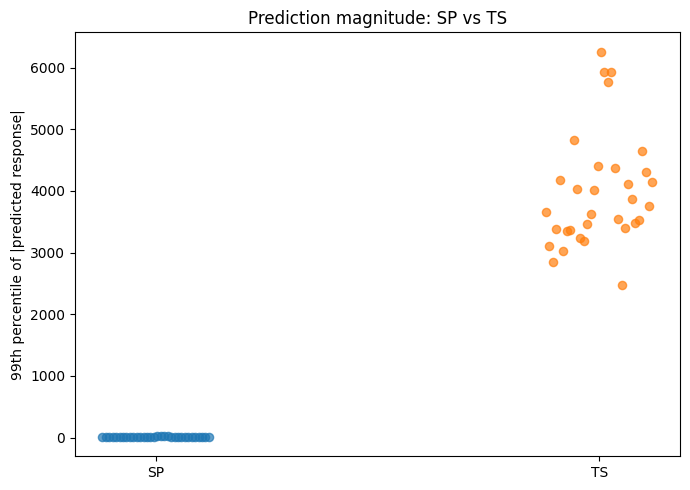

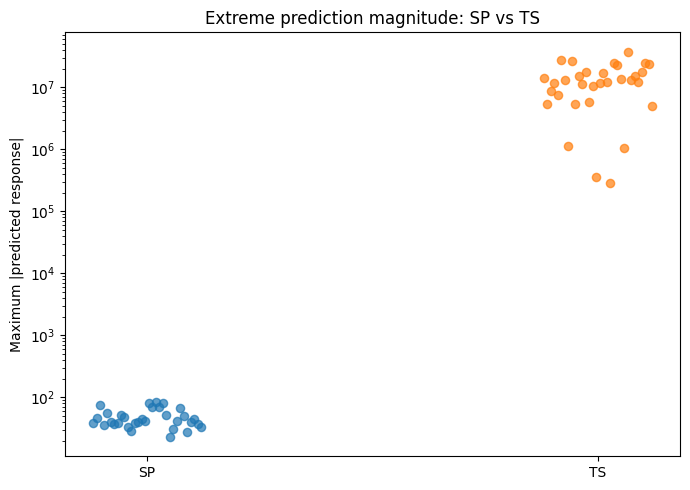

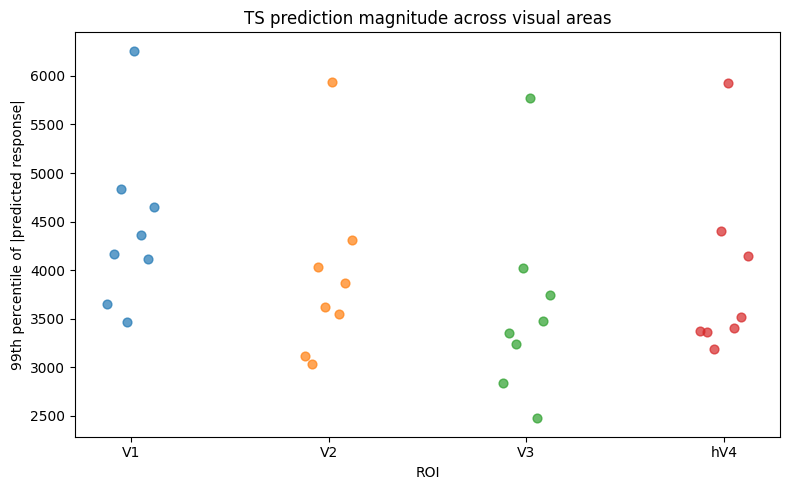


SAVED
/content/drive/MyDrive/V2_drift/texturemodel/drift_results/TS_vs_SP_prediction_magnitude/TS_vs_SP_prediction_magnitude_by_file.csv
/content/drive/MyDrive/V2_drift/texturemodel/drift_results/TS_vs_SP_prediction_magnitude/TS_vs_SP_prediction_magnitude_model_summary.csv

DONE.


In [3]:
# ============================================================
# TS vs SP — PREDICTION MAGNITUDE COMPARISON
#
# Compare the ACTUAL simulated predicted responses:
#
#       y_hat = X @ w + bias
#
# using the already-created population simulation files.
#
# NO regression is refit.
#
# Metrics:
#   - median |prediction|
#   - P95 |prediction|
#   - P99 |prediction|
#   - P99.9 |prediction|
#   - max |prediction|
#   - fraction |prediction| > 10
#   - fraction |prediction| > 100
#   - fraction |prediction| > 1000
#
# TS:
#   V2_drift/.../population_simulations/
#   sim_population_TS_pcaHL95_raw_S01_V1_Nimg100.npz
#
# SP:
#   V1_Drift/repDrift_expand/
#   simPopResp_v3_sub*.npz
#
# Both contain:
#   voxSessResp = voxel × session × image
# ============================================================

from google.colab import drive
drive.mount("/content/drive", force_remount=False)

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# ============================================================
# PATHS
# ============================================================

TS_DIR = Path(
    "/content/drive/MyDrive/V2_drift/texturemodel/drift_results/"
    "population_simulations"
)

SP_DIR = Path(
    "/content/drive/MyDrive/V1_Drift/repDrift_expand"
)

OUT_DIR = Path(
    "/content/drive/MyDrive/V2_drift/texturemodel/drift_results/"
    "TS_vs_SP_prediction_magnitude"
)

OUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)


SUBJECTS = range(1, 9)

ROIS = [
    "V1",
    "V2",
    "V3",
    "hV4",
]

# TS contains 30 sessions.
# Some SP files contain 31.
# For fair comparison use the same first 30.
N_SESSIONS_COMPARE = 30



# ============================================================
# FUNCTION:
# SUMMARIZE PREDICTION DISTRIBUTION
# ============================================================

def summarize_predictions(
    X,
    model,
    subject,
    roi=None,
    filename=None,
):

    X = np.asarray(
        X,
        dtype=np.float64
    )

    # --------------------------------------------------------
    # Expected:
    # voxel × session × image
    # --------------------------------------------------------

    if X.ndim != 3:

        raise ValueError(
            f"{model} S{subject:02d}: "
            f"expected 3D voxSessResp, got {X.shape}"
        )


    # --------------------------------------------------------
    # Match number of sessions
    # --------------------------------------------------------

    ns = min(
        N_SESSIONS_COMPARE,
        X.shape[1]
    )

    X = X[
        :,
        :ns,
        :
    ]


    finite_mask = np.isfinite(
        X
    )

    finite_pct = (
        finite_mask.mean()
        *
        100
    )


    vals = X[
        finite_mask
    ]


    if len(vals) == 0:

        raise RuntimeError(
            f"No finite predictions in {filename}"
        )


    abs_vals = np.abs(
        vals
    )


    return {

        "model":
            model,

        "subject":
            subject,

        "roi":
            roi,

        "filename":
            str(filename),

        "n_voxels":
            X.shape[0],

        "n_sessions":
            X.shape[1],

        "n_images":
            X.shape[2],

        "n_predictions":
            len(vals),

        "finite_pct":
            finite_pct,

        "min_prediction":
            np.min(vals),

        "max_prediction":
            np.max(vals),

        "median_abs_prediction":
            np.median(abs_vals),

        "p95_abs_prediction":
            np.percentile(
                abs_vals,
                95
            ),

        "p99_abs_prediction":
            np.percentile(
                abs_vals,
                99
            ),

        "p999_abs_prediction":
            np.percentile(
                abs_vals,
                99.9
            ),

        "max_abs_prediction":
            np.max(abs_vals),

        "fraction_abs_gt_10":
            np.mean(
                abs_vals > 10
            ),

        "fraction_abs_gt_100":
            np.mean(
                abs_vals > 100
            ),

        "fraction_abs_gt_1000":
            np.mean(
                abs_vals > 1000
            ),
    }


# ============================================================
# LOAD TS
# ============================================================

rows = []


print("\n" + "=" * 110)
print("LOADING TS")
print("=" * 110)


for subject in SUBJECTS:

    for roi in ROIS:

        fn = (
            TS_DIR
            /
            (
                f"sim_population_TS_pcaHL95_raw_"
                f"S{subject:02d}_{roi}_Nimg100.npz"
            )
        )


        if not fn.exists():

            print(
                f"MISSING TS: "
                f"S{subject:02d} {roi}"
            )

            continue


        d = np.load(
            fn,
            allow_pickle=True
        )


        X = d[
            "voxSessResp"
        ]


        row = summarize_predictions(
            X=X,
            model="TS",
            subject=subject,
            roi=roi,
            filename=fn,
        )


        rows.append(
            row
        )


        print(
            f"TS S{subject:02d} "
            f"{roi:4s} "
            f"{str(X.shape):20s} "
            f"P99={row['p99_abs_prediction']:.3f} "
            f"MAX={row['max_abs_prediction']:.3f}"
        )


# ============================================================
# LOAD SP — ALL SUBJECTS × ALL ROIs
#
# Files:
#   simPopResp_v1_sub1.npz
#   simPopResp_v2_sub1.npz
#   simPopResp_v3_sub1.npz
#   simPopResp_v4_sub1.npz
#   ...
#
# ROI mapping:
#   v1 -> V1
#   v2 -> V2
#   v3 -> V3
#   v4 -> hV4
# ============================================================

print("\n" + "=" * 110)
print("LOADING SP")
print("=" * 110)


SP_ROI_NAMES = {
    "V1": "v1",
    "V2": "v2",
    "V3": "v3",
    "hV4": "v4",
}


for subject in SUBJECTS:

    for roi in ROIS:

        sp_roi = SP_ROI_NAMES[roi]

        fn = (
            SP_DIR
            /
            f"simPopResp_{sp_roi}_sub{subject}.npz"
        )

        if not fn.exists():

            print(
                f"MISSING SP: "
                f"S{subject:02d} {roi} "
                f"({fn.name})"
            )

            continue


        d = np.load(
            fn,
            allow_pickle=True
        )


        if "voxSessResp" not in d.files:

            print(
                f"SP S{subject:02d} {roi}: "
                f"voxSessResp missing"
            )

            continue


        X = d[
            "voxSessResp"
        ]


        row = summarize_predictions(
            X=X,
            model="SP",
            subject=subject,
            roi=roi,
            filename=fn,
        )


        rows.append(
            row
        )


        print(
            f"SP S{subject:02d} "
            f"{roi:4s} "
            f"{str(X.shape):20s} "
            f"P99={row['p99_abs_prediction']:.3f} "
            f"MAX={row['max_abs_prediction']:.3f}"
        )
# ============================================================
# COMBINED TABLE
# ============================================================

summary_df = pd.DataFrame(
    rows
)


print("\n" + "=" * 110)
print("TS + SP PREDICTION SUMMARY")
print("=" * 110)


display(
    summary_df[
        [
            "model",
            "subject",
            "roi",
            "n_voxels",
            "n_sessions",
            "n_images",
            "finite_pct",
            "median_abs_prediction",
            "p95_abs_prediction",
            "p99_abs_prediction",
            "p999_abs_prediction",
            "max_abs_prediction",
            "fraction_abs_gt_10",
            "fraction_abs_gt_100",
            "fraction_abs_gt_1000",
        ]
    ]
)


# ============================================================
# MOST EXTREME FILES
# ============================================================

print("\n" + "=" * 110)
print("MOST EXTREME PREDICTION DISTRIBUTIONS")
print("=" * 110)


display(
    summary_df[
        [
            "model",
            "subject",
            "roi",
            "p99_abs_prediction",
            "p999_abs_prediction",
            "max_abs_prediction",
            "fraction_abs_gt_10",
            "fraction_abs_gt_100",
            "fraction_abs_gt_1000",
        ]
    ]
    .sort_values(
        "max_abs_prediction",
        ascending=False
    )
)


# ============================================================
# MODEL-LEVEL SUMMARY
# ============================================================

model_summary = (
    summary_df
    .groupby(
        "model"
    )
    .agg(

        n_files=(
            "subject",
            "size"
        ),

        median_of_median_abs=(
            "median_abs_prediction",
            "median"
        ),

        median_p95=(
            "p95_abs_prediction",
            "median"
        ),

        median_p99=(
            "p99_abs_prediction",
            "median"
        ),

        median_p999=(
            "p999_abs_prediction",
            "median"
        ),

        median_max_abs=(
            "max_abs_prediction",
            "median"
        ),

        largest_prediction=(
            "max_abs_prediction",
            "max"
        ),

        median_fraction_gt_10=(
            "fraction_abs_gt_10",
            "median"
        ),

        median_fraction_gt_100=(
            "fraction_abs_gt_100",
            "median"
        ),

        median_fraction_gt_1000=(
            "fraction_abs_gt_1000",
            "median"
        ),
    )
    .reset_index()
)


print("\n" + "=" * 110)
print("MODEL-LEVEL SUMMARY")
print("=" * 110)

display(
    model_summary
)

# ============================================================
# MATCHED TS vs SP — SUBJECT × ROI
# ============================================================

paired = summary_df.pivot(
    index=["subject", "roi"],
    columns="model",
    values=[
        "median_abs_prediction",
        "p95_abs_prediction",
        "p99_abs_prediction",
        "p999_abs_prediction",
        "max_abs_prediction",
        "fraction_abs_gt_10",
        "fraction_abs_gt_100",
        "fraction_abs_gt_1000",
    ]
)

paired = paired.dropna()

paired.columns = [
    f"{metric}_{model}"
    for metric, model in paired.columns
]

paired = paired.reset_index()

paired["ratio_p99_TS_over_SP"] = (
    paired["p99_abs_prediction_TS"]
    /
    paired["p99_abs_prediction_SP"]
)

paired["ratio_p999_TS_over_SP"] = (
    paired["p999_abs_prediction_TS"]
    /
    paired["p999_abs_prediction_SP"]
)

paired["ratio_max_TS_over_SP"] = (
    paired["max_abs_prediction_TS"]
    /
    paired["max_abs_prediction_SP"]
)

print("\n" + "=" * 110)
print("MATCHED TS vs SP — SUBJECT × ROI")
print("=" * 110)

display(
    paired[
        [
            "subject",
            "roi",
            "p99_abs_prediction_SP",
            "p99_abs_prediction_TS",
            "ratio_p99_TS_over_SP",
            "p999_abs_prediction_SP",
            "p999_abs_prediction_TS",
            "ratio_p999_TS_over_SP",
            "max_abs_prediction_SP",
            "max_abs_prediction_TS",
            "ratio_max_TS_over_SP",
        ]
    ]
    .sort_values(
        "ratio_max_TS_over_SP",
        ascending=False
    )
)

# ============================================================
# FIGURE 1
#
# P99 prediction magnitude
# ============================================================

plt.figure(
    figsize=(7, 5)
)


for model in [
    "SP",
    "TS",
]:

    tmp = summary_df[
        summary_df[
            "model"
        ]
        ==
        model
    ]

    x = np.full(
        len(tmp),
        0 if model == "SP" else 1,
        dtype=float
    )

    # small deterministic horizontal spread
    if len(tmp) > 1:

        jitter = np.linspace(
            -0.12,
            0.12,
            len(tmp)
        )

    else:

        jitter = np.zeros(
            len(tmp)
        )


    plt.scatter(
        x + jitter,
        tmp[
            "p99_abs_prediction"
        ],
        s=35,
        alpha=0.7
    )


plt.xticks(
    [0, 1],
    [
        "SP",
        "TS",
    ]
)

plt.ylabel(
    "99th percentile of |predicted response|"
)

plt.title(
    "Prediction magnitude: SP vs TS"
)

plt.tight_layout()

plt.show()


# ============================================================
# FIGURE 2
#
# Maximum prediction magnitude
#
# Log scale is useful because numerical explosions can span
# several orders of magnitude.
# ============================================================

plt.figure(
    figsize=(7, 5)
)


for model in [
    "SP",
    "TS",
]:

    tmp = summary_df[
        summary_df[
            "model"
        ]
        ==
        model
    ]


    x = np.full(
        len(tmp),
        0 if model == "SP" else 1,
        dtype=float
    )


    if len(tmp) > 1:

        jitter = np.linspace(
            -0.12,
            0.12,
            len(tmp)
        )

    else:

        jitter = np.zeros(
            len(tmp)
        )


    plt.scatter(
        x + jitter,
        tmp[
            "max_abs_prediction"
        ],
        s=35,
        alpha=0.7
    )


plt.xticks(
    [0, 1],
    [
        "SP",
        "TS",
    ]
)

plt.yscale(
    "log"
)

plt.ylabel(
    "Maximum |predicted response|"
)

plt.title(
    "Extreme prediction magnitude: SP vs TS"
)

plt.tight_layout()

plt.show()


# ============================================================
# FIGURE 3
#
# TS only — ROI comparison
# ============================================================

ts_df = summary_df[
    summary_df[
        "model"
    ]
    ==
    "TS"
].copy()


plt.figure(
    figsize=(8, 5)
)


for rr, roi in enumerate(
    ROIS
):

    tmp = ts_df[
        ts_df[
            "roi"
        ]
        ==
        roi
    ]


    if len(tmp) == 0:
        continue


    jitter = np.linspace(
        -0.12,
        0.12,
        len(tmp)
    )


    plt.scatter(
        rr + jitter,
        tmp[
            "p99_abs_prediction"
        ],
        s=40,
        alpha=0.7
    )


plt.xticks(
    range(
        len(ROIS)
    ),
    ROIS
)

plt.ylabel(
    "99th percentile of |predicted response|"
)

plt.xlabel(
    "ROI"
)

plt.title(
    "TS prediction magnitude across visual areas"
)

plt.tight_layout()

plt.show()


# ============================================================
# SAVE
# ============================================================

summary_file = (
    OUT_DIR
    /
    "TS_vs_SP_prediction_magnitude_by_file.csv"
)

model_file = (
    OUT_DIR
    /
    "TS_vs_SP_prediction_magnitude_model_summary.csv"
)


summary_df.to_csv(
    summary_file,
    index=False
)

model_summary.to_csv(
    model_file,
    index=False
)


print("\n" + "=" * 110)
print("SAVED")
print("=" * 110)

print(summary_file)
print(model_file)

print("\nDONE.")

In [7]:
# ============================================================
# DIRECT TEST:
# DOES TS LOAD THE SAME BETA VALUES AS SP?
#
# Compare:
#
# A) direct NIfTI loading used by SP
# B) nsd_utils loading used by TS
#
# SAME:
#   subject
#   session
#   ROI
#
# No regression is run.
# ============================================================

from google.colab import drive
drive.mount("/content/drive", force_remount=False)

import os
import sys
import nibabel as nib
import numpy as np

from pathlib import Path


# ============================================================
# PATHS
# ============================================================

ROOT = Path(
    "/content/drive/MyDrive/V2_drift"
)

NSD_BASE = Path(
    "/content/drive/MyDrive/V1_Drift/NSD"
)

CODE_ROOT = (
    ROOT
    / "texturemodel"
    / "code"
)

for p in [
    ROOT / "texturemodel",
    CODE_ROOT,
    CODE_ROOT / "utils",
    CODE_ROOT / "model_fitting",
]:
    p = str(p)

    if p not in sys.path:
        sys.path.insert(0, p)


from utils import nsd_utils


# ============================================================
# CONFIG
# ============================================================

SUBJECT = 1
SESSION = 1

# V1 = visualroi labels 1 and 2
ROI_LABELS = [
    1,
    2
]


# ============================================================
# LOAD VISUAL ROI
# ============================================================

roi_file = (
    NSD_BASE
    / f"subj{SUBJECT:02d}"
    / "func1pt8mm"
    / "roi"
    / "prf-visualrois.nii.gz"
)

roi_data = (
    nib.load(
        roi_file
    )
    .get_fdata()
)


roi_mask_3d = np.isin(
    roi_data,
    ROI_LABELS
)

roi_mask_flat = (
    roi_mask_3d
    .reshape(-1)
)


print("=" * 100)
print("ROI")
print("=" * 100)

print(
    "ROI voxels:",
    np.sum(
        roi_mask_flat
    )
)


# ============================================================
# A) LOAD EXACTLY LIKE SP
# ============================================================

beta_file = (
    NSD_BASE
    / f"subj{SUBJECT:02d}"
    / "betas"
    / f"betas_session{SESSION:02d}.nii.gz"
)


beta_nii = (
    nib.load(
        beta_file
    )
    .get_fdata()
)


print("\n" + "=" * 100)
print("DIRECT NIFTI — SP STYLE")
print("=" * 100)

print(
    "Raw NIfTI shape:",
    beta_nii.shape
)


# Your NIfTI:
# trial × X × Y × Z
#
# flatten spatial dimensions
# ============================================================
# SP-style beta matrix
#
# NIfTI shape:
#   X × Y × Z × trials
#
# We want:
#   trials × voxels
# ============================================================

beta_sp = (
    beta_nii
    .reshape(
        -1,
        beta_nii.shape[-1]
    )
    [roi_mask_flat, :]
    .T
)

print(
    "SP beta matrix:",
    beta_sp.shape
)



print(
    "SP min/max:",
    np.nanmin(beta_sp),
    np.nanmax(beta_sp)
)

print(
    "SP median |beta|:",
    np.nanmedian(
        np.abs(
            beta_sp
        )
    )
)

print(
    "SP P99 |beta|:",
    np.nanpercentile(
        np.abs(
            beta_sp
        ),
        99
    )
)


# ============================================================
# B) LOAD EXACTLY LIKE TS
# ============================================================

(
    beta_ts,
    image_order,
    val_inds,
    holdout_inds,
    session_inds,
) = nsd_utils.get_data_splits_single_train(

    SUBJECT,

    sessions=np.asarray(
        [
            SESSION - 1
        ],
        dtype=int
    ),

    voxel_mask=roi_mask_flat,

    volume_space="func1pt8mm",

    zscore_betas_within_sess=False,

    shuffle_images=False,

    average_image_reps=False,

    random_voxel_data=False,
)


beta_ts = np.asarray(
    beta_ts,
    dtype=np.float64
)


print("\n" + "=" * 100)
print("NSD_UTILS — TS STYLE")
print("=" * 100)

print(
    "TS beta matrix:",
    beta_ts.shape
)

print(
    "TS min/max:",
    np.nanmin(beta_ts),
    np.nanmax(beta_ts)
)

print(
    "TS median |beta|:",
    np.nanmedian(
        np.abs(
            beta_ts
        )
    )
)

print(
    "TS P99 |beta|:",
    np.nanpercentile(
        np.abs(
            beta_ts
        ),
        99
    )
)


# ============================================================
# SHAPE CHECK
# ============================================================

print("\n" + "=" * 100)
print("DIRECT COMPARISON")
print("=" * 100)

print(
    "SP shape:",
    beta_sp.shape
)

print(
    "TS shape:",
    beta_ts.shape
)


if beta_sp.shape != beta_ts.shape:

    print(
        "\nWARNING:"
        "\nThe two loaders returned different shapes."
        "\nDo not compare element-wise yet."
    )

else:

    # --------------------------------------------------------
    # Ratio only where denominator is safely nonzero
    # --------------------------------------------------------

    good = (
        np.isfinite(
            beta_sp
        )
        &
        np.isfinite(
            beta_ts
        )
        &
        (
            np.abs(
                beta_sp
            )
            >
            1e-8
        )
    )


    ratio = (
        beta_ts[
            good
        ]
        /
        beta_sp[
            good
        ]
    )


    print(
        "Median TS / SP beta ratio:",
        np.nanmedian(
            ratio
        )
    )

    print(
        "P1 ratio:",
        np.nanpercentile(
            ratio,
            1
        )
    )

    print(
        "P99 ratio:",
        np.nanpercentile(
            ratio,
            99
        )
    )


    # --------------------------------------------------------
    # Correlation
    # --------------------------------------------------------

    x = beta_sp[
        good
    ].reshape(-1)

    y = beta_ts[
        good
    ].reshape(-1)


    corr = np.corrcoef(
        x,
        y
    )[0, 1]


    print(
        "Element-wise Pearson correlation:",
        corr
    )


    # --------------------------------------------------------
    # Fit simple scaling:
    #
    # TS ≈ a * SP + b
    # --------------------------------------------------------

    A = np.column_stack(
        [
            x,
            np.ones_like(
                x
            )
        ]
    )


    scale, intercept = np.linalg.lstsq(
        A,
        y,
        rcond=None
    )[0]


    print(
        "Best linear mapping:"
    )

    print(
        f"TS ≈ {scale:.8f} × SP "
        f"+ {intercept:.8f}"
    )


    # --------------------------------------------------------
    # Difference after mapping
    # --------------------------------------------------------

    y_pred = (
        scale
        *
        x
        +
        intercept
    )


    residual = (
        y
        -
        y_pred
    )


    print(
        "Residual SD after linear mapping:",
        np.std(
            residual
        )
    )

    print(
        "Maximum |residual|:",
        np.max(
            np.abs(
                residual
            )
        )
    )

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
ROI
ROI voxels: 1350

DIRECT NIFTI — SP STYLE
Raw NIfTI shape: (81, 104, 83, 750)
SP beta matrix: (750, 1350)
SP min/max: -9919.0 24461.0
SP median |beta|: 534.0
SP P99 |beta|: 4327.0
Loading data for sessions:
[1]
Data is located in: /content/drive/MyDrive/V1_Drift/NSD/subj01/betas...
Loading from /content/drive/MyDrive/V1_Drift/NSD/subj01/betas/betas_session01.nii.gz...
Raw data:
float64 -32768.0 32767.0 (750, 81, 104, 83)
Done!

Size of full data set [n_trials x n_voxels] is:
(750, 1350)

NSD_UTILS — TS STYLE
TS beta matrix: (750, 1350)
TS min/max: -9919.0 24461.0
TS median |beta|: 534.0
TS P99 |beta|: 4327.0

DIRECT COMPARISON
SP shape: (750, 1350)
TS shape: (750, 1350)
Median TS / SP beta ratio: 1.0
P1 ratio: 1.0
P99 ratio: 1.0
Element-wise Pearson correlation: 1.0
Best linear mapping:
TS ≈ 1.00000000 × SP + 0.00000000
Residual SD after linear mapping: 2

# After scaling *300

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
LOADING TS
TS S01 V1   P99=3651.6 P99.9=6463.7 MAX=14056076.0
TS S01 V2   P99=3113.1 P99.9=6086.0 MAX=5324562.0
TS S01 V3   P99=2842.0 P99.9=6447.6 MAX=8781772.0
TS S01 hV4  P99=3374.8 P99.9=6251.2 MAX=11677833.0
TS S02 V1   P99=4170.3 P99.9=7828.9 MAX=7562843.0
TS S02 V2   P99=3031.9 P99.9=5695.1 MAX=27445688.0
TS S02 V3   P99=3353.5 P99.9=5508.5 MAX=13279052.0
TS S02 hV4  P99=3366.7 P99.9=4963.0 MAX=1142673.2
TS S03 V1   P99=4831.7 P99.9=9595.0 MAX=26289120.0
TS S03 V2   P99=4035.6 P99.9=7812.7 MAX=5491941.5
TS S03 V3   P99=3240.3 P99.9=5459.1 MAX=15466524.0
TS S03 hV4  P99=3184.1 P99.9=5724.9 MAX=11294406.0
TS S04 V1   P99=3466.9 P99.9=6681.2 MAX=17910148.0
TS S04 V2   P99=3619.1 P99.9=6389.6 MAX=5766561.0
TS S04 V3   P99=4017.5 P99.9=6676.3 MAX=10456247.0
TS S04 hV4  P99=4404.1 P99.9=7509.7 MAX=357232.8
TS S05 V1   P99=6259.8 P99.9=13270.0 MAX=11601439.0


,model,subject,roi,n_voxels,median_abs_prediction,p95_abs_prediction,p99_abs_prediction,p999_abs_prediction,p9999_abs_prediction,max_abs_prediction,fraction_abs_gt_1e4,fraction_abs_gt_1e5,fraction_abs_gt_1e6,fraction_abs_gt_1e7
0,TS,1,V1,1350,508.961212,2107.922998,3651.575781,6463.718819,381800.020304,1.405608e+07,0.000543,0.000192,0.000059,1.234568e-06
1,TS,1,V2,1433,415.596268,1658.911389,3113.079880,6086.049900,66569.377683,5.324562e+06,0.000250,0.000090,0.000017,0.000000e+00
2,TS,1,V3,1187,419.214325,1647.693060,2842.048916,6447.629018,128592.233088,8.781772e+06,0.000424,0.000109,0.000038,0.000000e+00
3,TS,1,hV4,687,448.296265,1719.736224,3374.809465,6251.248292,8884.271260,1.167783e+07,0.000053,0.000020,0.000008,4.852014e-07
4,TS,2,V1,1102,564.945282,2437.923523,4170.263281,7828.892179,444899.098619,7.562843e+06,0.000650,0.000183,0.000057,0.000000e+00
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
59,SP,7,hV4,397,578.325051,2117.884977,3337.622955,4799.947862,5921.449853,8.245970e+03,0.000000,0.000000,0.000000,0.000000e+00
60,SP,8,V1,1074,684.979177,2746.138630,4270.600142,6250.510727,8213.974779,1.187459e+04,0.000007,0.000000,0.000000,0.000000e+00
61,SP,8,V2,1033,615.653837,2254.358690,3979.424644,6970.185772,9355.913089,1.350800e+04,0.000055,0.000000,0.000000,0.000000e+00
62,SP,8,V3,889,538.772589,2188.419642,3498.576084,5431.264177,7243.702369,1.121657e+04,0.000001,0.000000,0.000000,0.000000e+00



MATCHED TS / SP RATIOS AFTER ×300 CORRECTION


,subject,roi,median_abs_prediction_SP,median_abs_prediction_TS,ratio_median_abs_prediction_TS_over_SP,p99_abs_prediction_SP,p99_abs_prediction_TS,ratio_p99_abs_prediction_TS_over_SP,p999_abs_prediction_SP,p999_abs_prediction_TS,ratio_p999_abs_prediction_TS_over_SP,max_abs_prediction_SP,max_abs_prediction_TS,ratio_max_abs_prediction_TS_over_SP
24,7,V1,651.026845,638.792084,0.981207,3877.862646,4110.090498,1.059886,6314.843772,9966.659340,1.578291,12599.372864,3.776199e+07,2997.132350
5,2,V2,424.495697,428.302795,1.008969,2873.397574,3031.946938,1.055178,4413.981284,5695.050790,1.290230,11950.082016,2.744569e+07,2296.694530
30,8,V3,538.772589,549.045807,1.019068,3498.576084,3748.458801,1.071424,5431.264177,6312.369337,1.162228,11216.566086,2.410717e+07,2149.246732
22,6,V3,384.153235,375.545044,0.977592,2399.249584,2473.378257,1.030897,3510.979674,4041.294015,1.151045,6864.115334,1.382491e+07,2014.084893
29,8,V2,615.653837,632.807190,1.027862,3979.424644,4305.092070,1.081838,6970.185772,8192.348317,1.175341,13508.002853,2.433997e+07,1801.892424
8,3,V1,798.535323,771.772552,0.966485,4582.306140,4831.742188,1.054435,7147.694301,9594.959880,1.342385,15349.913406,2.628912e+07,1712.655916
12,4,V1,601.417959,593.133209,0.986225,3363.336519,3466.930015,1.030801,5082.829814,6681.157545,1.314456,11388.331604,1.791015e+07,1572.675316
10,3,V3,568.835825,561.987274,0.987960,3180.520214,3240.349119,1.018811,5083.145930,5459.079713,1.073957,9896.134186,1.546652e+07,1562.885437
21,6,V2,515.431559,505.274246,0.980294,3468.463489,3547.513921,1.022791,6511.714185,7293.072704,1.119993,15696.101761,2.335871e+07,1488.185688
27,7,hV4,578.325051,581.231110,1.005025,3337.622955,3521.646392,1.055136,4799.947862,5590.648460,1.164731,8245.969963,1.222728e+07,1482.818402



MODEL-LEVEL SUMMARY — SAME UNITS


,model,n_files,median_prediction,median_p95,median_p99,median_p999,median_p9999,median_max,largest_prediction,median_fraction_gt_1e4,median_fraction_gt_1e5,median_fraction_gt_1e6
0,SP,32,580.529684,2171.795604,3496.650061,5843.328334,8185.555286,1.249826e+04,2.549553e+04,0.000011,0.000000,0.000000
1,TS,32,572.311035,2211.475873,3700.017291,6701.373876,372772.142929,1.275253e+07,3.776199e+07,0.000436,0.000161,0.000057


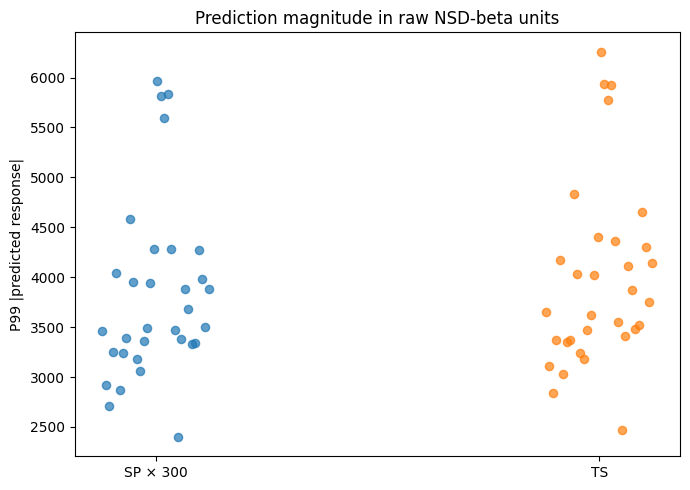

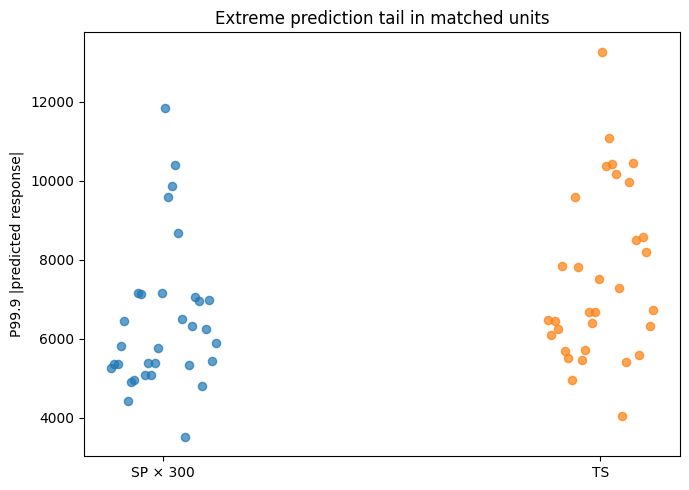

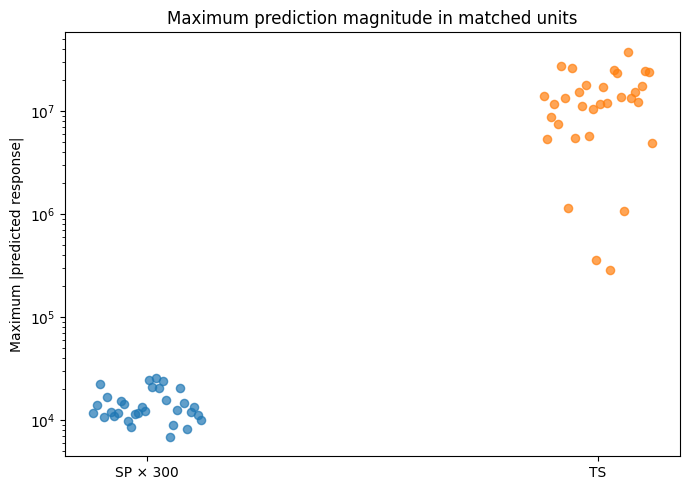

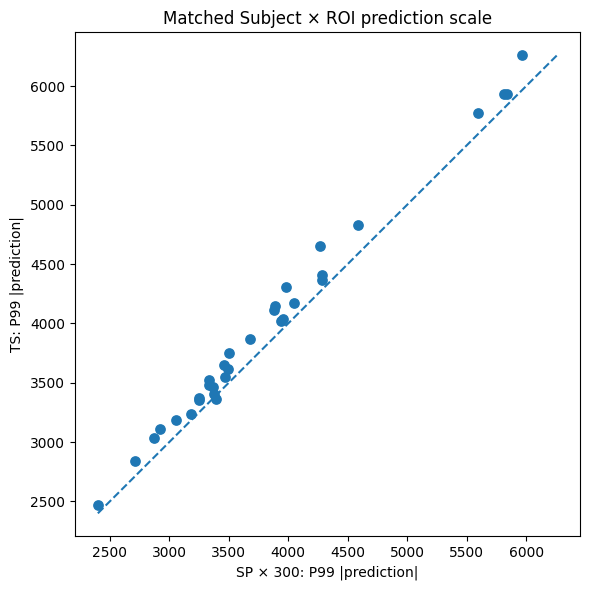


SAVED
/content/drive/MyDrive/V2_drift/texturemodel/drift_results/TS_vs_SP_prediction_magnitude_same_units/TS_vs_SP_same_units_summary.csv
/content/drive/MyDrive/V2_drift/texturemodel/drift_results/TS_vs_SP_prediction_magnitude_same_units/TS_vs_SP_same_units_matched.csv
/content/drive/MyDrive/V2_drift/texturemodel/drift_results/TS_vs_SP_prediction_magnitude_same_units/TS_vs_SP_same_units_model_summary.csv

DONE.


In [8]:
# ============================================================
# TS vs SP PREDICTION MAGNITUDE
# AFTER CORRECTING SP BACK TO RAW NSD BETA UNITS
#
# SP fitting used:
#
#     beta_SP = beta_raw / 300
#
# Therefore:
#
#     prediction_SP_raw_units = prediction_SP * 300
#
# This cell compares:
#
#     TS predictions
#     SP predictions × 300
#
# on the SAME raw NSD-beta scale.
#
# NO REGRESSION IS RUN.
# ============================================================

from google.colab import drive
drive.mount("/content/drive", force_remount=False)

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# ============================================================
# PATHS
# ============================================================

TS_DIR = Path(
    "/content/drive/MyDrive/V2_drift/texturemodel/drift_results/"
    "population_simulations"
)

SP_DIR = Path(
    "/content/drive/MyDrive/V1_Drift/repDrift_expand"
)

OUT_DIR = Path(
    "/content/drive/MyDrive/V2_drift/texturemodel/drift_results/"
    "TS_vs_SP_prediction_magnitude_same_units"
)

OUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)


# ============================================================
# CONFIG
# ============================================================

SUBJECTS = range(1, 9)

ROIS = [
    "V1",
    "V2",
    "V3",
    "hV4",
]

SP_ROI_NAMES = {
    "V1": "v1",
    "V2": "v2",
    "V3": "v3",
    "hV4": "v4",
}

N_SESSIONS_COMPARE = 30

# SP regression divided betas by 300.
# Bring predictions back to raw NSD beta units.
SP_SCALE_TO_RAW = 300.0


# ============================================================
# SUMMARY FUNCTION
# ============================================================

def summarize_predictions(
    X,
    model,
    subject,
    roi,
    scale_factor=1.0,
    filename=None,
):

    X = np.asarray(
        X,
        dtype=np.float64
    )

    if X.ndim != 3:

        raise ValueError(
            f"{model} S{subject:02d} {roi}: "
            f"expected [voxel, session, image], got {X.shape}"
        )


    # --------------------------------------------------------
    # Match sessions
    # --------------------------------------------------------

    ns = min(
        N_SESSIONS_COMPARE,
        X.shape[1]
    )

    X = X[
        :,
        :ns,
        :
    ]


    # --------------------------------------------------------
    # Put into raw NSD beta units
    # --------------------------------------------------------

    X = (
        X
        *
        scale_factor
    )


    finite_mask = np.isfinite(
        X
    )

    vals = X[
        finite_mask
    ]


    if len(vals) == 0:

        raise RuntimeError(
            f"No finite predictions in {filename}"
        )


    abs_vals = np.abs(
        vals
    )


    return {

        "model":
            model,

        "subject":
            subject,

        "roi":
            roi,

        "filename":
            str(filename),

        "scale_factor_applied":
            scale_factor,

        "n_voxels":
            X.shape[0],

        "n_sessions":
            X.shape[1],

        "n_images":
            X.shape[2],

        "finite_pct":
            finite_mask.mean() * 100,

        "min_prediction":
            np.min(vals),

        "max_prediction":
            np.max(vals),

        "median_abs_prediction":
            np.median(abs_vals),

        "p95_abs_prediction":
            np.percentile(
                abs_vals,
                95
            ),

        "p99_abs_prediction":
            np.percentile(
                abs_vals,
                99
            ),

        "p999_abs_prediction":
            np.percentile(
                abs_vals,
                99.9
            ),

        "p9999_abs_prediction":
            np.percentile(
                abs_vals,
                99.99
            ),

        "max_abs_prediction":
            np.max(abs_vals),

        "fraction_abs_gt_1e4":
            np.mean(
                abs_vals > 1e4
            ),

        "fraction_abs_gt_1e5":
            np.mean(
                abs_vals > 1e5
            ),

        "fraction_abs_gt_1e6":
            np.mean(
                abs_vals > 1e6
            ),

        "fraction_abs_gt_1e7":
            np.mean(
                abs_vals > 1e7
            ),
    }


# ============================================================
# LOAD BOTH MODELS
# ============================================================

rows = []


# ============================================================
# TS
#
# Already in raw NSD-beta units.
# ============================================================

print("=" * 110)
print("LOADING TS")
print("=" * 110)


for subject in SUBJECTS:

    for roi in ROIS:

        fn = (
            TS_DIR
            /
            (
                f"sim_population_TS_pcaHL95_raw_"
                f"S{subject:02d}_{roi}_Nimg100.npz"
            )
        )


        if not fn.exists():

            print(
                f"MISSING TS: "
                f"S{subject:02d} {roi}"
            )

            continue


        d = np.load(
            fn,
            allow_pickle=True
        )


        X = d[
            "voxSessResp"
        ]


        row = summarize_predictions(

            X=X,

            model="TS",

            subject=subject,

            roi=roi,

            scale_factor=1.0,

            filename=fn,
        )


        rows.append(
            row
        )


        print(
            f"TS S{subject:02d} {roi:4s} "
            f"P99={row['p99_abs_prediction']:.1f} "
            f"P99.9={row['p999_abs_prediction']:.1f} "
            f"MAX={row['max_abs_prediction']:.1f}"
        )


# ============================================================
# SP
#
# Multiply by 300 to return to raw NSD-beta units.
# ============================================================

print("\n" + "=" * 110)
print("LOADING SP × 300")
print("=" * 110)


for subject in SUBJECTS:

    for roi in ROIS:

        sp_roi = SP_ROI_NAMES[
            roi
        ]


        fn = (
            SP_DIR
            /
            f"simPopResp_{sp_roi}_sub{subject}.npz"
        )


        if not fn.exists():

            print(
                f"MISSING SP: "
                f"S{subject:02d} {roi}"
            )

            continue


        d = np.load(
            fn,
            allow_pickle=True
        )


        X = d[
            "voxSessResp"
        ]


        row = summarize_predictions(

            X=X,

            model="SP",

            subject=subject,

            roi=roi,

            scale_factor=SP_SCALE_TO_RAW,

            filename=fn,
        )


        rows.append(
            row
        )


        print(
            f"SP S{subject:02d} {roi:4s} "
            f"P99={row['p99_abs_prediction']:.1f} "
            f"P99.9={row['p999_abs_prediction']:.1f} "
            f"MAX={row['max_abs_prediction']:.1f}"
        )


# ============================================================
# COMBINED TABLE
# ============================================================

summary_df = pd.DataFrame(
    rows
)


print("\n" + "=" * 110)
print("TS vs SP — SAME RAW NSD-BETA UNITS")
print("=" * 110)


display(
    summary_df[
        [
            "model",
            "subject",
            "roi",
            "n_voxels",
            "median_abs_prediction",
            "p95_abs_prediction",
            "p99_abs_prediction",
            "p999_abs_prediction",
            "p9999_abs_prediction",
            "max_abs_prediction",
            "fraction_abs_gt_1e4",
            "fraction_abs_gt_1e5",
            "fraction_abs_gt_1e6",
            "fraction_abs_gt_1e7",
        ]
    ]
)


# ============================================================
# MATCHED SUBJECT × ROI
# ============================================================

paired = summary_df.pivot(

    index=[
        "subject",
        "roi"
    ],

    columns="model",

    values=[

        "median_abs_prediction",

        "p95_abs_prediction",

        "p99_abs_prediction",

        "p999_abs_prediction",

        "p9999_abs_prediction",

        "max_abs_prediction",

        "fraction_abs_gt_1e4",

        "fraction_abs_gt_1e5",

        "fraction_abs_gt_1e6",
    ]
)


paired = paired.dropna()


paired.columns = [

    f"{metric}_{model}"

    for metric, model
    in paired.columns
]


paired = paired.reset_index()


# ============================================================
# TS / SP RATIOS AFTER UNIT CORRECTION
# ============================================================

for metric in [

    "median_abs_prediction",

    "p95_abs_prediction",

    "p99_abs_prediction",

    "p999_abs_prediction",

    "p9999_abs_prediction",

    "max_abs_prediction",
]:

    paired[
        f"ratio_{metric}_TS_over_SP"
    ] = (

        paired[
            f"{metric}_TS"
        ]

        /

        paired[
            f"{metric}_SP"
        ]
    )


print("\n" + "=" * 110)
print("MATCHED TS / SP RATIOS AFTER ×300 CORRECTION")
print("=" * 110)


display(

    paired[
        [

            "subject",

            "roi",

            "median_abs_prediction_SP",

            "median_abs_prediction_TS",

            "ratio_median_abs_prediction_TS_over_SP",

            "p99_abs_prediction_SP",

            "p99_abs_prediction_TS",

            "ratio_p99_abs_prediction_TS_over_SP",

            "p999_abs_prediction_SP",

            "p999_abs_prediction_TS",

            "ratio_p999_abs_prediction_TS_over_SP",

            "max_abs_prediction_SP",

            "max_abs_prediction_TS",

            "ratio_max_abs_prediction_TS_over_SP",
        ]
    ]
    .sort_values(
        "ratio_max_abs_prediction_TS_over_SP",
        ascending=False
    )
)


# ============================================================
# MODEL SUMMARY
# ============================================================

model_summary = (
    summary_df
    .groupby(
        "model"
    )
    .agg(

        n_files=(
            "subject",
            "size"
        ),

        median_prediction=(
            "median_abs_prediction",
            "median"
        ),

        median_p95=(
            "p95_abs_prediction",
            "median"
        ),

        median_p99=(
            "p99_abs_prediction",
            "median"
        ),

        median_p999=(
            "p999_abs_prediction",
            "median"
        ),

        median_p9999=(
            "p9999_abs_prediction",
            "median"
        ),

        median_max=(
            "max_abs_prediction",
            "median"
        ),

        largest_prediction=(
            "max_abs_prediction",
            "max"
        ),

        median_fraction_gt_1e4=(
            "fraction_abs_gt_1e4",
            "median"
        ),

        median_fraction_gt_1e5=(
            "fraction_abs_gt_1e5",
            "median"
        ),

        median_fraction_gt_1e6=(
            "fraction_abs_gt_1e6",
            "median"
        ),
    )
    .reset_index()
)


print("\n" + "=" * 110)
print("MODEL-LEVEL SUMMARY — SAME UNITS")
print("=" * 110)


display(
    model_summary
)


# ============================================================
# FIGURE 1
#
# P99: bulk/tail comparison
# ============================================================

plt.figure(
    figsize=(
        7,
        5
    )
)


for model, xpos in [

    ("SP", 0),

    ("TS", 1),
]:

    tmp = summary_df[
        summary_df[
            "model"
        ]
        ==
        model
    ]


    jitter = np.linspace(
        -0.12,
        0.12,
        len(tmp)
    )


    plt.scatter(

        xpos + jitter,

        tmp[
            "p99_abs_prediction"
        ],

        s=35,

        alpha=0.7
    )


plt.xticks(
    [
        0,
        1
    ],
    [
        "SP × 300",
        "TS"
    ]
)


plt.ylabel(
    "P99 |predicted response|"
)

plt.title(
    "Prediction magnitude in raw NSD-beta units"
)

plt.tight_layout()

plt.show()


# ============================================================
# FIGURE 2
#
# P99.9
# ============================================================

plt.figure(
    figsize=(
        7,
        5
    )
)


for model, xpos in [

    ("SP", 0),

    ("TS", 1),
]:

    tmp = summary_df[
        summary_df[
            "model"
        ]
        ==
        model
    ]


    jitter = np.linspace(
        -0.12,
        0.12,
        len(tmp)
    )


    plt.scatter(

        xpos + jitter,

        tmp[
            "p999_abs_prediction"
        ],

        s=35,

        alpha=0.7
    )


plt.xticks(
    [
        0,
        1
    ],
    [
        "SP × 300",
        "TS"
    ]
)


plt.ylabel(
    "P99.9 |predicted response|"
)

plt.title(
    "Extreme prediction tail in matched units"
)

plt.tight_layout()

plt.show()


# ============================================================
# FIGURE 3
#
# Maximum predictions — log scale
# ============================================================

plt.figure(
    figsize=(
        7,
        5
    )
)


for model, xpos in [

    ("SP", 0),

    ("TS", 1),
]:

    tmp = summary_df[
        summary_df[
            "model"
        ]
        ==
        model
    ]


    jitter = np.linspace(
        -0.12,
        0.12,
        len(tmp)
    )


    plt.scatter(

        xpos + jitter,

        tmp[
            "max_abs_prediction"
        ],

        s=35,

        alpha=0.7
    )


plt.xticks(
    [
        0,
        1
    ],
    [
        "SP × 300",
        "TS"
    ]
)


plt.yscale(
    "log"
)


plt.ylabel(
    "Maximum |predicted response|"
)

plt.title(
    "Maximum prediction magnitude in matched units"
)

plt.tight_layout()

plt.show()


# ============================================================
# FIGURE 4
#
# Matched P99 — SP vs TS
#
# Identity line:
# points near line = same prediction scale
# ============================================================

x = paired[
    "p99_abs_prediction_SP"
].to_numpy(
    dtype=float
)

y = paired[
    "p99_abs_prediction_TS"
].to_numpy(
    dtype=float
)


plt.figure(
    figsize=(
        6,
        6
    )
)


plt.scatter(
    x,
    y,
    s=45
)


lo = min(
    np.min(x),
    np.min(y)
)

hi = max(
    np.max(x),
    np.max(y)
)


plt.plot(
    [
        lo,
        hi
    ],
    [
        lo,
        hi
    ],
    linestyle="--"
)


plt.xlabel(
    "SP × 300: P99 |prediction|"
)

plt.ylabel(
    "TS: P99 |prediction|"
)

plt.title(
    "Matched Subject × ROI prediction scale"
)

plt.tight_layout()

plt.show()


# ============================================================
# SAVE
# ============================================================

summary_file = (
    OUT_DIR
    /
    "TS_vs_SP_same_units_summary.csv"
)

paired_file = (
    OUT_DIR
    /
    "TS_vs_SP_same_units_matched.csv"
)

model_file = (
    OUT_DIR
    /
    "TS_vs_SP_same_units_model_summary.csv"
)


summary_df.to_csv(
    summary_file,
    index=False
)

paired.to_csv(
    paired_file,
    index=False
)

model_summary.to_csv(
    model_file,
    index=False
)


print("\n" + "=" * 110)
print("SAVED")
print("=" * 110)

print(
    summary_file
)

print(
    paired_file
)

print(
    model_file
)

print(
    "\nDONE."
)

VOXEL-WISE PREDICTION TABLE
Rows: 59123


,model,subject,roi,voxel,median_abs_prediction,p95_abs_prediction,p99_abs_prediction,p999_abs_prediction,max_abs_prediction,fraction_gt_1e4,fraction_gt_1e5,fraction_gt_1e6
0,TS,1,V1,0,117.989178,352.715118,484.319427,669.572276,906.707581,0.0,0.0,0.0
1,TS,1,V1,1,86.644268,270.701352,368.346317,462.568336,529.376343,0.0,0.0,0.0
2,TS,1,V1,2,91.405933,252.926185,326.939834,444.100794,508.132721,0.0,0.0,0.0
3,TS,1,V1,3,95.349312,278.818892,395.276496,499.443219,767.124817,0.0,0.0,0.0
4,TS,1,V1,4,217.892464,433.412448,537.090991,722.916581,976.994385,0.0,0.0,0.0



VOXEL DISTRIBUTION SUMMARY


,model,n_voxels,median_voxel_max,p90_voxel_max,p95_voxel_max,p99_voxel_max,largest_voxel_max
0,SP,29574,1397.879505,3521.593037,4749.406343,8.003031e+03,2.549553e+04
1,TS,29549,2367.656738,11344.234375,28899.917187,3.746383e+06,3.776199e+07



FRACTION OF VOXELS WITH AT LEAST ONE EXTREME PREDICTION


,model,threshold,n_voxels_with_at_least_one_prediction_above_threshold,fraction_voxels
0,SP,10000.0,127,0.004294
1,SP,100000.0,0,0.000000
2,SP,1000000.0,0,0.000000
3,SP,10000000.0,0,0.000000
4,TS,10000.0,3318,0.112288
5,TS,100000.0,906,0.030661
6,TS,1000000.0,544,0.018410
7,TS,10000000.0,66,0.002234


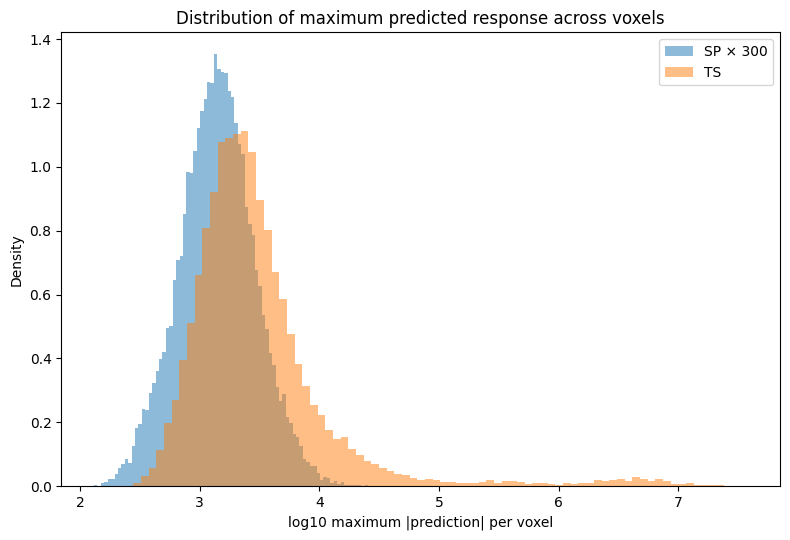

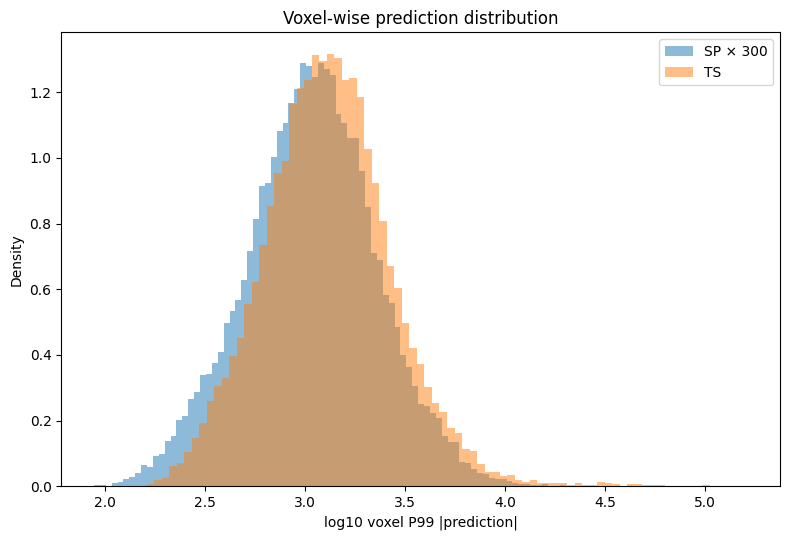

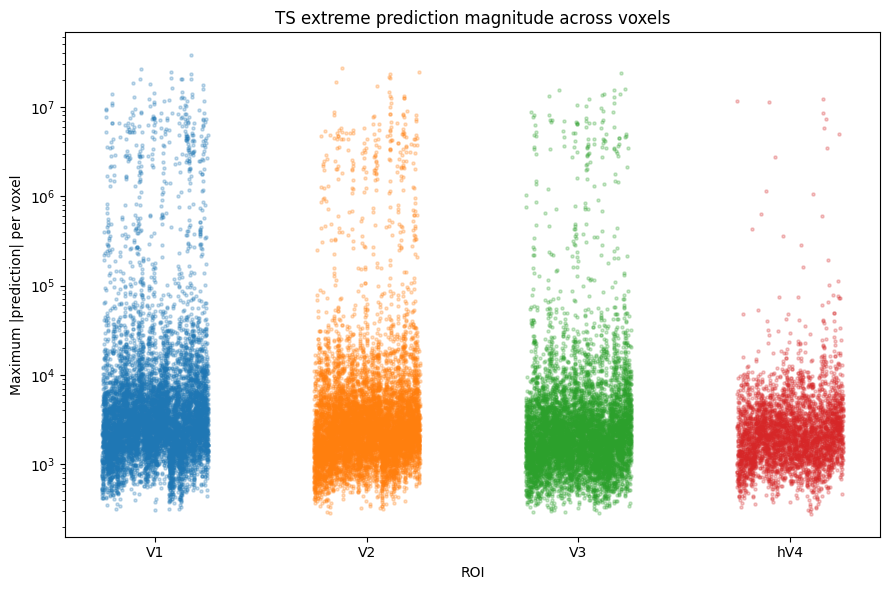

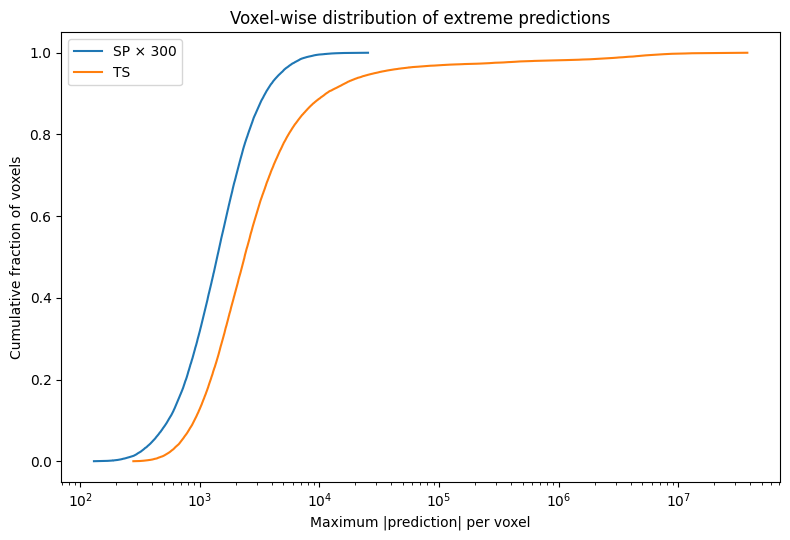


TOP 100 TS VOXELS


,model,subject,roi,voxel,median_abs_prediction,p95_abs_prediction,p99_abs_prediction,p999_abs_prediction,max_abs_prediction,fraction_gt_1e4,fraction_gt_1e5,fraction_gt_1e6
46367,TS,7,V1,728,1987.211182,3704.128333,124858.254297,1.978357e+07,37761988.0,0.019000,0.010667,0.008333
12441,TS,2,V2,923,2456.260376,6481.134424,11638.323994,1.084299e+07,27445688.0,0.011000,0.009333,0.008333
17707,TS,3,V1,879,5354.710205,8908.417187,162491.061875,2.038818e+07,26289120.0,0.027667,0.013000,0.009000
37878,TS,6,V1,184,1237.627502,1954.810889,2785.089314,8.475215e+06,24789048.0,0.009333,0.009000,0.008000
55291,TS,8,V2,1002,307.032242,1041.686383,2270.486230,1.039611e+07,24339968.0,0.009000,0.009000,0.006000
...,...,...,...,...,...,...,...,...,...,...,...,...
16986,TS,3,V1,158,1180.488464,1961.512781,3021.549126,3.434890e+06,8022956.5,0.009333,0.008667,0.004667
14214,TS,2,V3,546,159.102463,535.544247,835.086893,2.630193e+06,8008465.5,0.009333,0.008667,0.004000
33049,TS,5,V2,451,581.184326,1248.645801,2165.809795,4.403867e+06,7930430.5,0.009333,0.009333,0.005667
24955,TS,4,V1,629,875.591705,1492.428687,2192.259519,4.173790e+06,7842611.5,0.009333,0.009000,0.004000



Saved:
/content/drive/MyDrive/V2_drift/texturemodel/drift_results/TS_vs_SP_voxel_prediction_distribution/TS_SP_voxel_prediction_magnitude.csv
/content/drive/MyDrive/V2_drift/texturemodel/drift_results/TS_vs_SP_voxel_prediction_distribution/TS_SP_fraction_extreme_voxels.csv
/content/drive/MyDrive/V2_drift/texturemodel/drift_results/TS_vs_SP_voxel_prediction_distribution/TS_SP_voxel_prediction_summary.csv

DONE.


In [9]:
# ============================================================
# VOXEL-WISE PREDICTION MAGNITUDE — TS vs SP
#
# Each observation = ONE VOXEL.
#
# For every voxel we calculate across:
#     30 fitted sessions × 100 simulated images
#
#   - median |prediction|
#   - P99 |prediction|
#   - P99.9 |prediction|
#   - maximum |prediction|
#
# SP predictions are multiplied by 300 so that both models
# are expressed in raw NSD-beta units.
#
# NO regression / simulation is rerun.
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# ============================================================
# PATHS
# ============================================================

TS_DIR = Path(
    "/content/drive/MyDrive/V2_drift/texturemodel/drift_results/"
    "population_simulations"
)

SP_DIR = Path(
    "/content/drive/MyDrive/V1_Drift/repDrift_expand"
)

OUT_DIR = Path(
    "/content/drive/MyDrive/V2_drift/texturemodel/drift_results/"
    "TS_vs_SP_voxel_prediction_distribution"
)

OUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)


# ============================================================
# CONFIG
# ============================================================

SUBJECTS = range(1, 9)

ROIS = [
    "V1",
    "V2",
    "V3",
    "hV4",
]

SP_ROI_NAMES = {
    "V1": "v1",
    "V2": "v2",
    "V3": "v3",
    "hV4": "v4",
}

N_SESSIONS = 30

SP_SCALE = 300.0


# ============================================================
# VOXEL SUMMARY FUNCTION
# ============================================================

def summarize_voxels(
    X,
    model,
    subject,
    roi,
    scale=1.0
):

    X = np.asarray(
        X,
        dtype=np.float64
    )

    # voxel × session × image
    X = X[
        :,
        :N_SESSIONS,
        :
    ]

    X = (
        X
        *
        scale
    )

    absX = np.abs(
        X
    )

    # Flatten session × image for each voxel
    flat = absX.reshape(
        absX.shape[0],
        -1
    )

    rows = []

    for vv in range(
        flat.shape[0]
    ):

        vals = flat[
            vv
        ]

        vals = vals[
            np.isfinite(vals)
        ]

        if len(vals) == 0:
            continue

        rows.append({

            "model":
                model,

            "subject":
                subject,

            "roi":
                roi,

            "voxel":
                vv,

            "median_abs_prediction":
                np.median(vals),

            "p95_abs_prediction":
                np.percentile(
                    vals,
                    95
                ),

            "p99_abs_prediction":
                np.percentile(
                    vals,
                    99
                ),

            "p999_abs_prediction":
                np.percentile(
                    vals,
                    99.9
                ),

            "max_abs_prediction":
                np.max(vals),

            "fraction_gt_1e4":
                np.mean(
                    vals > 1e4
                ),

            "fraction_gt_1e5":
                np.mean(
                    vals > 1e5
                ),

            "fraction_gt_1e6":
                np.mean(
                    vals > 1e6
                ),
        })

    return rows


# ============================================================
# LOAD EVERYTHING
# ============================================================

rows = []


for subject in SUBJECTS:

    for roi in ROIS:

        # ====================================================
        # TS
        # ====================================================

        ts_fn = (
            TS_DIR
            /
            (
                f"sim_population_TS_pcaHL95_raw_"
                f"S{subject:02d}_{roi}_Nimg100.npz"
            )
        )

        if ts_fn.exists():

            d = np.load(
                ts_fn,
                allow_pickle=True
            )

            rows.extend(

                summarize_voxels(

                    d["voxSessResp"],

                    model="TS",

                    subject=subject,

                    roi=roi,

                    scale=1.0
                )
            )


        # ====================================================
        # SP × 300
        # ====================================================

        sp_roi = SP_ROI_NAMES[
            roi
        ]

        sp_fn = (
            SP_DIR
            /
            f"simPopResp_{sp_roi}_sub{subject}.npz"
        )

        if sp_fn.exists():

            d = np.load(
                sp_fn,
                allow_pickle=True
            )

            rows.extend(

                summarize_voxels(

                    d["voxSessResp"],

                    model="SP",

                    subject=subject,

                    roi=roi,

                    scale=SP_SCALE
                )
            )


voxel_df = pd.DataFrame(
    rows
)


print("=" * 110)
print("VOXEL-WISE PREDICTION TABLE")
print("=" * 110)

print(
    "Rows:",
    len(
        voxel_df
    )
)

display(
    voxel_df.head()
)


# ============================================================
# VOXEL-LEVEL SUMMARY BY MODEL
# ============================================================

print("\n" + "=" * 110)
print("VOXEL DISTRIBUTION SUMMARY")
print("=" * 110)


voxel_summary = (
    voxel_df
    .groupby(
        "model"
    )
    .agg(

        n_voxels=(
            "voxel",
            "size"
        ),

        median_voxel_max=(
            "max_abs_prediction",
            "median"
        ),

        p90_voxel_max=(
            "max_abs_prediction",
            lambda x:
                np.percentile(
                    x,
                    90
                )
        ),

        p95_voxel_max=(
            "max_abs_prediction",
            lambda x:
                np.percentile(
                    x,
                    95
                )
        ),

        p99_voxel_max=(
            "max_abs_prediction",
            lambda x:
                np.percentile(
                    x,
                    99
                )
        ),

        largest_voxel_max=(
            "max_abs_prediction",
            "max"
        ),
    )
    .reset_index()
)


display(
    voxel_summary
)


# ============================================================
# WHAT FRACTION OF VOXELS HAVE EXTREME PREDICTIONS?
# ============================================================

threshold_rows = []


for model in [
    "SP",
    "TS"
]:

    tmp = voxel_df[
        voxel_df[
            "model"
        ]
        ==
        model
    ]


    for threshold in [
        1e4,
        1e5,
        1e6,
        1e7
    ]:

        threshold_rows.append({

            "model":
                model,

            "threshold":
                threshold,

            "n_voxels_with_at_least_one_prediction_above_threshold":
                np.sum(
                    tmp[
                        "max_abs_prediction"
                    ]
                    >
                    threshold
                ),

            "fraction_voxels":
                np.mean(
                    tmp[
                        "max_abs_prediction"
                    ]
                    >
                    threshold
                ),
        })


threshold_df = pd.DataFrame(
    threshold_rows
)


print("\n" + "=" * 110)
print("FRACTION OF VOXELS WITH AT LEAST ONE EXTREME PREDICTION")
print("=" * 110)

display(
    threshold_df
)


# ============================================================
# FIGURE 1:
# DISTRIBUTION OF VOXEL MAXIMA
#
# Histogram of:
#
# max over session × image for each voxel
#
# log10 is critical because TS spans many orders of magnitude.
# ============================================================

plt.figure(
    figsize=(8, 5.5)
)


for model in [
    "SP",
    "TS"
]:

    vals = voxel_df.loc[
        voxel_df[
            "model"
        ]
        ==
        model,
        "max_abs_prediction"
    ].to_numpy(
        dtype=float
    )

    vals = vals[
        np.isfinite(vals)
        &
        (vals > 0)
    ]

    plt.hist(
        np.log10(vals),
        bins=80,
        alpha=0.5,
        density=True,
        label=(
            "SP × 300"
            if model == "SP"
            else "TS"
        )
    )


plt.xlabel(
    "log10 maximum |prediction| per voxel"
)

plt.ylabel(
    "Density"
)

plt.title(
    "Distribution of maximum predicted response across voxels"
)

plt.legend()

plt.tight_layout()

plt.show()


# ============================================================
# FIGURE 2:
# VOXEL P99 DISTRIBUTION
#
# This is less sensitive to a single extreme prediction.
# ============================================================

plt.figure(
    figsize=(8, 5.5)
)


for model in [
    "SP",
    "TS"
]:

    vals = voxel_df.loc[
        voxel_df[
            "model"
        ]
        ==
        model,
        "p99_abs_prediction"
    ].to_numpy(
        dtype=float
    )

    vals = vals[
        np.isfinite(vals)
        &
        (vals > 0)
    ]

    plt.hist(
        np.log10(vals),
        bins=80,
        alpha=0.5,
        density=True,
        label=(
            "SP × 300"
            if model == "SP"
            else "TS"
        )
    )


plt.xlabel(
    "log10 voxel P99 |prediction|"
)

plt.ylabel(
    "Density"
)

plt.title(
    "Voxel-wise prediction distribution"
)

plt.legend()

plt.tight_layout()

plt.show()


# ============================================================
# FIGURE 3:
# TS — EACH VOXEL BY ROI
#
# Every point = voxel
# ============================================================

plt.figure(
    figsize=(9, 6)
)


for rr, roi in enumerate(
    ROIS
):

    tmp = voxel_df[
        (
            voxel_df[
                "model"
            ]
            ==
            "TS"
        )
        &
        (
            voxel_df[
                "roi"
            ]
            ==
            roi
        )
    ]


    x = np.full(
        len(tmp),
        rr,
        dtype=float
    )


    # small random-free spread
    jitter = np.linspace(
        -0.25,
        0.25,
        len(tmp)
    )


    plt.scatter(

        x + jitter,

        tmp[
            "max_abs_prediction"
        ],

        s=5,

        alpha=0.25
    )


plt.yscale(
    "log"
)

plt.xticks(
    range(
        len(ROIS)
    ),
    ROIS
)

plt.xlabel(
    "ROI"
)

plt.ylabel(
    "Maximum |prediction| per voxel"
)

plt.title(
    "TS extreme prediction magnitude across voxels"
)

plt.tight_layout()

plt.show()


# ============================================================
# FIGURE 4:
# SP vs TS AS VOXEL ECDF
#
# More useful than histogram for seeing the tail.
# ============================================================

plt.figure(
    figsize=(8, 5.5)
)


for model in [
    "SP",
    "TS"
]:

    vals = voxel_df.loc[
        voxel_df[
            "model"
        ]
        ==
        model,
        "max_abs_prediction"
    ].to_numpy(
        dtype=float
    )

    vals = vals[
        np.isfinite(vals)
        &
        (vals > 0)
    ]

    vals = np.sort(
        vals
    )


    y = (
        np.arange(
            1,
            len(vals) + 1
        )
        /
        len(vals)
    )


    plt.plot(

        vals,

        y,

        label=(
            "SP × 300"
            if model == "SP"
            else "TS"
        )
    )


plt.xscale(
    "log"
)

plt.xlabel(
    "Maximum |prediction| per voxel"
)

plt.ylabel(
    "Cumulative fraction of voxels"
)

plt.title(
    "Voxel-wise distribution of extreme predictions"
)

plt.legend()

plt.tight_layout()

plt.show()


# ============================================================
# MOST EXTREME TS VOXELS
# ============================================================

print("\n" + "=" * 110)
print("TOP 100 TS VOXELS")
print("=" * 110)


display(

    voxel_df[
        voxel_df[
            "model"
        ]
        ==
        "TS"
    ]
    .sort_values(
        "max_abs_prediction",
        ascending=False
    )
    .head(
        100
    )
)


# ============================================================
# SAVE
# ============================================================

voxel_file = (
    OUT_DIR
    /
    "TS_SP_voxel_prediction_magnitude.csv"
)

threshold_file = (
    OUT_DIR
    /
    "TS_SP_fraction_extreme_voxels.csv"
)

summary_file = (
    OUT_DIR
    /
    "TS_SP_voxel_prediction_summary.csv"
)


voxel_df.to_csv(
    voxel_file,
    index=False
)

threshold_df.to_csv(
    threshold_file,
    index=False
)

voxel_summary.to_csv(
    summary_file,
    index=False
)


print("\nSaved:")
print(voxel_file)
print(threshold_file)
print(summary_file)

print("\nDONE.")

TOP 20 TS VOXELS BY MAXIMUM |PREDICTION|


,subject,roi,voxel,median_abs_prediction,p99_abs_prediction,p999_abs_prediction,max_abs_prediction
0,7,V1,728,1987.211182,124858.254297,1.978357e+07,37761988.0
1,2,V2,923,2456.260376,11638.323994,1.084299e+07,27445688.0
2,3,V1,879,5354.710205,162491.061875,2.038818e+07,26289120.0
3,6,V1,184,1237.627502,2785.089314,8.475215e+06,24789048.0
4,8,V2,1002,307.032242,2270.486230,1.039611e+07,24339968.0
5,8,V3,105,307.294006,3497.784788,6.584125e+06,24107168.0
6,7,V1,727,1125.775635,84293.602422,6.221108e+06,23531680.0
7,6,V2,730,1684.464294,99181.490625,8.732513e+06,23358714.0
8,6,V2,650,2323.401855,22967.632988,4.311522e+06,21686108.0
9,6,V1,186,630.715607,2110.095400,6.900852e+06,21098976.0



EXACT LOCATION OF MAXIMUM PREDICTION


,subject,roi,voxel,session,image,prediction,abs_prediction,voxel_median_abs,voxel_p99_abs,max_over_median
0,7,V1,728,10,95,-37761988.0,37761988.0,1987.211182,124858.254297,19002.503785
1,2,V2,923,2,95,27445688.0,27445688.0,2456.260376,11638.323994,11173.769796
2,3,V1,879,12,95,-26289120.0,26289120.0,5354.710205,162491.061875,4909.531794
3,6,V1,184,16,95,-24789048.0,24789048.0,1237.627502,2785.089314,20029.490255
4,8,V2,1002,10,95,24339968.0,24339968.0,307.032242,2270.486230,79274.957756
5,8,V3,105,10,95,24107168.0,24107168.0,307.294006,3497.784788,78449.847709
6,7,V1,727,10,95,-23531680.0,23531680.0,1125.775635,84293.602422,20902.637500
7,6,V2,730,4,95,23358714.0,23358714.0,1684.464294,99181.490625,13867.147008
8,6,V2,650,5,95,-21686108.0,21686108.0,2323.401855,22967.632988,9333.774073
9,6,V1,186,16,95,-21098976.0,21098976.0,630.715607,2110.095400,33452.440016



EXTREME EVENTS BY SESSION


,subject,roi,voxel,session,median_abs_prediction,max_abs_prediction,n_gt_1e5,fraction_gt_1e5
9,7,V1,728,10,1492.065552,37761988.0,2,0.02
31,2,V2,923,2,3746.068848,27445688.0,1,0.01
71,3,V1,879,12,5356.057617,26289120.0,2,0.02
69,3,V1,879,10,6534.956543,24937508.0,2,0.02
105,6,V1,184,16,1144.095581,24789048.0,1,0.01
...,...,...,...,...,...,...,...,...
79,3,V1,879,20,4353.930420,7548950.0,1,0.01
315,6,V2,694,16,1264.800049,7504239.0,1,0.01
51,2,V2,923,22,2384.174683,7470162.0,1,0.01
0,7,V1,728,1,2046.797241,7448942.5,1,0.01



EXTREME EVENTS BY IMAGE


,subject,roi,voxel,image,median_abs_prediction,max_abs_prediction,n_sessions_gt_1e5,fraction_sessions_gt_1e5
94,7,V1,728,95,3.618530e+06,3.776199e+07,28,0.933333
194,2,V2,923,95,3.782160e+06,2.744569e+07,28,0.933333
294,3,V1,879,95,7.633546e+06,2.628912e+07,28,0.933333
394,6,V1,184,95,2.435436e+06,2.478905e+07,27,0.900000
494,8,V2,1002,95,2.298486e+06,2.433997e+07,27,0.900000
...,...,...,...,...,...,...,...,...
125,2,V2,923,26,2.428344e+03,8.139088e+03,0,0.000000
215,3,V1,879,16,5.653566e+03,8.103177e+03,0,0.000000
261,3,V1,879,62,6.033268e+03,8.090198e+03,0,0.000000
1715,4,V1,343,16,4.473331e+03,8.041110e+03,0,0.000000


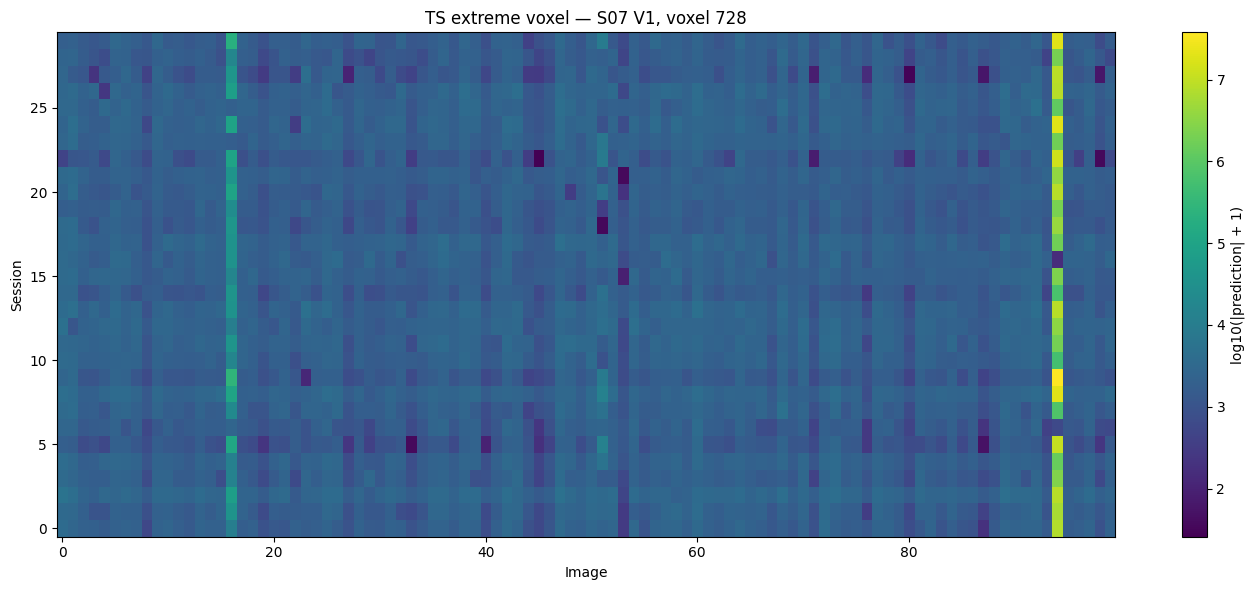

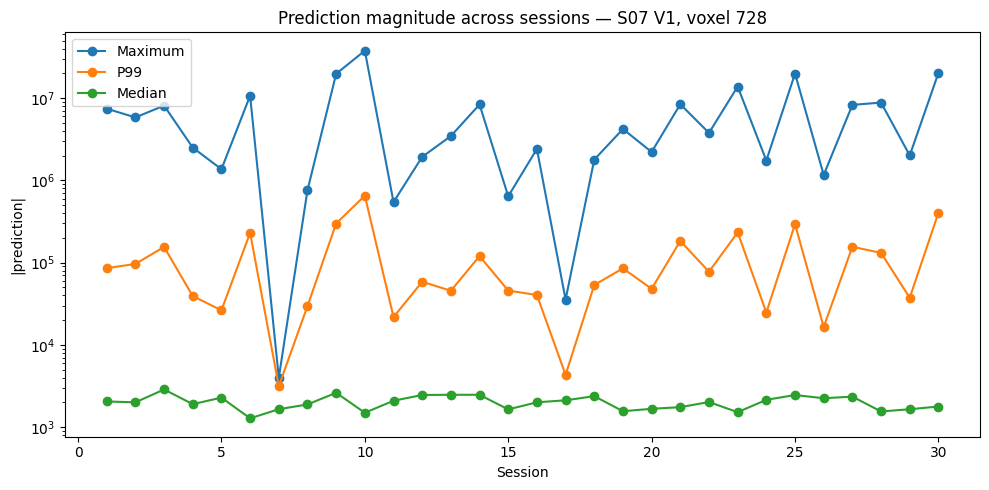

In [10]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ============================================================
# CONFIG
# ============================================================

TS_DIR = Path(
    "/content/drive/MyDrive/V2_drift/texturemodel/drift_results/"
    "population_simulations"
)

ROIS = ["V1", "V2", "V3", "hV4"]

TOP_N = 20

# ============================================================
# 1. FIND MOST EXTREME TS VOXELS
# ============================================================

rows = []

for subject in range(1, 9):

    for roi in ROIS:

        fn = (
            TS_DIR
            / f"sim_population_TS_pcaHL95_raw_S{subject:02d}_{roi}_Nimg100.npz"
        )

        if not fn.exists():
            print("Missing:", fn)
            continue

        d = np.load(fn, allow_pickle=True)

        # expected:
        # voxels × sessions × images
        X = np.asarray(d["voxSessResp"], dtype=np.float64)

        for voxel in range(X.shape[0]):

            x = X[voxel]

            abs_x = np.abs(x)

            rows.append({
                "subject": subject,
                "roi": roi,
                "voxel": voxel,

                "median_abs_prediction":
                    np.nanmedian(abs_x),

                "p99_abs_prediction":
                    np.nanpercentile(abs_x, 99),

                "p999_abs_prediction":
                    np.nanpercentile(abs_x, 99.9),

                "max_abs_prediction":
                    np.nanmax(abs_x),
            })


voxel_df = pd.DataFrame(rows)

top_voxels = (
    voxel_df
    .sort_values(
        "max_abs_prediction",
        ascending=False
    )
    .head(TOP_N)
    .reset_index(drop=True)
)

print("=" * 100)
print(f"TOP {TOP_N} TS VOXELS BY MAXIMUM |PREDICTION|")
print("=" * 100)

display(top_voxels)


# ============================================================
# 2. LOCATE EXACT SESSION × IMAGE RESPONSIBLE FOR MAXIMUM
# ============================================================

event_rows = []

for _, row in top_voxels.iterrows():

    subject = int(row["subject"])
    roi = row["roi"]
    voxel = int(row["voxel"])

    fn = (
        TS_DIR
        / f"sim_population_TS_pcaHL95_raw_S{subject:02d}_{roi}_Nimg100.npz"
    )

    d = np.load(fn, allow_pickle=True)

    X = np.asarray(
        d["voxSessResp"],
        dtype=np.float64
    )

    # sessions × images
    V = X[voxel]

    abs_V = np.abs(V)

    flat_index = np.nanargmax(abs_V)

    session_idx, image_idx = np.unravel_index(
        flat_index,
        V.shape
    )

    event_rows.append({
        "subject": subject,
        "roi": roi,
        "voxel": voxel,

        # +1 for human-readable numbering
        "session": session_idx + 1,
        "image": image_idx + 1,

        "prediction":
            V[session_idx, image_idx],

        "abs_prediction":
            abs_V[session_idx, image_idx],

        "voxel_median_abs":
            np.nanmedian(abs_V),

        "voxel_p99_abs":
            np.nanpercentile(abs_V, 99),

        "max_over_median":
            (
                np.nanmax(abs_V)
                / np.nanmedian(abs_V)
            )
    })


event_df = pd.DataFrame(event_rows)

print()
print("=" * 100)
print("EXACT LOCATION OF MAXIMUM PREDICTION")
print("=" * 100)

display(
    event_df.sort_values(
        "abs_prediction",
        ascending=False
    )
)


# ============================================================
# 3. HOW ARE EXTREME EVENTS DISTRIBUTED ACROSS SESSIONS?
# ============================================================

# Define an extreme prediction as |prediction| > 100,000
EXTREME_THRESHOLD = 1e5

session_rows = []

for _, row in top_voxels.iterrows():

    subject = int(row["subject"])
    roi = row["roi"]
    voxel = int(row["voxel"])

    fn = (
        TS_DIR
        / f"sim_population_TS_pcaHL95_raw_S{subject:02d}_{roi}_Nimg100.npz"
    )

    d = np.load(fn, allow_pickle=True)

    X = np.asarray(
        d["voxSessResp"],
        dtype=np.float64
    )

    V = X[voxel]

    for session in range(V.shape[0]):

        vals = np.abs(V[session])

        session_rows.append({
            "subject": subject,
            "roi": roi,
            "voxel": voxel,
            "session": session + 1,

            "median_abs_prediction":
                np.nanmedian(vals),

            "max_abs_prediction":
                np.nanmax(vals),

            "n_gt_1e5":
                np.sum(vals > EXTREME_THRESHOLD),

            "fraction_gt_1e5":
                np.mean(vals > EXTREME_THRESHOLD),
        })


session_df = pd.DataFrame(session_rows)

print()
print("=" * 100)
print("EXTREME EVENTS BY SESSION")
print("=" * 100)

display(
    session_df
    .sort_values(
        "max_abs_prediction",
        ascending=False
    )
    .head(100)
)


# ============================================================
# 4. HOW ARE EXTREME EVENTS DISTRIBUTED ACROSS IMAGES?
# ============================================================

image_rows = []

for _, row in top_voxels.iterrows():

    subject = int(row["subject"])
    roi = row["roi"]
    voxel = int(row["voxel"])

    fn = (
        TS_DIR
        / f"sim_population_TS_pcaHL95_raw_S{subject:02d}_{roi}_Nimg100.npz"
    )

    d = np.load(fn, allow_pickle=True)

    X = np.asarray(
        d["voxSessResp"],
        dtype=np.float64
    )

    V = X[voxel]

    for image in range(V.shape[1]):

        vals = np.abs(V[:, image])

        image_rows.append({
            "subject": subject,
            "roi": roi,
            "voxel": voxel,
            "image": image + 1,

            "median_abs_prediction":
                np.nanmedian(vals),

            "max_abs_prediction":
                np.nanmax(vals),

            "n_sessions_gt_1e5":
                np.sum(vals > EXTREME_THRESHOLD),

            "fraction_sessions_gt_1e5":
                np.mean(vals > EXTREME_THRESHOLD),
        })


image_df = pd.DataFrame(image_rows)

print()
print("=" * 100)
print("EXTREME EVENTS BY IMAGE")
print("=" * 100)

display(
    image_df
    .sort_values(
        "max_abs_prediction",
        ascending=False
    )
    .head(100)
)


# ============================================================
# 5. HEATMAP FOR THE SINGLE MOST EXTREME VOXEL
# ============================================================

row = top_voxels.iloc[0]

subject = int(row["subject"])
roi = row["roi"]
voxel = int(row["voxel"])

fn = (
    TS_DIR
    / f"sim_population_TS_pcaHL95_raw_S{subject:02d}_{roi}_Nimg100.npz"
)

d = np.load(fn, allow_pickle=True)

X = np.asarray(
    d["voxSessResp"],
    dtype=np.float64
)

V = X[voxel]

# log scale so normal and extreme values are visible together
plot_V = np.log10(
    np.abs(V) + 1
)

plt.figure(figsize=(14, 6))

plt.imshow(
    plot_V,
    aspect="auto",
    origin="lower"
)

plt.colorbar(
    label="log10(|prediction| + 1)"
)

plt.xlabel("Image")
plt.ylabel("Session")

plt.title(
    f"TS extreme voxel — S{subject:02d} {roi}, voxel {voxel}"
)

plt.tight_layout()
plt.show()


# ============================================================
# 6. SESSION PROFILE OF MOST EXTREME VOXEL
# ============================================================

session_max = np.nanmax(
    np.abs(V),
    axis=1
)

session_p99 = np.nanpercentile(
    np.abs(V),
    99,
    axis=1
)

session_median = np.nanmedian(
    np.abs(V),
    axis=1
)

plt.figure(figsize=(10, 5))

plt.plot(
    np.arange(1, len(session_max) + 1),
    session_max,
    marker="o",
    label="Maximum"
)

plt.plot(
    np.arange(1, len(session_p99) + 1),
    session_p99,
    marker="o",
    label="P99"
)

plt.plot(
    np.arange(1, len(session_median) + 1),
    session_median,
    marker="o",
    label="Median"
)

plt.yscale("log")

plt.xlabel("Session")
plt.ylabel("|prediction|")

plt.title(
    f"Prediction magnitude across sessions — "
    f"S{subject:02d} {roi}, voxel {voxel}"
)

plt.legend()
plt.tight_layout()
plt.show()

In [11]:
# ============================================================
# TEST:
# WHY DOES IMAGE 95 PRODUCE EXTREME TS PREDICTIONS?
#
# For the most extreme TS voxels:
#
#   1. Load the voxel's fitted pRF
#   2. Load the exact TS feature matrix for the 100 simulated images
#   3. Compare image 95 to the other 99 images
#   4. Separate:
#        LL features   = 0:49
#        PCA-HL        = 49:
#   5. Compute feature contributions:
#
#        contribution_j = X_j * weight_j
#
#   6. Identify which feature(s) drive the extreme prediction
#
# NO REGRESSION IS REFIT.
# ============================================================

from google.colab import drive
drive.mount("/content/drive", force_remount=False)

import os
import sys
import h5py
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path


# ============================================================
# PATHS
# ============================================================

ROOT = Path(
    "/content/drive/MyDrive/V2_drift"
)

TS_SIM_DIR = (
    ROOT
    / "texturemodel"
    / "drift_results"
    / "population_simulations"
)

FAST_BASE = (
    ROOT
    / "texturemodel"
    / "model_fits"
)

OUT_DIR = (
    ROOT
    / "texturemodel"
    / "drift_results"
    / "image95_feature_diagnostics"
)

OUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)


# ============================================================
# PROJECT PATHS
# ============================================================

for p in [
    ROOT / "texturemodel",
    ROOT / "texturemodel" / "code",
    ROOT / "texturemodel" / "code" / "utils",
    ROOT / "texturemodel" / "code" / "model_fitting",
]:

    p = str(p)

    if p not in sys.path:
        sys.path.insert(0, p)


# ============================================================
# IMPORT PROJECT FEATURE LOADER
# ============================================================

from feature_extraction import feature_loaders


# ============================================================
# CONFIG
# ============================================================

IMAGE_TO_CHECK = 95

# human-readable 95 -> python index 94
IMAGE_INDEX = IMAGE_TO_CHECK - 1

N_IMAGES = 100

N_LOW_LEVEL = 49

TOP_N_VOXELS = 20


# ============================================================
# USE EXISTING EXTREME VOXEL TABLE IF AVAILABLE
#
# Otherwise rebuild from population simulations.
# ============================================================

extreme_voxel_file = (
    ROOT
    / "texturemodel"
    / "drift_results"
    / "TS_vs_SP_voxel_prediction_distribution"
    / "TS_SP_voxel_prediction_magnitude.csv"
)

assert extreme_voxel_file.exists(), (
    f"Missing:\n{extreme_voxel_file}"
)

voxel_df = pd.read_csv(
    extreme_voxel_file
)

top_voxels = (
    voxel_df[
        voxel_df["model"] == "TS"
    ]
    .sort_values(
        "max_abs_prediction",
        ascending=False
    )
    .head(TOP_N_VOXELS)
    .reset_index(drop=True)
)

print("=" * 110)
print("TOP EXTREME TS VOXELS")
print("=" * 110)

display(
    top_voxels[
        [
            "subject",
            "roi",
            "voxel",
            "median_abs_prediction",
            "p99_abs_prediction",
            "max_abs_prediction",
        ]
    ]
)


# ============================================================
# HELPER:
# FIND FAST FILE
# ============================================================

def find_fast_file(
    subject,
    roi
):

    fast_dir = (
        FAST_BASE
        / f"S{subject:02d}"
        / "FAST_CROSS_SESSION"
    )

    candidates = list(
        fast_dir.glob(
            f"S{subject:02d}_{roi}_*pcaHL_{roi}_pca95_*30x30_cross_session.h5py"
        )
    )

    if len(candidates) == 0:

        # broader fallback
        candidates = list(
            fast_dir.glob(
                f"*{roi}*pca95*30x30*.h5py"
            )
        )

    if len(candidates) == 0:

        raise FileNotFoundError(
            f"No FAST file found for "
            f"S{subject:02d} {roi}"
        )

    candidates = sorted(
        candidates,
        key=lambda x: x.stat().st_mtime
    )

    return candidates[-1]


# ============================================================
# HELPER:
# GET IMAGE INDICES USED IN POPULATION SIMULATION
# ============================================================

def get_sim_image_indices(
    subject,
    roi
):

    fn = (
        TS_SIM_DIR
        / (
            f"sim_population_TS_pcaHL95_raw_"
            f"S{subject:02d}_{roi}_Nimg100.npz"
        )
    )

    d = np.load(
        fn,
        allow_pickle=True
    )

    # Try common keys
    for key in [
        "simImgs",
        "sim_img_inds",
        "image_inds",
        "images",
    ]:

        if key in d.files:

            arr = np.asarray(
                d[key]
            ).reshape(-1)

            if len(arr) == N_IMAGES:
                return arr.astype(int)

    # Your TS simulation previously used first 100 images
    return np.arange(
        N_IMAGES,
        dtype=int
    )


# ============================================================
# MAIN
# ============================================================

all_rows = []

top_contribution_rows = []


for rank, row in top_voxels.iterrows():

    subject = int(
        row["subject"]
    )

    roi = str(
        row["roi"]
    )

    voxel = int(
        row["voxel"]
    )


    print("\n" + "=" * 110)
    print(
        f"RANK {rank + 1}: "
        f"S{subject:02d} {roi}, voxel {voxel}"
    )
    print("=" * 110)


    # ========================================================
    # LOAD FAST FIT
    # ========================================================

    fast_file = find_fast_file(
        subject,
        roi
    )

    print(
        "FAST:",
        fast_file
    )


    with h5py.File(
        fast_file,
        "r"
    ) as f:

        W = np.asarray(
            f["best_weights"]
        )

        B = np.asarray(
            f["best_biases"]
        )

        fixed_prf = np.asarray(
            f["fixed_best_model_each_voxel"]
        ).squeeze()


    W = np.squeeze(
        W
    )

    # expected:
    # session × voxel × feature
    if W.ndim != 3:

        raise ValueError(
            f"Unexpected weight shape: {W.shape}"
        )


    n_sessions, n_voxels, n_features = W.shape


    fixed_prf = np.asarray(
        fixed_prf
    ).reshape(-1)


    prf_index = int(
        fixed_prf[
            voxel
        ]
    )


    print(
        "pRF index:",
        prf_index
    )

    print(
        "Weight shape:",
        W.shape
    )


    # ========================================================
    # LOAD POPULATION PREDICTIONS
    # ========================================================

    sim_fn = (
        TS_SIM_DIR
        / (
            f"sim_population_TS_pcaHL95_raw_"
            f"S{subject:02d}_{roi}_Nimg100.npz"
        )
    )


    sim = np.load(
        sim_fn,
        allow_pickle=True
    )


    vox_resp = np.asarray(
        sim[
            "voxSessResp"
        ],
        dtype=np.float64
    )


    V = vox_resp[
        voxel,
        :,
        :
    ]

    # session × image


    # ========================================================
    # FIND SESSION WITH LARGEST IMAGE-95 PREDICTION
    # ========================================================

    img95_values = V[
        :,
        IMAGE_INDEX
    ]


    extreme_session = int(
        np.nanargmax(
            np.abs(
                img95_values
            )
        )
    )


    print(
        "Extreme session:",
        extreme_session + 1
    )

    print(
        "Image 95 prediction:",
        img95_values[
            extreme_session
        ]
    )


    # ========================================================
    # IMAGE INDICES
    # ========================================================

    sim_images = get_sim_image_indices(
        subject,
        roi
    )


    print(
        "Simulation images:",
        sim_images[:10],
        "...",
        sim_images[-5:]
    )


    # ========================================================
    # LOAD FEATURES USING PROJECT FEATURE LOADER
    #
    # We use the exact fitting configuration:
    #   texture_pyramid
    #   pcaHL95
    #   grid5
    # ========================================================

    floader = (
        feature_loaders
        .CombinedFeatureLoader(

            subject=subject,

            feature_type="texture_pyramid",

            n_ori_pyr=4,

            n_sf_pyr=4,

            pca_type="pcaHL",

            pca_pct_var=95,

            which_prf_grid=5,

            zscore_features=False,
        )
    )


    # ========================================================
    # LOAD EXACT FEATURES FOR THIS pRF
    # ========================================================

    X, _ = floader.load(
        sim_images,
        prf_index
    )


    X = np.asarray(
        X,
        dtype=np.float64
    )


    print(
        "Feature matrix:",
        X.shape
    )


    if X.shape[0] != N_IMAGES:

        raise ValueError(
            f"Expected 100 images, got {X.shape}"
        )


    if X.shape[1] != n_features:

        raise ValueError(
            f"Feature mismatch: "
            f"X={X.shape[1]}, "
            f"W={n_features}"
        )


    # ========================================================
    # IMAGE 95 FEATURE VECTOR
    # ========================================================

    x95 = X[
        IMAGE_INDEX
    ]


    # distribution across other images
    X_other = np.delete(
        X,
        IMAGE_INDEX,
        axis=0
    )


    feature_median = np.nanmedian(
        X_other,
        axis=0
    )

    feature_sd = np.nanstd(
        X_other,
        axis=0
    )


    # ========================================================
    # ROBUST OUTLIER SCORE
    #
    # image95 deviation from other images
    # ========================================================

    feature_z = (
        x95
        -
        feature_median
    ) / (
        feature_sd
        +
        1e-12
    )


    # ========================================================
    # WEIGHTS FOR EXTREME SESSION
    # ========================================================

    w = W[
        extreme_session,
        voxel,
        :
    ].astype(
        np.float64
    )


    # ========================================================
    # FEATURE CONTRIBUTIONS
    # ========================================================

    contribution = (
        x95
        *
        w
    )


    abs_contribution = np.abs(
        contribution
    )


    # ========================================================
    # RECONSTRUCT PREDICTION
    # ========================================================

    try:

        b = np.squeeze(
            B
        )

        if b.ndim == 2:

            bias = float(
                b[
                    extreme_session,
                    voxel
                ]
            )

        elif b.ndim == 3:

            bias = float(
                b[
                    extreme_session,
                    voxel,
                    0
                ]
            )

        else:

            bias = 0.0

    except Exception:

        bias = 0.0


    reconstructed = (
        np.sum(
            contribution
        )
        +
        bias
    )


    stored_prediction = float(
        V[
            extreme_session,
            IMAGE_INDEX
        ]
    )


    print(
        "Stored prediction:",
        stored_prediction
    )

    print(
        "Reconstructed:",
        reconstructed
    )

    print(
        "Difference:",
        reconstructed
        -
        stored_prediction
    )


    # ========================================================
    # TABLE PER FEATURE
    # ========================================================

    for ff in range(
        n_features
    ):

        feature_group = (
            "LL"
            if ff < N_LOW_LEVEL
            else "PCA-HL"
        )


        all_rows.append({

            "rank":
                rank + 1,

            "subject":
                subject,

            "roi":
                roi,

            "voxel":
                voxel,

            "prf":
                prf_index,

            "session":
                extreme_session + 1,

            "image":
                IMAGE_TO_CHECK,

            "feature":
                ff,

            "feature_group":
                feature_group,

            "image95_feature_value":
                x95[
                    ff
                ],

            "other_images_median":
                feature_median[
                    ff
                ],

            "other_images_sd":
                feature_sd[
                    ff
                ],

            "image95_z_vs_other_images":
                feature_z[
                    ff
                ],

            "weight":
                w[
                    ff
                ],

            "contribution":
                contribution[
                    ff
                ],

            "abs_contribution":
                abs_contribution[
                    ff
                ],
        })


    # ========================================================
    # PRINT TOP CONTRIBUTORS
    # ========================================================

    tmp = pd.DataFrame(
        {

            "feature":
                np.arange(
                    n_features
                ),

            "group":
                [
                    (
                        "LL"
                        if ff < N_LOW_LEVEL
                        else "PCA-HL"
                    )

                    for ff in range(
                        n_features
                    )
                ],

            "x95":
                x95,

            "other_median":
                feature_median,

            "other_sd":
                feature_sd,

            "z95":
                feature_z,

            "weight":
                w,

            "contribution":
                contribution,

            "abs_contribution":
                abs_contribution,
        }
    )


    tmp = tmp.sort_values(
        "abs_contribution",
        ascending=False
    )


    print("\nTOP FEATURE CONTRIBUTIONS")

    display(
        tmp.head(
            15
        )
    )


    for _, rr in tmp.head(
        15
    ).iterrows():

        top_contribution_rows.append({

            "rank":
                rank + 1,

            "subject":
                subject,

            "roi":
                roi,

            "voxel":
                voxel,

            "session":
                extreme_session + 1,

            "prf":
                prf_index,

            "feature":
                int(
                    rr[
                        "feature"
                    ]
                ),

            "group":
                rr[
                    "group"
                ],

            "x95":
                rr[
                    "x95"
                ],

            "z95":
                rr[
                    "z95"
                ],

            "weight":
                rr[
                    "weight"
                ],

            "contribution":
                rr[
                    "contribution"
                ],
        })


    # ========================================================
    # FIGURE:
    # IMAGE 95 FEATURE VALUES VS OTHER IMAGES
    # ========================================================

    if rank < 5:

        plt.figure(
            figsize=(
                10,
                5
            )
        )

        plt.plot(
            np.arange(
                n_features
            ),
            np.abs(
                feature_z
            ),
            marker="o"
        )

        plt.axvline(
            N_LOW_LEVEL - 0.5,
            linestyle="--"
        )

        plt.xlabel(
            "Feature index"
        )

        plt.ylabel(
            "|Image 95 z-score vs other 99 images|"
        )

        plt.title(
            f"Image 95 feature outlier profile — "
            f"S{subject:02d} {roi}, voxel {voxel}"
        )

        plt.tight_layout()

        plt.show()


        # ====================================================
        # CONTRIBUTIONS
        # ====================================================

        plt.figure(
            figsize=(
                10,
                5
            )
        )

        plt.bar(
            np.arange(
                n_features
            ),
            contribution
        )

        plt.axvline(
            N_LOW_LEVEL - 0.5,
            linestyle="--"
        )

        plt.xlabel(
            "Feature index"
        )

        plt.ylabel(
            "Feature contribution to prediction"
        )

        plt.title(
            f"Image 95 contribution decomposition — "
            f"S{subject:02d} {roi}, "
            f"voxel {voxel}, session {extreme_session + 1}"
        )

        plt.tight_layout()

        plt.show()


# ============================================================
# COMBINED FEATURE TABLE
# ============================================================

feature_df = pd.DataFrame(
    all_rows
)

top_df = pd.DataFrame(
    top_contribution_rows
)


print("\n" + "=" * 110)
print("MOST COMMON EXTREME-CONTRIBUTING FEATURES")
print("=" * 110)


feature_counts = (
    top_df
    .groupby(
        [
            "feature",
            "group",
        ]
    )
    .agg(

        n_top20_voxels=(
            "voxel",
            "nunique"
        ),

        median_abs_contribution=(
            "contribution",
            lambda x:
                np.median(
                    np.abs(
                        x
                    )
                )
        ),

        median_abs_z95=(
            "z95",
            lambda x:
                np.median(
                    np.abs(
                        x
                    )
                )
        ),

        median_abs_weight=(
            "weight",
            lambda x:
                np.median(
                    np.abs(
                        x
                    )
                )
        ),
    )
    .reset_index()
    .sort_values(
        [
            "n_top20_voxels",
            "median_abs_contribution",
        ],
        ascending=[
            False,
            False,
        ]
    )
)


display(
    feature_counts
)


# ============================================================
# LL vs PCA-HL CONTRIBUTION
# ============================================================

group_summary = (
    feature_df
    .groupby(
        [
            "rank",
            "subject",
            "roi",
            "voxel",
            "feature_group",
        ]
    )
    .agg(

        sum_abs_contribution=(
            "abs_contribution",
            "sum"
        ),

        max_abs_contribution=(
            "abs_contribution",
            "max"
        ),
    )
    .reset_index()
)


print("\n" + "=" * 110)
print("LL vs PCA-HL CONTRIBUTION")
print("=" * 110)

display(
    group_summary
)


# ============================================================
# SAVE
# ============================================================

feature_file = (
    OUT_DIR
    / "image95_feature_contributions_top20_voxels.csv"
)

top_file = (
    OUT_DIR
    / "image95_top15_contributors_per_voxel.csv"
)

count_file = (
    OUT_DIR
    / "image95_common_extreme_features.csv"
)

group_file = (
    OUT_DIR
    / "image95_LL_vs_PCAHL_contribution.csv"
)


feature_df.to_csv(
    feature_file,
    index=False
)

top_df.to_csv(
    top_file,
    index=False
)

feature_counts.to_csv(
    count_file,
    index=False
)

group_summary.to_csv(
    group_file,
    index=False
)


print("\nSaved:")
print(feature_file)
print(top_file)
print(count_file)
print(group_file)

print("\nDONE.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


ImportError: cannot import name 'feature_loaders' from 'feature_extraction' (/content/drive/MyDrive/V2_drift/texturemodel/code/feature_extraction/__init__.py)